In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
import numpy as np

# Main project folder
PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"

# Original datasets
DATA_FOLDER = os.path.join(PROJECT_FOLDER, "Datasets")

# Cleaned datasets
CLEAN_FOLDER = os.path.join(PROJECT_FOLDER, "Clean_Data")

# Create Clean_Data folder if it doesn't already exist
os.makedirs(CLEAN_FOLDER, exist_ok=True)

print("Dataset folder:", DATA_FOLDER)
print("Clean data folder:", CLEAN_FOLDER)

Dataset folder: /content/drive/MyDrive/WA_Housing_Project/Datasets
Clean data folder: /content/drive/MyDrive/WA_Housing_Project/Clean_Data


In [ ]:
files = os.listdir(DATA_FOLDER)

for file in files:
    print(file)

Total dwellings commenced.csv
ABS_Building_Activity.xlsb
ABS_Total_Value_Dwellings.xlsx
ABS_CPI_Perth_Rent.xlsx
RBA_Housing_Lending_Rates_F6.xlsx
ABS_WA_Unemployment.xlsx
ABS_WA_Wage_Index.xlsx
ABS_Perth_House_Construction_Cost.xlsx
Components of population change – states and territories.xlsx
Population – states and territories.xlsx


Population – states and territories.xlsx

In [ ]:
population_file = os.path.join(
    DATA_FOLDER,
    "Population – states and territories.xlsx"
)

print(population_file)

/content/drive/MyDrive/WA_Housing_Project/Datasets/Population – states and territories.xlsx


In [ ]:
print(os.path.exists(population_file))

True


In [ ]:
# Dataset 1: WA Population

excel_file = pd.ExcelFile(population_file)

print("Sheet names:")
print(excel_file.sheet_names)

Sheet names:
['Index', 'Data1', 'Enquiries']


In [ ]:
population_raw = pd.read_excel(
    population_file,
    sheet_name="Data1",
    header=None
)

print("Shape:", population_raw.shape)

population_raw.head(15)

Shape: (189, 28)


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,NaN,Estimated Resident Population ; Male ; New S...,Estimated Resident Population ; Male ; Victo...,Estimated Resident Population ; Male ; Queen...,Estimated Resident Population ; Male ; South...,Estimated Resident Population ; Male ; Weste...,Estimated Resident Population ; Male ; Tasma...,Estimated Resident Population ; Male ; North...,Estimated Resident Population ; Male ; Austr...,Estimated Resident Population ; Male ; Austr...,...,Estimated Resident Population ; Female ; Aus...,Estimated Resident Population ; Persons ; Ne...,Estimated Resident Population ; Persons ; Vi...,Estimated Resident Population ; Persons ; Qu...,Estimated Resident Population ; Persons ; So...,Estimated Resident Population ; Persons ; We...,Estimated Resident Population ; Persons ; Ta...,Estimated Resident Population ; Persons ; No...,Estimated Resident Population ; Persons ; Au...,Estimated Resident Population ; Persons ; Au...
1,Unit,Persons,Persons,Persons,Persons,Persons,Persons,Persons,Persons,Persons,...,Persons,Persons,Persons,Persons,Persons,Persons,Persons,Persons,Persons,Persons
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,...,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE,STOCK_CLOSE
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,...,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00
7,Series End,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,...,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00
8,No. Obs,179,179,179,179,179,179,179,179,179,...,179,179,179,179,179,179,179,179,179,179
9,Series ID,A2060825C,A2060826F,A2060827J,A2060828K,A2060829L,A2060830W,A2060831X,A2060832A,A2060824A,...,A2060833C,A2060843J,A2060844K,A2060845L,A2060846R,A2060847T,A2060848V,A2060849W,A2060850F,A2060842F


In [ ]:
series_id = "A2060847T"

wa_col = None

for col in population_raw.columns:
    if population_raw[col].astype(str).str.contains(
        series_id,
        case=False,
        na=False
    ).any():
        wa_col = col
        break

print("WA Population column:", wa_col)

WA Population column: 23


In [ ]:
# ABS dates are in the first column
date_col = population_raw.columns[0]

# Convert first column to dates
dates = pd.to_datetime(
    population_raw[date_col],
    errors="coerce"
)

# Rows containing valid dates are the actual observations
valid_rows = dates.notna()

population_clean = pd.DataFrame({
    "Date": dates[valid_rows],
    "WA_Population": pd.to_numeric(
        population_raw.loc[valid_rows, wa_col],
        errors="coerce"
    )
})

population_clean.head()

/tmp/ipykernel_5700/2569458770.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(


,Date,WA_Population
10,1981-06-01,1300056
11,1981-09-01,1311284
12,1981-12-01,1320221
13,1982-03-01,1329700
14,1982-06-01,1338899


In [ ]:
# Remove rows without population values
population_clean = population_clean.dropna(
    subset=["Date", "WA_Population"]
).copy()

# Sort by date
population_clean = population_clean.sort_values(
    "Date"
).reset_index(drop=True)

# Convert population to whole persons
population_clean["WA_Population"] = (
    population_clean["WA_Population"].astype(int)
)

# Create standard quarterly identifier
population_clean["Quarter"] = (
    population_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

# Final columns
population_clean = population_clean[
    ["Quarter", "WA_Population"]
]

population_clean.head(10)

,Quarter,WA_Population
0,1981Q2,1300056
1,1981Q3,1311284
2,1981Q4,1320221
3,1982Q1,1329700
4,1982Q2,1338899
5,1982Q3,1348096
6,1982Q4,1354971
7,1983Q1,1361874
8,1983Q2,1369050
9,1983Q3,1375244


In [ ]:
print("Number of observations:", len(population_clean))

print("\nFirst observation:")
print(population_clean.head(1))

print("\nLast observation:")
print(population_clean.tail(1))

print("\nMissing values:")
print(population_clean.isna().sum())

print("\nDuplicate quarters:")
print(population_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(population_clean.dtypes)

Number of observations: 179

First observation:
  Quarter  WA_Population
0  1981Q2        1300056

Last observation:
    Quarter  WA_Population
178  2025Q4        3076528

Missing values:
Quarter          0
WA_Population    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter          object
WA_Population     int64
dtype: object


In [ ]:
population_output = os.path.join(
    CLEAN_FOLDER,
    "01_WA_Population_Clean.csv"
)

population_clean.to_csv(
    population_output,
    index=False
)

print("Saved successfully:")
print(population_output)

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/01_WA_Population_Clean.csv


In [ ]:
print(os.path.exists(population_output))

True


In [ ]:
population_clean

,Quarter,WA_Population
0,1981Q2,1300056
1,1981Q3,1311284
2,1981Q4,1320221
3,1982Q1,1329700
4,1982Q2,1338899
...,...,...
174,2024Q4,3011063
175,2025Q1,3032661
176,2025Q2,3046209
177,2025Q3,3063821


Dataset 2 — Components of population change – states and territories.xlsx

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
components_file = os.path.join(
    DATA_FOLDER,
    "Components of population change – states and territories.xlsx"
)

print("File exists:", os.path.exists(components_file))

File exists: True


In [ ]:
components_excel = pd.ExcelFile(components_file)

print("Sheet names:")
print(components_excel.sheet_names)

Sheet names:
['Index', 'Data1', 'Enquiries']


In [ ]:
components_raw = pd.read_excel(
    components_file,
    sheet_name="Data1",
    header=None
)

print("Shape:", components_raw.shape)

components_raw.head(15)

Shape: (189, 36)


,0,1,2,3,4,5,6,7,8,9,...,26,27,28,29,30,31,32,33,34,35
0,NaN,Natural Increase ; New South Wales ;,Net Overseas Migration ; New South Wales ;,Net Interstate Migration ; New South Wales ;,Change Over Previous Quarter ; New South Wales ;,Natural Increase ; Victoria ;,Net Overseas Migration ; Victoria ;,Net Interstate Migration ; Victoria ;,Change Over Previous Quarter ; Victoria ;,Natural Increase ; Queensland ;,...,Net Overseas Migration ; Northern Territory ;,Net Interstate Migration ; Northern Territory ;,Change Over Previous Quarter ; Northern Terri...,Natural Increase ; Australian Capital Territo...,Net Overseas Migration ; Australian Capital T...,Net Interstate Migration ; Australian Capital...,Change Over Previous Quarter ; Australian Cap...,Natural Increase ; Australia ;,Net Overseas Migration ; Australia ;,Change Over Previous Quarter ; Australia ;
1,Unit,Number,Number,Number,Number,Number,Number,Number,Number,Number,...,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,...,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,...,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00
7,Series End,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,...,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00
8,No. Obs,179,179,179,179,179,179,179,179,179,...,179,179,179,179,179,179,179,179,179,179
9,Series ID,A2060788C,A2060789F,A2060790R,A2060791T,A2060792V,A2060793W,A2060794X,A2060795A,A2060796C,...,A2060813V,A2060814W,A2060815X,A2060816A,A2060817C,A2060818F,A2060819J,A2060784V,A2060785W,A2060787A


In [ ]:
# Find columns that contain "Western Australia"
wa_columns = []

for col in components_raw.columns:
    if components_raw[col].astype(str).str.contains(
        "Western Australia",
        case=False,
        na=False
    ).any():
        wa_columns.append(col)

print("WA columns:", wa_columns)

# Display the first 12 rows for only those WA columns
components_raw.loc[:11, wa_columns]

WA columns: [17, 18, 19, 20]


,17,18,19,20
0,Natural Increase ; Western Australia ;,Net Overseas Migration ; Western Australia ;,Net Interstate Migration ; Western Australia ;,Change Over Previous Quarter ; Western Austra...
1,Number,Number,Number,Number
2,Original,Original,Original,Original
3,FLOW,FLOW,FLOW,FLOW
4,Quarter,Quarter,Quarter,Quarter
5,3,3,3,3
6,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00,1981-06-01 00:00:00
7,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00,2025-12-01 00:00:00
8,179,179,179,179
9,A2060804T,A2060805V,A2060806W,A2060807X


In [ ]:
# Extract the three WA population components

date_col = components_raw.columns[0]

# Convert first column to dates
dates = pd.to_datetime(
    components_raw[date_col],
    errors="coerce"
)

# Keep only rows containing actual dates
valid_rows = dates.notna()

components_clean = pd.DataFrame({
    "Date": dates[valid_rows],

    "WA_Natural_Increase": pd.to_numeric(
        components_raw.loc[valid_rows, 17],
        errors="coerce"
    ),

    "WA_NOM": pd.to_numeric(
        components_raw.loc[valid_rows, 18],
        errors="coerce"
    ),

    "WA_NIM": pd.to_numeric(
        components_raw.loc[valid_rows, 19],
        errors="coerce"
    )
})

components_clean.head()

/tmp/ipykernel_883/3549252156.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(


,Date,WA_Natural_Increase,WA_NOM,WA_NIM
10,1981-06-01,3579,3776,680
11,1981-09-01,3379,5101,2002
12,1981-12-01,3375,4375,441
13,1982-03-01,3639,4600,494
14,1982-06-01,3751,4081,621


In [ ]:
# Remove rows where the date is missing
components_clean = components_clean.dropna(
    subset=["Date"]
).copy()

# Sort chronologically
components_clean = components_clean.sort_values(
    "Date"
).reset_index(drop=True)

# Create the same Quarter format used in Dataset 1
components_clean["Quarter"] = (
    components_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

# Keep final columns
components_clean = components_clean[
    [
        "Quarter",
        "WA_Natural_Increase",
        "WA_NOM",
        "WA_NIM"
    ]
]

components_clean.head(10)

,Quarter,WA_Natural_Increase,WA_NOM,WA_NIM
0,1981Q2,3579,3776,680
1,1981Q3,3379,5101,2002
2,1981Q4,3375,4375,441
3,1982Q1,3639,4600,494
4,1982Q2,3751,4081,621
5,1982Q3,3330,4584,504
6,1982Q4,3340,2362,394
7,1983Q1,3685,2405,34
8,1983Q2,3961,1858,578
9,1983Q3,3324,1607,444


In [ ]:
print("Number of observations:", len(components_clean))

print("\nFirst 5 observations:")
print(components_clean.head())

print("\nLast 5 observations:")
print(components_clean.tail())

print("\nMissing values:")
print(components_clean.isna().sum())

print("\nDuplicate quarters:")
print(components_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(components_clean.dtypes)

Number of observations: 179

First 5 observations:
  Quarter  WA_Natural_Increase  WA_NOM  WA_NIM
0  1981Q2                 3579    3776     680
1  1981Q3                 3379    5101    2002
2  1981Q4                 3375    4375     441
3  1982Q1                 3639    4600     494
4  1982Q2                 3751    4081     621

Last 5 observations:
    Quarter  WA_Natural_Increase  WA_NOM  WA_NIM
174  2024Q4                 2602    9074    3244
175  2025Q1                 4719   13899    2980
176  2025Q2                 3928    7125    2495
177  2025Q3                 3449   11634    2529
178  2025Q4                 2528    7764    2415

Missing values:
Quarter                0
WA_Natural_Increase    0
WA_NOM                 0
WA_NIM                 0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter                object
WA_Natural_Increase     int64
WA_NOM                  int64
WA_NIM                  int64
dtype: object


In [ ]:
components_output = os.path.join(
    CLEAN_FOLDER,
    "02_WA_Population_Components_Clean.csv"
)

components_clean.to_csv(
    components_output,
    index=False
)

print("Saved successfully:")
print(components_output)

print("\nFile exists:", os.path.exists(components_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/02_WA_Population_Components_Clean.csv

File exists: True


Quarter | WA_Dwelling_Approvals

In [ ]:
approvals_file = os.path.join(
    DATA_FOLDER,
    "Total number of dwelling units.WA.xlsx"
)

print("File exists:", os.path.exists(approvals_file))

File exists: True


In [ ]:
approvals_excel = pd.ExcelFile(approvals_file)

print("Sheet names:")
print(approvals_excel.sheet_names)

Sheet names:
['Index', 'Data1', 'Enquiries']


In [ ]:
approvals_raw = pd.read_excel(
    approvals_file,
    sheet_name="Data1",
    header=None
)

print("Shape:", approvals_raw.shape)

approvals_raw.head(15)

Shape: (527, 17)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,NaN,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...
1,Unit,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number
2,Series Type,Original,Original,Original,Original,Original,Original,Seasonally Adjusted,Seasonally Adjusted,Seasonally Adjusted,Seasonally Adjusted,Trend,Trend,Trend,Trend,Trend,Trend
3,Data Type,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW
4,Frequency,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month
5,Collection Month,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
6,Series Start,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00
7,Series End,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00
8,No. Obs,517,517,517,517,517,517,517,517,517,517,517,517,517,517,517,517
9,Series ID,A418786L,A418839F,A421661T,A421720F,A422502A,A422566L,A418789V,A418842V,A422508R,A422572J,A418790C,A418843W,A421667F,A421726V,A422509T,A422574L


In [ ]:
matching_columns = []

for col in approvals_raw.columns:
    if approvals_raw[col].astype(str).str.contains(
        "dwelling",
        case=False,
        na=False
    ).any():
        matching_columns.append(col)

print("Matching columns:", matching_columns)

approvals_raw.loc[:11, matching_columns]

Matching columns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...,Total number of dwelling units ; Western Aust...
1,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number,Number
2,Original,Original,Original,Original,Original,Original,Seasonally Adjusted,Seasonally Adjusted,Seasonally Adjusted,Seasonally Adjusted,Trend,Trend,Trend,Trend,Trend,Trend
3,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW,FLOW
4,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month
5,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
6,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00,1983-07-01 00:00:00
7,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00
8,517,517,517,517,517,517,517,517,517,517,517,517,517,517,517,517
9,A418786L,A418839F,A421661T,A421720F,A422502A,A422566L,A418789V,A418842V,A422508R,A422572J,A418790C,A418843W,A421667F,A421726V,A422509T,A422574L


In [ ]:
# Show full metadata for every matching series
for col in matching_columns:
    print(
        "Column:", col,
        "| Description:", approvals_raw.iloc[0, col],
        "| Series Type:", approvals_raw.iloc[2, col],
        "| Series ID:", approvals_raw.iloc[9, col]
    )

Column: 1 | Description: Total number of dwelling units ;  Western Australia ;  Houses ;  Private Sector ; | Series Type: Original | Series ID: A418786L
Column: 2 | Description: Total number of dwelling units ;  Western Australia ;  Houses ;  Total Sectors ; | Series Type: Original | Series ID: A418839F
Column: 3 | Description: Total number of dwelling units ;  Western Australia ;  Dwellings excluding houses ;  Private Sector ; | Series Type: Original | Series ID: A421661T
Column: 4 | Description: Total number of dwelling units ;  Western Australia ;  Dwellings excluding houses ;  Total Sectors ; | Series Type: Original | Series ID: A421720F
Column: 5 | Description: Total number of dwelling units ;  Western Australia ;  Total (Type of Building) ;  Private Sector ; | Series Type: Original | Series ID: A422502A
Column: 6 | Description: Total number of dwelling units ;  Western Australia ;  Total (Type of Building) ;  Total Sectors ; | Series Type: Original | Series ID: A422566L
Column: 7

In [ ]:
# Column 6 = WA, Total Type of Building, Total Sectors, Original

date_col = approvals_raw.columns[0]

dates = pd.to_datetime(
    approvals_raw[date_col],
    errors="coerce"
)

valid_rows = dates.notna()

approvals_monthly = pd.DataFrame({
    "Date": dates[valid_rows],

    "WA_Dwelling_Approvals": pd.to_numeric(
        approvals_raw.loc[valid_rows, 6],
        errors="coerce"
    )
})

# Remove invalid/missing rows
approvals_monthly = approvals_monthly.dropna(
    subset=["Date", "WA_Dwelling_Approvals"]
).copy()

approvals_monthly = approvals_monthly.sort_values(
    "Date"
).reset_index(drop=True)

approvals_monthly.head()

/tmp/ipykernel_883/1432989725.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(


,Date,WA_Dwelling_Approvals
0,1983-07-01,911
1,1983-08-01,1396
2,1983-09-01,1630
3,1983-10-01,1360
4,1983-11-01,1449


In [ ]:
print("Monthly observations:", len(approvals_monthly))

print("\nFirst 5:")
print(approvals_monthly.head())

print("\nLast 5:")
print(approvals_monthly.tail())

print("\nMissing values:")
print(approvals_monthly.isna().sum())

Monthly observations: 517

First 5:
        Date  WA_Dwelling_Approvals
0 1983-07-01                    911
1 1983-08-01                   1396
2 1983-09-01                   1630
3 1983-10-01                   1360
4 1983-11-01                   1449

Last 5:
          Date  WA_Dwelling_Approvals
512 2026-03-01                   2219
513 2026-04-01                   2042
514 2026-05-01                   2200
515 2026-06-01                   2265
516 2026-07-01                   2451

Missing values:
Date                     0
WA_Dwelling_Approvals    0
dtype: int64


In [ ]:
# Create quarterly period
approvals_monthly["Quarter"] = (
    approvals_monthly["Date"]
    .dt.to_period("Q")
)

# Count how many months are available in each quarter
months_per_quarter = (
    approvals_monthly
    .groupby("Quarter")
    .size()
)

# Sum monthly approvals within each quarter
approvals_clean = (
    approvals_monthly
    .groupby("Quarter", as_index=False)["WA_Dwelling_Approvals"]
    .sum()
)

# Keep only COMPLETE quarters containing all 3 months
complete_quarters = months_per_quarter[
    months_per_quarter == 3
].index

approvals_clean = approvals_clean[
    approvals_clean["Quarter"].isin(complete_quarters)
].copy()

# Convert quarter to same format as Datasets 1 and 2
approvals_clean["Quarter"] = (
    approvals_clean["Quarter"].astype(str)
)

# Approvals are counts
approvals_clean["WA_Dwelling_Approvals"] = (
    approvals_clean["WA_Dwelling_Approvals"].round().astype(int)
)

approvals_clean = approvals_clean.reset_index(drop=True)

approvals_clean.head()

,Quarter,WA_Dwelling_Approvals
0,1983Q3,3937
1,1983Q4,4224
2,1984Q1,3924
3,1984Q2,5222
4,1984Q3,5311


In [ ]:
print("Quarterly observations:", len(approvals_clean))

print("\nFirst 5 quarters:")
print(approvals_clean.head())

print("\nLast 5 quarters:")
print(approvals_clean.tail())

print("\nMissing values:")
print(approvals_clean.isna().sum())

print("\nDuplicate quarters:")
print(approvals_clean["Quarter"].duplicated().sum())

Quarterly observations: 172

First 5 quarters:
  Quarter  WA_Dwelling_Approvals
0  1983Q3                   3937
1  1983Q4                   4224
2  1984Q1                   3924
3  1984Q2                   5222
4  1984Q3                   5311

Last 5 quarters:
    Quarter  WA_Dwelling_Approvals
167  2025Q2                   6149
168  2025Q3                   5893
169  2025Q4                   6520
170  2026Q1                   6733
171  2026Q2                   6507

Missing values:
Quarter                  0
WA_Dwelling_Approvals    0
dtype: int64

Duplicate quarters:
0


In [ ]:
approvals_output = os.path.join(
    CLEAN_FOLDER,
    "03_WA_Dwelling_Approvals_Clean.csv"
)

approvals_clean.to_csv(
    approvals_output,
    index=False
)

print("Saved successfully:")
print(approvals_output)

print("\nFile exists:", os.path.exists(approvals_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/03_WA_Dwelling_Approvals_Clean.csv

File exists: True


Dataset 4 — ABS_Building_Activity.xlsb

In [ ]:
!pip install pyxlsb -q

In [ ]:
from pyxlsb import open_workbook

In [ ]:
# ---------------------------------------------------------
# DATASET 4: ABS Building Activity
# ---------------------------------------------------------

building_file = os.path.join(
    DATA_FOLDER,
    "ABS_Building_Activity.xlsb"
)

print("File:", building_file)
print("File exists:", os.path.exists(building_file))

File: /content/drive/MyDrive/WA_Housing_Project/Datasets/ABS_Building_Activity.xlsb
File exists: True


In [ ]:
with open_workbook(building_file) as wb:
    building_sheets = wb.sheets

print("Number of sheets:", len(building_sheets))
print("\nSheet names:")

for i, sheet in enumerate(building_sheets):
    print(i, ":", sheet)

Number of sheets: 2

Sheet names:
0 : Sheet1
1 : 87520_activity


In [ ]:
with open_workbook(building_file) as wb:
    with wb.get_sheet("87520_activity") as sheet:

        rows = []

        for i, row in enumerate(sheet.rows()):
            rows.append([cell.v for cell in row])

            if i >= 24:   # only first 25 rows
                break

# Display neatly
preview = pd.DataFrame(rows)

print("Preview shape:", preview.shape)
display(preview)

Preview shape: (25, 27)


,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,Type of Building,Type of Work,Reference Quarter,Sector of Ownership,State/Territory,Value of work done during quarter ($ Millions),Value of work done during quarter - Annotation,Value of work yet to be done ($ Millions),Value of work yet to be done - Annotation,Value of work in the pipeline ($ Millions),...,Value of work under construction ($ Millions),Value of work under construction - Annotation,Dwelling units not yet commenced (Number),Dwelling units not yet commenced - Annotation,Dwelling units commenced (Number),Dwelling units commenced - Annotation,Dwelling units completed (Number),Dwelling units completed - Annotation,Dwelling units under construction (Number),Dwelling units under construction - Annotation
1,Houses,New,37135.0,Private Sector,Australia,3505.079,None,3161.985,None,4842.626,...,6546.636,None,10796.0,None,27124.0,None,20630.0,None,40549.0,None
2,Houses,New,37135.0,Private Sector,New South Wales,888.121,None,897.386,None,1698.217,...,1848.516,None,4579.0,None,5766.0,None,4611.0,None,10228.0,None
3,Houses,New,37135.0,Private Sector,Victoria,1133.657,None,1159.126,None,1576.68,...,2371.206,None,2647.0,None,8188.0,None,6622.0,None,14466.0,None
4,Houses,New,37135.0,Private Sector,Queensland,749.807,None,420.422,None,521.771,...,919.502,None,762.0,^,6537.0,None,4456.0,None,6180.0,None
5,Houses,New,37135.0,Private Sector,South Australia,184.808,None,169.843,None,283.876,...,345.427,None,954.0,None,1841.0,None,1296.0,None,2609.0,None
6,Houses,New,37135.0,Private Sector,Western Australia,441.485,None,432.5,None,650.83,...,873.617,None,1607.0,None,4016.0,None,2954.0,None,5651.0,None
7,Houses,New,37135.0,Private Sector,Tasmania,36.615,None,39.535,None,59.03,...,87.641,None,191.0,None,316.0,None,276.0,None,816.0,None
8,Houses,New,37135.0,Private Sector,Northern Territory,26.585,None,14.382,None,20.56,...,33.536,None,36.0,None,178.0,None,158.0,None,231.0,None
9,Houses,New,37135.0,Private Sector,Australian Capital Territory,44.002,None,28.79,None,31.662,...,67.191,None,19.0,^,282.0,None,255.0,None,369.0,None


In [ ]:
print("Number of columns in preview:", preview.shape[1])

Number of columns in preview: 27


In [ ]:
# Read the data cube into pandas
# We only extract the first 5 columns for now

rows = []

with open_workbook(building_file) as wb:
    with wb.get_sheet("87520_activity") as sheet:

        for row in sheet.rows():
            values = [cell.v for cell in row[:5]]
            rows.append(values)

building_classes = pd.DataFrame(
    rows[1:],
    columns=rows[0]
)

print("Rows:", len(building_classes))

building_classes.head()

Rows: 92849


,Type of Building,Type of Work,Reference Quarter,Sector of Ownership,State/Territory
0,Houses,New,37135.0,Private Sector,Australia
1,Houses,New,37135.0,Private Sector,New South Wales
2,Houses,New,37135.0,Private Sector,Victoria
3,Houses,New,37135.0,Private Sector,Queensland
4,Houses,New,37135.0,Private Sector,South Australia


In [ ]:
print("TYPE OF BUILDING:")
print(building_classes["Type of Building"].dropna().unique())

print("\nTYPE OF WORK:")
print(building_classes["Type of Work"].dropna().unique())

print("\nSECTOR OF OWNERSHIP:")
print(building_classes["Sector of Ownership"].dropna().unique())

print("\nSTATE/TERRITORY:")
print(building_classes["State/Territory"].dropna().unique())

TYPE OF BUILDING:
['Houses' 'Semi-detached, row or terrace houses, townhouses - One storey'
 'Semi-detached, row or terrace houses, townhouses - Two or more storeys'
 'Semi-detached, row or terrace houses, townhouses - Total'
 'Apartments - In a one or two storey block'
 'Apartments - In a three storey block'
 'Apartments - In a four to eight storey block'
 'Apartments - In a nine or more storey block'
 'Apartments - In a four or more storey block'
 'Apartments - Total including those attached to a house'
 'Total Other Residential' 'Total Residential (a)'
 'Retail and wholesale trade buildings' 'Transport buildings' 'Offices'
 'Commercial buildings n.e.c.' 'Commercial Buildings - Total'
 'Factories and other secondary production buildings' 'Warehouses'
 'Agricultural and aquacultural buildings'
 'Other industrial buildings n.e.c.' 'Industrial Buildings - Total'
 'Education buildings' 'Religion buildings' 'Aged care facilities'
 'Health buildings' 'Entertainment and recreation buildings

In [ ]:
building_classes["Reference Quarter"] = pd.to_datetime(
    building_classes["Reference Quarter"],
    origin="1899-12-30",
    unit="D",
    errors="coerce"
)

print(
    "First quarter:",
    building_classes["Reference Quarter"].min()
)

print(
    "Last quarter:",
    building_classes["Reference Quarter"].max()
)

First quarter: 2001-09-01 00:00:00
Last quarter: 2026-03-01 00:00:00


In [ ]:
# Read only the columns needed for Dataset 4

needed_cols = [0, 1, 2, 3, 4, 21, 23, 25]

rows = []

with open_workbook(building_file) as wb:
    with wb.get_sheet("87520_activity") as sheet:

        for i, row in enumerate(sheet.rows()):

            # Skip header
            if i == 0:
                continue

            values = [
                row[j].v if j < len(row) else None
                for j in needed_cols
            ]

            rows.append(values)

building_raw = pd.DataFrame(
    rows,
    columns=[
        "Type_of_Building",
        "Type_of_Work",
        "Reference_Quarter",
        "Sector_of_Ownership",
        "State_Territory",
        "WA_Dwelling_Commencements",
        "WA_Dwelling_Completions",
        "WA_Dwellings_Under_Construction"
    ]
)

print("Rows loaded:", len(building_raw))

building_raw.head()

Rows loaded: 92849


,Type_of_Building,Type_of_Work,Reference_Quarter,Sector_of_Ownership,State_Territory,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction
0,Houses,New,37135.0,Private Sector,Australia,27124.0,20630.0,40549.0
1,Houses,New,37135.0,Private Sector,New South Wales,5766.0,4611.0,10228.0
2,Houses,New,37135.0,Private Sector,Victoria,8188.0,6622.0,14466.0
3,Houses,New,37135.0,Private Sector,Queensland,6537.0,4456.0,6180.0
4,Houses,New,37135.0,Private Sector,South Australia,1841.0,1296.0,2609.0


In [ ]:
building_wa = building_raw[
    (building_raw["Type_of_Building"] == "Total") &
    (building_raw["Type_of_Work"] == "New") &
    (building_raw["Sector_of_Ownership"] == "Total Sectors") &
    (building_raw["State_Territory"] == "Western Australia")
].copy()

print("Rows after filtering:", len(building_wa))

building_wa.head(10)

Rows after filtering: 0


,Type_of_Building,Type_of_Work,Reference_Quarter,Sector_of_Ownership,State_Territory,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction


In [ ]:
building_wa["Date"] = pd.to_datetime(
    building_wa["Reference_Quarter"],
    origin="1899-12-30",
    unit="D",
    errors="coerce"
)

building_wa[
    [
        "Date",
        "WA_Dwelling_Commencements",
        "WA_Dwelling_Completions",
        "WA_Dwellings_Under_Construction"
    ]
].head()

,Date,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction


In [ ]:
building_wa["Quarter"] = (
    building_wa["Date"]
    .dt.to_period("Q")
    .astype(str)
)

building_clean = building_wa[
    [
        "Quarter",
        "WA_Dwelling_Commencements",
        "WA_Dwelling_Completions",
        "WA_Dwellings_Under_Construction"
    ]
].copy()

# Convert the three variables to numeric
numeric_columns = [
    "WA_Dwelling_Commencements",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction"
]

for col in numeric_columns:
    building_clean[col] = pd.to_numeric(
        building_clean[col],
        errors="coerce"
    )

building_clean = building_clean.sort_values(
    "Quarter"
).reset_index(drop=True)

building_clean.head()

,Quarter,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction


In [ ]:
print("Number of observations:", len(building_clean))

print("\nFirst 5 observations:")
print(building_clean.head())

print("\nLast 5 observations:")
print(building_clean.tail())

print("\nMissing values:")
print(building_clean.isna().sum())

print("\nDuplicate quarters:")
print(building_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(building_clean.dtypes)

Number of observations: 0

First 5 observations:
Empty DataFrame
Columns: [Quarter, WA_Dwelling_Commencements, WA_Dwelling_Completions, WA_Dwellings_Under_Construction]
Index: []

Last 5 observations:
Empty DataFrame
Columns: [Quarter, WA_Dwelling_Commencements, WA_Dwelling_Completions, WA_Dwellings_Under_Construction]
Index: []

Missing values:
Quarter                            0
WA_Dwelling_Commencements          0
WA_Dwelling_Completions            0
WA_Dwellings_Under_Construction    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter                            object
WA_Dwelling_Commencements           int64
WA_Dwelling_Completions             int64
WA_Dwellings_Under_Construction     int64
dtype: object


In [ ]:
# Check the exact category names available in the Building Activity cube

for column in [
    "Type_of_Building",
    "Type_of_Work",
    "Sector_of_Ownership",
    "State_Territory"
]:
    print(f"\n--- {column} ---")

    values = (
        building_raw[column]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
    )

    print(values)


--- Type_of_Building ---
['Houses' 'Semi-detached, row or terrace houses, townhouses - One storey'
 'Semi-detached, row or terrace houses, townhouses - Two or more storeys'
 'Semi-detached, row or terrace houses, townhouses - Total'
 'Apartments - In a one or two storey block'
 'Apartments - In a three storey block'
 'Apartments - In a four to eight storey block'
 'Apartments - In a nine or more storey block'
 'Apartments - In a four or more storey block'
 'Apartments - Total including those attached to a house'
 'Total Other Residential' 'Total Residential (a)'
 'Retail and wholesale trade buildings' 'Transport buildings' 'Offices'
 'Commercial buildings n.e.c.' 'Commercial Buildings - Total'
 'Factories and other secondary production buildings' 'Warehouses'
 'Agricultural and aquacultural buildings'
 'Other industrial buildings n.e.c.' 'Industrial Buildings - Total'
 'Education buildings' 'Religion buildings' 'Aged care facilities'
 'Health buildings' 'Entertainment and recreation b

In [ ]:
# All combinations available for Western Australia

wa_options = building_raw[
    building_raw["State_Territory"]
        .astype(str)
        .str.strip()
        .eq("Western Australia")
][
    [
        "Type_of_Building",
        "Type_of_Work",
        "Sector_of_Ownership"
    ]
].drop_duplicates()

print("Number of WA combinations:", len(wa_options))

display(
    wa_options
    .sort_values(
        [
            "Type_of_Building",
            "Type_of_Work",
            "Sector_of_Ownership"
        ]
    )
    .reset_index(drop=True)
)

Number of WA combinations: 108


,Type_of_Building,Type_of_Work,Sector_of_Ownership
0,Aged care facilities,Total,Private Sector
1,Aged care facilities,Total,Public Sector
2,Aged care facilities,Total,Total Sectors
3,Agricultural and aquacultural buildings,Total,Private Sector
4,Agricultural and aquacultural buildings,Total,Public Sector
...,...,...,...
103,Transport buildings,Total,Public Sector
104,Transport buildings,Total,Total Sectors
105,Warehouses,Total,Private Sector
106,Warehouses,Total,Public Sector


In [ ]:
# Show only WA combinations related to dwellings / residential housing

wa_residential_options = wa_options[
    wa_options["Type_of_Building"]
    .astype(str)
    .str.contains(
        "dwelling|residential|houses|apartments",
        case=False,
        na=False
    )
].copy()

display(
    wa_residential_options
    .sort_values(
        ["Type_of_Building", "Type_of_Work", "Sector_of_Ownership"]
    )
    .reset_index(drop=True)
)

,Type_of_Building,Type_of_Work,Sector_of_Ownership
0,Apartments - In a four or more storey block,New,Private Sector
1,Apartments - In a four or more storey block,New,Public Sector
2,Apartments - In a four or more storey block,New,Total Sectors
3,Apartments - In a four to eight storey block,New,Private Sector
4,Apartments - In a four to eight storey block,New,Public Sector
5,Apartments - In a four to eight storey block,New,Total Sectors
6,Apartments - In a nine or more storey block,New,Private Sector
7,Apartments - In a nine or more storey block,New,Public Sector
8,Apartments - In a nine or more storey block,New,Total Sectors
9,Apartments - In a one or two storey block,New,Private Sector


In [ ]:
# Show only the unique residential/housing building types

residential_types = (
    wa_residential_options["Type_of_Building"]
    .dropna()
    .unique()
)

for x in residential_types:
    print(repr(x))

'Houses'
'Semi-detached, row or terrace houses, townhouses - One storey'
'Semi-detached, row or terrace houses, townhouses - Two or more storeys'
'Semi-detached, row or terrace houses, townhouses - Total'
'Apartments - In a one or two storey block'
'Apartments - In a three storey block'
'Apartments - In a four to eight storey block'
'Apartments - In a nine or more storey block'
'Apartments - In a four or more storey block'
'Apartments - Total including those attached to a house'
'Total Other Residential'
'Total Residential (a)'
'Warehouses'
'Other non-residential n.e.c.'
'Other Non-residential - Total'
'Total Non-residential'
'Dwellings excluding new residential (b)'
'Dwellings excluding houses'


In [ ]:
total_residential_options = wa_options[
    wa_options["Type_of_Building"] == "Total Residential (a)"
]

display(total_residential_options)

,Type_of_Building,Type_of_Work,Sector_of_Ownership
26021,Total Residential (a),New,Private Sector
26030,Total Residential (a),New,Public Sector
26039,Total Residential (a),New,Total Sectors
28694,Total Residential (a),Alterations and additions including conversions,Private Sector
28703,Total Residential (a),Alterations and additions including conversions,Public Sector
28712,Total Residential (a),Alterations and additions including conversions,Total Sectors
31367,Total Residential (a),Total,Private Sector
31376,Total Residential (a),Total,Public Sector
31385,Total Residential (a),Total,Total Sectors


In [ ]:
building_wa = building_raw[
    (building_raw["Type_of_Building"] == "Total Residential (a)") &
    (building_raw["Type_of_Work"] == "New") &
    (building_raw["Sector_of_Ownership"] == "Total Sectors") &
    (building_raw["State_Territory"] == "Western Australia")
].copy()

print("Rows after filtering:", len(building_wa))

building_wa.head()

Rows after filtering: 99


,Type_of_Building,Type_of_Work,Reference_Quarter,Sector_of_Ownership,State_Territory,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction
26039,Total Residential (a),New,37135.0,Total Sectors,Western Australia,4992.0,3787.0,8124.0
26066,Total Residential (a),New,37226.0,Total Sectors,Western Australia,5172.0,4360.0,8923.0
26093,Total Residential (a),New,37316.0,Total Sectors,Western Australia,4361.0,3919.0,9249.0
26120,Total Residential (a),New,37408.0,Total Sectors,Western Australia,4625.0,4990.0,8879.0
26147,Total Residential (a),New,37500.0,Total Sectors,Western Australia,5700.0,3928.0,10653.0


In [ ]:
building_wa["Date"] = pd.to_datetime(
    building_wa["Reference_Quarter"],
    origin="1899-12-30",
    unit="D",
    errors="coerce"
)

building_wa["Quarter"] = (
    building_wa["Date"]
    .dt.to_period("Q")
    .astype(str)
)

In [ ]:
building_clean = building_wa[
    [
        "Quarter",
        "WA_Dwelling_Commencements",
        "WA_Dwelling_Completions",
        "WA_Dwellings_Under_Construction"
    ]
].copy()

# Convert values to numeric
numeric_cols = [
    "WA_Dwelling_Commencements",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction"
]

for col in numeric_cols:
    building_clean[col] = pd.to_numeric(
        building_clean[col],
        errors="coerce"
    )

building_clean = (
    building_clean
    .sort_values("Quarter")
    .reset_index(drop=True)
)

building_clean.head()

,Quarter,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction
0,2001Q3,4992.0,3787.0,8124.0
1,2001Q4,5172.0,4360.0,8923.0
2,2002Q1,4361.0,3919.0,9249.0
3,2002Q2,4625.0,4990.0,8879.0
4,2002Q3,5700.0,3928.0,10653.0


In [ ]:
print("Number of observations:", len(building_clean))

print("\nFirst 5 observations:")
print(building_clean.head())

print("\nLast 5 observations:")
print(building_clean.tail())

print("\nMissing values:")
print(building_clean.isna().sum())

print("\nDuplicate quarters:")
print(building_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(building_clean.dtypes)

Number of observations: 99

First 5 observations:
  Quarter  WA_Dwelling_Commencements  WA_Dwelling_Completions  \
0  2001Q3                     4992.0                   3787.0   
1  2001Q4                     5172.0                   4360.0   
2  2002Q1                     4361.0                   3919.0   
3  2002Q2                     4625.0                   4990.0   
4  2002Q3                     5700.0                   3928.0   

   WA_Dwellings_Under_Construction  
0                           8124.0  
1                           8923.0  
2                           9249.0  
3                           8879.0  
4                          10653.0  

Last 5 observations:
   Quarter  WA_Dwelling_Commencements  WA_Dwelling_Completions  \
94  2025Q1                     5450.0                   4979.0   
95  2025Q2                     5982.0                   5306.0   
96  2025Q3                     6117.0                   5420.0   
97  2025Q4                     6347.0              

In [ ]:
count_cols = [
    "WA_Dwelling_Commencements",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction"
]

for col in count_cols:
    building_clean[col] = building_clean[col].astype(int)

print(building_clean.dtypes)

Quarter                            object
WA_Dwelling_Commencements           int64
WA_Dwelling_Completions             int64
WA_Dwellings_Under_Construction     int64
dtype: object


In [ ]:
building_output = os.path.join(
    CLEAN_FOLDER,
    "04_WA_Building_Activity_Clean.csv"
)

building_clean.to_csv(
    building_output,
    index=False
)

print("Saved successfully:")
print(building_output)

print("\nFile exists:", os.path.exists(building_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/04_WA_Building_Activity_Clean.csv

File exists: True


Dataset 5 — ABS_Total_Value_Dwellings.xlsx

In [ ]:
# ---------------------------------------------------------
# DATASET 5: ABS Total Value of Dwellings
# ---------------------------------------------------------

dwelling_value_file = os.path.join(
    DATA_FOLDER,
    "ABS_Total_Value_Dwellings.xlsx"
)

print("File:", dwelling_value_file)
print("File exists:", os.path.exists(dwelling_value_file))

File: /content/drive/MyDrive/WA_Housing_Project/Datasets/ABS_Total_Value_Dwellings.xlsx
File exists: True


In [ ]:
dwelling_value_excel = pd.ExcelFile(dwelling_value_file)

print("Sheet names:")
print(dwelling_value_excel.sheet_names)

Sheet names:
['Index', 'Data1', 'Enquiries']


In [ ]:
dwelling_value_raw = pd.read_excel(
    dwelling_value_file,
    sheet_name="Data1",
    header=None
)

print("Shape:", dwelling_value_raw.shape)

dwelling_value_raw.head(15)

Shape: (69, 46)


,0,1,2,3,4,5,6,7,8,9,...,36,37,38,39,40,41,42,43,44,45
0,NaN,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Households ;...,...,Mean price of residential dwellings ; Austral...,Number of residential dwellings ; New South W...,Number of residential dwellings ; Victoria ;,Number of residential dwellings ; Queensland ;,Number of residential dwellings ; South Austr...,Number of residential dwellings ; Western Aus...,Number of residential dwellings ; Tasmania ;,Number of residential dwellings ; Northern Te...,Number of residential dwellings ; Australian ...,Number of residential dwellings ; Australia ;
1,Unit,$ Millions,$ Millions,$ Millions,$ Millions,$ Millions,$ Millions,$ Millions,$ Millions,$ Millions,...,$'000,000,000,000,000,000,000,000,000,000
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,...,AVERAGE,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,...,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00
7,Series End,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,...,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00
8,No. Obs,59,59,59,59,59,59,59,59,59,...,59,59,59,59,59,59,59,59,59,59
9,Series ID,A83728603C,A83728608R,A83728613J,A83728618V,A83728623L,A83728628X,A83728633T,A83728638C,A83728643W,...,A83728647F,A83728605J,A83728610A,A83728615L,A83728620F,A83728625T,A83728630K,A83728635W,A83728640R,A83728645A


In [ ]:
wa_value_columns = []

for col in dwelling_value_raw.columns:
    if dwelling_value_raw[col].astype(str).str.contains(
        "Western Australia",
        case=False,
        na=False
    ).any():
        wa_value_columns.append(col)

print("WA columns:", wa_value_columns)

dwelling_value_raw.loc[:11, wa_value_columns]

WA columns: [5, 14, 23, 32, 41]


,5,14,23,32,41
0,Value of dwelling stock; Owned by Households ;...,Value of dwelling stock; Owned by Non-Househol...,Value of dwelling stock; Owned by All Sectors ...,Mean price of residential dwellings ; Western...,Number of residential dwellings ; Western Aus...
1,$ Millions,$ Millions,$ Millions,$'000,000
2,Original,Original,Original,Original,Original
3,STOCK,STOCK,STOCK,AVERAGE,STOCK
4,Quarter,Quarter,Quarter,Quarter,Quarter
5,3,3,3,3,3
6,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00,2011-09-01 00:00:00
7,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00,2026-03-01 00:00:00
8,59,59,59,59,59
9,A83728623L,A83728624R,A83728626V,A83728627W,A83728625T


In [ ]:
# Column 32 = Mean price of residential dwellings, Western Australia

date_col = dwelling_value_raw.columns[0]

dates = pd.to_datetime(
    dwelling_value_raw[date_col],
    errors="coerce"
)

valid_rows = dates.notna()

dwelling_price_clean = pd.DataFrame({
    "Date": dates[valid_rows],

    "WA_Mean_Dwelling_Price_000": pd.to_numeric(
        dwelling_value_raw.loc[valid_rows, 32],
        errors="coerce"
    )
})

dwelling_price_clean.head()

/tmp/ipykernel_883/2203922342.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(


,Date,WA_Mean_Dwelling_Price_000
10,2011-09-01,524.8
11,2011-12-01,521.4
12,2012-03-01,532.4
13,2012-06-01,530.4
14,2012-09-01,537.7


In [ ]:
dwelling_price_clean = dwelling_price_clean.dropna(
    subset=["Date", "WA_Mean_Dwelling_Price_000"]
).copy()

dwelling_price_clean = dwelling_price_clean.sort_values(
    "Date"
).reset_index(drop=True)

dwelling_price_clean["Quarter"] = (
    dwelling_price_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

dwelling_price_clean = dwelling_price_clean[
    ["Quarter", "WA_Mean_Dwelling_Price_000"]
]

dwelling_price_clean.head()

,Quarter,WA_Mean_Dwelling_Price_000
0,2011Q3,524.8
1,2011Q4,521.4
2,2012Q1,532.4
3,2012Q2,530.4
4,2012Q3,537.7


In [ ]:
print("Number of observations:", len(dwelling_price_clean))

print("\nFirst 5 observations:")
print(dwelling_price_clean.head())

print("\nLast 5 observations:")
print(dwelling_price_clean.tail())

print("\nMissing values:")
print(dwelling_price_clean.isna().sum())

print("\nDuplicate quarters:")
print(dwelling_price_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(dwelling_price_clean.dtypes)

Number of observations: 59

First 5 observations:
  Quarter  WA_Mean_Dwelling_Price_000
0  2011Q3                       524.8
1  2011Q4                       521.4
2  2012Q1                       532.4
3  2012Q2                       530.4
4  2012Q3                       537.7

Last 5 observations:
   Quarter  WA_Mean_Dwelling_Price_000
54  2025Q1                       879.9
55  2025Q2                       914.5
56  2025Q3                       944.5
57  2025Q4                      1029.8
58  2026Q1                      1103.5

Missing values:
Quarter                       0
WA_Mean_Dwelling_Price_000    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter                        object
WA_Mean_Dwelling_Price_000    float64
dtype: object


In [ ]:
dwelling_price_output = os.path.join(
    CLEAN_FOLDER,
    "05_WA_Dwelling_Price_Clean.csv"
)

dwelling_price_clean.to_csv(
    dwelling_price_output,
    index=False
)

print("Saved successfully:")
print(dwelling_price_output)

print("\nFile exists:", os.path.exists(dwelling_price_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/05_WA_Dwelling_Price_Clean.csv

File exists: True


Quarter | Perth_Rent_Index

In [ ]:
# ---------------------------------------------------------
# DATASET 6: Perth Rent CPI Index
# ---------------------------------------------------------

rent_file = os.path.join(
    DATA_FOLDER,
    "ABS_CPI_Perth_Rent_Quarterly.xlsx"
)

print("File exists:", os.path.exists(rent_file))

rent_excel = pd.ExcelFile(rent_file)

print("\nSheet names:")
print(rent_excel.sheet_names)

File exists: True

Sheet names:
['Index', 'Data1', 'Data2', 'Data3', 'Data4', 'Data5', 'Data6', 'Enquiries']


In [ ]:
for sheet in rent_excel.sheet_names:
    print("\n-------------------------")
    print("SHEET:", sheet)
    print("-------------------------")

    temp = pd.read_excel(
        rent_file,
        sheet_name=sheet,
        header=None,
        nrows=12
    )

    print("Shape:", temp.shape)
    display(temp)


-------------------------
SHEET: Index
-------------------------
Shape: (12, 12)


,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Time Series Workbook,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,"6401.0 Consumer Price Index, Australia",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,"TABLE 9. CPI: Group, Sub-group and Expenditure...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,Enquiries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Data Item Description,NaN,NaN,Series Type,Series ID,Series Start,Series End,No. Obs.,Unit,Data Type,Freq.,Collection Month



-------------------------
SHEET: Data1
-------------------------
Shape: (12, 251)


,0,1,2,3,4,5,6,7,8,9,...,241,242,243,244,245,246,247,248,249,250
0,NaN,Index Numbers ; Food and non-alcoholic bevera...,Index Numbers ; Bread and cereal products ; ...,Index Numbers ; Bread ; Sydney ;,Index Numbers ; Cakes and biscuits ; Sydney ;,Index Numbers ; Breakfast cereals ; Sydney ;,Index Numbers ; Other cereal products ; Sydn...,Index Numbers ; Meat and seafoods ; Sydney ;,Index Numbers ; Beef and veal ; Sydney ;,Index Numbers ; Pork ; Sydney ;,...,Index Numbers ; Medical and hospital services...,Index Numbers ; Dental services ; Melbourne ;,Index Numbers ; Transport ; Melbourne ;,Index Numbers ; Private motoring ; Melbourne ;,Index Numbers ; Motor vehicles ; Melbourne ;,Index Numbers ; Spare parts and accessories f...,Index Numbers ; Automotive fuel ; Melbourne ;,Index Numbers ; Maintenance and repair of mot...,Index Numbers ; Other services in respect of ...,Index Numbers ; Urban transport fares ; Melb...
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,...,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,...,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1972-09-01 00:00:00,1972-09-01 00:00:00,1980-09-01 00:00:00,1980-09-01 00:00:00,1980-09-01 00:00:00,1980-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1980-09-01 00:00:00,...,1980-09-01 00:00:00,1980-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1980-09-01 00:00:00,1972-09-01 00:00:00,1980-09-01 00:00:00,1980-09-01 00:00:00,1972-09-01 00:00:00
7,Series End,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,...,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00
8,No. Obs,212,212,180,180,180,180,212,212,180,...,180,180,212,212,212,180,212,180,180,212
9,Series ID,A2325851W,A2326166T,A2327021W,A2327066A,A2327111A,A2327156F,A2326211T,A2327201F,A3603903T,...,A2329006K,A2329096A,A2326036V,A2326621J,A2328556K,A2328691A,A2328601K,A2328736V,A2328646R,A2326666L



-------------------------
SHEET: Data2
-------------------------
Shape: (12, 251)


,0,1,2,3,4,5,6,7,8,9,...,241,242,243,244,245,246,247,248,249,250
0,NaN,Index Numbers ; Urban transport fares ; Melb...,Index Numbers ; Communication ; Melbourne ;,Index Numbers ; Communication ; Melbourne ;,Index Numbers ; Postal services ; Melbourne ;,Index Numbers ; Telecommunication equipment a...,Index Numbers ; Recreation and culture ; Mel...,"Index Numbers ; Audio, visual and computing e...","Index Numbers ; Audio, visual and computing e...","Index Numbers ; Audio, visual and computing m...",...,Index Numbers ; Alcoholic beverages ; Adelai...,Index Numbers ; Spirits ; Adelaide ;,Index Numbers ; Wine ; Adelaide ;,Index Numbers ; Beer ; Adelaide ;,Index Numbers ; Tobacco ; Adelaide ;,Index Numbers ; Tobacco ; Adelaide ;,Index Numbers ; Clothing and footwear ; Adel...,Index Numbers ; Garments ; Adelaide ;,Index Numbers ; Garments for men ; Adelaide ;,Index Numbers ; Garments for women ; Adelaide ;
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,...,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,...,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1972-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1980-09-01 00:00:00,1980-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00,1980-09-01 00:00:00,1989-09-01 00:00:00,...,1972-09-01 00:00:00,1980-09-01 00:00:00,1980-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00
7,Series End,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,...,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00
8,No. Obs,212,212,212,180,180,144,144,180,144,...,212,180,180,212,212,212,212,144,144,144
9,Series ID,A2328781F,A2331166L,A2326576J,A2328466F,A2328511F,A2331211L,A3603818X,A2329276K,A3603698T,...,A2326721T,A2328926J,A2328881R,A2328836C,A2326766W,A2328971V,A2325911L,A3604038C,A2329556C,A2329691V


... (6 outputs left out)


-------------------------
SHEET: Data6
-------------------------
Shape: (12, 119)


,0,1,2,3,4,5,6,7,8,9,...,109,110,111,112,113,114,115,116,117,118
0,NaN,Index Numbers ; Alcoholic beverages ; Austra...,Index Numbers ; Spirits ; Australia ;,Index Numbers ; Wine ; Australia ;,Index Numbers ; Beer ; Australia ;,Index Numbers ; Tobacco ; Australia ;,Index Numbers ; Tobacco ; Australia ;,Index Numbers ; Clothing and footwear ; Aust...,Index Numbers ; Garments ; Australia ;,Index Numbers ; Garments for men ; Australia ;,...,Index Numbers ; All groups CPI excluding Heal...,Index Numbers ; All groups CPI excluding Tran...,Index Numbers ; All groups CPI excluding Comm...,Index Numbers ; All groups CPI excluding Recr...,Index Numbers ; All groups CPI excluding Educ...,Index Numbers ; All groups CPI excluding Insu...,Index Numbers ; All groups CPI excluding Hous...,Index Numbers ; All groups CPI excluding Medi...,Index Numbers ; All groups CPI excluding food...,Index Numbers ; All groups CPI excluding 'vol...
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,...,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,...,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1972-09-01 00:00:00,1980-09-01 00:00:00,1980-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1972-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00,...,1989-09-01 00:00:00,1980-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00,1989-09-01 00:00:00,1972-06-01 00:00:00,1989-09-01 00:00:00,1986-12-01 00:00:00
7,Series End,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,...,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00,2025-06-01 00:00:00
8,No. Obs,212,180,180,212,212,212,212,144,144,...,144,180,144,144,144,144,144,213,144,155
9,Series ID,A2326746L,A2328951K,A2328906X,A2328861F,A2326791X,A2328996R,A2325936J,A3604368V,A2329581F,...,A2332326F,A2332371T,A2332416K,A2332461W,A2332506R,A2332641F,A2332686K,A2332551A,A3604378X,A2330841L



-------------------------
SHEET: Enquiries
-------------------------
Shape: (11, 2)


,0,1
0,NaN,NaN
1,NaN,Time Series Workbook
2,NaN,NaN
3,NaN,NaN
4,NaN,"6401.0 Consumer Price Index, Australia"
5,NaN,"TABLE 9. CPI: Group, Sub-group and Expenditure..."
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,E N Q U I R I E S


In [ ]:
# Search for columns containing BOTH "Rents" and "Perth"

perth_rent_columns = []

for col in rent_raw.columns:
    description = str(rent_raw.iloc[0, col])

    if (
        "rent" in description.lower()
        and "perth" in description.lower()
    ):
        perth_rent_columns.append(col)

print("Matching columns:", perth_rent_columns)

for col in perth_rent_columns:
    print("\n--------------------------------")
    print("Column:", col)
    print("Description:", rent_raw.iloc[0, col])
    print("Unit:", rent_raw.iloc[1, col])
    print("Series Type:", rent_raw.iloc[2, col])
    print("Data Type:", rent_raw.iloc[3, col])
    print("Frequency:", rent_raw.iloc[4, col])
    print("Series Start:", rent_raw.iloc[6, col])
    print("Series End:", rent_raw.iloc[7, col])
    print("No. Obs:", rent_raw.iloc[8, col])
    print("Series ID:", rent_raw.iloc[9, col])

Matching columns: []


In [ ]:
# Check sheet names again
print(rent_excel.sheet_names)

['Index', 'Data1', 'Data2', 'Data3', 'Data4', 'Data5', 'Data6', 'Enquiries']


In [ ]:
# Search all data sheets for a Perth Rent series

for sheet in ["Data1", "Data2", "Data3", "Data4", "Data5", "Data6"]:

    temp = pd.read_excel(
        rent_file,
        sheet_name=sheet,
        header=None
    )

    matches = []

    # Search the metadata area (first 10 rows)
    for col in temp.columns:
        metadata = " ".join(
            temp.iloc[:10, col]
            .astype(str)
            .tolist()
        ).lower()

        if "rent" in metadata and "perth" in metadata:
            matches.append(col)

    print(
        "Sheet:", sheet,
        "| Shape:", temp.shape,
        "| Perth Rent matches:", matches
    )

    # Print metadata if a match is found
    for col in matches:
        print("\nMATCH FOUND")
        print("Sheet:", sheet)
        print("Column:", col)
        print(temp.iloc[:10, col])
        print("--------------------------------")

Sheet: Data1 | Shape: (318, 251) | Perth Rent matches: []
Sheet: Data2 | Shape: (318, 251) | Perth Rent matches: []
Sheet: Data3 | Shape: (318, 251) | Perth Rent matches: [162, 163]

MATCH FOUND
Sheet: Data3
Column: 162
0    Index Numbers ;  Rents ;  Perth ;
1                        Index Numbers
2                             Original
3                                INDEX
4                              Quarter
5                                    3
6                  1972-09-01 00:00:00
7                  2025-06-01 00:00:00
8                                  212
9                            A2331856W
Name: 162, dtype: object
--------------------------------

MATCH FOUND
Sheet: Data3
Column: 163
0    Index Numbers ;  Rents ;  Perth ;
1                        Index Numbers
2                             Original
3                                INDEX
4                              Quarter
5                                    3
6                  1972-09-01 00:00:00
7                  20

In [ ]:
# Load Data3
rent_data3 = pd.read_excel(
    rent_file,
    sheet_name="Data3",
    header=None
)

# Compare the two Perth Rent series
print("COLUMN 162")
print(rent_data3.iloc[:20, [0, 162]].to_string(index=False))

print("\n" + "=" * 70)

print("COLUMN 163")
print(rent_data3.iloc[:20, [0, 163]].to_string(index=False))

# Check how many actual numeric observations each contains
for col in [162, 163]:
    values = pd.to_numeric(
        rent_data3.iloc[10:, col],
        errors="coerce"
    )

    print(
        f"\nColumn {col} | "
        f"Series ID: {rent_data3.iloc[9, col]} | "
        f"Numeric observations: {values.notna().sum()}"
    )

COLUMN 162
                0                                 162
                NaN Index Numbers ;  Rents ;  Perth ;
               Unit                     Index Numbers
        Series Type                          Original
          Data Type                             INDEX
          Frequency                           Quarter
   Collection Month                                 3
       Series Start               1972-09-01 00:00:00
         Series End               2025-06-01 00:00:00
            No. Obs                               212
          Series ID                         A2331856W
1948-09-01 00:00:00                               NaN
1948-12-01 00:00:00                               NaN
1949-03-01 00:00:00                               NaN
1949-06-01 00:00:00                               NaN
1949-09-01 00:00:00                               NaN
1949-12-01 00:00:00                               NaN
1950-03-01 00:00:00                               NaN
1950-06-01 00:00:

In [ ]:
# Show the exact descriptions as repr() so hidden spaces/symbols are visible

for col in [162, 163]:
    print("\nColumn:", col)

    for row in range(10):
        print(
            f"Row {row}:",
            repr(rent_data3.iloc[row, col])
        )


Column: 162
Row 0: 'Index Numbers ;  Rents ;  Perth ;'
Row 1: 'Index Numbers'
Row 2: 'Original'
Row 3: 'INDEX'
Row 4: 'Quarter'
Row 5: 3
Row 6: datetime.datetime(1972, 9, 1, 0, 0)
Row 7: datetime.datetime(2025, 6, 1, 0, 0)
Row 8: 212
Row 9: 'A2331856W'

Column: 163
Row 0: 'Index Numbers ;  Rents ;  Perth ;'
Row 1: 'Index Numbers'
Row 2: 'Original'
Row 3: 'INDEX'
Row 4: 'Quarter'
Row 5: 3
Row 6: datetime.datetime(1972, 9, 1, 0, 0)
Row 7: datetime.datetime(2025, 6, 1, 0, 0)
Row 8: 212
Row 9: 'A2326411K'


In [ ]:
# Convert dates
dates = pd.to_datetime(
    rent_data3.iloc[10:, 0],
    errors="coerce"
)

# Convert both Perth Rent series to numeric
rent_162 = pd.to_numeric(
    rent_data3.iloc[10:, 162],
    errors="coerce"
)

rent_163 = pd.to_numeric(
    rent_data3.iloc[10:, 163],
    errors="coerce"
)

comparison = pd.DataFrame({
    "Date": dates,
    "Series_162": rent_162,
    "Series_163": rent_163
})

comparison = comparison.dropna(
    subset=["Date"]
).reset_index(drop=True)

print("First 10:")
print(comparison.head(10))

print("\nLast 10:")
print(comparison.tail(10))

print("\nNon-missing observations:")
print(comparison[["Series_162", "Series_163"]].notna().sum())

print("\nNumber of different values:")
print(
    (
        comparison["Series_162"] !=
        comparison["Series_163"]
    ).sum()
)

First 10:
        Date  Series_162  Series_163
0 1948-09-01         NaN         NaN
1 1948-12-01         NaN         NaN
2 1949-03-01         NaN         NaN
3 1949-06-01         NaN         NaN
4 1949-09-01         NaN         NaN
5 1949-12-01         NaN         NaN
6 1950-03-01         NaN         NaN
7 1950-06-01         NaN         NaN
8 1950-09-01         NaN         NaN
9 1950-12-01         NaN         NaN

Last 10:
          Date  Series_162  Series_163
298 2023-03-01       103.8       103.8
299 2023-06-01       106.6       106.6
300 2023-09-01       109.5       109.5
301 2023-12-01       110.9       110.9
302 2024-03-01       114.1       114.1
303 2024-06-01       117.3       117.3
304 2024-09-01       120.5       120.5
305 2024-12-01       122.1       122.1
306 2025-03-01       124.2       124.2
307 2025-06-01       126.2       126.2

Non-missing observations:
Series_162    212
Series_163    212
dtype: int64

Number of different values:
96


In [ ]:
different = comparison[
    comparison["Series_162"] != comparison["Series_163"]
]

print("Rows where the two series differ:")
print(different.head(20))

Rows where the two series differ:
         Date  Series_162  Series_163
0  1948-09-01         NaN         NaN
1  1948-12-01         NaN         NaN
2  1949-03-01         NaN         NaN
3  1949-06-01         NaN         NaN
4  1949-09-01         NaN         NaN
5  1949-12-01         NaN         NaN
6  1950-03-01         NaN         NaN
7  1950-06-01         NaN         NaN
8  1950-09-01         NaN         NaN
9  1950-12-01         NaN         NaN
10 1951-03-01         NaN         NaN
11 1951-06-01         NaN         NaN
12 1951-09-01         NaN         NaN
13 1951-12-01         NaN         NaN
14 1952-03-01         NaN         NaN
15 1952-06-01         NaN         NaN
16 1952-09-01         NaN         NaN
17 1952-12-01         NaN         NaN
18 1953-03-01         NaN         NaN
19 1953-06-01         NaN         NaN


In [ ]:
# Keep only rows where at least one Perth Rent series has data
actual_data = comparison[
    comparison[["Series_162", "Series_163"]]
    .notna()
    .any(axis=1)
].copy()

print("First 10 actual observations:")
print(actual_data.head(10))

print("\nLast 10 actual observations:")
print(actual_data.tail(10))

print("\nNon-missing observations:")
print(
    actual_data[["Series_162", "Series_163"]]
    .notna()
    .sum()
)

# Compare properly, treating NaN = NaN
same_values = (
    actual_data["Series_162"].eq(actual_data["Series_163"]) |
    (
        actual_data["Series_162"].isna() &
        actual_data["Series_163"].isna()
    )
)

different = actual_data[~same_values]

print("\nActual number of different rows:", len(different))

print("\nFirst 20 genuine differences:")
print(different.head(20))

First 10 actual observations:
          Date  Series_162  Series_163
96  1972-09-01        12.2        12.2
97  1972-12-01        12.3        12.3
98  1973-03-01        12.3        12.3
99  1973-06-01        12.4        12.4
100 1973-09-01        12.5        12.5
101 1973-12-01        12.6        12.6
102 1974-03-01        12.7        12.7
103 1974-06-01        12.9        12.9
104 1974-09-01        13.3        13.3
105 1974-12-01        14.0        14.0

Last 10 actual observations:
          Date  Series_162  Series_163
298 2023-03-01       103.8       103.8
299 2023-06-01       106.6       106.6
300 2023-09-01       109.5       109.5
301 2023-12-01       110.9       110.9
302 2024-03-01       114.1       114.1
303 2024-06-01       117.3       117.3
304 2024-09-01       120.5       120.5
305 2024-12-01       122.1       122.1
306 2025-03-01       124.2       124.2
307 2025-06-01       126.2       126.2

Non-missing observations:
Series_162    212
Series_163    212
dtype: int64

Actua

In [ ]:
# Extract Perth Rent Index - Column 162

dates = pd.to_datetime(
    rent_data3.iloc[10:, 0],
    errors="coerce"
)

rent_values = pd.to_numeric(
    rent_data3.iloc[10:, 162],
    errors="coerce"
)

rent_clean = pd.DataFrame({
    "Date": dates,
    "Perth_Rent_Index": rent_values
})

# Remove rows without valid date or rent value
rent_clean = rent_clean.dropna(
    subset=["Date", "Perth_Rent_Index"]
).copy()

# Sort by date
rent_clean = rent_clean.sort_values(
    "Date"
).reset_index(drop=True)

# Convert date to quarterly format
rent_clean["Quarter"] = (
    rent_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

# Keep final columns
rent_clean = rent_clean[
    ["Quarter", "Perth_Rent_Index"]
]

print(rent_clean.head())
print(rent_clean.tail())

  Quarter  Perth_Rent_Index
0  1972Q3              12.2
1  1972Q4              12.3
2  1973Q1              12.3
3  1973Q2              12.4
4  1973Q3              12.5
    Quarter  Perth_Rent_Index
207  2024Q2             117.3
208  2024Q3             120.5
209  2024Q4             122.1
210  2025Q1             124.2
211  2025Q2             126.2


In [ ]:
print("Number of observations:", len(rent_clean))

print("\nFirst 5 observations:")
print(rent_clean.head())

print("\nLast 5 observations:")
print(rent_clean.tail())

print("\nMissing values:")
print(rent_clean.isna().sum())

print("\nDuplicate quarters:")
print(rent_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(rent_clean.dtypes)

Number of observations: 212

First 5 observations:
  Quarter  Perth_Rent_Index
0  1972Q3              12.2
1  1972Q4              12.3
2  1973Q1              12.3
3  1973Q2              12.4
4  1973Q3              12.5

Last 5 observations:
    Quarter  Perth_Rent_Index
207  2024Q2             117.3
208  2024Q3             120.5
209  2024Q4             122.1
210  2025Q1             124.2
211  2025Q2             126.2

Missing values:
Quarter             0
Perth_Rent_Index    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter              object
Perth_Rent_Index    float64
dtype: object


In [ ]:
rent_output = os.path.join(
    CLEAN_FOLDER,
    "06_Perth_Rent_Index_Clean.csv"
)

rent_clean.to_csv(
    rent_output,
    index=False
)

print("Saved successfully:")
print(rent_output)

print("\nFile exists:", os.path.exists(rent_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/06_Perth_Rent_Index_Clean.csv

File exists: True


RBA_Housing_Lending_Rates_F5.xlsx

In [ ]:
# ---------------------------------------------------------
# DATASET 7: RBA Indicator Lending Rates - F5
# ---------------------------------------------------------

rates_f5_file = os.path.join(
    DATA_FOLDER,
    "RBA_Indicator_Lending_Rates_F5.xlsx"
)

print("File exists:", os.path.exists(rates_f5_file))

rates_f5_excel = pd.ExcelFile(rates_f5_file)

print("\nSheet names:")
print(rates_f5_excel.sheet_names)

File exists: True

Sheet names:
['Data', 'Notes', 'Series breaks']


In [ ]:
for sheet in rates_f5_excel.sheet_names:
    print("\n-------------------------")
    print("SHEET:", sheet)
    print("-------------------------")

    temp = pd.read_excel(
        rates_f5_file,
        sheet_name=sheet,
        header=None,
        nrows=15
    )

    print("Shape:", temp.shape)
    display(temp)


-------------------------
SHEET: Data
-------------------------
Shape: (15, 31)


,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,F5 INDICATOR LENDING RATES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Title,Lending rates; Small business; Variable; Term,Lending rates; Small business; Variable; Overd...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; 3-year fi...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,...,Lending rates; Personal loans; Term loans (uns...,Lending rates; Personal loans; Revolving credi...,Lending rates; Personal loans; Revolving credi...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...
2,Description,Lending rates; Small business; Variable; Term,Lending rates; Small business; Variable; Overd...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; 3-year fi...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,...,Lending rates; Personal loans; Term loans (uns...,Lending rates; Personal loans; Revolving credi...,Lending rates; Personal loans; Revolving credi...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...
3,Frequency,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,...,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly
4,Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
5,Units,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,...,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Source,RBA,RBA,RBA,RBA,RBA,RBA,RBA,RBA,RBA,...,RBA,RBA,RBA,RBA,RBA,RBA; Securitisation System,RBA; Securitisation System,RBA; Securitisation System,RBA; Securitisation System,RBA; Securitisation System
9,Publication date,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,...,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00



-------------------------
SHEET: Notes
-------------------------
Shape: (15, 1)


,0
0,F5 INDICATOR LENDING RATES
1,"Due to the nature of these data sources, these..."
2,Data are compiled on the last working day of t...
3,Business lending rates are the predominant or ...
4,‘Term’ refers to fully-drawn loans with a fixe...
5,‘Housing loan’ rates are those quoted for loan...
6,‘Personal loan’ rates are the average rates of...
7,‘Term loans (unsecured)’ refers to instalment ...
8,‘Credit cards – Standard’ refers to standard V...
9,‘Home equity loans’ refers to the indicator ra...



-------------------------
SHEET: Series breaks
-------------------------
Shape: (15, 5)


,0,1,2,3,4
0,F5 INDICATOR LENDING RATES – BREAKS IN SERIES,NaN,NaN,NaN,NaN
1,Three break types are identified:,NaN,A - Breaks in series due to the establishment ...,NaN,NaN
2,NaN,NaN,B - Breaks in series due to other changes in b...,NaN,NaN
3,NaN,NaN,C - Breaks in series due to changes in the cov...,NaN,NaN
4,"Prior to January 2007, details about each of t...",NaN,NaN,'Historical series breaks'.,NaN
5,A more detailed explanation of the impact of b...,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN
7,Date,Break type,Series title,NaN,Details
8,1995-12-31 00:00:00,B,Small business - Variable - Weighted-average r...,NaN,NaN
9,1998-05-31 00:00:00,B,Small business - Variable - Residential-secure...,NaN,NaN


In [ ]:
rates_f5_raw = pd.read_excel(
    rates_f5_file,
    sheet_name="Data",
    header=None
)

print("Full shape:", rates_f5_raw.shape)

display(rates_f5_raw.iloc[:15, :])

Full shape: (823, 31)


,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,F5 INDICATOR LENDING RATES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Title,Lending rates; Small business; Variable; Term,Lending rates; Small business; Variable; Overd...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; 3-year fi...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,...,Lending rates; Personal loans; Term loans (uns...,Lending rates; Personal loans; Revolving credi...,Lending rates; Personal loans; Revolving credi...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...
2,Description,Lending rates; Small business; Variable; Term,Lending rates; Small business; Variable; Overd...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; 3-year fi...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,Lending rates; Housing loans; Banks; Variable;...,...,Lending rates; Personal loans; Term loans (uns...,Lending rates; Personal loans; Revolving credi...,Lending rates; Personal loans; Revolving credi...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Housing loans; Mortgage manager...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...,Lending rates; Securitised housing loans; Aver...
3,Frequency,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,...,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly,Monthly
4,Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
5,Units,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,...,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum,Per cent per annum
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Source,RBA,RBA,RBA,RBA,RBA,RBA,RBA,RBA,RBA,...,RBA,RBA,RBA,RBA,RBA,RBA; Securitisation System,RBA; Securitisation System,RBA; Securitisation System,RBA; Securitisation System,RBA; Securitisation System
9,Publication date,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,...,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00,2026-09-07 00:00:00


In [ ]:
# Inspect housing-loan series only

for col in range(1, rates_f5_raw.shape[1]):

    title = str(rates_f5_raw.iloc[1, col])
    description = str(rates_f5_raw.iloc[2, col])

    if "housing loans" in title.lower() or "housing loans" in description.lower():

        values = pd.to_numeric(
            rates_f5_raw.iloc[11:, col],
            errors="coerce"
        )

        dates = pd.to_datetime(
            rates_f5_raw.iloc[11:, 0],
            errors="coerce"
        )

        valid = dates.notna() & values.notna()

        print("\n" + "=" * 90)
        print("COLUMN:", col)
        print("Series ID:", rates_f5_raw.iloc[10, col])
        print("Title:", repr(title))
        print("Description:", repr(description))
        print("Frequency:", rates_f5_raw.iloc[3, col])
        print("Units:", rates_f5_raw.iloc[5, col])
        print("Observations:", valid.sum())

        if valid.any():
            print("First valid date:", dates[valid].min())
            print("Last valid date:", dates[valid].max())


COLUMN: 3
Series ID: FILRHLBVS
Title: 'Lending rates; Housing loans; Banks; Variable; Standard; Owner-occupier'
Description: 'Lending rates; Housing loans; Banks; Variable; Standard; Owner-occupier'
Frequency: Monthly
Units: Per cent per annum
Observations: 812
First valid date: 1959-01-31 00:00:00
Last valid date: 2026-08-31 00:00:00

COLUMN: 4
Series ID: FILRHLBVD
Title: 'Lending rates; Housing loans; Banks; Variable; Discounted; Owner-occupier'
Description: 'Lending rates; Housing loans; Banks; Variable; Discounted; Owner-occupier'
Frequency: Monthly
Units: Per cent per annum
Observations: 267
First valid date: 2004-06-30 00:00:00
Last valid date: 2026-08-31 00:00:00

COLUMN: 5
Series ID: FILRHLBVO
Title: 'Lending rates; Housing loans; Banks; Variable; Standard interest-only; Owner-occupier'
Description: 'Lending rates; Housing loans; Banks; Variable; Standard interest-only; Owner-occupier'
Frequency: Monthly
Units: Per cent per annum
Observations: 133
First valid date: 2015-08-31 

In [ ]:
# Extract Dataset 7 - Standard Variable Owner-Occupier Housing Rate

dates = pd.to_datetime(
    rates_f5_raw.iloc[11:, 0],
    errors="coerce"
)

rates = pd.to_numeric(
    rates_f5_raw.iloc[11:, 3],
    errors="coerce"
)

housing_rate_monthly = pd.DataFrame({
    "Date": dates,
    "Housing_Lending_Rate": rates
})

# Remove invalid/missing observations
housing_rate_monthly = housing_rate_monthly.dropna(
    subset=["Date", "Housing_Lending_Rate"]
).copy()

housing_rate_monthly = housing_rate_monthly.sort_values(
    "Date"
).reset_index(drop=True)

print("Monthly observations:", len(housing_rate_monthly))
print(housing_rate_monthly.head())
print(housing_rate_monthly.tail())

Monthly observations: 812
        Date  Housing_Lending_Rate
0 1959-01-31                   5.0
1 1959-02-28                   5.0
2 1959-03-31                   5.0
3 1959-04-30                   5.0
4 1959-05-31                   5.0
          Date  Housing_Lending_Rate
807 2026-04-30                  8.52
808 2026-05-31                  8.77
809 2026-06-30                  8.77
810 2026-07-31                  8.77
811 2026-08-31                  8.77


In [ ]:
# Create quarterly period
housing_rate_monthly["Quarter"] = (
    housing_rate_monthly["Date"]
    .dt.to_period("Q")
)

# Count months available in each quarter
months_per_quarter = (
    housing_rate_monthly
    .groupby("Quarter")
    .size()
)

# Quarterly average
housing_rate_clean = (
    housing_rate_monthly
    .groupby("Quarter")["Housing_Lending_Rate"]
    .mean()
    .reset_index()
)

# Keep only COMPLETE quarters with all 3 months
complete_quarters = months_per_quarter[
    months_per_quarter == 3
].index

housing_rate_clean = housing_rate_clean[
    housing_rate_clean["Quarter"].isin(complete_quarters)
].copy()

# Convert Quarter to same format as other clean datasets
housing_rate_clean["Quarter"] = (
    housing_rate_clean["Quarter"]
    .astype(str)
)

housing_rate_clean = housing_rate_clean.reset_index(drop=True)

In [ ]:
print("Number of quarterly observations:", len(housing_rate_clean))

print("\nFirst 5 observations:")
print(housing_rate_clean.head())

print("\nLast 5 observations:")
print(housing_rate_clean.tail())

print("\nMissing values:")
print(housing_rate_clean.isna().sum())

print("\nDuplicate quarters:")
print(housing_rate_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(housing_rate_clean.dtypes)

Number of quarterly observations: 270

First 5 observations:
  Quarter  Housing_Lending_Rate
0  1959Q1                   5.0
1  1959Q2                   5.0
2  1959Q3                   5.0
3  1959Q4                   5.0
4  1960Q1                   5.0

Last 5 observations:
    Quarter  Housing_Lending_Rate
265  2025Q2              8.386667
266  2025Q3              8.103333
267  2025Q4              8.020000
268  2026Q1              8.270000
269  2026Q2              8.686667

Missing values:
Quarter                 0
Housing_Lending_Rate    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter                  object
Housing_Lending_Rate    float64
dtype: object


In [ ]:
housing_rate_output = os.path.join(
    CLEAN_FOLDER,
    "07_Housing_Lending_Rate_Clean.csv"
)

housing_rate_clean.to_csv(
    housing_rate_output,
    index=False
)

print("Saved successfully:")
print(housing_rate_output)

print("\nFile exists:", os.path.exists(housing_rate_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/07_Housing_Lending_Rate_Clean.csv

File exists: True


Quarter | WA_Unemployment_Rate

In [ ]:
# ---------------------------------------------------------
# DATASET 8: WA Unemployment Rate
# ---------------------------------------------------------

unemployment_file = os.path.join(
    DATA_FOLDER,
    "ABS_WA_Unemployment.xlsx"
)

print("File exists:", os.path.exists(unemployment_file))

unemployment_excel = pd.ExcelFile(unemployment_file)

print("\nSheet names:")
print(unemployment_excel.sheet_names)

File exists: True

Sheet names:
['Index', 'Data1', 'Enquiries']


In [ ]:
for sheet in unemployment_excel.sheet_names:
    print("\n-------------------------")
    print("SHEET:", sheet)
    print("-------------------------")

    temp = pd.read_excel(
        unemployment_file,
        sheet_name=sheet,
        header=None,
        nrows=15
    )

    print("Shape:", temp.shape)
    display(temp)


-------------------------
SHEET: Index
-------------------------
Shape: (15, 12)


,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Time Series Workbook,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,"6202.0 Labour Force, Australia",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,"Table 006. Labour force status by Sex, Western...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,Enquiries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Data Item Description,NaN,NaN,Series Type,Series ID,Series Start,Series End,No. Obs.,Unit,Data Type,Freq.,Collection Month



-------------------------
SHEET: Data1
-------------------------
Shape: (15, 85)


,0,1,2,3,4,5,6,7,8,9,...,75,76,77,78,79,80,81,82,83,84
0,NaN,Employed total ; Persons ;,Employed total ; Persons ;,Employed total ; Persons ;,Employed total ; > Males ;,Employed total ; > Males ;,Employed total ; > Males ;,Employed total ; > Females ;,Employed total ; > Females ;,Employed total ; > Females ;,...,Participation rate ; > Males ;,Participation rate ; > Females ;,Participation rate ; > Females ;,Participation rate ; > Females ;,Not in the labour force (NILF) ; Persons ;,Not in the labour force (NILF) ; > Males ;,Not in the labour force (NILF) ; > Females ;,Civilian population aged 15 years and over ; ...,Civilian population aged 15 years and over ; ...,Civilian population aged 15 years and over ; ...
1,Unit,000,000,000,000,000,000,000,000,000,...,Percent,Percent,Percent,Percent,000,000,000,000,000,000
2,Series Type,Trend,Seasonally Adjusted,Original,Trend,Seasonally Adjusted,Original,Trend,Seasonally Adjusted,Original,...,Original,Trend,Seasonally Adjusted,Original,Original,Original,Original,Original,Original,Original
3,Data Type,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,...,PERCENT,PERCENT,PERCENT,PERCENT,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK
4,Frequency,Month,Month,Month,Month,Month,Month,Month,Month,Month,...,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month
5,Collection Month,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
6,Series Start,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,...,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00
7,Series End,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,...,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00
8,No. Obs,582,582,582,582,582,582,582,582,582,...,582,582,582,582,582,582,582,582,582,582
9,Series ID,A84423993J,A84423321T,A84423657W,A84423881R,A84423209T,A84423545C,A84424105T,A84423433K,A84423769R,...,A84423551X,A84424111L,A84423439X,A84423775K,A84423660K,A84423548K,A84423772C,A84423661L,A84423549L,A84423773F



-------------------------
SHEET: Enquiries
-------------------------
Shape: (11, 2)


,0,1
0,NaN,NaN
1,NaN,Time Series Workbook
2,NaN,NaN
3,NaN,NaN
4,NaN,"6202.0 Labour Force, Australia"
5,NaN,"Table 006. Labour force status by Sex, Western..."
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,E N Q U I R I E S


In [ ]:
unemployment_raw = pd.read_excel(
    unemployment_file,
    sheet_name="Data1",
    header=None
)

print("Full shape:", unemployment_raw.shape)

display(unemployment_raw.iloc[:15, :])

Full shape: (592, 85)


,0,1,2,3,4,5,6,7,8,9,...,75,76,77,78,79,80,81,82,83,84
0,NaN,Employed total ; Persons ;,Employed total ; Persons ;,Employed total ; Persons ;,Employed total ; > Males ;,Employed total ; > Males ;,Employed total ; > Males ;,Employed total ; > Females ;,Employed total ; > Females ;,Employed total ; > Females ;,...,Participation rate ; > Males ;,Participation rate ; > Females ;,Participation rate ; > Females ;,Participation rate ; > Females ;,Not in the labour force (NILF) ; Persons ;,Not in the labour force (NILF) ; > Males ;,Not in the labour force (NILF) ; > Females ;,Civilian population aged 15 years and over ; ...,Civilian population aged 15 years and over ; ...,Civilian population aged 15 years and over ; ...
1,Unit,000,000,000,000,000,000,000,000,000,...,Percent,Percent,Percent,Percent,000,000,000,000,000,000
2,Series Type,Trend,Seasonally Adjusted,Original,Trend,Seasonally Adjusted,Original,Trend,Seasonally Adjusted,Original,...,Original,Trend,Seasonally Adjusted,Original,Original,Original,Original,Original,Original,Original
3,Data Type,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK,...,PERCENT,PERCENT,PERCENT,PERCENT,STOCK,STOCK,STOCK,STOCK,STOCK,STOCK
4,Frequency,Month,Month,Month,Month,Month,Month,Month,Month,Month,...,Month,Month,Month,Month,Month,Month,Month,Month,Month,Month
5,Collection Month,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
6,Series Start,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,...,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00,1978-02-01 00:00:00
7,Series End,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,...,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00
8,No. Obs,582,582,582,582,582,582,582,582,582,...,582,582,582,582,582,582,582,582,582,582
9,Series ID,A84423993J,A84423321T,A84423657W,A84423881R,A84423209T,A84423545C,A84424105T,A84423433K,A84423769R,...,A84423551X,A84424111L,A84423439X,A84423775K,A84423660K,A84423548K,A84423772C,A84423661L,A84423549L,A84423773F


In [ ]:
# Find columns containing "Unemployment rate"

unemployment_matches = []

for col in unemployment_raw.columns:
    description = str(unemployment_raw.iloc[0, col])

    if "unemployment rate" in description.lower():
        unemployment_matches.append(col)

print("Unemployment rate columns:", unemployment_matches)

for col in unemployment_matches:
    print("\n" + "=" * 85)
    print("COLUMN:", col)
    print("Description:", unemployment_raw.iloc[0, col])
    print("Unit:", unemployment_raw.iloc[1, col])
    print("Series Type:", unemployment_raw.iloc[2, col])
    print("Data Type:", unemployment_raw.iloc[3, col])
    print("Frequency:", unemployment_raw.iloc[4, col])
    print("Series Start:", unemployment_raw.iloc[6, col])
    print("Series End:", unemployment_raw.iloc[7, col])
    print("No. Obs:", unemployment_raw.iloc[8, col])
    print("Series ID:", unemployment_raw.iloc[9, col])

Unemployment rate columns: [46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60]

COLUMN: 46
Description: Unemployment rate ;  Persons ;
Unit: Percent
Series Type: Trend
Data Type: PERCENT
Frequency: Month
Series Start: 1978-02-01 00:00:00
Series End: 2026-07-01 00:00:00
No. Obs: 582
Series ID: A84423998V

COLUMN: 47
Description: Unemployment rate ;  Persons ;
Unit: Percent
Series Type: Seasonally Adjusted
Data Type: PERCENT
Frequency: Month
Series Start: 1978-02-01 00:00:00
Series End: 2026-07-01 00:00:00
No. Obs: 582
Series ID: A84423326C

COLUMN: 48
Description: Unemployment rate ;  Persons ;
Unit: Percent
Series Type: Original
Data Type: PERCENT
Frequency: Month
Series Start: 1978-02-01 00:00:00
Series End: 2026-07-01 00:00:00
No. Obs: 582
Series ID: A84423662R

COLUMN: 49
Description: Unemployment rate ;  > Males ;
Unit: Percent
Series Type: Trend
Data Type: PERCENT
Frequency: Month
Series Start: 1978-02-01 00:00:00
Series End: 2026-07-01 00:00:00
No. Obs: 582
Series ID: A8

In [ ]:
# Extract WA Unemployment Rate
# Column 47 = Persons, Seasonally Adjusted

dates = pd.to_datetime(
    unemployment_raw.iloc[10:, 0],
    errors="coerce"
)

unemployment_rates = pd.to_numeric(
    unemployment_raw.iloc[10:, 47],
    errors="coerce"
)

unemployment_monthly = pd.DataFrame({
    "Date": dates,
    "WA_Unemployment_Rate": unemployment_rates
})

# Remove invalid/missing observations
unemployment_monthly = unemployment_monthly.dropna(
    subset=["Date", "WA_Unemployment_Rate"]
).copy()

# Sort
unemployment_monthly = unemployment_monthly.sort_values(
    "Date"
).reset_index(drop=True)

print("Monthly observations:", len(unemployment_monthly))
print("\nFirst 5:")
print(unemployment_monthly.head())

print("\nLast 5:")
print(unemployment_monthly.tail())

Monthly observations: 582

First 5:
        Date  WA_Unemployment_Rate
0 1978-02-01              6.683112
1 1978-03-01              5.923135
2 1978-04-01              6.251910
3 1978-05-01              6.305376
4 1978-06-01              6.226853

Last 5:
          Date  WA_Unemployment_Rate
577 2026-03-01              4.249081
578 2026-04-01              4.151514
579 2026-05-01              4.564271
580 2026-06-01              4.246333
581 2026-07-01              4.369273


In [ ]:
# Create quarterly period
unemployment_monthly["Quarter"] = (
    unemployment_monthly["Date"]
    .dt.to_period("Q")
)

# Count available months per quarter
months_per_quarter = (
    unemployment_monthly
    .groupby("Quarter")
    .size()
)

# Calculate quarterly average unemployment rate
unemployment_clean = (
    unemployment_monthly
    .groupby("Quarter")["WA_Unemployment_Rate"]
    .mean()
    .reset_index()
)

# Keep only complete quarters containing all 3 months
complete_quarters = months_per_quarter[
    months_per_quarter == 3
].index

unemployment_clean = unemployment_clean[
    unemployment_clean["Quarter"].isin(complete_quarters)
].copy()

# Convert Quarter to same format as other datasets
unemployment_clean["Quarter"] = (
    unemployment_clean["Quarter"]
    .astype(str)
)

unemployment_clean = unemployment_clean.reset_index(drop=True)

In [ ]:
print("Number of quarterly observations:", len(unemployment_clean))

print("\nFirst 5 observations:")
print(unemployment_clean.head())

print("\nLast 5 observations:")
print(unemployment_clean.tail())

print("\nMissing values:")
print(unemployment_clean.isna().sum())

print("\nDuplicate quarters:")
print(unemployment_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(unemployment_clean.dtypes)

Number of quarterly observations: 193

First 5 observations:
  Quarter  WA_Unemployment_Rate
0  1978Q2              6.261379
1  1978Q3              6.693123
2  1978Q4              6.876772
3  1979Q1              7.125092
4  1979Q2              7.252998

Last 5 observations:
    Quarter  WA_Unemployment_Rate
188  2025Q2              4.023008
189  2025Q3              4.096073
190  2025Q4              4.236773
191  2026Q1              3.964434
192  2026Q2              4.320706

Missing values:
Quarter                 0
WA_Unemployment_Rate    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter                  object
WA_Unemployment_Rate    float64
dtype: object


In [ ]:
unemployment_output = os.path.join(
    CLEAN_FOLDER,
    "08_WA_Unemployment_Rate_Clean.csv"
)

unemployment_clean.to_csv(
    unemployment_output,
    index=False
)

print("Saved successfully:")
print(unemployment_output)

print("\nFile exists:", os.path.exists(unemployment_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/08_WA_Unemployment_Rate_Clean.csv

File exists: True


Quarter | WA_Wage_Index

In [ ]:
# ---------------------------------------------------------
# DATASET 9: WA Wage Price Index
# ---------------------------------------------------------

wage_file = os.path.join(
    DATA_FOLDER,
    "ABS_WA_Wage_Index.xlsx"
)

print("File exists:", os.path.exists(wage_file))

wage_excel = pd.ExcelFile(wage_file)

print("\nSheet names:")
print(wage_excel.sheet_names)

File exists: True

Sheet names:
['Index', 'Data1', 'Enquiries']


In [ ]:
for sheet in wage_excel.sheet_names:
    print("\n-------------------------")
    print("SHEET:", sheet)
    print("-------------------------")

    temp = pd.read_excel(
        wage_file,
        sheet_name=sheet,
        header=None,
        nrows=15
    )

    print("Shape:", temp.shape)
    display(temp)


-------------------------
SHEET: Index
-------------------------
Shape: (15, 12)


,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Time Series Workbook,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,"6345.0 Wage Price Index, Australia",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Table 2b. Total Hourly Rates of Pay Excluding ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,Enquiries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Data Item Description,NaN,NaN,Series Type,Series ID,Series Start,Series End,No. Obs.,Unit,Data Type,Freq.,Collection Month



-------------------------
SHEET: Data1
-------------------------
Shape: (15, 28)


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,NaN,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,...,Percentage Change from Previous Quarter ; Tot...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,...,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,...,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,...,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00
7,Series End,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,...,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00
8,No. Obs,116,116,116,116,116,116,116,116,116,...,116,116,116,116,116,116,116,116,116,116
9,Series ID,A2599619A,A2608929K,A2600949X,A2610259A,A2607599L,A2602279K,A2606269C,A2604939T,A2603609J,...,A2603610T,A2599621L,A2608931W,A2600951K,A2610261L,A2607601L,A2602281W,A2606271R,A2604941C,A2603611V



-------------------------
SHEET: Enquiries
-------------------------
Shape: (11, 2)


,0,1
0,NaN,NaN
1,NaN,Time Series Workbook
2,NaN,NaN
3,NaN,NaN
4,NaN,"6345.0 Wage Price Index, Australia"
5,NaN,Table 2b. Total Hourly Rates of Pay Excluding ...
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,E N Q U I R I E S


In [ ]:
wage_raw = pd.read_excel(
    wage_file,
    sheet_name="Data1",
    header=None
)

print("Full shape:", wage_raw.shape)

display(wage_raw.iloc[:15, :])

Full shape: (126, 28)


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,NaN,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,Quarterly Index ; Total hourly rates of pay e...,...,Percentage Change from Previous Quarter ; Tot...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...,Percentage Change from Corresponding Quarter o...
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,...,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,...,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,...,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00,1997-09-01 00:00:00
7,Series End,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,...,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00
8,No. Obs,116,116,116,116,116,116,116,116,116,...,116,116,116,116,116,116,116,116,116,116
9,Series ID,A2599619A,A2608929K,A2600949X,A2610259A,A2607599L,A2602279K,A2606269C,A2604939T,A2603609J,...,A2603610T,A2599621L,A2608931W,A2600951K,A2610261L,A2607601L,A2602281W,A2606271R,A2604941C,A2603611V


In [ ]:
# Inspect only the Wage Price Index level columns

for col in range(1, 18):
    print("\n" + "=" * 90)
    print("COLUMN:", col)
    print("Description:", repr(wage_raw.iloc[0, col]))
    print("Unit:", wage_raw.iloc[1, col])
    print("Series Type:", wage_raw.iloc[2, col])
    print("Data Type:", wage_raw.iloc[3, col])
    print("Frequency:", wage_raw.iloc[4, col])
    print("Series Start:", wage_raw.iloc[6, col])
    print("Series End:", wage_raw.iloc[7, col])
    print("No. Obs:", wage_raw.iloc[8, col])
    print("Series ID:", wage_raw.iloc[9, col])


COLUMN: 1
Description: 'Quarterly Index ;  Total hourly rates of pay excluding bonuses ;  New South Wales ;  Private and Public ;  All industries ;'
Unit: Index Numbers
Series Type: Original
Data Type: INDEX
Frequency: Quarter
Series Start: 1997-09-01 00:00:00
Series End: 2026-06-01 00:00:00
No. Obs: 116
Series ID: A2599619A

COLUMN: 2
Description: 'Quarterly Index ;  Total hourly rates of pay excluding bonuses ;  Victoria ;  Private and Public ;  All industries ;'
Unit: Index Numbers
Series Type: Original
Data Type: INDEX
Frequency: Quarter
Series Start: 1997-09-01 00:00:00
Series End: 2026-06-01 00:00:00
No. Obs: 116
Series ID: A2608929K

COLUMN: 3
Description: 'Quarterly Index ;  Total hourly rates of pay excluding bonuses ;  Queensland ;  Private and Public ;  All industries ;'
Unit: Index Numbers
Series Type: Original
Data Type: INDEX
Frequency: Quarter
Series Start: 1997-09-01 00:00:00
Series End: 2026-06-01 00:00:00
No. Obs: 116
Series ID: A2600949X

COLUMN: 4
Description: 'Qua

In [ ]:
# Extract WA Wage Price Index
# Column 5 = Western Australia, Private + Public, All industries

dates = pd.to_datetime(
    wage_raw.iloc[10:, 0],
    errors="coerce"
)

wage_values = pd.to_numeric(
    wage_raw.iloc[10:, 5],
    errors="coerce"
)

wage_clean = pd.DataFrame({
    "Date": dates,
    "WA_Wage_Index": wage_values
})

# Remove invalid/missing observations
wage_clean = wage_clean.dropna(
    subset=["Date", "WA_Wage_Index"]
).copy()

# Sort chronologically
wage_clean = wage_clean.sort_values(
    "Date"
).reset_index(drop=True)

# Convert date to our standard Quarter format
wage_clean["Quarter"] = (
    wage_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

# Keep final columns
wage_clean = wage_clean[
    ["Quarter", "WA_Wage_Index"]
]

In [ ]:
print("Number of quarterly observations:", len(wage_clean))

print("\nFirst 5 observations:")
print(wage_clean.head())

print("\nLast 5 observations:")
print(wage_clean.tail())

print("\nMissing values:")
print(wage_clean.isna().sum())

print("\nDuplicate quarters:")
print(wage_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(wage_clean.dtypes)

Number of quarterly observations: 116

First 5 observations:
  Quarter  WA_Wage_Index
0  1997Q3           64.3
1  1997Q4           64.9
2  1998Q1           65.6
3  1998Q2           66.0
4  1998Q3           66.5

Last 5 observations:
    Quarter  WA_Wage_Index
111  2025Q2          156.0
112  2025Q3          158.4
113  2025Q4          159.6
114  2026Q1          160.3
115  2026Q2          161.1

Missing values:
Quarter          0
WA_Wage_Index    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter           object
WA_Wage_Index    float64
dtype: object


In [ ]:
wage_output = os.path.join(
    CLEAN_FOLDER,
    "09_WA_Wage_Index_Clean.csv"
)

wage_clean.to_csv(
    wage_output,
    index=False
)

print("Saved successfully:")
print(wage_output)

print("\nFile exists:", os.path.exists(wage_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/09_WA_Wage_Index_Clean.csv

File exists: True


Quarter | Perth_House_Construction_Cost

In [ ]:
# ---------------------------------------------------------
# DATASET 10: Perth House Construction Cost
# ---------------------------------------------------------

construction_cost_file = os.path.join(
    DATA_FOLDER,
    "ABS_Perth_House_Construction_Cost.xlsx"
)

print("File exists:", os.path.exists(construction_cost_file))

construction_cost_excel = pd.ExcelFile(
    construction_cost_file
)

print("\nSheet names:")
print(construction_cost_excel.sheet_names)

File exists: True

Sheet names:
['Index', 'Data1', 'Enquiries']


In [ ]:
for sheet in construction_cost_excel.sheet_names:
    print("\n-------------------------")
    print("SHEET:", sheet)
    print("-------------------------")

    temp = pd.read_excel(
        construction_cost_file,
        sheet_name=sheet,
        header=None,
        nrows=15
    )

    print("Shape:", temp.shape)
    display(temp)


-------------------------
SHEET: Index
-------------------------
Shape: (15, 12)


,0,1,2,3,4,5,6,7,8,9,10,11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Time Series Workbook,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,"6427.0 Producer Price Indexes, Australia",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,Table 18. Input to the House construction indu...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,Enquiries,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Data Item Description,NaN,NaN,Series Type,Series ID,Series Start,Series End,No. Obs.,Unit,Data Type,Freq.,Collection Month



-------------------------
SHEET: Data1
-------------------------
Shape: (15, 131)


,0,1,2,3,4,5,6,7,8,9,...,121,122,123,124,125,126,127,128,129,130
0,NaN,Index Number ; All groups ; Weighted Average...,Index Number ; All groups ; Sydney ;,Index Number ; All groups ; Melbourne ;,Index Number ; All groups ; Brisbane ;,Index Number ; All groups ; Adelaide ;,Index Number ; All groups ; Perth ;,Index Number ; All groups ; Hobart ;,Percentage change from previous quarter ; All...,Percentage change from previous quarter ; All...,...,Index Number ; Hot water systems ; Weighted ...,Index Number ; Heaters ; Weighted Average of...,Index Number ; Other materials ; Weighted Av...,Index Number ; Carpet and other floor coverin...,Index Number ; Waterproofing materials ; Wei...,Index Number ; Paint and other coatings ; We...,Index Number ; Mirrors and other glass ; Wei...,Index Number ; Plaster products ; Weighted A...,Index Number ; Insulation ; Weighted Average...,Index Number ; Termite barriers ; Weighted A...
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Percent,Percent,...,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,PERCENT,PERCENT,...,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-12-01 00:00:00,1966-12-01 00:00:00,...,1985-09-01 00:00:00,1985-09-01 00:00:00,1966-09-01 00:00:00,1995-12-01 00:00:00,1995-12-01 00:00:00,1985-09-01 00:00:00,1995-12-01 00:00:00,1985-09-01 00:00:00,1985-09-01 00:00:00,1995-12-01 00:00:00
7,Series End,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,...,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00
8,No. Obs,240,240,240,240,240,240,240,239,239,...,164,164,240,123,123,164,123,164,164,123
9,Series ID,A2390558X,A2390417V,A2390462F,A2390507X,A2390561L,A2390606F,A2390651T,A2390559A,A2390418W,...,A2390222V,A2390264T,A2390807A,A2389979X,A2389415T,A2390042K,A2389868J,A2389937A,A2389760F,A2389508C



-------------------------
SHEET: Enquiries
-------------------------
Shape: (11, 2)


,0,1
0,NaN,NaN
1,NaN,Time Series Workbook
2,NaN,NaN
3,NaN,NaN
4,NaN,"6427.0 Producer Price Indexes, Australia"
5,NaN,Table 18. Input to the House construction indu...
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,E N Q U I R I E S


In [ ]:
construction_cost_raw = pd.read_excel(
    construction_cost_file,
    sheet_name="Data1",
    header=None
)

print("Full shape:", construction_cost_raw.shape)

display(construction_cost_raw.iloc[:15, :])

Full shape: (250, 131)


,0,1,2,3,4,5,6,7,8,9,...,121,122,123,124,125,126,127,128,129,130
0,NaN,Index Number ; All groups ; Weighted Average...,Index Number ; All groups ; Sydney ;,Index Number ; All groups ; Melbourne ;,Index Number ; All groups ; Brisbane ;,Index Number ; All groups ; Adelaide ;,Index Number ; All groups ; Perth ;,Index Number ; All groups ; Hobart ;,Percentage change from previous quarter ; All...,Percentage change from previous quarter ; All...,...,Index Number ; Hot water systems ; Weighted ...,Index Number ; Heaters ; Weighted Average of...,Index Number ; Other materials ; Weighted Av...,Index Number ; Carpet and other floor coverin...,Index Number ; Waterproofing materials ; Wei...,Index Number ; Paint and other coatings ; We...,Index Number ; Mirrors and other glass ; Wei...,Index Number ; Plaster products ; Weighted A...,Index Number ; Insulation ; Weighted Average...,Index Number ; Termite barriers ; Weighted A...
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Percent,Percent,...,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,PERCENT,PERCENT,...,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-09-01 00:00:00,1966-12-01 00:00:00,1966-12-01 00:00:00,...,1985-09-01 00:00:00,1985-09-01 00:00:00,1966-09-01 00:00:00,1995-12-01 00:00:00,1995-12-01 00:00:00,1985-09-01 00:00:00,1995-12-01 00:00:00,1985-09-01 00:00:00,1985-09-01 00:00:00,1995-12-01 00:00:00
7,Series End,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,...,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00,2026-06-01 00:00:00
8,No. Obs,240,240,240,240,240,240,240,239,239,...,164,164,240,123,123,164,123,164,164,123
9,Series ID,A2390558X,A2390417V,A2390462F,A2390507X,A2390561L,A2390606F,A2390651T,A2390559A,A2390418W,...,A2390222V,A2390264T,A2390807A,A2389979X,A2389415T,A2390042K,A2389868J,A2389937A,A2389760F,A2389508C


In [ ]:
# Search metadata for Perth house/construction-related series

matches = []

for col in construction_cost_raw.columns:

    metadata = " ".join(
        construction_cost_raw.iloc[:10, col]
        .astype(str)
        .tolist()
    ).lower()

    if (
        "perth" in metadata
        and (
            "house" in metadata
            or "construction" in metadata
        )
    ):
        matches.append(col)

print("Matching columns:", matches)

for col in matches:
    print("\n" + "=" * 90)
    print("COLUMN:", col)
    print("Description:", repr(construction_cost_raw.iloc[0, col]))
    print("Unit:", construction_cost_raw.iloc[1, col])
    print("Series Type:", construction_cost_raw.iloc[2, col])
    print("Data Type:", construction_cost_raw.iloc[3, col])
    print("Frequency:", construction_cost_raw.iloc[4, col])
    print("Series Start:", construction_cost_raw.iloc[6, col])
    print("Series End:", construction_cost_raw.iloc[7, col])
    print("No. Obs:", construction_cost_raw.iloc[8, col])
    print("Series ID:", construction_cost_raw.iloc[9, col])

Matching columns: []


In [ ]:
# Show every series containing "Perth"

for col in construction_cost_raw.columns:
    description = str(
        construction_cost_raw.iloc[0, col]
    )

    if "perth" in description.lower():
        print(
            "Column:", col,
            "|",
            description
        )

Column: 6 | Index Number ;  All groups ;  Perth ;
Column: 13 | Percentage change from previous quarter ;  All groups ;  Perth ;
Column: 20 | Percentage change from corresponding quarter of previous year ;  All groups ;  Perth ;
Column: 62 | Index Number ;  Timber, board and joinery ;  Perth ;
Column: 63 | Index Number ;  Ceramic products ;  Perth ;
Column: 64 | Index Number ;  Concrete, cement and sand ;  Perth ;
Column: 65 | Index Number ;  Cement products ;  Perth ;
Column: 66 | Index Number ;  Steel products ;  Perth ;
Column: 67 | Index Number ;  Other metal products ;  Perth ;
Column: 68 | Index Number ;  Plumbing products ;  Perth ;
Column: 69 | Index Number ;  Electrical equipment ;  Perth ;
Column: 70 | Index Number ;  Installed gas and electrical appliances ;  Perth ;
Column: 71 | Index Number ;  Other materials ;  Perth ;


In [ ]:
col = 6

print("Description:", construction_cost_raw.iloc[0, col])
print("Unit:", construction_cost_raw.iloc[1, col])
print("Series Type:", construction_cost_raw.iloc[2, col])
print("Data Type:", construction_cost_raw.iloc[3, col])
print("Frequency:", construction_cost_raw.iloc[4, col])
print("Series Start:", construction_cost_raw.iloc[6, col])
print("Series End:", construction_cost_raw.iloc[7, col])
print("No. Obs:", construction_cost_raw.iloc[8, col])
print("Series ID:", construction_cost_raw.iloc[9, col])

Description: Index Number ;  All groups ;  Perth ;
Unit: Index Numbers
Series Type: Original
Data Type: INDEX
Frequency: Quarter
Series Start: 1966-09-01 00:00:00
Series End: 2026-06-01 00:00:00
No. Obs: 240
Series ID: A2390606F


In [ ]:
dates = pd.to_datetime(
    construction_cost_raw.iloc[10:, 0],
    errors="coerce"
)

cost_values = pd.to_numeric(
    construction_cost_raw.iloc[10:, 6],
    errors="coerce"
)

check_cost = pd.DataFrame({
    "Date": dates,
    "Perth_Construction_Cost_Index": cost_values
}).dropna()

print("\nFirst 5:")
print(check_cost.head())

print("\nLast 5:")
print(check_cost.tail())

print("\nNumber of valid observations:", len(check_cost))


First 5:
         Date  Perth_Construction_Cost_Index
10 1966-09-01                            8.4
11 1966-12-01                            8.5
12 1967-03-01                            8.5
13 1967-06-01                            8.6
14 1967-09-01                            8.7

Last 5:
          Date  Perth_Construction_Cost_Index
245 2025-06-01                          154.8
246 2025-09-01                          156.0
247 2025-12-01                          156.4
248 2026-03-01                          157.7
249 2026-06-01                          160.9

Number of valid observations: 240


In [ ]:
# Extract Perth Construction Cost Index
# Column 6 = Index Number ; All groups ; Perth

dates = pd.to_datetime(
    construction_cost_raw.iloc[10:, 0],
    errors="coerce"
)

cost_values = pd.to_numeric(
    construction_cost_raw.iloc[10:, 6],
    errors="coerce"
)

construction_cost_clean = pd.DataFrame({
    "Date": dates,
    "Perth_Construction_Cost_Index": cost_values
})

# Remove invalid/missing observations
construction_cost_clean = construction_cost_clean.dropna(
    subset=["Date", "Perth_Construction_Cost_Index"]
).copy()

# Sort chronologically
construction_cost_clean = construction_cost_clean.sort_values(
    "Date"
).reset_index(drop=True)

# Convert to standard quarterly format
construction_cost_clean["Quarter"] = (
    construction_cost_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

# Keep final columns
construction_cost_clean = construction_cost_clean[
    ["Quarter", "Perth_Construction_Cost_Index"]
]

In [ ]:
print("Number of quarterly observations:", len(construction_cost_clean))

print("\nFirst 5 observations:")
print(construction_cost_clean.head())

print("\nLast 5 observations:")
print(construction_cost_clean.tail())

print("\nMissing values:")
print(construction_cost_clean.isna().sum())

print("\nDuplicate quarters:")
print(construction_cost_clean["Quarter"].duplicated().sum())

print("\nData types:")
print(construction_cost_clean.dtypes)

Number of quarterly observations: 240

First 5 observations:
  Quarter  Perth_Construction_Cost_Index
0  1966Q3                            8.4
1  1966Q4                            8.5
2  1967Q1                            8.5
3  1967Q2                            8.6
4  1967Q3                            8.7

Last 5 observations:
    Quarter  Perth_Construction_Cost_Index
235  2025Q2                          154.8
236  2025Q3                          156.0
237  2025Q4                          156.4
238  2026Q1                          157.7
239  2026Q2                          160.9

Missing values:
Quarter                          0
Perth_Construction_Cost_Index    0
dtype: int64

Duplicate quarters:
0

Data types:
Quarter                           object
Perth_Construction_Cost_Index    float64
dtype: object


In [ ]:
construction_cost_output = os.path.join(
    CLEAN_FOLDER,
    "10_Perth_Construction_Cost_Index_Clean.csv"
)

construction_cost_clean.to_csv(
    construction_cost_output,
    index=False
)

print("Saved successfully:")
print(construction_cost_output)

print("\nFile exists:", os.path.exists(construction_cost_output))


Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/10_Perth_Construction_Cost_Index_Clean.csv

File exists: True


In [ ]:
# ---------------------------------------------------------
# MASTER DATASET - STEP 1
# Check all saved clean datasets
# ---------------------------------------------------------

clean_files = sorted([
    f for f in os.listdir(CLEAN_FOLDER)
    if f.endswith(".csv")
])

print("Number of clean CSV files:", len(clean_files))

for file in clean_files:
    print(file)

Number of clean CSV files: 10
01_WA_Population_Clean.csv
02_WA_Population_Components_Clean.csv
03_WA_Dwelling_Approvals_Clean.csv
04_WA_Building_Activity_Clean.csv
05_WA_Dwelling_Price_Clean.csv
06_Perth_Rent_Index_Clean.csv
07_Housing_Lending_Rate_Clean.csv
08_WA_Unemployment_Rate_Clean.csv
09_WA_Wage_Index_Clean.csv
10_Perth_Construction_Cost_Index_Clean.csv


In [ ]:
# Check coverage and variables in every clean dataset

coverage_summary = []

for file in clean_files:

    path = os.path.join(CLEAN_FOLDER, file)
    df = pd.read_csv(path)

    coverage_summary.append({
        "File": file,
        "Rows": len(df),
        "Start": df["Quarter"].min(),
        "End": df["Quarter"].max(),
        "Missing": int(df.isna().sum().sum()),
        "Duplicate_Quarters": int(df["Quarter"].duplicated().sum()),
        "Variables": ", ".join(
            [c for c in df.columns if c != "Quarter"]
        )
    })

coverage_summary = pd.DataFrame(coverage_summary)

display(coverage_summary)

,File,Rows,Start,End,Missing,Duplicate_Quarters,Variables
0,01_WA_Population_Clean.csv,179,1981Q2,2025Q4,0,0,WA_Population
1,02_WA_Population_Components_Clean.csv,179,1981Q2,2025Q4,0,0,"WA_Natural_Increase, WA_NOM, WA_NIM"
2,03_WA_Dwelling_Approvals_Clean.csv,172,1983Q3,2026Q2,0,0,WA_Dwelling_Approvals
3,04_WA_Building_Activity_Clean.csv,99,2001Q3,2026Q1,0,0,"WA_Dwelling_Commencements, WA_Dwelling_Complet..."
4,05_WA_Dwelling_Price_Clean.csv,59,2011Q3,2026Q1,0,0,WA_Mean_Dwelling_Price_000
5,06_Perth_Rent_Index_Clean.csv,212,1972Q3,2025Q2,0,0,Perth_Rent_Index
6,07_Housing_Lending_Rate_Clean.csv,270,1959Q1,2026Q2,0,0,Housing_Lending_Rate
7,08_WA_Unemployment_Rate_Clean.csv,193,1978Q2,2026Q2,0,0,WA_Unemployment_Rate
8,09_WA_Wage_Index_Clean.csv,116,1997Q3,2026Q2,0,0,WA_Wage_Index
9,10_Perth_Construction_Cost_Index_Clean.csv,240,1966Q3,2026Q2,0,0,Perth_Construction_Cost_Index


In [ ]:
price_history_file = os.path.join(
    DATA_FOLDER,
    "ABS_Perth_Historical_Property_Price.xlsx"
)

# Check workbook sheets
xls = pd.ExcelFile(price_history_file)

print("Sheets:")
print(xls.sheet_names)

Sheets:
['Index', 'Data1', 'Enquiries']


In [ ]:
print(xls.sheet_names)

['Index', 'Data1', 'Enquiries']


In [ ]:
price_history_raw = pd.read_excel(
    price_history_file,
    sheet_name="Data1",
    header=None
)

print("Shape:", price_history_raw.shape)

display(price_history_raw.head(20))

Shape: (84, 28)


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,NaN,Residential Property Price Index ; Sydney ;,Residential Property Price Index ; Melbourne ;,Residential Property Price Index ; Brisbane ;,Residential Property Price Index ; Adelaide ;,Residential Property Price Index ; Perth ;,Residential Property Price Index ; Hobart ;,Residential Property Price Index ; Darwin ;,Residential Property Price Index ; Canberra ;,Residential Property Price Index ; Weighted a...,...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...,Residential Property Price Index percentage ch...
1,Unit,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,Index Numbers,...,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent,Percent
2,Series Type,Original,Original,Original,Original,Original,Original,Original,Original,Original,...,Original,Original,Original,Original,Original,Original,Original,Original,Original,Original
3,Data Type,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,INDEX,...,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT,PERCENT
4,Frequency,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,...,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter,Quarter
5,Collection Month,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
6,Series Start,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,...,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00,2003-09-01 00:00:00
7,Series End,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,...,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00,2021-12-01 00:00:00
8,No. Obs,74,74,74,74,74,74,74,74,74,...,74,74,74,74,74,74,74,74,74,74
9,Series ID,A83728383L,A83728392R,A83728401F,A83728410J,A83728419C,A83728428F,A83728437J,A83728446K,A83728455L,...,A83728461J,A83728386V,A83728395W,A83728404L,A83728413R,A83728422T,A83728431V,A83728440W,A83728449T,A83728458V


In [ ]:
# Search the metadata rows for anything containing "Perth"

for col in range(price_history_raw.shape[1]):
    metadata = " | ".join(
        price_history_raw.iloc[:15, col]
        .dropna()
        .astype(str)
        .tolist()
    )

    if "Perth" in metadata:
        print(f"\nCOLUMN {col}")
        print(metadata)


COLUMN 5
Residential Property Price Index ;  Perth ; | Index Numbers | Original | INDEX | Quarter | 3 | 2003-09-01 00:00:00 | 2021-12-01 00:00:00 | 74 | A83728419C | 48.3 | 50.6 | 52.5 | 53.7 | 54.7

COLUMN 14
Residential Property Price Index percentage change from corresponding quarter of previous year ;  Perth ; | Percent | Original | PERCENT | Quarter | 3 | 2003-09-01 00:00:00 | 2021-12-01 00:00:00 | 74 | A83728425X | 13.3

COLUMN 23
Residential Property Price Index percentage change from previous quarter ;  Perth ; | Percent | Original | PERCENT | Quarter | 3 | 2003-09-01 00:00:00 | 2021-12-01 00:00:00 | 74 | A83728422T | 4.8 | 3.8 | 2.3 | 1.9


In [ ]:
# Extract Perth Residential Property Price Index
# Series ID: A83728419C

dates = pd.to_datetime(
    price_history_raw.iloc[10:, 0],
    errors="coerce"
)

price_values = pd.to_numeric(
    price_history_raw.iloc[10:, 5],
    errors="coerce"
)

perth_rppi_check = pd.DataFrame({
    "Date": dates,
    "Perth_RPPI": price_values
}).dropna()

print("Number of observations:", len(perth_rppi_check))

print("\nFirst 5:")
print(perth_rppi_check.head())

print("\nLast 5:")
print(perth_rppi_check.tail())

print("\nMissing values:")
print(perth_rppi_check.isna().sum())

Number of observations: 74

First 5:
         Date  Perth_RPPI
10 2003-09-01        48.3
11 2003-12-01        50.6
12 2004-03-01        52.5
13 2004-06-01        53.7
14 2004-09-01        54.7

Last 5:
         Date  Perth_RPPI
79 2020-12-01       103.8
80 2021-03-01       109.2
81 2021-06-01       114.4
82 2021-09-01       116.7
83 2021-12-01       120.1

Missing values:
Date          0
Perth_RPPI    0
dtype: int64


In [ ]:
perth_rppi_clean = perth_rppi_check.copy()

# Convert date to Quarter
perth_rppi_clean["Quarter"] = (
    perth_rppi_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

# Keep required columns
perth_rppi_clean = perth_rppi_clean[
    ["Quarter", "Perth_RPPI"]
]

# Final checks
print("Observations:", len(perth_rppi_clean))
print("Coverage:",
      perth_rppi_clean["Quarter"].min(),
      "to",
      perth_rppi_clean["Quarter"].max())

print("Missing:", perth_rppi_clean.isna().sum().sum())
print("Duplicates:", perth_rppi_clean["Quarter"].duplicated().sum())

print("\nFirst 5:")
print(perth_rppi_clean.head())

print("\nLast 5:")
print(perth_rppi_clean.tail())

Observations: 74
Coverage: 2003Q3 to 2021Q4
Missing: 0
Duplicates: 0

First 5:
   Quarter  Perth_RPPI
10  2003Q3        48.3
11  2003Q4        50.6
12  2004Q1        52.5
13  2004Q2        53.7
14  2004Q3        54.7

Last 5:
   Quarter  Perth_RPPI
79  2020Q4       103.8
80  2021Q1       109.2
81  2021Q2       114.4
82  2021Q3       116.7
83  2021Q4       120.1


In [ ]:
rppi_output = os.path.join(
    CLEAN_FOLDER,
    "05B_Perth_Historical_RPPI_Clean.csv"
)

perth_rppi_clean.to_csv(
    rppi_output,
    index=False
)

print("Saved successfully:")
print(rppi_output)

print("File exists:", os.path.exists(rppi_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/05B_Perth_Historical_RPPI_Clean.csv
File exists: True


In [ ]:
dwelling_file = os.path.join(
    DATA_FOLDER,
    "ABS_Total_Value_Dwellings.xlsx"
)

dwelling_raw = pd.read_excel(
    dwelling_file,
    sheet_name="Data1",
    header=None
)

print("Loaded successfully")
print("Shape:", dwelling_raw.shape)

Loaded successfully
Shape: (69, 46)


In [ ]:
# Column 41 = Number of residential dwellings ; Western Australia

dates = pd.to_datetime(
    dwelling_raw.iloc[10:, 0],
    errors="coerce"
)

stock_values = pd.to_numeric(
    dwelling_raw.iloc[10:, 41],
    errors="coerce"
)

wa_stock_check = pd.DataFrame({
    "Date": dates,
    "WA_Dwelling_Stock_000": stock_values
}).dropna()

print("Number of observations:", len(wa_stock_check))

print("\nFirst 5:")
print(wa_stock_check.head())

print("\nLast 5:")
print(wa_stock_check.tail())

print("\nMissing values:")
print(wa_stock_check.isna().sum())

Number of observations: 59

First 5:
         Date  WA_Dwelling_Stock_000
10 2011-09-01                  942.0
11 2011-12-01                  946.3
12 2012-03-01                  950.2
13 2012-06-01                  954.9
14 2012-09-01                  959.5

Last 5:
         Date  WA_Dwelling_Stock_000
64 2025-03-01                 1181.7
65 2025-06-01                 1186.5
66 2025-09-01                 1191.3
67 2025-12-01                 1195.3
68 2026-03-01                 1199.4

Missing values:
Date                     0
WA_Dwelling_Stock_000    0
dtype: int64


In [ ]:
wa_stock_clean = wa_stock_check.copy()

wa_stock_clean["Quarter"] = (
    wa_stock_clean["Date"]
    .dt.to_period("Q")
    .astype(str)
)

wa_stock_clean = wa_stock_clean[
    ["Quarter", "WA_Dwelling_Stock_000"]
]

# Quality checks
print("Observations:", len(wa_stock_clean))
print(
    "Coverage:",
    wa_stock_clean["Quarter"].min(),
    "to",
    wa_stock_clean["Quarter"].max()
)
print("Missing:", wa_stock_clean.isna().sum().sum())
print("Duplicates:", wa_stock_clean["Quarter"].duplicated().sum())

print("\nFirst 5:")
print(wa_stock_clean.head())

print("\nLast 5:")
print(wa_stock_clean.tail())

Observations: 59
Coverage: 2011Q3 to 2026Q1
Missing: 0
Duplicates: 0

First 5:
   Quarter  WA_Dwelling_Stock_000
10  2011Q3                  942.0
11  2011Q4                  946.3
12  2012Q1                  950.2
13  2012Q2                  954.9
14  2012Q3                  959.5

Last 5:
   Quarter  WA_Dwelling_Stock_000
64  2025Q1                 1181.7
65  2025Q2                 1186.5
66  2025Q3                 1191.3
67  2025Q4                 1195.3
68  2026Q1                 1199.4


In [ ]:
stock_output = os.path.join(
    CLEAN_FOLDER,
    "11_WA_Dwelling_Stock_Clean.csv"
)

wa_stock_clean.to_csv(
    stock_output,
    index=False
)

print("Saved successfully:")
print(stock_output)
print("File exists:", os.path.exists(stock_output))

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/11_WA_Dwelling_Stock_Clean.csv
File exists: True


Merge all clean datasets

In [ ]:
from functools import reduce

# Get all clean CSV files
clean_files = sorted([
    f for f in os.listdir(CLEAN_FOLDER)
    if f.endswith(".csv")
])

print("Files to merge:")
for f in clean_files:
    print(f)

# Load each clean dataset
dfs = []

for file in clean_files:
    path = os.path.join(CLEAN_FOLDER, file)
    df = pd.read_csv(path)

    # Make sure Quarter is string
    df["Quarter"] = df["Quarter"].astype(str)

    dfs.append(df)

# Outer merge using Quarter
master_df = reduce(
    lambda left, right: pd.merge(
        left,
        right,
        on="Quarter",
        how="outer"
    ),
    dfs
)

# Convert Quarter temporarily to Period for correct chronological sorting
master_df["_Quarter_Period"] = pd.PeriodIndex(
    master_df["Quarter"],
    freq="Q"
)

master_df = (
    master_df
    .sort_values("_Quarter_Period")
    .drop(columns="_Quarter_Period")
    .reset_index(drop=True)
)

print("\nMaster dataset shape:", master_df.shape)

print("\nColumns:")
for col in master_df.columns:
    print(col)

print("\nFirst 5:")
display(master_df.head())

print("\nLast 5:")
display(master_df.tail())

Files to merge:
01_WA_Population_Clean.csv
02_WA_Population_Components_Clean.csv
03_WA_Dwelling_Approvals_Clean.csv
04_WA_Building_Activity_Clean.csv
05B_Perth_Historical_RPPI_Clean.csv
05_WA_Dwelling_Price_Clean.csv
06_Perth_Rent_Index_Clean.csv
07_Housing_Lending_Rate_Clean.csv
08_WA_Unemployment_Rate_Clean.csv
09_WA_Wage_Index_Clean.csv
10_Perth_Construction_Cost_Index_Clean.csv
11_WA_Dwelling_Stock_Clean.csv

Master dataset shape: (270, 17)

Columns:
Quarter
WA_Population
WA_Natural_Increase
WA_NOM
WA_NIM
WA_Dwelling_Approvals
WA_Dwelling_Commencements
WA_Dwelling_Completions
WA_Dwellings_Under_Construction
Perth_RPPI
WA_Mean_Dwelling_Price_000
Perth_Rent_Index
Housing_Lending_Rate
WA_Unemployment_Rate
WA_Wage_Index
Perth_Construction_Cost_Index
WA_Dwelling_Stock_000

First 5:


,Quarter,WA_Population,WA_Natural_Increase,WA_NOM,WA_NIM,WA_Dwelling_Approvals,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction,Perth_RPPI,WA_Mean_Dwelling_Price_000,Perth_Rent_Index,Housing_Lending_Rate,WA_Unemployment_Rate,WA_Wage_Index,Perth_Construction_Cost_Index,WA_Dwelling_Stock_000
0,1959Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
1,1959Q2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
2,1959Q3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
3,1959Q4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
4,1960Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN



Last 5:


,Quarter,WA_Population,WA_Natural_Increase,WA_NOM,WA_NIM,WA_Dwelling_Approvals,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction,Perth_RPPI,WA_Mean_Dwelling_Price_000,Perth_Rent_Index,Housing_Lending_Rate,WA_Unemployment_Rate,WA_Wage_Index,Perth_Construction_Cost_Index,WA_Dwelling_Stock_000
265,2025Q2,3046209.0,3928.0,7125.0,2495.0,6149.0,5982.0,5306.0,23130.0,NaN,914.5,126.2,8.386667,4.023008,156.0,154.8,1186.5
266,2025Q3,3063821.0,3449.0,11634.0,2529.0,5893.0,6117.0,5420.0,23829.0,NaN,944.5,NaN,8.103333,4.096073,158.4,156.0,1191.3
267,2025Q4,3076528.0,2528.0,7764.0,2415.0,6520.0,6347.0,4751.0,25393.0,NaN,1029.8,NaN,8.020000,4.236773,159.6,156.4,1195.3
268,2026Q1,NaN,NaN,NaN,NaN,6733.0,5729.0,4422.0,26709.0,NaN,1103.5,NaN,8.270000,3.964434,160.3,157.7,1199.4
269,2026Q2,NaN,NaN,NaN,NaN,6507.0,NaN,NaN,NaN,NaN,NaN,NaN,8.686667,4.320706,161.1,160.9,NaN


In [ ]:
print("Overall coverage:")
print(master_df["Quarter"].iloc[0], "to", master_df["Quarter"].iloc[-1])

print("\nNumber of quarters:", len(master_df))

print("\nDuplicate quarters:")
print(master_df["Quarter"].duplicated().sum())

print("\nMissing values by variable:")
missing_summary = pd.DataFrame({
    "Missing_Count": master_df.isna().sum(),
    "Available_Count": master_df.notna().sum(),
    "Missing_Percent": (
        master_df.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

Overall coverage:
1959Q1 to 2026Q2

Number of quarters: 270

Duplicate quarters:
0

Missing values by variable:


,Missing_Count,Available_Count,Missing_Percent
Quarter,0,270,0.00
WA_Population,91,179,33.70
WA_Natural_Increase,91,179,33.70
WA_NOM,91,179,33.70
WA_NIM,91,179,33.70
WA_Dwelling_Approvals,98,172,36.30
WA_Dwelling_Commencements,171,99,63.33
WA_Dwelling_Completions,171,99,63.33
WA_Dwellings_Under_Construction,171,99,63.33
Perth_RPPI,196,74,72.59


In [ ]:
# ---------------------------------------------------------
# MAIN MODELLING PERIOD
# Perth RPPI availability: 2003Q3 - 2021Q4
# ---------------------------------------------------------

model_df = master_df[
    (master_df["Quarter"] >= "2003Q3") &
    (master_df["Quarter"] <= "2021Q4")
].copy()

model_df = model_df.reset_index(drop=True)

print("Model dataset shape:", model_df.shape)
print("Coverage:",
      model_df["Quarter"].iloc[0],
      "to",
      model_df["Quarter"].iloc[-1])

print("\nMissing values:")
print(model_df.isna().sum())

Model dataset shape: (74, 17)
Coverage: 2003Q3 to 2021Q4

Missing values:
Quarter                             0
WA_Population                       0
WA_Natural_Increase                 0
WA_NOM                              0
WA_NIM                              0
WA_Dwelling_Approvals               0
WA_Dwelling_Commencements           0
WA_Dwelling_Completions             0
WA_Dwellings_Under_Construction     0
Perth_RPPI                          0
WA_Mean_Dwelling_Price_000         32
Perth_Rent_Index                    0
Housing_Lending_Rate                0
WA_Unemployment_Rate                0
WA_Wage_Index                       0
Perth_Construction_Cost_Index       0
WA_Dwelling_Stock_000              32
dtype: int64


In [ ]:
core_variables = [
    "Quarter",
    "Perth_RPPI",                       # Target housing price index

    # Demand / population
    "WA_Population",
    "WA_Natural_Increase",
    "WA_NOM",
    "WA_NIM",

    # Housing supply
    "WA_Dwelling_Approvals",
    "WA_Dwelling_Commencements",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction",

    # Rental market
    "Perth_Rent_Index",

    # Finance / economic conditions
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate",
    "WA_Wage_Index",

    # Construction costs
    "Perth_Construction_Cost_Index"
]

core_df = model_df[core_variables].copy()

print("Shape:", core_df.shape)
print("Coverage:", core_df["Quarter"].iloc[0], "to", core_df["Quarter"].iloc[-1])
print("\nMissing values:")
print(core_df.isna().sum())

Shape: (74, 15)
Coverage: 2003Q3 to 2021Q4

Missing values:
Quarter                            0
Perth_RPPI                         0
WA_Population                      0
WA_Natural_Increase                0
WA_NOM                             0
WA_NIM                             0
WA_Dwelling_Approvals              0
WA_Dwelling_Commencements          0
WA_Dwelling_Completions            0
WA_Dwellings_Under_Construction    0
Perth_Rent_Index                   0
Housing_Lending_Rate               0
WA_Unemployment_Rate               0
WA_Wage_Index                      0
Perth_Construction_Cost_Index      0
dtype: int64


In [ ]:
master_output = os.path.join(
    CLEAN_FOLDER,
    "WA_Housing_Master_Full_1959Q1_2026Q2.csv"
)

master_df.to_csv(
    master_output,
    index=False
)

print("Saved:", master_output)
print("Shape:", master_df.shape)
print(
    "Coverage:",
    master_df["Quarter"].iloc[0],
    "to",
    master_df["Quarter"].iloc[-1]
)
print("File exists:", os.path.exists(master_output))

Saved: /content/drive/MyDrive/WA_Housing_Project/Clean_Data/WA_Housing_Master_Full_1959Q1_2026Q2.csv
Shape: (270, 17)
Coverage: 1959Q1 to 2026Q2
File exists: True


In [ ]:
core_output = os.path.join(
    CLEAN_FOLDER,
    "WA_Housing_Core_Model_2003Q3_2021Q4.csv"
)

core_df.to_csv(
    core_output,
    index=False
)

print("Saved:", core_output)
print("Shape:", core_df.shape)
print("File exists:", os.path.exists(core_output))

Saved: /content/drive/MyDrive/WA_Housing_Project/Clean_Data/WA_Housing_Core_Model_2003Q3_2021Q4.csv
Shape: (74, 15)
File exists: True


EDA Step 1 — Plot the two housing-price measures

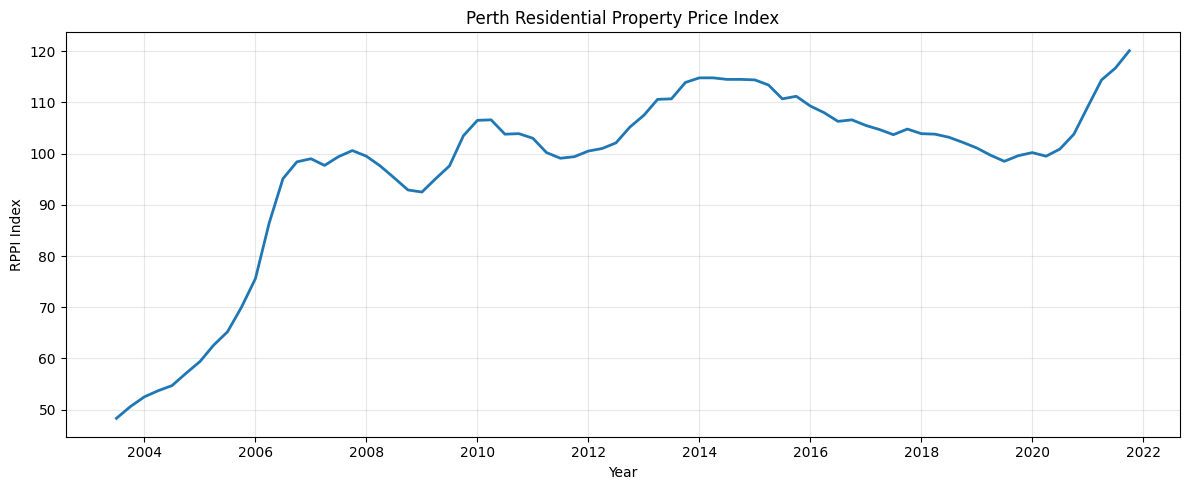

In [ ]:
import matplotlib.pyplot as plt

# Convert Quarter into a timestamp for plotting
eda_df = master_df.copy()

eda_df["Date"] = pd.PeriodIndex(
    eda_df["Quarter"],
    freq="Q"
).to_timestamp()

# ---------------------------------------------------------
# Plot 1: Perth Residential Property Price Index
# ---------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    eda_df["Date"],
    eda_df["Perth_RPPI"],
    linewidth=2
)

plt.title("Perth Residential Property Price Index")
plt.xlabel("Year")
plt.ylabel("RPPI Index")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

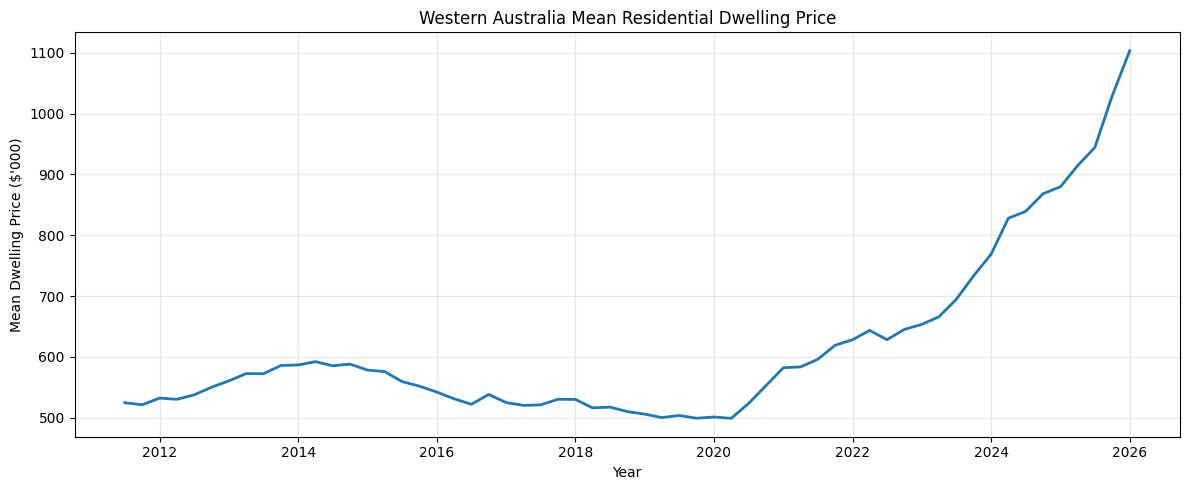

In [ ]:
# ---------------------------------------------------------
# Plot 2: WA Mean Dwelling Price
# ---------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    eda_df["Date"],
    eda_df["WA_Mean_Dwelling_Price_000"],
    linewidth=2
)

plt.title("Western Australia Mean Residential Dwelling Price")
plt.xlabel("Year")
plt.ylabel("Mean Dwelling Price ($'000)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
price_summary = eda_df[
    [
        "Perth_RPPI",
        "WA_Mean_Dwelling_Price_000"
    ]
].describe().T

display(price_summary)

,count,mean,std,min,25%,50%,75%,max
Perth_RPPI,74.0,97.409459,17.571663,48.3,97.625,101.6,106.60,120.1
WA_Mean_Dwelling_Price_000,59.0,616.127119,140.164417,499.1,524.900,572.4,636.05,1103.5


In [ ]:
for variable in [
    "Perth_RPPI",
    "WA_Mean_Dwelling_Price_000"
]:

    available = eda_df[
        ["Quarter", variable]
    ].dropna()

    print("\n", variable)
    print("-" * 50)
    print("Observations:", len(available))
    print("Start:", available["Quarter"].iloc[0])
    print("End:", available["Quarter"].iloc[-1])
    print("Minimum:", available[variable].min())
    print("Maximum:", available[variable].max())
    print("Mean:", round(available[variable].mean(), 2))
    print("Std Dev:", round(available[variable].std(), 2))


 Perth_RPPI
--------------------------------------------------
Observations: 74
Start: 2003Q3
End: 2021Q4
Minimum: 48.3
Maximum: 120.1
Mean: 97.41
Std Dev: 17.57

 WA_Mean_Dwelling_Price_000
--------------------------------------------------
Observations: 59
Start: 2011Q3
End: 2026Q1
Minimum: 499.1
Maximum: 1103.5
Mean: 616.13
Std Dev: 140.16


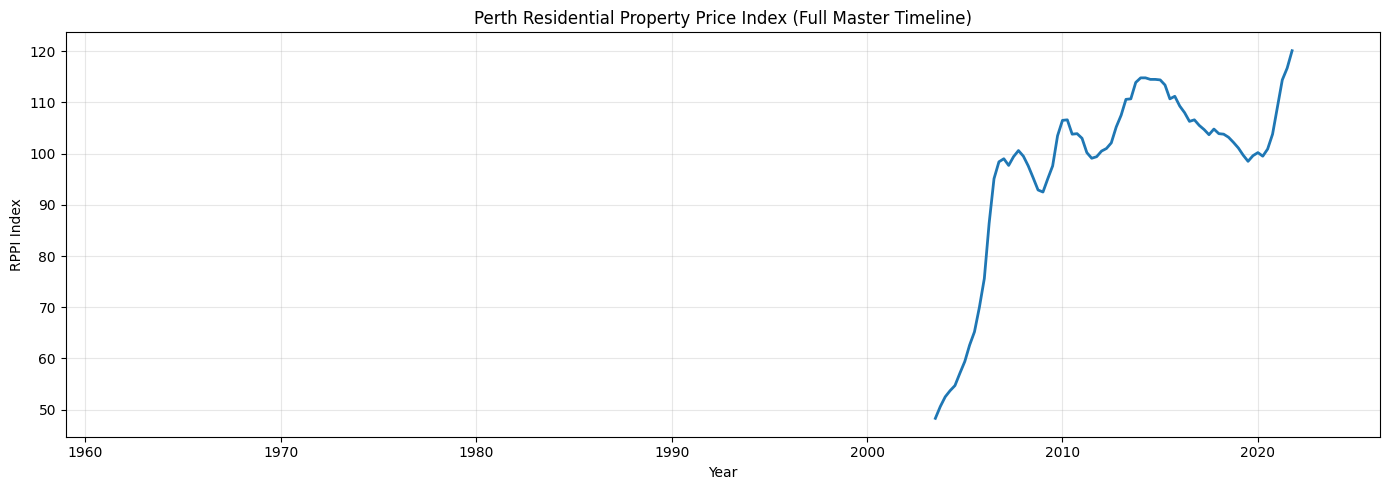

In [ ]:
# Full master-period RPPI plot

plt.figure(figsize=(14, 5))

plt.plot(
    eda_df["Date"],
    eda_df["Perth_RPPI"],
    linewidth=2
)

plt.xlim(
    eda_df["Date"].min(),
    eda_df["Date"].max()
)

plt.title("Perth Residential Property Price Index (Full Master Timeline)")
plt.xlabel("Year")
plt.ylabel("RPPI Index")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

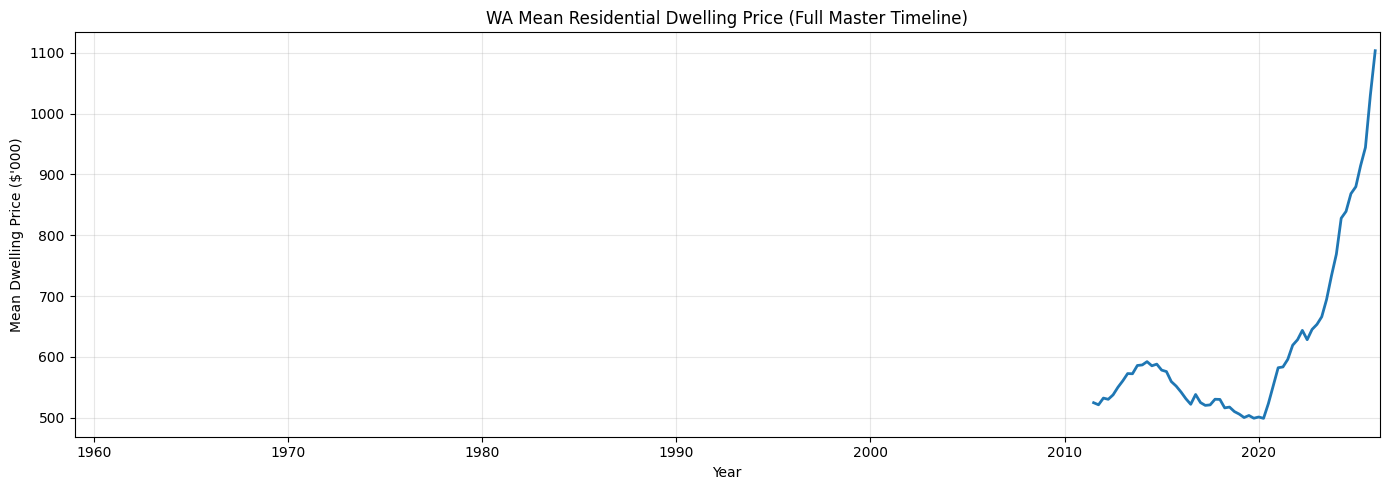

In [ ]:
# Full master-period mean dwelling price plot

plt.figure(figsize=(14, 5))

plt.plot(
    eda_df["Date"],
    eda_df["WA_Mean_Dwelling_Price_000"],
    linewidth=2
)

plt.xlim(
    eda_df["Date"].min(),
    eda_df["Date"].max()
)

plt.title("WA Mean Residential Dwelling Price (Full Master Timeline)")
plt.xlabel("Year")
plt.ylabel("Mean Dwelling Price ($'000)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

EDA Step 2: Population and Migration

Step 2A — WA Population trend

Observations: 179
Coverage: 1981Q2 to 2025Q4


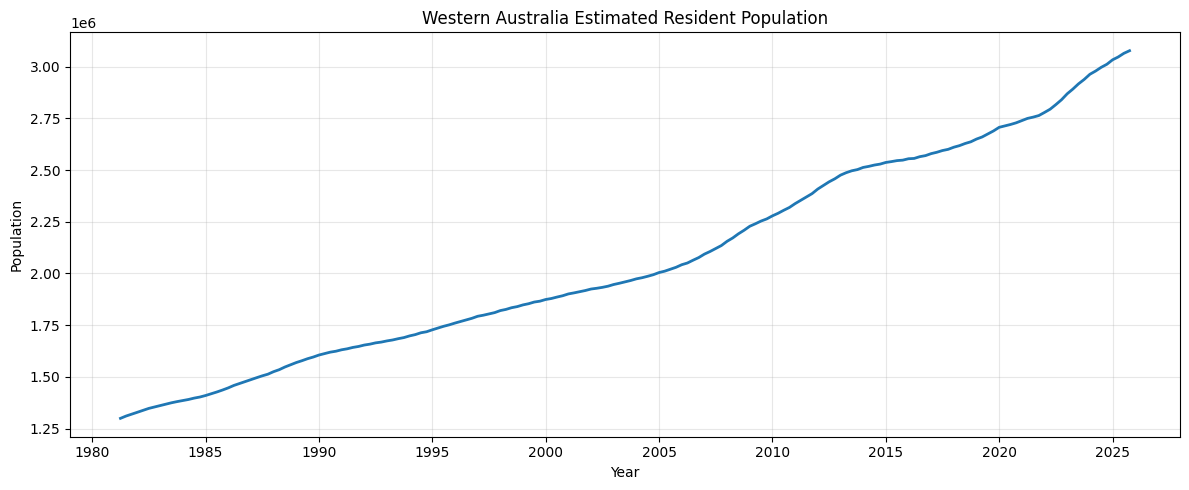

In [ ]:
# ---------------------------------------------------------
# EDA STEP 2A - WA Population
# Full available history
# ---------------------------------------------------------

population_data = eda_df[
    ["Date", "Quarter", "WA_Population"]
].dropna()

print("Observations:", len(population_data))
print(
    "Coverage:",
    population_data["Quarter"].iloc[0],
    "to",
    population_data["Quarter"].iloc[-1]
)

plt.figure(figsize=(12, 5))

plt.plot(
    population_data["Date"],
    population_data["WA_Population"],
    linewidth=2
)

plt.title("Western Australia Estimated Resident Population")
plt.xlabel("Year")
plt.ylabel("Population")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Step 2B — Migration and natural increase

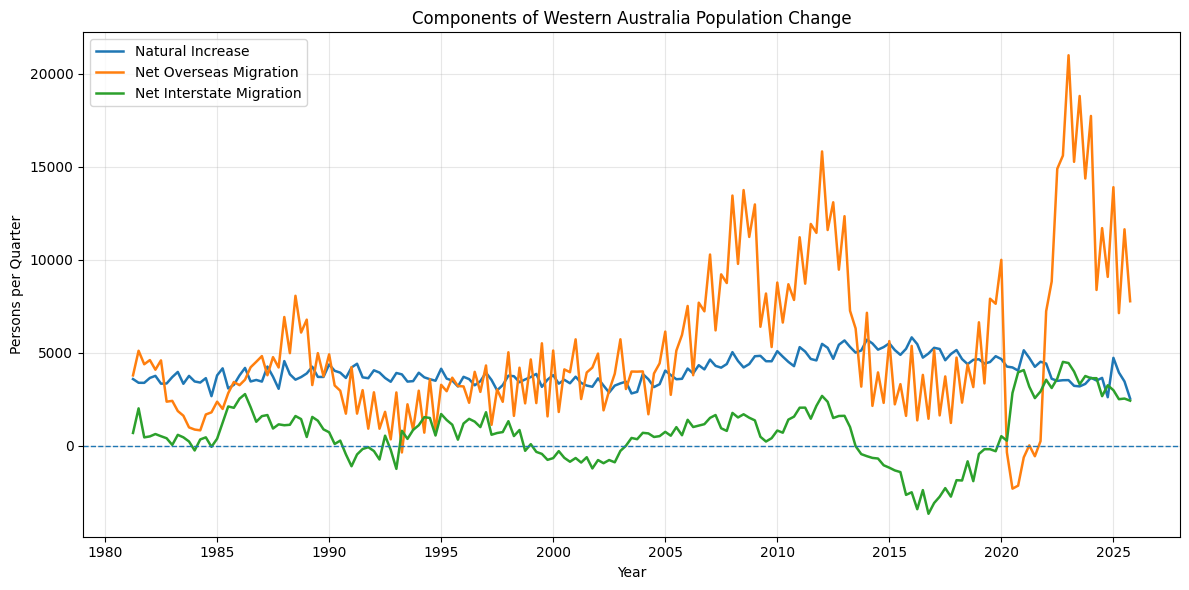

In [ ]:
# ---------------------------------------------------------
# EDA STEP 2B - Components of WA Population Change
# ---------------------------------------------------------

migration_data = eda_df[
    [
        "Date",
        "Quarter",
        "WA_Natural_Increase",
        "WA_NOM",
        "WA_NIM"
    ]
].dropna()

plt.figure(figsize=(12, 6))

plt.plot(
    migration_data["Date"],
    migration_data["WA_Natural_Increase"],
    label="Natural Increase",
    linewidth=1.8
)

plt.plot(
    migration_data["Date"],
    migration_data["WA_NOM"],
    label="Net Overseas Migration",
    linewidth=1.8
)

plt.plot(
    migration_data["Date"],
    migration_data["WA_NIM"],
    label="Net Interstate Migration",
    linewidth=1.8
)

# Zero line helps distinguish net inflow from net outflow
plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Components of Western Australia Population Change")
plt.xlabel("Year")
plt.ylabel("Persons per Quarter")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Step 2C — Descriptive statistics

In [ ]:
population_summary = eda_df[
    [
        "WA_Population",
        "WA_Natural_Increase",
        "WA_NOM",
        "WA_NIM"
    ]
].describe().T

display(population_summary)

,count,mean,std,min,25%,50%,75%,max
WA_Population,179.0,2.067145e+06,494397.965126,1300056.0,1661649.5,1959430.0,2526330.5,3076528.0
WA_Natural_Increase,179.0,4.017145e+03,714.945053,2528.0,3493.0,3830.0,4542.0,5821.0
WA_NOM,179.0,5.170263e+03,4115.786401,-2317.0,2358.5,3990.0,7134.0,20995.0
WA_NIM,179.0,6.944637e+02,1548.156520,-3669.0,-283.5,676.0,1534.0,4503.0


In [ ]:
for variable in [
    "WA_Population",
    "WA_Natural_Increase",
    "WA_NOM",
    "WA_NIM"
]:

    temp = eda_df[
        ["Quarter", variable]
    ].dropna()

    print("\n", variable)
    print("-" * 50)
    print("Observations:", len(temp))
    print("Start:", temp["Quarter"].iloc[0])
    print("End:", temp["Quarter"].iloc[-1])
    print("Minimum:", temp[variable].min())
    print("Maximum:", temp[variable].max())
    print("Mean:", round(temp[variable].mean(), 2))


 WA_Population
--------------------------------------------------
Observations: 179
Start: 1981Q2
End: 2025Q4
Minimum: 1300056.0
Maximum: 3076528.0
Mean: 2067144.59

 WA_Natural_Increase
--------------------------------------------------
Observations: 179
Start: 1981Q2
End: 2025Q4
Minimum: 2528.0
Maximum: 5821.0
Mean: 4017.15

 WA_NOM
--------------------------------------------------
Observations: 179
Start: 1981Q2
End: 2025Q4
Minimum: -2317.0
Maximum: 20995.0
Mean: 5170.26

 WA_NIM
--------------------------------------------------
Observations: 179
Start: 1981Q2
End: 2025Q4
Minimum: -3669.0
Maximum: 4503.0
Mean: 694.46


EDA Step 3 — Housing Supply

3A — Dwelling approvals

Observations: 172
Coverage: 1983Q3 to 2026Q2


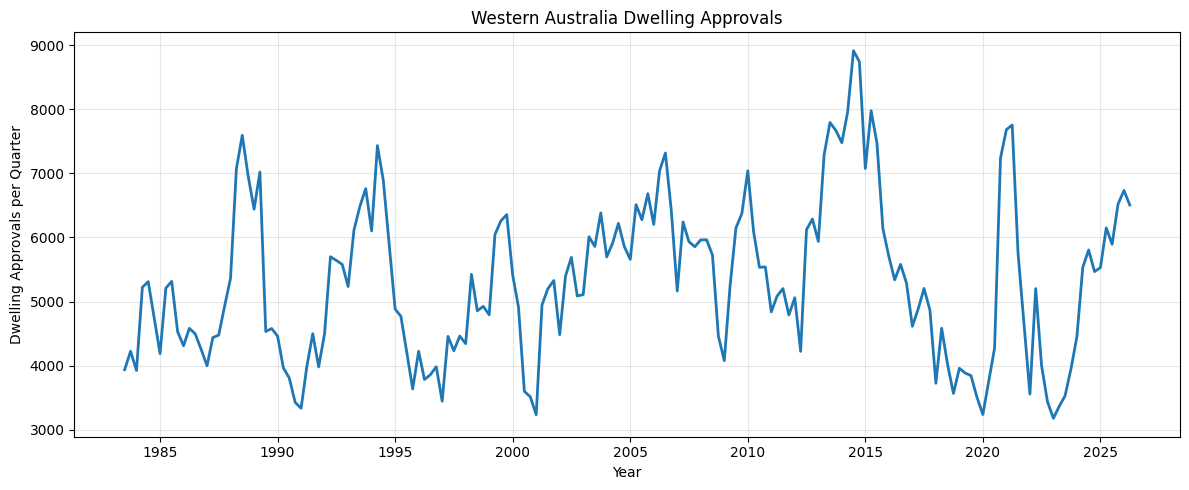

In [ ]:
approvals_data = eda_df[
    ["Date", "Quarter", "WA_Dwelling_Approvals"]
].dropna()

print("Observations:", len(approvals_data))
print(
    "Coverage:",
    approvals_data["Quarter"].iloc[0],
    "to",
    approvals_data["Quarter"].iloc[-1]
)

plt.figure(figsize=(12, 5))

plt.plot(
    approvals_data["Date"],
    approvals_data["WA_Dwelling_Approvals"],
    linewidth=2
)

plt.title("Western Australia Dwelling Approvals")
plt.xlabel("Year")
plt.ylabel("Dwelling Approvals per Quarter")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3B — Commencements and completions

Building activity coverage: 2001Q3 to 2026Q1


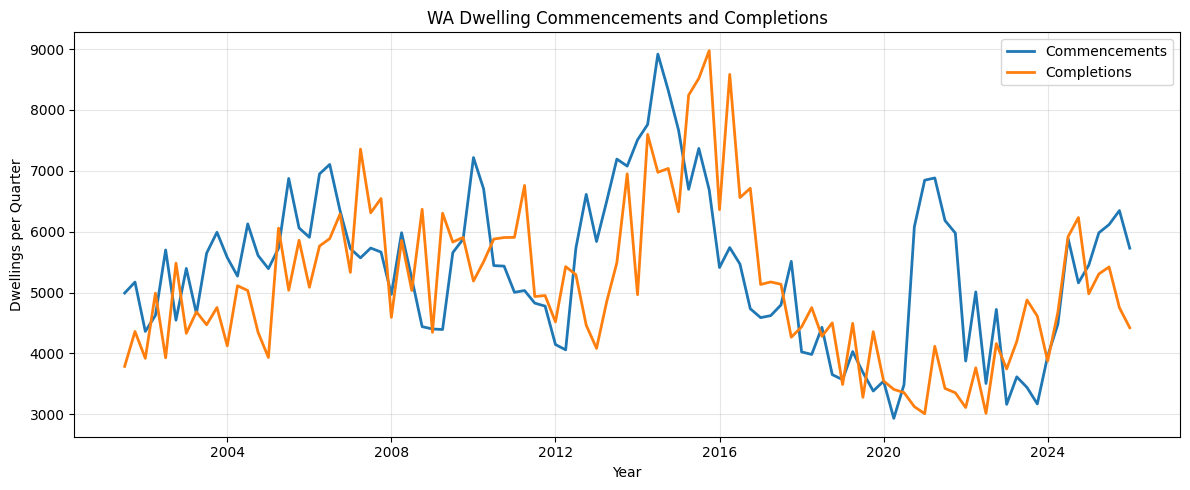

In [ ]:
building_data = eda_df[
    [
        "Date",
        "Quarter",
        "WA_Dwelling_Commencements",
        "WA_Dwelling_Completions"
    ]
].dropna()

print("Building activity coverage:",
      building_data["Quarter"].iloc[0],
      "to",
      building_data["Quarter"].iloc[-1])

plt.figure(figsize=(12, 5))

plt.plot(
    building_data["Date"],
    building_data["WA_Dwelling_Commencements"],
    label="Commencements",
    linewidth=2
)

plt.plot(
    building_data["Date"],
    building_data["WA_Dwelling_Completions"],
    label="Completions",
    linewidth=2
)

plt.title("WA Dwelling Commencements and Completions")
plt.xlabel("Year")
plt.ylabel("Dwellings per Quarter")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3C — Dwellings under construction

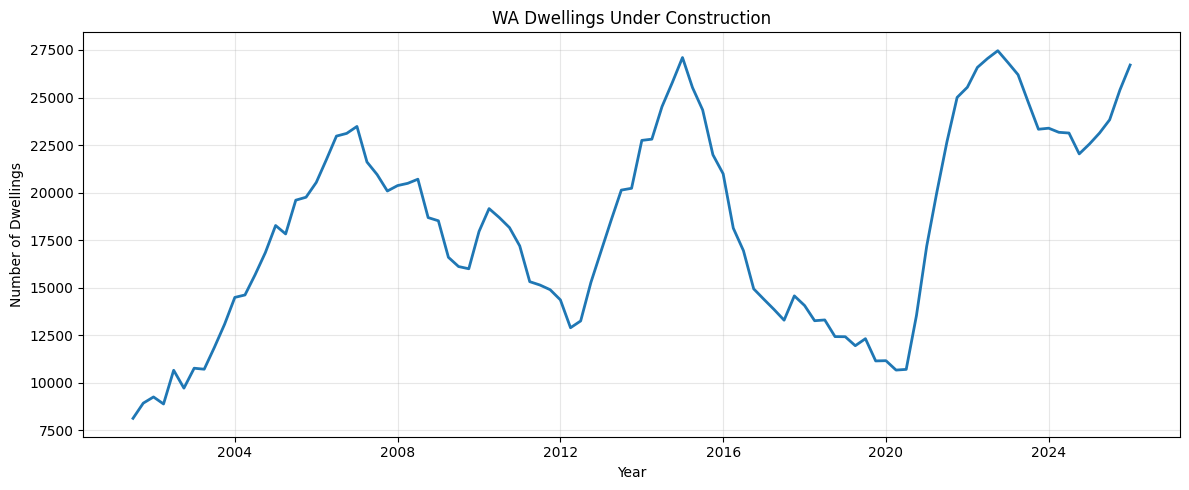

In [ ]:
under_construction_data = eda_df[
    ["Date", "Quarter", "WA_Dwellings_Under_Construction"]
].dropna()

plt.figure(figsize=(12, 5))

plt.plot(
    under_construction_data["Date"],
    under_construction_data["WA_Dwellings_Under_Construction"],
    linewidth=2
)

plt.title("WA Dwellings Under Construction")
plt.xlabel("Year")
plt.ylabel("Number of Dwellings")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3D — Supply descriptive statistics

In [ ]:
supply_summary = eda_df[
    [
        "WA_Dwelling_Approvals",
        "WA_Dwelling_Commencements",
        "WA_Dwelling_Completions",
        "WA_Dwellings_Under_Construction"
    ]
].describe().T

display(supply_summary)

,count,mean,std,min,25%,50%,75%,max
WA_Dwelling_Approvals,172.0,5310.790698,1239.787235,3178.0,4334.75,5228.0,6125.25,8913.0
WA_Dwelling_Commencements,99.0,5387.636364,1233.639203,2933.0,4513.00,5450.0,6070.50,8918.0
WA_Dwelling_Completions,99.0,5128.111111,1273.762047,3009.0,4305.50,4979.0,5895.00,8974.0
WA_Dwellings_Under_Construction,99.0,18219.797980,5222.481973,8124.0,13956.50,18267.0,22777.00,27462.0


EDA Step 4: Economic, rental and cost conditions

4A — Perth Rent Index

Rent coverage: 1972Q3 to 2025Q2


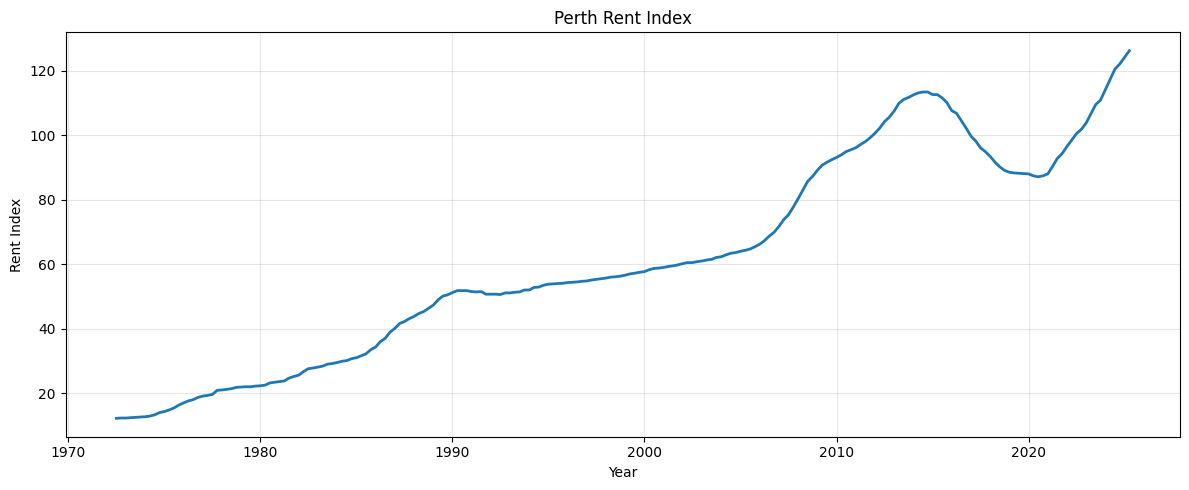

In [ ]:
rent_data = eda_df[
    ["Date", "Quarter", "Perth_Rent_Index"]
].dropna()

print(
    "Rent coverage:",
    rent_data["Quarter"].iloc[0],
    "to",
    rent_data["Quarter"].iloc[-1]
)

plt.figure(figsize=(12, 5))

plt.plot(
    rent_data["Date"],
    rent_data["Perth_Rent_Index"],
    linewidth=2
)

plt.title("Perth Rent Index")
plt.xlabel("Year")
plt.ylabel("Rent Index")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

4B — Housing lending rate

Interest rate coverage: 1959Q1 to 2026Q2


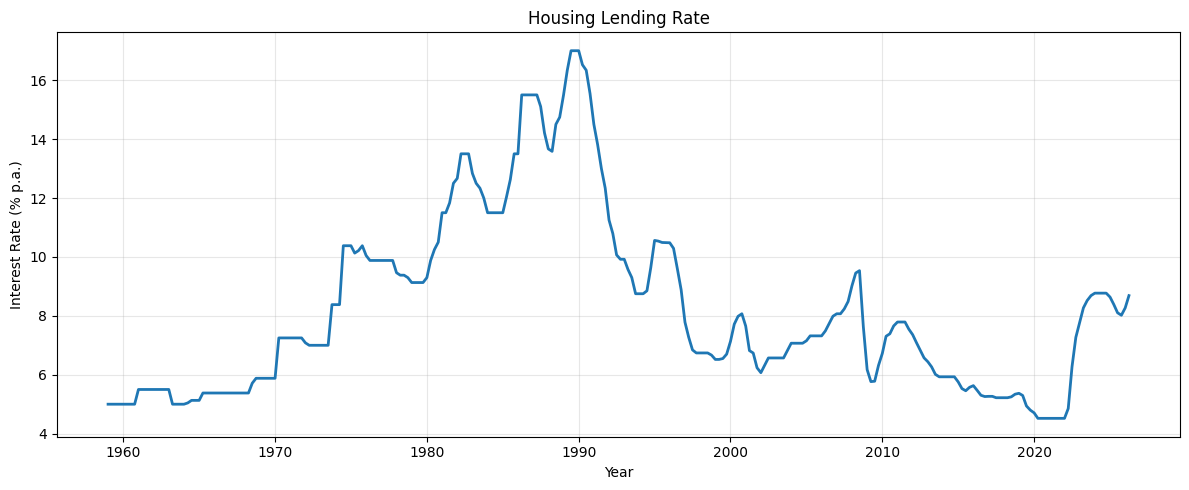

In [ ]:
rate_data = eda_df[
    ["Date", "Quarter", "Housing_Lending_Rate"]
].dropna()

print(
    "Interest rate coverage:",
    rate_data["Quarter"].iloc[0],
    "to",
    rate_data["Quarter"].iloc[-1]
)

plt.figure(figsize=(12, 5))

plt.plot(
    rate_data["Date"],
    rate_data["Housing_Lending_Rate"],
    linewidth=2
)

plt.title("Housing Lending Rate")
plt.xlabel("Year")
plt.ylabel("Interest Rate (% p.a.)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

4C — WA unemployment rate

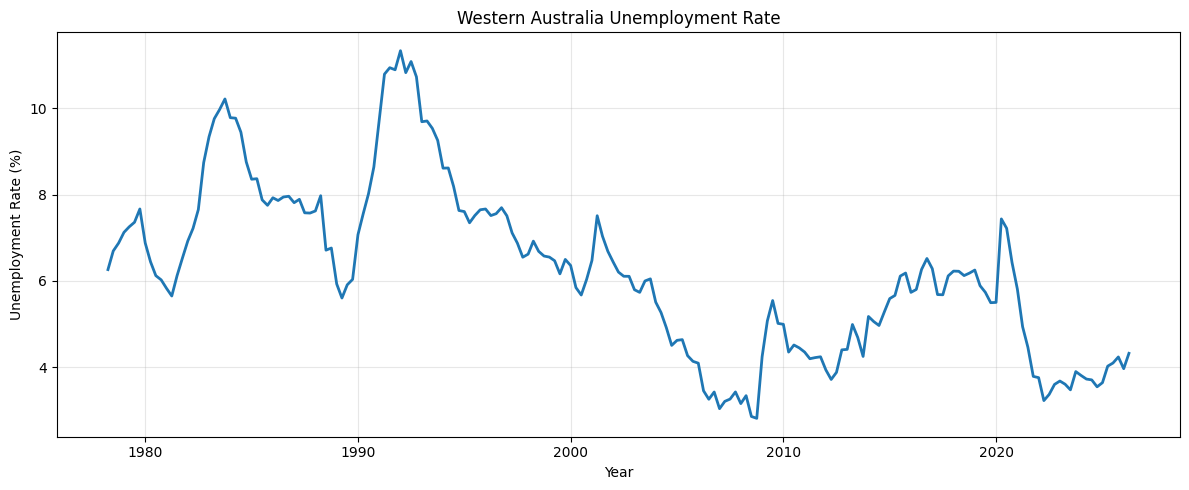

In [ ]:
unemployment_data = eda_df[
    ["Date", "Quarter", "WA_Unemployment_Rate"]
].dropna()

plt.figure(figsize=(12, 5))

plt.plot(
    unemployment_data["Date"],
    unemployment_data["WA_Unemployment_Rate"],
    linewidth=2
)

plt.title("Western Australia Unemployment Rate")
plt.xlabel("Year")
plt.ylabel("Unemployment Rate (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

4D — WA Wage Index

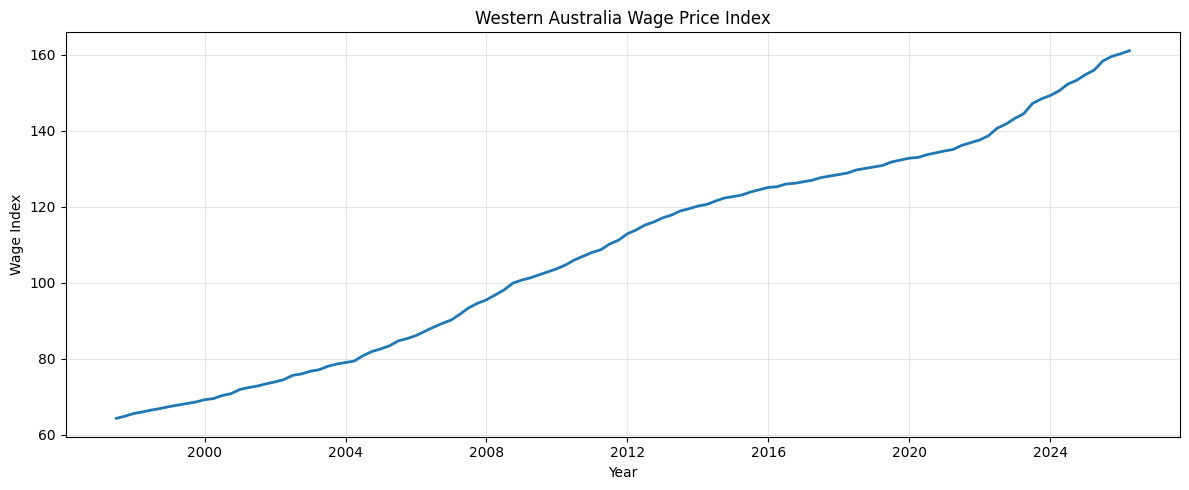

In [ ]:
wage_data = eda_df[
    ["Date", "Quarter", "WA_Wage_Index"]
].dropna()

plt.figure(figsize=(12, 5))

plt.plot(
    wage_data["Date"],
    wage_data["WA_Wage_Index"],
    linewidth=2
)

plt.title("Western Australia Wage Price Index")
plt.xlabel("Year")
plt.ylabel("Wage Index")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

4E — Perth construction cost index

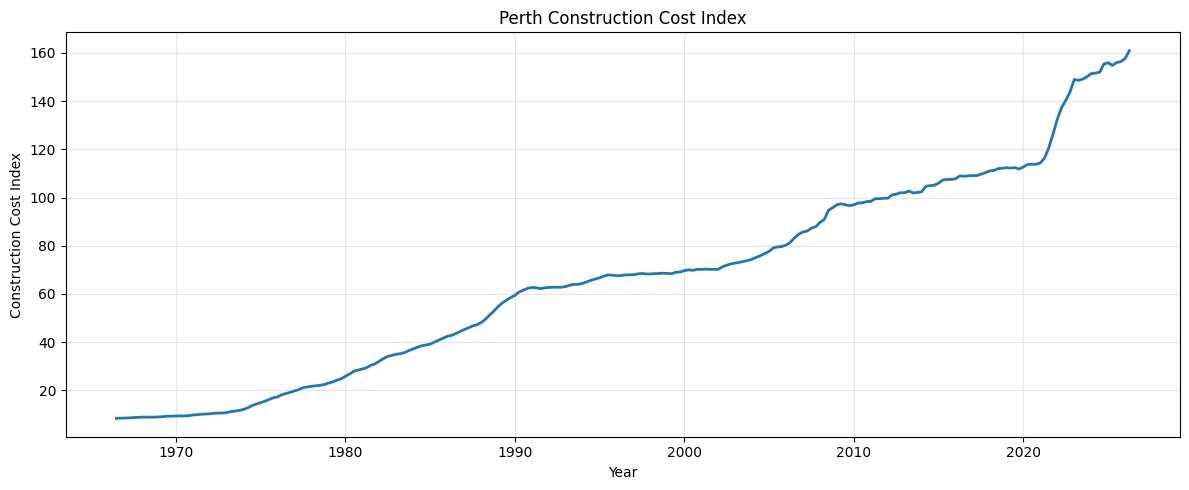

In [ ]:
cost_data = eda_df[
    ["Date", "Quarter", "Perth_Construction_Cost_Index"]
].dropna()

plt.figure(figsize=(12, 5))

plt.plot(
    cost_data["Date"],
    cost_data["Perth_Construction_Cost_Index"],
    linewidth=2
)

plt.title("Perth Construction Cost Index")
plt.xlabel("Year")
plt.ylabel("Construction Cost Index")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
economic_summary = eda_df[
    [
        "Perth_Rent_Index",
        "Housing_Lending_Rate",
        "WA_Unemployment_Rate",
        "WA_Wage_Index",
        "Perth_Construction_Cost_Index"
    ]
].describe().T

display(economic_summary)

,count,mean,std,min,25%,50%,75%,max
Perth_Rent_Index,212.0,61.582075,31.574862,12.200000,33.175000,56.450000,90.400000,126.200000
Housing_Lending_Rate,270.0,8.215802,3.040242,4.520000,5.724167,7.288333,9.880000,17.000000
WA_Unemployment_Rate,193.0,6.237935,1.961211,2.813554,4.513518,6.122676,7.555639,11.335226
WA_Wage_Index,116.0,108.800000,28.258287,64.300000,81.625000,112.050000,130.600000,161.100000
Perth_Construction_Cost_Index,240.0,66.735417,41.001162,8.400000,30.150000,67.900000,99.500000,160.900000


5A - Population relative to dwelling stock

In [ ]:
# ---------------------------------------------------------
# EDA STEP 5A
# Population relative to dwelling stock
# ---------------------------------------------------------

relationship_df = eda_df.copy()

# Dwelling stock is measured in thousands
relationship_df["WA_Dwelling_Stock"] = (
    relationship_df["WA_Dwelling_Stock_000"] * 1000
)

# Persons per residential dwelling
relationship_df["Persons_Per_Dwelling"] = (
    relationship_df["WA_Population"] /
    relationship_df["WA_Dwelling_Stock"]
)

ratio_data = relationship_df[
    [
        "Date",
        "Quarter",
        "WA_Population",
        "WA_Dwelling_Stock",
        "Persons_Per_Dwelling"
    ]
].dropna()

print("Observations:", len(ratio_data))
print(
    "Coverage:",
    ratio_data["Quarter"].iloc[0],
    "to",
    ratio_data["Quarter"].iloc[-1]
)

print("\nFirst 5:")
display(ratio_data.head())

print("\nLast 5:")
display(ratio_data.tail())

Observations: 58
Coverage: 2011Q3 to 2025Q4

First 5:


,Date,Quarter,WA_Population,WA_Dwelling_Stock,Persons_Per_Dwelling
210,2011-07-01,2011Q3,2369612.0,942000.0,2.515512
211,2011-10-01,2011Q4,2385947.0,946300.0,2.521343
212,2012-01-01,2012Q1,2408108.0,950200.0,2.534317
213,2012-04-01,2012Q2,2425507.0,954900.0,2.540064
214,2012-07-01,2012Q3,2442876.0,959500.0,2.545989



Last 5:


,Date,Quarter,WA_Population,WA_Dwelling_Stock,Persons_Per_Dwelling
263,2024-10-01,2024Q4,3011063.0,1177400.0,2.557383
264,2025-01-01,2025Q1,3032661.0,1181700.0,2.566354
265,2025-04-01,2025Q2,3046209.0,1186500.0,2.567391
266,2025-07-01,2025Q3,3063821.0,1191300.0,2.571830
267,2025-10-01,2025Q4,3076528.0,1195300.0,2.573854


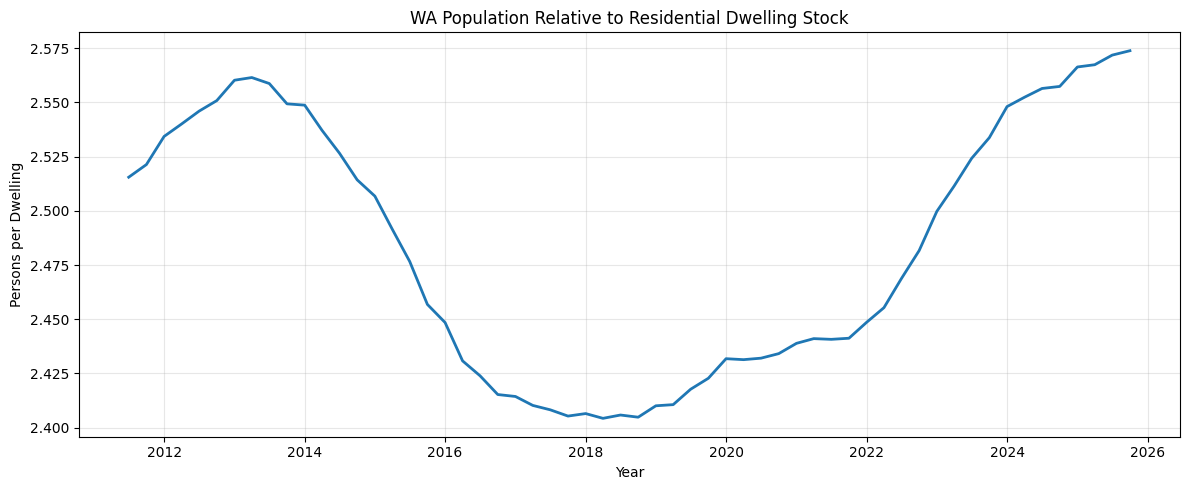

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    ratio_data["Date"],
    ratio_data["Persons_Per_Dwelling"],
    linewidth=2
)

plt.title("WA Population Relative to Residential Dwelling Stock")
plt.xlabel("Year")
plt.ylabel("Persons per Dwelling")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print(
    ratio_data["Persons_Per_Dwelling"]
    .describe()
)

count    58.000000
mean      2.483523
std       0.059550
min       2.404291
25%       2.430934
50%       2.479162
75%       2.544507
max       2.573854
Name: Persons_Per_Dwelling, dtype: float64


EDA STEP 6 - Correlation analysis

6A- Historical RPPI correlation dataset

In [ ]:
# ---------------------------------------------------------
# EDA STEP 6A
# Historical RPPI correlation dataset
# 2003Q3 - 2021Q4
# ---------------------------------------------------------

corr_df = master_df[
    (master_df["Quarter"] >= "2003Q3") &
    (master_df["Quarter"] <= "2021Q4")
].copy()

corr_variables = [
    "Perth_RPPI",
    "WA_Population",
    "WA_Natural_Increase",
    "WA_NOM",
    "WA_NIM",
    "WA_Dwelling_Approvals",
    "WA_Dwelling_Commencements",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate",
    "WA_Wage_Index",
    "Perth_Construction_Cost_Index"
]

corr_matrix = corr_df[corr_variables].corr()

print("Observations:", len(corr_df))
print(
    "Coverage:",
    corr_df["Quarter"].iloc[0],
    "to",
    corr_df["Quarter"].iloc[-1]
)

display(corr_matrix.round(3))

Observations: 74
Coverage: 2003Q3 to 2021Q4


,Perth_RPPI,WA_Population,WA_Natural_Increase,WA_NOM,WA_NIM,WA_Dwelling_Approvals,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction,Perth_Rent_Index,Housing_Lending_Rate,WA_Unemployment_Rate,WA_Wage_Index,Perth_Construction_Cost_Index
Perth_RPPI,1.000,0.758,0.810,-0.021,-0.135,0.081,0.129,0.200,0.279,0.834,-0.366,0.075,0.780,0.816
WA_Population,0.758,1.000,0.588,-0.362,-0.230,-0.201,-0.185,-0.188,-0.185,0.709,-0.799,0.560,0.998,0.981
WA_Natural_Increase,0.810,0.588,1.000,0.174,-0.264,0.076,0.114,0.264,0.216,0.855,-0.253,0.081,0.614,0.615
WA_NOM,-0.021,-0.362,0.174,1.000,0.296,-0.193,-0.174,0.011,0.001,0.007,0.658,-0.643,-0.343,-0.294
WA_NIM,-0.135,-0.230,-0.264,0.296,1.000,0.095,0.035,-0.424,0.035,-0.322,0.349,-0.525,-0.265,-0.205
WA_Dwelling_Approvals,0.081,-0.201,0.076,-0.193,0.095,1.000,0.930,0.425,0.674,0.158,0.145,-0.189,-0.206,-0.241
WA_Dwelling_Commencements,0.129,-0.185,0.114,-0.174,0.035,0.930,1.000,0.441,0.765,0.189,0.140,-0.236,-0.185,-0.204
WA_Dwelling_Completions,0.200,-0.188,0.264,0.011,-0.424,0.425,0.441,1.000,0.542,0.326,0.255,-0.159,-0.149,-0.147
WA_Dwellings_Under_Construction,0.279,-0.185,0.216,0.001,0.035,0.674,0.765,0.542,1.000,0.176,0.275,-0.466,-0.168,-0.128
Perth_Rent_Index,0.834,0.709,0.855,0.007,-0.322,0.158,0.189,0.326,0.176,1.000,-0.404,0.250,0.730,0.726


In [ ]:
rppi_correlations = (
    corr_matrix["Perth_RPPI"]
    .drop("Perth_RPPI")
    .sort_values(ascending=False)
)

print("Raw correlations with Perth RPPI:")
display(rppi_correlations.to_frame("Correlation"))

Raw correlations with Perth RPPI:


,Correlation
Perth_Rent_Index,0.833684
Perth_Construction_Cost_Index,0.815553
WA_Natural_Increase,0.809536
WA_Wage_Index,0.780430
WA_Population,0.757503
WA_Dwellings_Under_Construction,0.279375
WA_Dwelling_Completions,0.199521
WA_Dwelling_Commencements,0.128903
WA_Dwelling_Approvals,0.080829
WA_Unemployment_Rate,0.075097


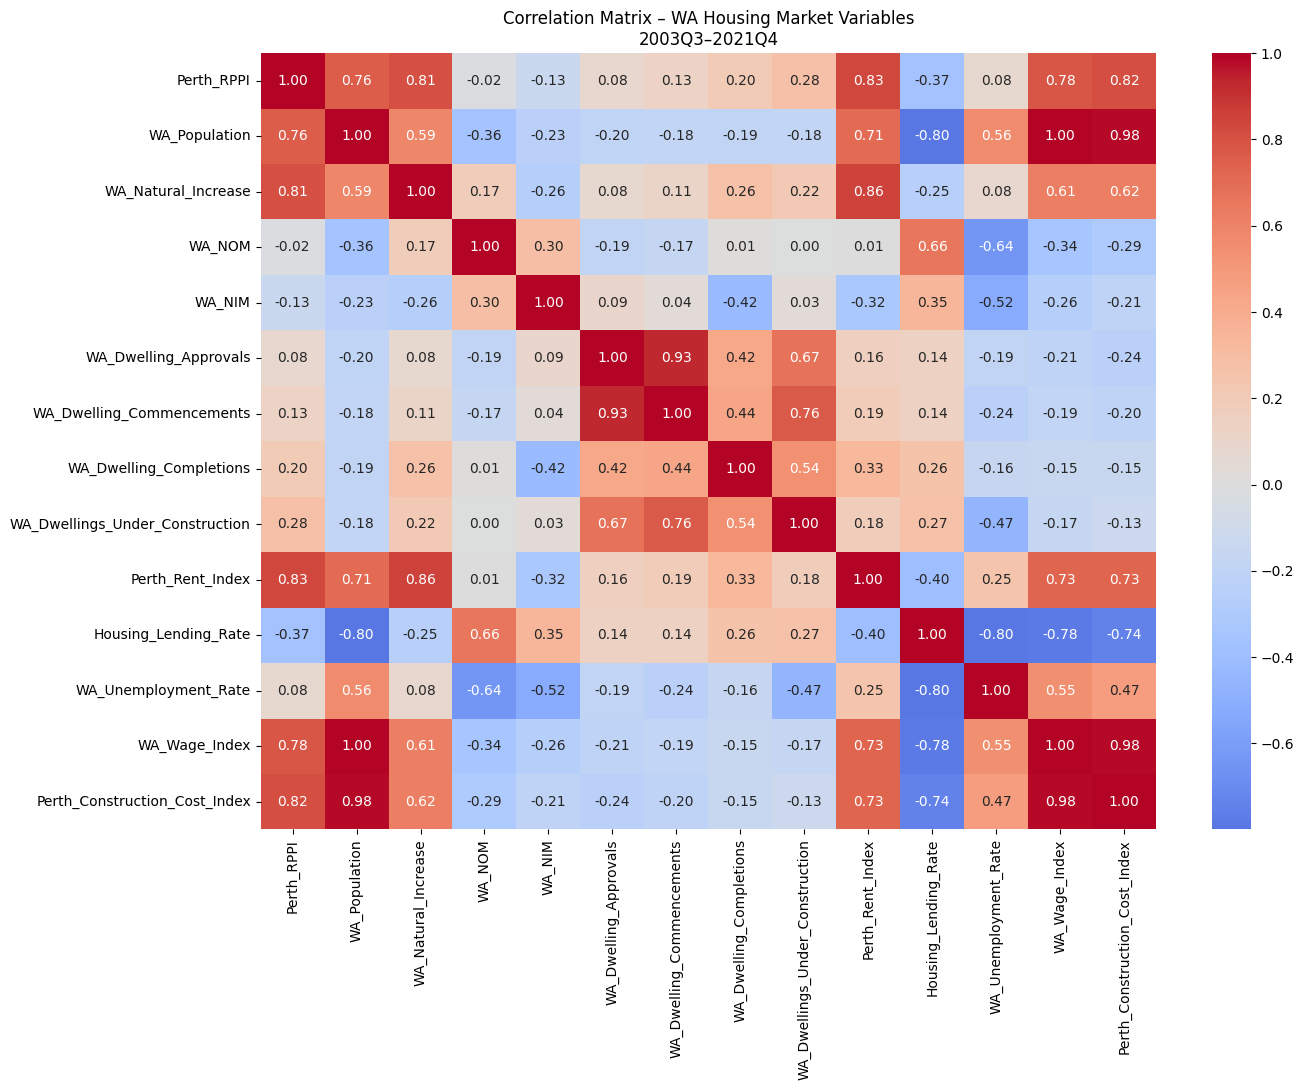

In [ ]:
import seaborn as sns

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Matrix – WA Housing Market Variables\n"
    "2003Q3–2021Q4"
)

plt.tight_layout()
plt.show()

Stationarity testing

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Historical modelling period
adf_df = master_df[
    (master_df["Quarter"] >= "2003Q3") &
    (master_df["Quarter"] <= "2021Q4")
].copy()

adf_variables = [
    "Perth_RPPI",
    "WA_Population",
    "WA_Natural_Increase",
    "WA_NOM",
    "WA_NIM",
    "WA_Dwelling_Approvals",
    "WA_Dwelling_Commencements",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate",
    "WA_Wage_Index",
    "Perth_Construction_Cost_Index"
]

adf_results = []

for variable in adf_variables:

    series = adf_df[variable].dropna()

    result = adfuller(
        series,
        autolag="AIC"
    )

    adf_results.append({
        "Variable": variable,
        "ADF_Statistic": result[0],
        "p_value": result[1],
        "Lags": result[2],
        "Observations": result[3],
        "Stationary_5pct": "Yes" if result[1] < 0.05 else "No"
    })

adf_level_results = pd.DataFrame(adf_results)

display(
    adf_level_results.round({
        "ADF_Statistic": 3,
        "p_value": 4
    })
)

/tmp/ipykernel_883/2612967498.py:32: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/2612967498.py:32: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/2612967498.py:32: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or a

,Variable,ADF_Statistic,p_value,Lags,Observations,Stationary_5pct
0,Perth_RPPI,-2.420,0.1362,1,72,No
1,WA_Population,-1.711,0.4255,5,68,No
2,WA_Natural_Increase,-2.214,0.2011,9,64,No
3,WA_NOM,-0.949,0.7714,9,64,No
4,WA_NIM,-2.455,0.1267,8,65,No
5,WA_Dwelling_Approvals,-2.614,0.0901,0,73,No
6,WA_Dwelling_Commencements,-2.548,0.1042,0,73,No
7,WA_Dwelling_Completions,-2.339,0.1597,8,65,No
8,WA_Dwellings_Under_Construction,-3.283,0.0156,2,71,Yes
9,Perth_Rent_Index,-2.570,0.0994,2,71,No


In [ ]:
adf_diff_results = []

for variable in adf_variables:

    series = adf_df[variable].dropna().diff().dropna()

    result = adfuller(
        series,
        autolag="AIC"
    )

    adf_diff_results.append({
        "Variable": variable,
        "ADF_Statistic": result[0],
        "p_value": result[1],
        "Lags": result[2],
        "Observations": result[3],
        "Stationary_5pct": "Yes" if result[1] < 0.05 else "No"
    })

adf_first_diff_results = pd.DataFrame(adf_diff_results)

display(
    adf_first_diff_results.round({
        "ADF_Statistic": 3,
        "p_value": 4
    })
)

/tmp/ipykernel_883/3546215495.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/3546215495.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/3546215495.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or afte

,Variable,ADF_Statistic,p_value,Lags,Observations,Stationary_5pct
0,Perth_RPPI,-3.302,0.0148,0,72,Yes
1,WA_Population,-2.381,0.1472,4,68,No
2,WA_Natural_Increase,-1.314,0.6228,10,62,No
3,WA_NOM,-3.160,0.0225,8,64,Yes
4,WA_NIM,-3.263,0.0166,3,69,Yes
5,WA_Dwelling_Approvals,-7.962,0.0000,0,72,Yes
6,WA_Dwelling_Commencements,-8.010,0.0000,0,72,Yes
7,WA_Dwelling_Completions,-2.254,0.1873,7,65,No
8,WA_Dwellings_Under_Construction,-2.957,0.0391,2,70,Yes
9,Perth_Rent_Index,-1.329,0.6160,1,71,No


ADF with a time trend

In [ ]:
# ---------------------------------------------------------
# ADF TEST WITH CONSTANT + TIME TREND
# ---------------------------------------------------------

adf_trend_results = []

for variable in adf_variables:

    series = adf_df[variable].dropna()

    result = adfuller(
        series,
        regression="ct",
        autolag="AIC"
    )

    adf_trend_results.append({
        "Variable": variable,
        "ADF_Statistic": result[0],
        "p_value": result[1],
        "Lags": result[2],
        "Observations": result[3],
        "Stationary_5pct": "Yes" if result[1] < 0.05 else "No"
    })

adf_trend_level = pd.DataFrame(adf_trend_results)

display(
    adf_trend_level.round({
        "ADF_Statistic": 3,
        "p_value": 4
    })
)

/tmp/ipykernel_883/3940767582.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/3940767582.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/3940767582.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or a

,Variable,ADF_Statistic,p_value,Lags,Observations,Stationary_5pct
0,Perth_RPPI,-2.796,0.1984,1,72,No
1,WA_Population,-1.537,0.8162,5,68,No
2,WA_Natural_Increase,-1.923,0.6429,9,64,No
3,WA_NOM,-3.267,0.0719,4,69,No
4,WA_NIM,-2.277,0.4467,8,65,No
5,WA_Dwelling_Approvals,-2.984,0.1367,1,72,No
6,WA_Dwelling_Commencements,-2.585,0.2870,0,73,No
7,WA_Dwelling_Completions,-2.560,0.2988,8,65,No
8,WA_Dwellings_Under_Construction,-3.122,0.1012,2,71,No
9,Perth_Rent_Index,-3.077,0.1119,2,71,No


In [ ]:
# ---------------------------------------------------------
# FIRST DIFFERENCE ADF WITH CONSTANT + TIME TREND
# ---------------------------------------------------------

adf_trend_diff_results = []

for variable in adf_variables:

    series = (
        adf_df[variable]
        .dropna()
        .diff()
        .dropna()
    )

    result = adfuller(
        series,
        regression="ct",
        autolag="AIC"
    )

    adf_trend_diff_results.append({
        "Variable": variable,
        "ADF_Statistic": result[0],
        "p_value": result[1],
        "Lags": result[2],
        "Observations": result[3],
        "Stationary_5pct": "Yes" if result[1] < 0.05 else "No"
    })

adf_trend_diff = pd.DataFrame(
    adf_trend_diff_results
)

display(
    adf_trend_diff.round({
        "ADF_Statistic": 3,
        "p_value": 4
    })
)

/tmp/ipykernel_883/2075352654.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/2075352654.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/tmp/ipykernel_883/2075352654.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or a

,Variable,ADF_Statistic,p_value,Lags,Observations,Stationary_5pct
0,Perth_RPPI,-3.296,0.0669,0,72,No
1,WA_Population,-2.778,0.2052,4,68,No
2,WA_Natural_Increase,-1.814,0.6982,10,62,No
3,WA_NOM,-3.402,0.0511,8,64,No
4,WA_NIM,-3.306,0.0652,3,69,No
5,WA_Dwelling_Approvals,-7.906,0.0000,0,72,Yes
6,WA_Dwelling_Commencements,-7.958,0.0000,0,72,Yes
7,WA_Dwelling_Completions,-3.319,0.0632,10,62,No
8,WA_Dwellings_Under_Construction,-2.907,0.1599,2,70,No
9,Perth_Rent_Index,-1.250,0.8998,1,71,No


In [ ]:
# ---------------------------------------------------------
# Mean Dwelling Price vs Net Overseas Migration
# Standardised quarterly comparison
# ---------------------------------------------------------

nom_price = master_df[
    [
        "Quarter",
        "WA_Mean_Dwelling_Price_000",
        "WA_NOM"
    ]
].dropna().copy()

# Convert Quarter for plotting
nom_price["Date"] = pd.PeriodIndex(
    nom_price["Quarter"],
    freq="Q"
).to_timestamp()

# Standardise both variables (Z-scores)
nom_price["Dwelling_Price_Z"] = (
    nom_price["WA_Mean_Dwelling_Price_000"]
    - nom_price["WA_Mean_Dwelling_Price_000"].mean()
) / nom_price["WA_Mean_Dwelling_Price_000"].std()

nom_price["NOM_Z"] = (
    nom_price["WA_NOM"]
    - nom_price["WA_NOM"].mean()
) / nom_price["WA_NOM"].std()

print("Coverage:",
      nom_price["Quarter"].iloc[0],
      "to",
      nom_price["Quarter"].iloc[-1])

print("Observations:", len(nom_price))

nom_price.head()

Coverage: 2011Q3 to 2025Q4
Observations: 58


,Quarter,WA_Mean_Dwelling_Price_000,WA_NOM,Date,Dwelling_Price_Z,NOM_Z
210,2011Q3,524.8,11922.0,2011-07-01,-0.660721,0.883239
211,2011Q4,521.4,11441.0,2011-10-01,-0.687811,0.798170
212,2012Q1,532.4,15822.0,2012-01-01,-0.600166,1.572983
213,2012Q2,530.4,11595.0,2012-04-01,-0.616101,0.825406
214,2012Q3,537.7,13087.0,2012-07-01,-0.557936,1.089278


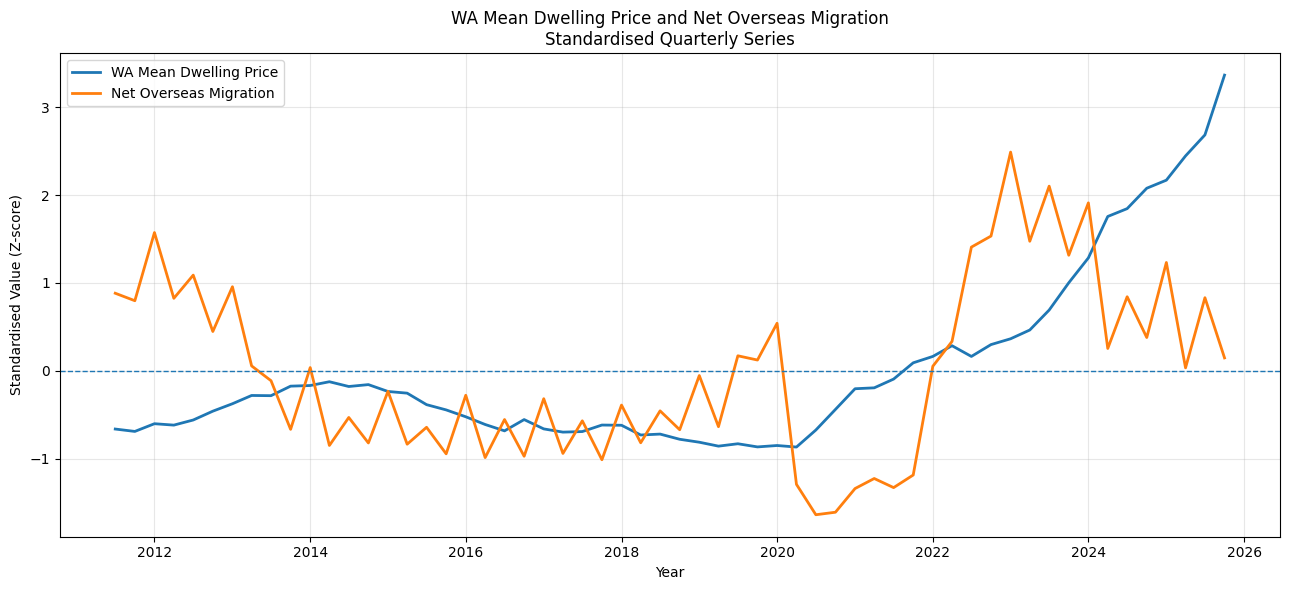

In [ ]:
plt.figure(figsize=(13, 6))

plt.plot(
    nom_price["Date"],
    nom_price["Dwelling_Price_Z"],
    label="WA Mean Dwelling Price",
    linewidth=2
)

plt.plot(
    nom_price["Date"],
    nom_price["NOM_Z"],
    label="Net Overseas Migration",
    linewidth=2
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "WA Mean Dwelling Price and Net Overseas Migration\n"
    "Standardised Quarterly Series"
)

plt.xlabel("Year")
plt.ylabel("Standardised Value (Z-score)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------
# WA Mean Dwelling Price vs Population Growth
# ---------------------------------------------------------

price_population = master_df[
    [
        "Quarter",
        "WA_Mean_Dwelling_Price_000",
        "WA_Population"
    ]
].copy()

# Make sure data is chronologically sorted
price_population["_period"] = pd.PeriodIndex(
    price_population["Quarter"],
    freq="Q"
)

price_population = (
    price_population
    .sort_values("_period")
    .drop(columns="_period")
    .reset_index(drop=True)
)

# Quarterly population growth (%)
price_population["Population_Growth_Pct"] = (
    price_population["WA_Population"]
    .pct_change(fill_method=None) * 100
)

# Keep quarters where BOTH price and population growth exist
price_population = price_population.dropna(
    subset=[
        "WA_Mean_Dwelling_Price_000",
        "Population_Growth_Pct"
    ]
).copy()

# Date for plotting
price_population["Date"] = pd.PeriodIndex(
    price_population["Quarter"],
    freq="Q"
).to_timestamp()

print(
    "Coverage:",
    price_population["Quarter"].iloc[0],
    "to",
    price_population["Quarter"].iloc[-1]
)

print("Observations:", len(price_population))

display(
    price_population[
        [
            "Quarter",
            "WA_Mean_Dwelling_Price_000",
            "WA_Population",
            "Population_Growth_Pct"
        ]
    ].head()
)

Coverage: 2011Q3 to 2025Q4
Observations: 58


,Quarter,WA_Mean_Dwelling_Price_000,WA_Population,Population_Growth_Pct
210,2011Q3,524.8,2369612.0,0.688491
211,2011Q4,521.4,2385947.0,0.689353
212,2012Q1,532.4,2408108.0,0.928814
213,2012Q2,530.4,2425507.0,0.722517
214,2012Q3,537.7,2442876.0,0.716098


In [ ]:
# Standardise mean dwelling price
price_population["Dwelling_Price_Z"] = (
    price_population["WA_Mean_Dwelling_Price_000"]
    - price_population["WA_Mean_Dwelling_Price_000"].mean()
) / price_population["WA_Mean_Dwelling_Price_000"].std()

# Standardise quarterly population growth
price_population["Population_Growth_Z"] = (
    price_population["Population_Growth_Pct"]
    - price_population["Population_Growth_Pct"].mean()
) / price_population["Population_Growth_Pct"].std()

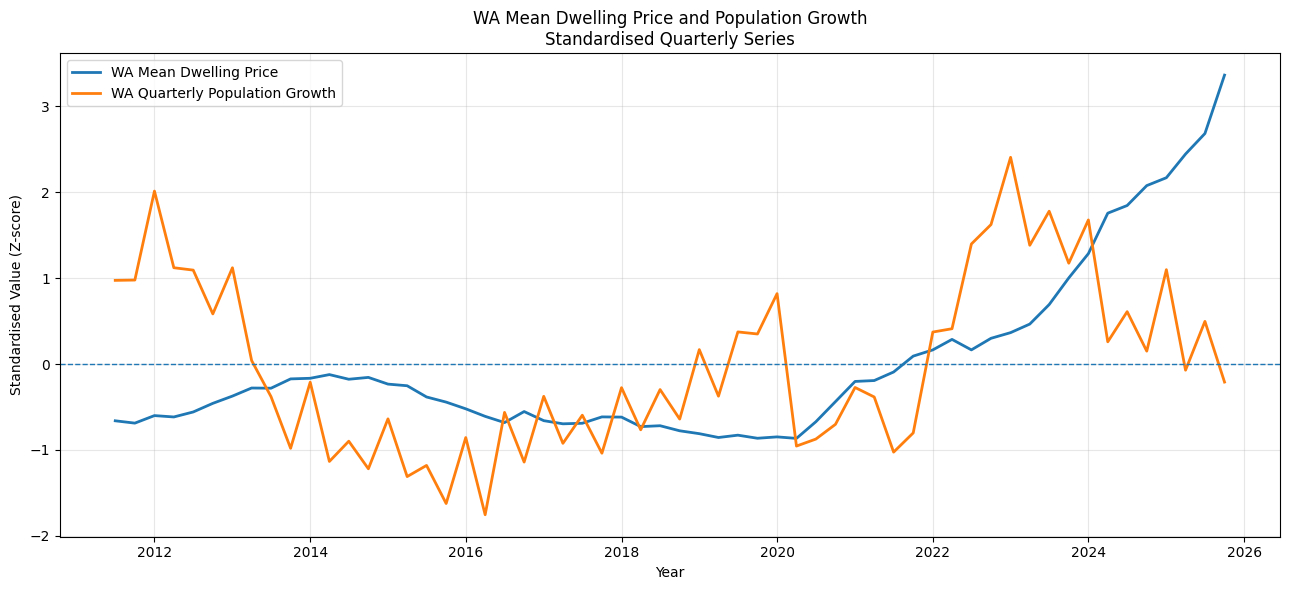

In [ ]:
plt.figure(figsize=(13, 6))

plt.plot(
    price_population["Date"],
    price_population["Dwelling_Price_Z"],
    label="WA Mean Dwelling Price",
    linewidth=2
)

plt.plot(
    price_population["Date"],
    price_population["Population_Growth_Z"],
    label="WA Quarterly Population Growth",
    linewidth=2
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "WA Mean Dwelling Price and Population Growth\n"
    "Standardised Quarterly Series"
)

plt.xlabel("Year")
plt.ylabel("Standardised Value (Z-score)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
growth_compare = master_df[
    [
        "Quarter",
        "WA_Mean_Dwelling_Price_000",
        "WA_Population"
    ]
].copy()

growth_compare["_period"] = pd.PeriodIndex(
    growth_compare["Quarter"],
    freq="Q"
)

growth_compare = (
    growth_compare
    .sort_values("_period")
    .reset_index(drop=True)
)

# Quarterly percentage growth
growth_compare["Dwelling_Price_Growth"] = (
    growth_compare["WA_Mean_Dwelling_Price_000"]
    .pct_change(fill_method=None) * 100
)

growth_compare["Population_Growth"] = (
    growth_compare["WA_Population"]
    .pct_change(fill_method=None) * 100
)

growth_compare = growth_compare.dropna(
    subset=["Dwelling_Price_Growth", "Population_Growth"]
)

growth_compare["Date"] = (
    growth_compare["_period"].dt.to_timestamp()
)

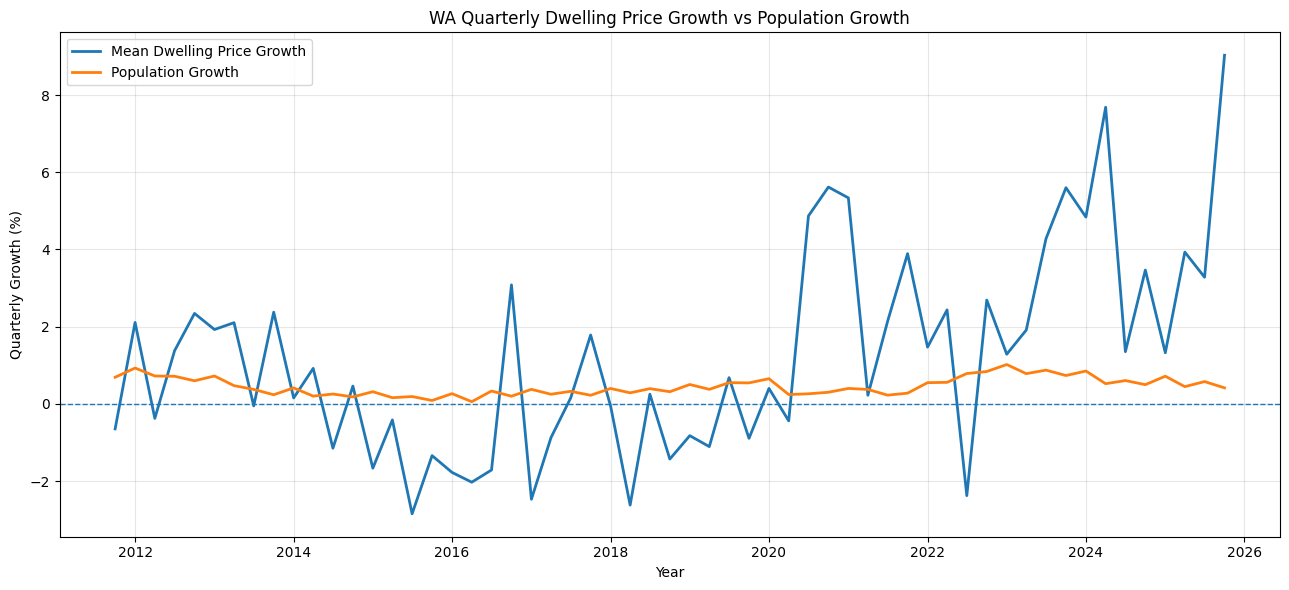

In [ ]:
plt.figure(figsize=(13, 6))

plt.plot(
    growth_compare["Date"],
    growth_compare["Dwelling_Price_Growth"],
    label="Mean Dwelling Price Growth",
    linewidth=2
)

plt.plot(
    growth_compare["Date"],
    growth_compare["Population_Growth"],
    label="Population Growth",
    linewidth=2
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title(
    "WA Quarterly Dwelling Price Growth vs Population Growth"
)

plt.xlabel("Year")
plt.ylabel("Quarterly Growth (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#Modelling

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"
CLEAN_FOLDER = os.path.join(PROJECT_FOLDER, "Clean_Data")

MASTER_FILE = os.path.join(
    CLEAN_FOLDER,
    "WA_Housing_Master_Full_1959Q1_2026Q2.csv"
)

master_df = pd.read_csv(MASTER_FILE)

print("Master dataset loaded.")
print("Shape:", master_df.shape)
print(
    "Coverage:",
    master_df["Quarter"].iloc[0],
    "to",
    master_df["Quarter"].iloc[-1]
)

Master dataset loaded.
Shape: (270, 17)
Coverage: 1959Q1 to 2026Q2


In [ ]:
print(master_df.columns.tolist())

print("\nMissing values:")
print(master_df.isna().sum())

['Quarter', 'WA_Population', 'WA_Natural_Increase', 'WA_NOM', 'WA_NIM', 'WA_Dwelling_Approvals', 'WA_Dwelling_Commencements', 'WA_Dwelling_Completions', 'WA_Dwellings_Under_Construction', 'Perth_RPPI', 'WA_Mean_Dwelling_Price_000', 'Perth_Rent_Index', 'Housing_Lending_Rate', 'WA_Unemployment_Rate', 'WA_Wage_Index', 'Perth_Construction_Cost_Index', 'WA_Dwelling_Stock_000']

Missing values:
Quarter                              0
WA_Population                       91
WA_Natural_Increase                 91
WA_NOM                              91
WA_NIM                              91
WA_Dwelling_Approvals               98
WA_Dwelling_Commencements          171
WA_Dwelling_Completions            171
WA_Dwellings_Under_Construction    171
Perth_RPPI                         196
WA_Mean_Dwelling_Price_000         211
Perth_Rent_Index                    58
Housing_Lending_Rate                 0
WA_Unemployment_Rate                77
WA_Wage_Index                      154
Perth_Construction_Cost

In [ ]:
# ============================================================
# STEP 4: CREATE FOUR MODEL-SPECIFIC DATASETS
# ============================================================

# MODEL 1 — Historical Housing Price
model1_vars = [
    "Quarter",
    "Perth_RPPI",
    "WA_Population",
    "WA_NOM",
    "WA_NIM",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate",
    "WA_Wage_Index",
    "Perth_Construction_Cost_Index"
]

model1 = master_df[model1_vars].dropna().copy()


# MODEL 2 — Housing Supply
model2_vars = [
    "Quarter",
    "WA_Dwelling_Completions",
    "WA_Dwelling_Approvals",
    "WA_Dwelling_Commencements",
    "WA_Population",
    "WA_NOM",
    "WA_NIM",
    "Housing_Lending_Rate",
    "Perth_Construction_Cost_Index"
]

model2 = master_df[model2_vars].dropna().copy()


# MODEL 3 — Long-Run Population / Housing Development
model3_vars = [
    "Quarter",
    "WA_Dwelling_Approvals",
    "WA_Population",
    "WA_NOM",
    "WA_NIM",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate",
    "Perth_Construction_Cost_Index"
]

model3 = master_df[model3_vars].dropna().copy()


# MODEL 4 — Recent Housing Market
model4_vars = [
    "Quarter",
    "WA_Mean_Dwelling_Price_000",
    "WA_Population",
    "WA_Dwelling_Stock_000",
    "WA_NOM",
    "WA_NIM",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate"
]

model4 = master_df[model4_vars].dropna().copy()

print("Four candidate modelling datasets created successfully.")

Four candidate modelling datasets created successfully.


In [ ]:
# ============================================================
# STEP 5: MODEL DATA AVAILABILITY SUMMARY
# ============================================================

models = {
    "Model 1 - Historical Price": model1,
    "Model 2 - Housing Supply": model2,
    "Model 3 - Population/Housing Development": model3,
    "Model 4 - Recent Housing Market": model4
}

summary = []

for name, df in models.items():
    summary.append({
        "Model": name,
        "Start Quarter": df["Quarter"].iloc[0],
        "End Quarter": df["Quarter"].iloc[-1],
        "Observations": len(df),
        "Variables": len(df.columns) - 1
    })

model_summary = pd.DataFrame(summary)

display(model_summary)

,Model,Start Quarter,End Quarter,Observations,Variables
0,Model 1 - Historical Price,2003Q3,2021Q4,74,11
1,Model 2 - Housing Supply,2001Q3,2025Q4,98,8
2,Model 3 - Population/Housing Development,1983Q3,2025Q4,170,7
3,Model 4 - Recent Housing Market,2011Q3,2025Q2,56,8


Model 1

In [ ]:
# ============================================================
# STEP 6: MODEL 1 — CREATE WORKING COPY
# Historical Housing Price Model
# ============================================================

model1_work = model1.copy()

# Convert Quarter to proper quarterly period
model1_work["Quarter_Period"] = pd.PeriodIndex(
    model1_work["Quarter"],
    freq="Q"
)

print("Model 1 working dataset created.")
print("Shape:", model1_work.shape)
print(
    "Coverage:",
    model1_work["Quarter"].iloc[0],
    "to",
    model1_work["Quarter"].iloc[-1]
)

display(model1_work.head())

Model 1 working dataset created.
Shape: (74, 13)
Coverage: 2003Q3 to 2021Q4


,Quarter,Perth_RPPI,WA_Population,WA_NOM,WA_NIM,WA_Dwelling_Completions,WA_Dwellings_Under_Construction,Perth_Rent_Index,Housing_Lending_Rate,WA_Unemployment_Rate,WA_Wage_Index,Perth_Construction_Cost_Index,Quarter_Period
178,2003Q3,48.3,1959430.0,3983.0,410.0,4471.0,11852.0,61.5,6.57,5.998238,78.0,73.5,2003Q3
179,2003Q4,50.6,1966130.0,3977.0,344.0,4754.0,13074.0,62.1,6.82,6.046619,78.6,73.9,2003Q4
180,2004Q1,52.5,1974145.0,3990.0,686.0,4124.0,14486.0,62.3,7.07,5.506840,79.0,74.4,2004Q1
181,2004Q2,53.7,1979542.0,1684.0,655.0,5112.0,14614.0,62.9,7.07,5.266802,79.4,75.2,2004Q2
182,2004Q3,54.7,1986513.0,3876.0,463.0,5033.0,15679.0,63.4,7.07,4.916721,80.8,75.9,2004Q3


In [ ]:
# ============================================================
# STEP 7: MODEL 1 — BASIC VARIABLE CHECK
# ============================================================

check_cols = [
    "Perth_RPPI",
    "WA_Population",
    "WA_NOM",
    "WA_NIM",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate",
    "WA_Wage_Index",
    "Perth_Construction_Cost_Index"
]

variable_check = pd.DataFrame({
    "Minimum": model1_work[check_cols].min(),
    "Maximum": model1_work[check_cols].max(),
    "Mean": model1_work[check_cols].mean(),
    "Missing": model1_work[check_cols].isna().sum()
}).round(3)

display(variable_check)

,Minimum,Maximum,Mean,Missing
Perth_RPPI,48.300,120.100,97.409,0
WA_Population,1959430.000,2763240.000,2385957.865,0
WA_NOM,-2317.000,15822.000,5863.324,0
WA_NIM,-3669.000,4062.000,360.973,0
WA_Dwelling_Completions,3009.000,8974.000,5339.784,0
WA_Dwellings_Under_Construction,10663.000,27104.000,17643.919,0
Perth_Rent_Index,61.500,113.400,90.101,0
Housing_Lending_Rate,4.520,9.533,6.389,0
WA_Unemployment_Rate,2.814,7.436,4.925,0
WA_Wage_Index,78.000,136.900,111.253,0


In [ ]:
# ============================================================
# STEP 8: MODEL 1 — CREATE TRANSFORMED VARIABLES
# ============================================================

model1_work = model1_work.copy()

# ------------------------------------------------------------
# A. LOG TRANSFORMATIONS
# All of these variables are strictly positive
# ------------------------------------------------------------

log_vars = [
    "Perth_RPPI",
    "WA_Population",
    "WA_Dwelling_Completions",
    "WA_Dwellings_Under_Construction",
    "Perth_Rent_Index",
    "WA_Wage_Index",
    "Perth_Construction_Cost_Index"
]

for var in log_vars:
    model1_work["ln_" + var] = np.log(model1_work[var])


# ------------------------------------------------------------
# B. QUARTERLY LOG CHANGES
# Approximate percentage change from previous quarter
# ------------------------------------------------------------

for var in log_vars:
    model1_work["dln_" + var] = (
        model1_work["ln_" + var].diff() * 100
    )


# ------------------------------------------------------------
# C. MIGRATION RELATIVE TO POPULATION
# NOM/NIM can be negative, so we do NOT log them
# Express as persons per 1,000 population
# ------------------------------------------------------------

model1_work["NOM_per_1000"] = (
    model1_work["WA_NOM"] /
    model1_work["WA_Population"] * 1000
)

model1_work["NIM_per_1000"] = (
    model1_work["WA_NIM"] /
    model1_work["WA_Population"] * 1000
)


# ------------------------------------------------------------
# D. CHANGES IN INTEREST AND UNEMPLOYMENT RATES
# Difference = percentage-point change from previous quarter
# ------------------------------------------------------------

model1_work["d_Housing_Lending_Rate"] = (
    model1_work["Housing_Lending_Rate"].diff()
)

model1_work["d_WA_Unemployment_Rate"] = (
    model1_work["WA_Unemployment_Rate"].diff()
)


print("Transformations created successfully.")
print("Original observations:", len(model1))
print("Working observations:", len(model1_work))

Transformations created successfully.
Original observations: 74
Working observations: 74


In [ ]:
# ============================================================
# STEP 9: CHECK TRANSFORMED VARIABLES
# ============================================================

transformed_cols = [
    "dln_Perth_RPPI",
    "dln_WA_Population",
    "NOM_per_1000",
    "NIM_per_1000",
    "dln_WA_Dwelling_Completions",
    "dln_WA_Dwellings_Under_Construction",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate",
    "dln_WA_Wage_Index",
    "dln_Perth_Construction_Cost_Index"
]

transformation_check = pd.DataFrame({
    "Minimum": model1_work[transformed_cols].min(),
    "Maximum": model1_work[transformed_cols].max(),
    "Mean": model1_work[transformed_cols].mean(),
    "Missing": model1_work[transformed_cols].isna().sum()
}).round(4)

display(transformation_check)

,Minimum,Maximum,Mean,Missing
dln_Perth_RPPI,-2.7561,13.3531,1.2478,1
dln_WA_Population,0.0576,0.9577,0.4709,1
NOM_per_1000,-0.8518,6.5703,2.5433,0
NIM_per_1000,-1.4278,1.4830,0.1719,0
dln_WA_Dwelling_Completions,-38.2187,43.2142,-0.3942,1
dln_WA_Dwellings_Under_Construction,-14.6445,23.8747,1.0227,1
dln_Perth_Rent_Index,-2.4766,3.3071,0.5855,1
d_Housing_Lending_Rate,-1.8967,0.5833,-0.0281,1
d_WA_Unemployment_Rate,-0.8727,1.9350,-0.0303,1
dln_WA_Wage_Index,0.1505,1.8369,0.7706,1


In [ ]:
# ============================================================
# STEP 10: MODEL 1 — CORRELATION CHECK AFTER TRANSFORMATION
# ============================================================

model1_baseline_vars = [
    "dln_Perth_RPPI",
    "dln_WA_Population",
    "NOM_per_1000",
    "dln_WA_Dwelling_Completions",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

model1_corr = (
    model1_work[model1_baseline_vars]
    .dropna()
    .corr()
    .round(3)
)

display(model1_corr)

,dln_Perth_RPPI,dln_WA_Population,NOM_per_1000,dln_WA_Dwelling_Completions,dln_Perth_Rent_Index,d_Housing_Lending_Rate,d_WA_Unemployment_Rate
dln_Perth_RPPI,1.000,-0.043,-0.113,0.106,0.274,0.240,-0.250
dln_WA_Population,-0.043,1.000,0.930,-0.238,0.635,-0.119,0.035
NOM_per_1000,-0.113,0.930,1.000,-0.250,0.546,-0.151,0.128
dln_WA_Dwelling_Completions,0.106,-0.238,-0.250,1.000,0.141,-0.027,-0.107
dln_Perth_Rent_Index,0.274,0.635,0.546,0.141,1.000,-0.002,-0.086
d_Housing_Lending_Rate,0.240,-0.119,-0.151,-0.027,-0.002,1.000,-0.344
d_WA_Unemployment_Rate,-0.250,0.035,0.128,-0.107,-0.086,-0.344,1.000


In [ ]:
# Show correlations among predictors only

predictor_vars = [
    "dln_WA_Population",
    "NOM_per_1000",
    "dln_WA_Dwelling_Completions",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

predictor_corr = (
    model1_work[predictor_vars]
    .dropna()
    .corr()
    .round(3)
)

display(predictor_corr)

,dln_WA_Population,NOM_per_1000,dln_WA_Dwelling_Completions,dln_Perth_Rent_Index,d_Housing_Lending_Rate,d_WA_Unemployment_Rate
dln_WA_Population,1.000,0.930,-0.238,0.635,-0.119,0.035
NOM_per_1000,0.930,1.000,-0.250,0.546,-0.151,0.128
dln_WA_Dwelling_Completions,-0.238,-0.250,1.000,0.141,-0.027,-0.107
dln_Perth_Rent_Index,0.635,0.546,0.141,1.000,-0.002,-0.086
d_Housing_Lending_Rate,-0.119,-0.151,-0.027,-0.002,1.000,-0.344
d_WA_Unemployment_Rate,0.035,0.128,-0.107,-0.086,-0.344,1.000


In [ ]:
# ============================================================
# STEP 11: MODEL 1 — VIF CHECK
# ============================================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

vif_vars = [
    "dln_WA_Population",
    "NOM_per_1000",
    "dln_WA_Dwelling_Completions",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

vif_data = model1_work[vif_vars].dropna().copy()

X_vif = sm.add_constant(vif_data)

vif_results = pd.DataFrame({
    "Variable": vif_vars,
    "VIF": [
        variance_inflation_factor(X_vif.values, i + 1)
        for i in range(len(vif_vars))
    ]
})

vif_results = vif_results.sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

display(vif_results.round(3))

,Variable,VIF
0,dln_WA_Population,9.506
1,NOM_per_1000,8.019
2,dln_Perth_Rent_Index,2.042
3,dln_WA_Dwelling_Completions,1.273
4,d_WA_Unemployment_Rate,1.219
5,d_Housing_Lending_Rate,1.172


In [ ]:
# ============================================================
# STEP 12: MODEL 1A — BASELINE HISTORICAL PRICE MODEL
# ============================================================

import statsmodels.api as sm

model1A_vars = [
    "dln_Perth_RPPI",
    "dln_WA_Population",
    "dln_WA_Dwelling_Completions",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

# Only removes the first observation created by differencing
model1A_data = model1_work[
    ["Quarter"] + model1A_vars
].dropna().copy()

# Dependent variable
y = model1A_data["dln_Perth_RPPI"]

# Explanatory variables
X = model1A_data[
    [
        "dln_WA_Population",
        "dln_WA_Dwelling_Completions",
        "dln_Perth_Rent_Index",
        "d_Housing_Lending_Rate",
        "d_WA_Unemployment_Rate"
    ]
]

X = sm.add_constant(X)

# Estimate OLS baseline model
model1A_result = sm.OLS(y, X).fit()

print("MODEL 1A — HISTORICAL HOUSING PRICE")
print("------------------------------------")
print("Period:", model1A_data["Quarter"].iloc[0],
      "to", model1A_data["Quarter"].iloc[-1])
print("Observations:", len(model1A_data))

print(model1A_result.summary())

MODEL 1A — HISTORICAL HOUSING PRICE
------------------------------------
Period: 2003Q4 to 2021Q4
Observations: 73
                            OLS Regression Results                            
Dep. Variable:         dln_Perth_RPPI   R-squared:                       0.216
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     3.688
Date:                Tue, 22 Sep 2026   Prob (F-statistic):            0.00523
Time:                        04:31:21   Log-Likelihood:                -173.17
No. Observations:                  73   AIC:                             358.3
Df Residuals:                      67   BIC:                             372.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]

In [ ]:
# ============================================================
# STEP 13: MODEL 1B — MIGRATION SPECIFICATION
# ============================================================

model1B_vars = [
    "dln_Perth_RPPI",
    "NOM_per_1000",
    "dln_WA_Dwelling_Completions",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

model1B_data = model1_work[
    ["Quarter"] + model1B_vars
].dropna().copy()

# Dependent variable
y = model1B_data["dln_Perth_RPPI"]

# Predictors
X = model1B_data[
    [
        "NOM_per_1000",
        "dln_WA_Dwelling_Completions",
        "dln_Perth_Rent_Index",
        "d_Housing_Lending_Rate",
        "d_WA_Unemployment_Rate"
    ]
]

X = sm.add_constant(X)

model1B_result = sm.OLS(y, X).fit()

print("MODEL 1B — HISTORICAL HOUSING PRICE (MIGRATION)")
print("------------------------------------------------")
print(
    "Period:",
    model1B_data["Quarter"].iloc[0],
    "to",
    model1B_data["Quarter"].iloc[-1]
)
print("Observations:", len(model1B_data))

print(model1B_result.summary())

MODEL 1B — HISTORICAL HOUSING PRICE (MIGRATION)
------------------------------------------------
Period: 2003Q4 to 2021Q4
Observations: 73
                            OLS Regression Results                            
Dep. Variable:         dln_Perth_RPPI   R-squared:                       0.223
Model:                            OLS   Adj. R-squared:                  0.165
Method:                 Least Squares   F-statistic:                     3.851
Date:                Tue, 22 Sep 2026   Prob (F-statistic):            0.00398
Time:                        04:32:17   Log-Likelihood:                -172.82
No. Observations:                  73   AIC:                             357.6
Df Residuals:                      67   BIC:                             371.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|

In [ ]:
# ============================================================
# STEP 14: MODEL 1 — LAG CORRELATION ANALYSIS
# ============================================================

lag_variables = {
    "Population Growth": "dln_WA_Population",
    "NOM per 1000": "NOM_per_1000",
    "Dwelling Completions Growth": "dln_WA_Dwelling_Completions",
    "Rent Growth": "dln_Perth_Rent_Index",
    "Lending Rate Change": "d_Housing_Lending_Rate",
    "Unemployment Change": "d_WA_Unemployment_Rate"
}

lag_results = []

for label, variable in lag_variables.items():

    for lag in range(0, 5):

        temp = pd.DataFrame({
            "Price_Growth": model1_work["dln_Perth_RPPI"],
            "Predictor": model1_work[variable].shift(lag)
        }).dropna()

        correlation = temp["Price_Growth"].corr(
            temp["Predictor"]
        )

        lag_results.append({
            "Variable": label,
            "Lag_Quarters": lag,
            "Correlation_with_RPPI_Growth": correlation,
            "Observations": len(temp)
        })

lag_table = pd.DataFrame(lag_results)

display(
    lag_table.round({
        "Correlation_with_RPPI_Growth": 3
    })
)

,Variable,Lag_Quarters,Correlation_with_RPPI_Growth,Observations
0,Population Growth,0,-0.043,73
1,Population Growth,1,-0.013,72
2,Population Growth,2,-0.023,71
3,Population Growth,3,0.099,70
4,Population Growth,4,0.075,69
5,NOM per 1000,0,-0.113,73
6,NOM per 1000,1,-0.079,73
7,NOM per 1000,2,-0.090,72
8,NOM per 1000,3,0.047,71
9,NOM per 1000,4,0.029,70


In [ ]:
# ============================================================
# STRONGEST LAG FOR EACH VARIABLE
# ============================================================

lag_table["Absolute_Correlation"] = (
    lag_table["Correlation_with_RPPI_Growth"].abs()
)

strongest_lags = (
    lag_table
    .sort_values("Absolute_Correlation", ascending=False)
    .groupby("Variable", as_index=False)
    .first()
    .sort_values("Absolute_Correlation", ascending=False)
)

display(
    strongest_lags[
        [
            "Variable",
            "Lag_Quarters",
            "Correlation_with_RPPI_Growth",
            "Observations"
        ]
    ].round(3)
)

,Variable,Lag_Quarters,Correlation_with_RPPI_Growth,Observations
4,Rent Growth,0,0.274,73
5,Unemployment Change,0,-0.250,73
1,Lending Rate Change,0,0.240,73
0,Dwelling Completions Growth,2,0.164,71
2,NOM per 1000,0,-0.113,73
3,Population Growth,3,0.099,70


In [ ]:
# ============================================================
# STEP 15: TEST LAGGED PRICE-GROWTH PERSISTENCE
# ============================================================

price_lag_results = []

for lag in range(1, 5):

    temp = pd.DataFrame({
        "Current_RPPI_Growth": model1_work["dln_Perth_RPPI"],
        "Lagged_RPPI_Growth": model1_work["dln_Perth_RPPI"].shift(lag)
    }).dropna()

    corr = temp["Current_RPPI_Growth"].corr(
        temp["Lagged_RPPI_Growth"]
    )

    price_lag_results.append({
        "RPPI_Growth_Lag": lag,
        "Correlation": corr,
        "Observations": len(temp)
    })

price_lag_table = pd.DataFrame(price_lag_results)

display(price_lag_table.round(3))

,RPPI_Growth_Lag,Correlation,Observations
0,1,0.771,72
1,2,0.557,71
2,3,0.351,70
3,4,0.275,69


In [ ]:
# ============================================================
# STEP 16A: CREATE LAG VARIABLES FOR MODEL 1C
# ============================================================

model1_work["RPPI_Growth_L1"] = (
    model1_work["dln_Perth_RPPI"].shift(1)
)

model1_work["Population_Growth_L3"] = (
    model1_work["dln_WA_Population"].shift(3)
)

model1_work["Completions_Growth_L2"] = (
    model1_work["dln_WA_Dwelling_Completions"].shift(2)
)

print("Dynamic lag variables created.")

Dynamic lag variables created.


In [ ]:
# ============================================================
# STEP 16B: MODEL 1C — DYNAMIC HISTORICAL PRICE MODEL
# ============================================================

model1C_vars = [
    "dln_Perth_RPPI",
    "RPPI_Growth_L1",
    "Population_Growth_L3",
    "Completions_Growth_L2",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

model1C_data = model1_work[
    ["Quarter"] + model1C_vars
].dropna().copy()

# Outcome
y = model1C_data["dln_Perth_RPPI"]

# Predictors
X = model1C_data[
    [
        "RPPI_Growth_L1",
        "Population_Growth_L3",
        "Completions_Growth_L2",
        "dln_Perth_Rent_Index",
        "d_Housing_Lending_Rate",
        "d_WA_Unemployment_Rate"
    ]
]

X = sm.add_constant(X)

model1C_result = sm.OLS(y, X).fit()

print("MODEL 1C — DYNAMIC HISTORICAL HOUSING PRICE")
print("---------------------------------------------")
print(
    "Period:",
    model1C_data["Quarter"].iloc[0],
    "to",
    model1C_data["Quarter"].iloc[-1]
)
print("Observations:", len(model1C_data))

print(model1C_result.summary())

MODEL 1C — DYNAMIC HISTORICAL HOUSING PRICE
---------------------------------------------
Period: 2004Q3 to 2021Q4
Observations: 70
                            OLS Regression Results                            
Dep. Variable:         dln_Perth_RPPI   R-squared:                       0.643
Model:                            OLS   Adj. R-squared:                  0.609
Method:                 Least Squares   F-statistic:                     18.88
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           1.94e-12
Time:                        04:34:55   Log-Likelihood:                -138.92
No. Observations:                  70   AIC:                             291.8
Df Residuals:                      63   BIC:                             307.6
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025

In [ ]:
# ============================================================
# STEP 17: MODEL 1C — DIAGNOSTIC TESTS
# ============================================================

from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ------------------------------------------------------------
# 1. BREUSCH-GODFREY TEST
# Test residual serial correlation up to 4 quarters
# ------------------------------------------------------------

bg_test = acorr_breusch_godfrey(
    model1C_result,
    nlags=4
)

# ------------------------------------------------------------
# 2. BREUSCH-PAGAN TEST
# Test heteroskedasticity
# ------------------------------------------------------------

bp_test = het_breuschpagan(
    model1C_result.resid,
    model1C_result.model.exog
)

# ------------------------------------------------------------
# 3. JARQUE-BERA TEST
# Test residual normality
# ------------------------------------------------------------

jb_test = jarque_bera(
    model1C_result.resid
)

# ------------------------------------------------------------
# RESULTS TABLE
# ------------------------------------------------------------

diagnostic_results = pd.DataFrame({
    "Diagnostic": [
        "Breusch-Godfrey (4 lags)",
        "Breusch-Pagan",
        "Jarque-Bera"
    ],

    "Statistic": [
        bg_test[0],
        bp_test[0],
        jb_test[0]
    ],

    "p-value": [
        bg_test[1],
        bp_test[1],
        jb_test[1]
    ]
})

display(diagnostic_results.round(4))


# ------------------------------------------------------------
# 4. VIF FOR MODEL 1C PREDICTORS
# ------------------------------------------------------------

X_no_constant = model1C_data[
    [
        "RPPI_Growth_L1",
        "Population_Growth_L3",
        "Completions_Growth_L2",
        "dln_Perth_Rent_Index",
        "d_Housing_Lending_Rate",
        "d_WA_Unemployment_Rate"
    ]
]

X_vif = sm.add_constant(X_no_constant)

vif_model1C = pd.DataFrame({
    "Variable": X_no_constant.columns,

    "VIF": [
        variance_inflation_factor(
            X_vif.values,
            i + 1
        )
        for i in range(len(X_no_constant.columns))
    ]
})

display(
    vif_model1C
    .sort_values("VIF", ascending=False)
    .round(3)
)

/tmp/ipykernel_940/2835668294.py:15: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_test = acorr_breusch_godfrey(


,Diagnostic,Statistic,p-value
0,Breusch-Godfrey (4 lags),1.9396,0.7469
1,Breusch-Pagan,14.3698,0.0258
2,Jarque-Bera,9.0551,0.0108


,Variable,VIF
3,dln_Perth_Rent_Index,2.329
1,Population_Growth_L3,2.281
0,RPPI_Growth_L1,1.398
4,d_Housing_Lending_Rate,1.270
5,d_WA_Unemployment_Rate,1.202
2,Completions_Growth_L2,1.106


In [ ]:
# ============================================================
# STEP 18: MODEL 1C WITH ROBUST STANDARD ERRORS
# ============================================================

model1C_robust = model1C_result.get_robustcov_results(
    cov_type="HC3"
)

print("MODEL 1C — DYNAMIC HISTORICAL HOUSING PRICE")
print("HC3 HETEROSKEDASTICITY-ROBUST STANDARD ERRORS")
print("------------------------------------------------")

print(model1C_robust.summary())

MODEL 1C — DYNAMIC HISTORICAL HOUSING PRICE
HC3 HETEROSKEDASTICITY-ROBUST STANDARD ERRORS
------------------------------------------------
                            OLS Regression Results                            
Dep. Variable:         dln_Perth_RPPI   R-squared:                       0.643
Model:                            OLS   Adj. R-squared:                  0.609
Method:                 Least Squares   F-statistic:                     6.950
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           1.07e-05
Time:                        04:38:02   Log-Likelihood:                -138.92
No. Observations:                  70   AIC:                             291.8
Df Residuals:                      63   BIC:                             307.6
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                             coef    std err          t      P>|t|     

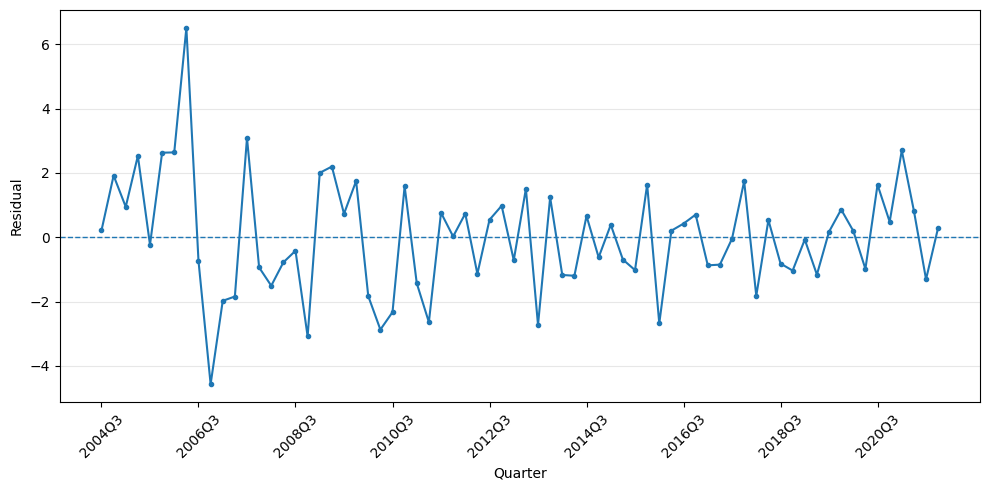

In [ ]:
# ============================================================
# STEP 19A: MODEL 1C — RESIDUALS OVER TIME
# ============================================================

import matplotlib.pyplot as plt

residuals = model1C_result.resid

plt.figure(figsize=(10, 5))

plt.plot(
    model1C_data["Quarter"],
    residuals,
    marker="o",
    markersize=3
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Quarter")
plt.ylabel("Residual")

# Show fewer x-axis labels
step = 8
plt.xticks(
    range(0, len(model1C_data), step),
    model1C_data["Quarter"].iloc[::step],
    rotation=45
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

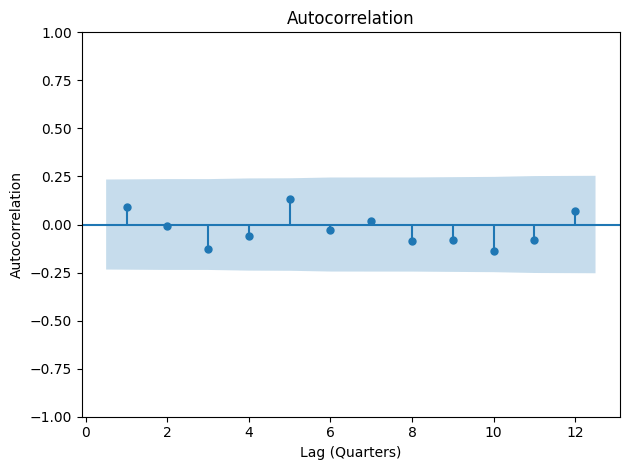

In [ ]:
# ============================================================
# STEP 19B: MODEL 1C — RESIDUAL AUTOCORRELATION
# ============================================================

from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(9, 5))

plot_acf(
    residuals,
    lags=12,
    zero=False
)

plt.xlabel("Lag (Quarters)")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 20A: TIME-BASED TRAIN / TEST VALIDATION
# MODEL 1C
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import statsmodels.api as sm

# Variables used in Model 1C
predictors = [
    "RPPI_Growth_L1",
    "Population_Growth_L3",
    "Completions_Growth_L2",
    "dln_Perth_Rent_Index",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

target = "dln_Perth_RPPI"

# Keep complete Model 1C observations
validation_data = model1C_data.copy().reset_index(drop=True)

# Chronological 80/20 split
split_index = int(len(validation_data) * 0.80)

train = validation_data.iloc[:split_index].copy()
test = validation_data.iloc[split_index:].copy()

print("Training period:",
      train["Quarter"].iloc[0], "to", train["Quarter"].iloc[-1])

print("Testing period:",
      test["Quarter"].iloc[0], "to", test["Quarter"].iloc[-1])

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training period: 2004Q3 to 2018Q2
Testing period: 2018Q3 to 2021Q4
Training observations: 56
Testing observations: 14


In [ ]:
# ============================================================
# STEP 20B: FIT ON TRAINING DATA AND PREDICT TEST PERIOD
# ============================================================

X_train = sm.add_constant(train[predictors], has_constant="add")
y_train = train[target]

X_test = sm.add_constant(test[predictors], has_constant="add")
y_test = test[target]

# Fit only on historical training observations
validation_model = sm.OLS(y_train, X_train).fit()

# One-step-ahead predictions for test period
test["Predicted_RPPI_Growth"] = validation_model.predict(X_test)

# Performance measures
mae = mean_absolute_error(
    y_test,
    test["Predicted_RPPI_Growth"]
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test["Predicted_RPPI_Growth"]
    )
)

print("MODEL 1C — OUT-OF-SAMPLE VALIDATION")
print("------------------------------------")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))

MODEL 1C — OUT-OF-SAMPLE VALIDATION
------------------------------------
MAE : 1.1477
RMSE: 1.3934


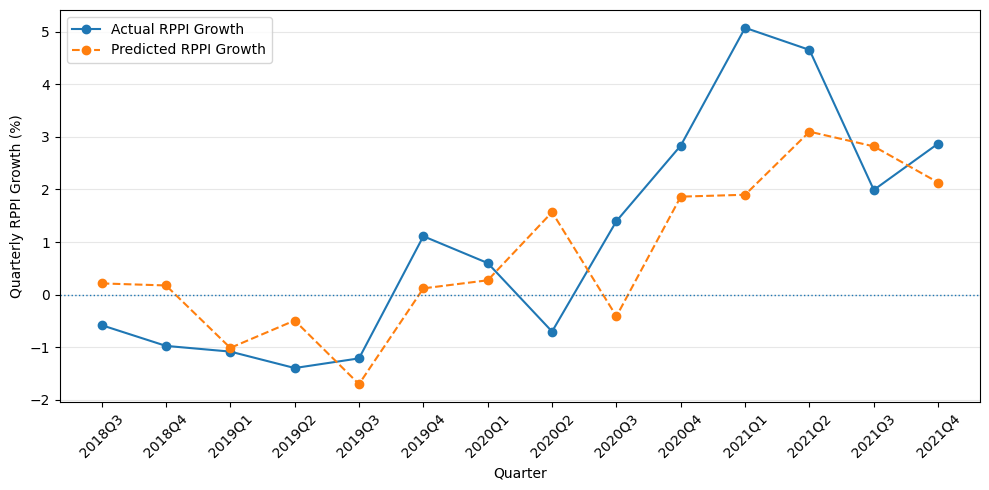

In [ ]:
# ============================================================
# STEP 20C: ACTUAL VS PREDICTED — TEST PERIOD
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    test["Quarter"],
    test[target],
    marker="o",
    label="Actual RPPI Growth"
)

plt.plot(
    test["Quarter"],
    test["Predicted_RPPI_Growth"],
    marker="o",
    linestyle="--",
    label="Predicted RPPI Growth"
)

plt.axhline(0, linestyle=":", linewidth=1)

plt.xlabel("Quarter")
plt.ylabel("Quarterly RPPI Growth (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 21: MODEL 1 — FINAL SUMMARY
# ============================================================

model1_summary = pd.DataFrame({
    "Measure": [
        "Final specification",
        "Historical sample",
        "Observations",
        "R-squared",
        "Adjusted R-squared",
        "Lagged RPPI coefficient",
        "Lagged RPPI robust p-value",
        "Durbin-Watson",
        "Breusch-Godfrey p-value",
        "Breusch-Pagan p-value",
        "Jarque-Bera p-value",
        "Maximum VIF",
        "Validation training period",
        "Validation testing period",
        "Test MAE",
        "Test RMSE"
    ],

    "Result": [
        "Dynamic Model 1C (HC3 robust inference)",
        "2004Q3–2021Q4",
        70,
        0.643,
        0.609,
        0.8066,
        "<0.001",
        1.813,
        0.7469,
        0.0258,
        0.0108,
        2.329,
        "2004Q3–2018Q2",
        "2018Q3–2021Q4",
        1.1477,
        1.3934
    ]
})

display(model1_summary)

,Measure,Result
0,Final specification,Dynamic Model 1C (HC3 robust inference)
1,Historical sample,2004Q3–2021Q4
2,Observations,70
3,R-squared,0.643
4,Adjusted R-squared,0.609
5,Lagged RPPI coefficient,0.8066
6,Lagged RPPI robust p-value,<0.001
7,Durbin-Watson,1.813
8,Breusch-Godfrey p-value,0.7469
9,Breusch-Pagan p-value,0.0258


#2nd Model

In [ ]:
# ==========================================
# WA HOUSING PROJECT — COLAB SETUP
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project folders
PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"
CLEAN_FOLDER = os.path.join(PROJECT_FOLDER, "Clean_Data")

# Master dataset
MASTER_FILE = os.path.join(
    CLEAN_FOLDER,
    "WA_Housing_Master_Full_1959Q1_2026Q2.csv"
)

# Load master dataset
master_df = pd.read_csv(MASTER_FILE)

print("Master dataset loaded successfully!")
print("Shape:", master_df.shape)
print("Period:", master_df["Quarter"].iloc[0],
      "to", master_df["Quarter"].iloc[-1])

print("\nColumns:")
print(master_df.columns.tolist())

Mounted at /content/drive
Master dataset loaded successfully!
Shape: (270, 17)
Period: 1959Q1 to 2026Q2

Columns:
['Quarter', 'WA_Population', 'WA_Natural_Increase', 'WA_NOM', 'WA_NIM', 'WA_Dwelling_Approvals', 'WA_Dwelling_Commencements', 'WA_Dwelling_Completions', 'WA_Dwellings_Under_Construction', 'Perth_RPPI', 'WA_Mean_Dwelling_Price_000', 'Perth_Rent_Index', 'Housing_Lending_Rate', 'WA_Unemployment_Rate', 'WA_Wage_Index', 'Perth_Construction_Cost_Index', 'WA_Dwelling_Stock_000']


In [ ]:
# ==========================================
# MODEL 2 — HOUSING SUPPLY MODEL
# STEP 1: Create model-specific dataset
# ==========================================

model2_vars = [
    "Quarter",
    "WA_Dwelling_Completions",          # Target
    "WA_Dwelling_Approvals",
    "WA_Dwelling_Commencements",
    "WA_Population",
    "WA_NOM",
    "WA_NIM",
    "Housing_Lending_Rate",
    "Perth_Construction_Cost_Index"
]

# Extract only Model 2 variables
model2_full = master_df[model2_vars].copy()

# Show availability of each variable
availability = pd.DataFrame({
    "Available": model2_full.notna().sum(),
    "Missing": model2_full.isna().sum()
})

display(availability)

# Find genuine common period where all Model 2 variables exist
model2 = model2_full.dropna().copy()

print("\nModel 2 common sample:")
print("Shape:", model2.shape)
print("Period:", model2["Quarter"].iloc[0],
      "to", model2["Quarter"].iloc[-1])

print("\nDuplicate quarters:", model2["Quarter"].duplicated().sum())
print("Remaining missing values:", model2.isna().sum().sum())

display(model2.head())
display(model2.tail())

,Available,Missing
Quarter,270,0
WA_Dwelling_Completions,99,171
WA_Dwelling_Approvals,172,98
WA_Dwelling_Commencements,99,171
WA_Population,179,91
WA_NOM,179,91
WA_NIM,179,91
Housing_Lending_Rate,270,0
Perth_Construction_Cost_Index,240,30



Model 2 common sample:
Shape: (98, 9)
Period: 2001Q3 to 2025Q4

Duplicate quarters: 0
Remaining missing values: 0


,Quarter,WA_Dwelling_Completions,WA_Dwelling_Approvals,WA_Dwelling_Commencements,WA_Population,WA_NOM,WA_NIM,Housing_Lending_Rate,Perth_Construction_Cost_Index
170,2001Q3,3787.0,5199.0,4992.0,1912214.0,3932.0,-627.0,6.736667,70.2
171,2001Q4,4360.0,5328.0,5172.0,1917752.0,4196.0,-1229.0,6.236667,70.2
172,2002Q1,3919.0,4484.0,4361.0,1924935.0,4947.0,-778.0,6.070000,70.2
173,2002Q2,4990.0,5397.0,4625.0,1928512.0,1895.0,-948.0,6.320000,71.3
174,2002Q3,3928.0,5689.0,5700.0,1932977.0,2951.0,-778.0,6.570000,71.9


,Quarter,WA_Dwelling_Completions,WA_Dwelling_Approvals,WA_Dwelling_Commencements,WA_Population,WA_NOM,WA_NIM,Housing_Lending_Rate,Perth_Construction_Cost_Index
263,2024Q4,6232.0,5467.0,5159.0,3011063.0,9074.0,3244.0,8.770000,155.4
264,2025Q1,4979.0,5530.0,5450.0,3032661.0,13899.0,2980.0,8.636667,155.9
265,2025Q2,5306.0,6149.0,5982.0,3046209.0,7125.0,2495.0,8.386667,154.8
266,2025Q3,5420.0,5893.0,6117.0,3063821.0,11634.0,2529.0,8.103333,156.0
267,2025Q4,4751.0,6520.0,6347.0,3076528.0,7764.0,2415.0,8.020000,156.4


In [ ]:
# ==========================================
# MODEL 2 — STEP 2
# Create transformations
# ==========================================

model2_work = model2.copy()

model2_work["Quarter_Period"] = pd.PeriodIndex(
    model2_work["Quarter"], freq="Q"
)

# Positive variables -> log growth (% approximately)
log_vars = [
    "WA_Dwelling_Completions",
    "WA_Dwelling_Approvals",
    "WA_Dwelling_Commencements",
    "WA_Population",
    "Perth_Construction_Cost_Index"
]

for var in log_vars:
    model2_work["ln_" + var] = np.log(model2_work[var])
    model2_work["dln_" + var] = model2_work["ln_" + var].diff() * 100

# Migration relative to population
model2_work["NOM_per_1000"] = (
    model2_work["WA_NOM"] /
    model2_work["WA_Population"] * 1000
)

model2_work["NIM_per_1000"] = (
    model2_work["WA_NIM"] /
    model2_work["WA_Population"] * 1000
)

# Quarterly change in lending rate
model2_work["d_Housing_Lending_Rate"] = (
    model2_work["Housing_Lending_Rate"].diff()
)

# Check transformed variables
check_vars = [
    "dln_WA_Dwelling_Completions",
    "dln_WA_Dwelling_Approvals",
    "dln_WA_Dwelling_Commencements",
    "dln_WA_Population",
    "NOM_per_1000",
    "NIM_per_1000",
    "d_Housing_Lending_Rate",
    "dln_Perth_Construction_Cost_Index"
]

summary = pd.DataFrame({
    "Min": model2_work[check_vars].min(),
    "Max": model2_work[check_vars].max(),
    "Mean": model2_work[check_vars].mean(),
    "Missing": model2_work[check_vars].isna().sum()
})

display(summary)

,Min,Max,Mean,Missing
dln_WA_Dwelling_Completions,-38.218659,43.214228,0.233795,1
dln_WA_Dwelling_Approvals,-29.922790,52.702877,0.233410,1
dln_WA_Dwelling_Commencements,-43.337311,55.596293,0.247573,1
dln_WA_Population,0.057607,1.014550,0.490247,1
NOM_per_1000,-0.851838,7.319212,2.790324,0
NIM_per_1000,-1.427845,1.585830,0.288125,0
d_Housing_Lending_Rate,-1.896667,1.416667,0.013230,1
dln_Perth_Construction_Cost_Index,-0.782018,4.713116,0.825844,1


In [ ]:
# ==========================================
# MODEL 2 — STEP 3
# Explore supply-pipeline lags
# ==========================================

target = "dln_WA_Dwelling_Completions"

lag_results = []

for lag in range(0, 9):

    # Earlier approvals
    approval_lag = model2_work[
        "dln_WA_Dwelling_Approvals"
    ].shift(lag)

    corr_approval = model2_work[target].corr(approval_lag)

    n_approval = pd.concat(
        [model2_work[target], approval_lag], axis=1
    ).dropna().shape[0]

    # Earlier commencements
    commencement_lag = model2_work[
        "dln_WA_Dwelling_Commencements"
    ].shift(lag)

    corr_commencement = model2_work[target].corr(
        commencement_lag
    )

    n_commencement = pd.concat(
        [model2_work[target], commencement_lag], axis=1
    ).dropna().shape[0]

    lag_results.append([
        lag,
        corr_approval,
        n_approval,
        corr_commencement,
        n_commencement
    ])

lag_table = pd.DataFrame(
    lag_results,
    columns=[
        "Lag_Quarters",
        "Approvals_Correlation",
        "Approvals_N",
        "Commencements_Correlation",
        "Commencements_N"
    ]
)

display(lag_table.round(3))

# Show strongest absolute correlations
best_approval = lag_table.loc[
    lag_table["Approvals_Correlation"].abs().idxmax()
]

best_commencement = lag_table.loc[
    lag_table["Commencements_Correlation"].abs().idxmax()
]

print("\nStrongest approval relationship:")
print(best_approval)

print("\nStrongest commencement relationship:")
print(best_commencement)

,Lag_Quarters,Approvals_Correlation,Approvals_N,Commencements_Correlation,Commencements_N
0,0,0.201,97,0.090,97
1,1,-0.126,96,-0.080,96
2,2,0.143,95,0.074,95
3,3,-0.165,94,-0.018,94
4,4,0.330,93,0.134,93
5,5,-0.136,92,-0.010,92
6,6,0.036,91,-0.097,91
7,7,-0.193,90,0.017,90
8,8,0.263,89,0.136,89



Strongest approval relationship:
Lag_Quarters                  4.000000
Approvals_Correlation         0.330456
Approvals_N                  93.000000
Commencements_Correlation     0.133718
Commencements_N              93.000000
Name: 4, dtype: float64

Strongest commencement relationship:
Lag_Quarters                  8.000000
Approvals_Correlation         0.263276
Approvals_N                  89.000000
Commencements_Correlation     0.136280
Commencements_N              89.000000
Name: 8, dtype: float64


In [ ]:
# ==========================================
# MODEL 2 — STEP 4
# Check persistence in dwelling completions
# ==========================================

persistence_results = []

for lag in range(1, 9):

    lagged_completions = model2_work[
        "dln_WA_Dwelling_Completions"
    ].shift(lag)

    corr = model2_work[
        "dln_WA_Dwelling_Completions"
    ].corr(lagged_completions)

    n = pd.concat([
        model2_work["dln_WA_Dwelling_Completions"],
        lagged_completions
    ], axis=1).dropna().shape[0]

    persistence_results.append([lag, corr, n])

persistence_table = pd.DataFrame(
    persistence_results,
    columns=["Lag_Quarters", "Correlation", "N"]
)

display(persistence_table.round(3))

,Lag_Quarters,Correlation,N
0,1,-0.606,96
1,2,0.353,95
2,3,-0.391,94
3,4,0.471,93
4,5,-0.327,92
5,6,0.270,91
6,7,-0.347,90
7,8,0.455,89


In [ ]:
# ==========================================
# MODEL 2A — BASELINE LAGGED SUPPLY MODEL
# ==========================================

import statsmodels.api as sm

# Create 4-quarter lag of approvals growth
model2_work["Approvals_Growth_L4"] = (
    model2_work["dln_WA_Dwelling_Approvals"].shift(4)
)

# Baseline predictors
model2A_predictors = [
    "Approvals_Growth_L4",
    "dln_WA_Population",
    "NOM_per_1000",
    "NIM_per_1000",
    "d_Housing_Lending_Rate",
    "dln_Perth_Construction_Cost_Index"
]

# Prepare regression dataset
model2A_data = model2_work[
    ["Quarter", "dln_WA_Dwelling_Completions"] +
    model2A_predictors
].dropna().copy()

X = model2A_data[model2A_predictors]
X = sm.add_constant(X)

y = model2A_data["dln_WA_Dwelling_Completions"]

model2A_result = sm.OLS(y, X).fit()

print("MODEL 2A — Baseline Lagged Supply Model")
print("Period:",
      model2A_data["Quarter"].iloc[0],
      "to",
      model2A_data["Quarter"].iloc[-1])
print("Observations:", len(model2A_data))

print(model2A_result.summary())

MODEL 2A — Baseline Lagged Supply Model
Period: 2002Q4 to 2025Q4
Observations: 93
                                 OLS Regression Results                                
Dep. Variable:     dln_WA_Dwelling_Completions   R-squared:                       0.147
Model:                                     OLS   Adj. R-squared:                  0.088
Method:                          Least Squares   F-statistic:                     2.479
Date:                         Sun, 27 Sep 2026   Prob (F-statistic):             0.0293
Time:                                 13:37:00   Log-Likelihood:                -397.87
No. Observations:                           93   AIC:                             809.7
Df Residuals:                               86   BIC:                             827.5
Df Model:                                    6                                         
Covariance Type:                     nonrobust                                         
                                      

In [ ]:
# ==========================================
# MODEL 2B — DYNAMIC HOUSING SUPPLY MODEL
# ==========================================

# Previous-quarter completions growth
model2_work["Completions_Growth_L1"] = (
    model2_work["dln_WA_Dwelling_Completions"].shift(1)
)

model2B_predictors = [
    "Completions_Growth_L1",
    "Approvals_Growth_L4",
    "dln_WA_Population",
    "NOM_per_1000",
    "NIM_per_1000",
    "d_Housing_Lending_Rate",
    "dln_Perth_Construction_Cost_Index"
]

model2B_data = model2_work[
    ["Quarter", "dln_WA_Dwelling_Completions"] +
    model2B_predictors
].dropna().copy()

X2B = sm.add_constant(
    model2B_data[model2B_predictors]
)

y2B = model2B_data[
    "dln_WA_Dwelling_Completions"
]

model2B_result = sm.OLS(y2B, X2B).fit()

print("MODEL 2B — Dynamic Housing Supply Model")
print(
    "Period:",
    model2B_data["Quarter"].iloc[0],
    "to",
    model2B_data["Quarter"].iloc[-1]
)
print("Observations:", len(model2B_data))

print(model2B_result.summary())

MODEL 2B — Dynamic Housing Supply Model
Period: 2002Q4 to 2025Q4
Observations: 93
                                 OLS Regression Results                                
Dep. Variable:     dln_WA_Dwelling_Completions   R-squared:                       0.454
Model:                                     OLS   Adj. R-squared:                  0.409
Method:                          Least Squares   F-statistic:                     10.09
Date:                         Sun, 27 Sep 2026   Prob (F-statistic):           3.98e-09
Time:                                 13:37:52   Log-Likelihood:                -377.16
No. Observations:                           93   AIC:                             770.3
Df Residuals:                               85   BIC:                             790.6
Df Model:                                    7                                         
Covariance Type:                     nonrobust                                         
                                      

In [ ]:
# ==========================================
# MODEL 2 — STEP 7
# Predictor correlation and VIF
# ==========================================

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Correlation matrix
corr2B = model2B_data[model2B_predictors].corr()

print("Predictor Correlations:")
display(corr2B.round(3))

# VIF
X_vif = model2B_data[model2B_predictors].copy()

vif_table = pd.DataFrame()
vif_table["Variable"] = X_vif.columns
vif_table["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print("\nVariance Inflation Factors:")
display(vif_table.sort_values("VIF", ascending=False).round(3))

Predictor Correlations:


,Completions_Growth_L1,Approvals_Growth_L4,dln_WA_Population,NOM_per_1000,NIM_per_1000,d_Housing_Lending_Rate,dln_Perth_Construction_Cost_Index
Completions_Growth_L1,1.000,-0.164,0.174,0.217,0.088,0.025,0.061
Approvals_Growth_L4,-0.164,1.000,-0.251,-0.272,0.047,-0.176,0.091
dln_WA_Population,0.174,-0.251,1.000,0.942,0.667,0.096,0.184
NOM_per_1000,0.217,-0.272,0.942,1.000,0.506,0.077,0.117
NIM_per_1000,0.088,0.047,0.667,0.506,1.000,0.168,0.363
d_Housing_Lending_Rate,0.025,-0.176,0.096,0.077,0.168,1.000,0.184
dln_Perth_Construction_Cost_Index,0.061,0.091,0.184,0.117,0.363,0.184,1.000



Variance Inflation Factors:


,Variable,VIF
2,dln_WA_Population,16.709
3,NOM_per_1000,12.214
4,NIM_per_1000,2.853
1,Approvals_Growth_L4,1.262
6,dln_Perth_Construction_Cost_Index,1.193
5,d_Housing_Lending_Rate,1.104
0,Completions_Growth_L1,1.083


In [ ]:
# ==========================================
# MODEL 2 — STEP 8
# Compare Population vs Migration versions
# ==========================================

# MODEL 2C — Population version
predictors_2C = [
    "Completions_Growth_L1",
    "Approvals_Growth_L4",
    "dln_WA_Population",
    "d_Housing_Lending_Rate",
    "dln_Perth_Construction_Cost_Index"
]

data_2C = model2_work[
    ["Quarter", "dln_WA_Dwelling_Completions"] + predictors_2C
].dropna().copy()

X2C = sm.add_constant(data_2C[predictors_2C])
y2C = data_2C["dln_WA_Dwelling_Completions"]

result_2C = sm.OLS(y2C, X2C).fit()


# MODEL 2D — Migration version
predictors_2D = [
    "Completions_Growth_L1",
    "Approvals_Growth_L4",
    "NOM_per_1000",
    "NIM_per_1000",
    "d_Housing_Lending_Rate",
    "dln_Perth_Construction_Cost_Index"
]

data_2D = model2_work[
    ["Quarter", "dln_WA_Dwelling_Completions"] + predictors_2D
].dropna().copy()

X2D = sm.add_constant(data_2D[predictors_2D])
y2D = data_2D["dln_WA_Dwelling_Completions"]

result_2D = sm.OLS(y2D, X2D).fit()


# Comparison table
comparison = pd.DataFrame({
    "Model": [
        "2B - Population + Migration",
        "2C - Population",
        "2D - Migration"
    ],
    "R2": [
        model2B_result.rsquared,
        result_2C.rsquared,
        result_2D.rsquared
    ],
    "Adjusted_R2": [
        model2B_result.rsquared_adj,
        result_2C.rsquared_adj,
        result_2D.rsquared_adj
    ],
    "AIC": [
        model2B_result.aic,
        result_2C.aic,
        result_2D.aic
    ],
    "BIC": [
        model2B_result.bic,
        result_2C.bic,
        result_2D.bic
    ],
    "Durbin_Watson": [
        sm.stats.stattools.durbin_watson(model2B_result.resid),
        sm.stats.stattools.durbin_watson(result_2C.resid),
        sm.stats.stattools.durbin_watson(result_2D.resid)
    ]
})

display(comparison.round(3))

print("\nMODEL 2C — POPULATION VERSION")
print(result_2C.summary())

print("\nMODEL 2D — MIGRATION VERSION")
print(result_2D.summary())

,Model,R2,Adjusted_R2,AIC,BIC,Durbin_Watson
0,2B - Population + Migration,0.454,0.409,770.320,790.580,2.042
1,2C - Population,0.417,0.384,772.375,787.571,2.028
2,2D - Migration,0.421,0.381,773.768,791.496,2.046



MODEL 2C — POPULATION VERSION
                                 OLS Regression Results                                
Dep. Variable:     dln_WA_Dwelling_Completions   R-squared:                       0.417
Model:                                     OLS   Adj. R-squared:                  0.384
Method:                          Least Squares   F-statistic:                     12.45
Date:                         Sun, 27 Sep 2026   Prob (F-statistic):           4.03e-09
Time:                                 13:39:45   Log-Likelihood:                -380.19
No. Observations:                           93   AIC:                             772.4
Df Residuals:                               87   BIC:                             787.6
Df Model:                                    5                                         
Covariance Type:                     nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025

In [ ]:
# ==========================================
# MODEL 2 — STEP 9
# Diagnostics for Model 2C
# ==========================================

from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey,
    het_breuschpagan
)
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Breusch-Godfrey: residual serial correlation
bg = acorr_breusch_godfrey(result_2C, nlags=4)

# Breusch-Pagan: heteroskedasticity
bp = het_breuschpagan(
    result_2C.resid,
    result_2C.model.exog
)

# Jarque-Bera: residual normality
jb = jarque_bera(result_2C.resid)

print("MODEL 2C DIAGNOSTICS")
print("---------------------")
print(f"Durbin-Watson: {sm.stats.stattools.durbin_watson(result_2C.resid):.4f}")
print(f"Breusch-Godfrey p-value: {bg[1]:.4f}")
print(f"Breusch-Pagan p-value: {bp[1]:.4f}")
print(f"Jarque-Bera p-value: {jb[1]:.4f}")

# VIF for final candidate predictors
X_vif_2C = data_2C[predictors_2C]

vif_2C = pd.DataFrame({
    "Variable": predictors_2C,
    "VIF": [
        variance_inflation_factor(X_vif_2C.values, i)
        for i in range(len(predictors_2C))
    ]
})

print("\nVIF:")
display(vif_2C.round(3))

MODEL 2C DIAGNOSTICS
---------------------
Durbin-Watson: 2.0283
Breusch-Godfrey p-value: 0.1080
Breusch-Pagan p-value: 0.4342
Jarque-Bera p-value: 0.4693

VIF:


/tmp/ipykernel_2421/2922692865.py:14: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg = acorr_breusch_godfrey(result_2C, nlags=4)


,Variable,VIF
0,Completions_Growth_L1,1.051
1,Approvals_Growth_L4,1.150
2,dln_WA_Population,1.137
3,d_Housing_Lending_Rate,1.077
4,dln_Perth_Construction_Cost_Index,1.103


MODEL 2C — TIME-BASED VALIDATION
--------------------------------
Training period: 2002Q4 to 2021Q1
Testing period: 2021Q2 to 2025Q4
Training observations: 74
Testing observations: 19

Test MAE: 19.4956 percentage points
Test RMSE: 23.5690 percentage points


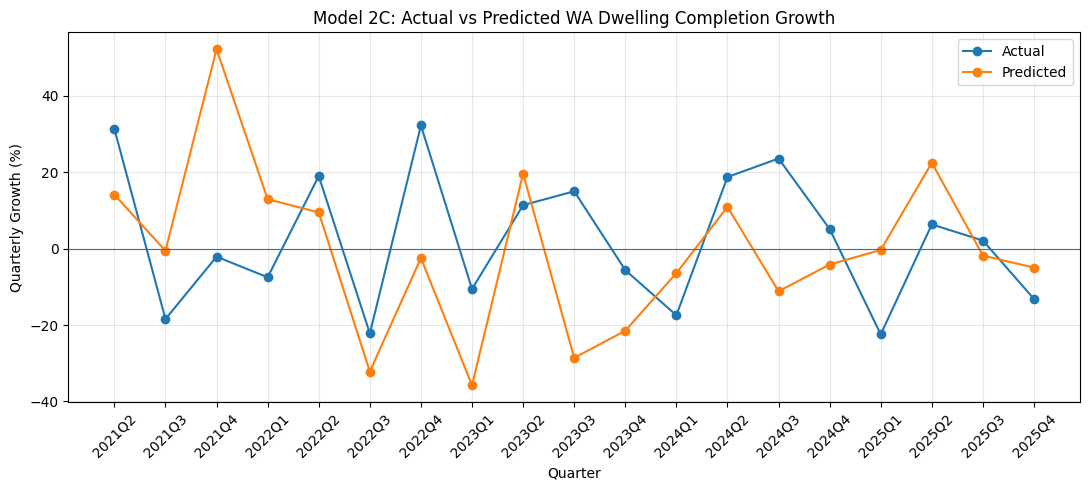

In [ ]:
# ==========================================
# MODEL 2 — STEP 10
# Chronological train/test validation
# ==========================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Keep chronological order
validation_data = data_2C.copy().reset_index(drop=True)

# 80/20 chronological split
split_index = int(len(validation_data) * 0.80)

train = validation_data.iloc[:split_index].copy()
test = validation_data.iloc[split_index:].copy()

# Training data
X_train = sm.add_constant(
    train[predictors_2C],
    has_constant="add"
)

y_train = train["dln_WA_Dwelling_Completions"]

# Test data
X_test = sm.add_constant(
    test[predictors_2C],
    has_constant="add"
)

y_test = test["dln_WA_Dwelling_Completions"]

# Fit using training period only
model2_validation = sm.OLS(
    y_train,
    X_train
).fit()

# Predict test period
predictions = model2_validation.predict(X_test)

# Accuracy metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("MODEL 2C — TIME-BASED VALIDATION")
print("--------------------------------")
print("Training period:",
      train["Quarter"].iloc[0],
      "to",
      train["Quarter"].iloc[-1])

print("Testing period:",
      test["Quarter"].iloc[0],
      "to",
      test["Quarter"].iloc[-1])

print("Training observations:", len(train))
print("Testing observations:", len(test))

print(f"\nTest MAE: {mae:.4f} percentage points")
print(f"Test RMSE: {rmse:.4f} percentage points")


# ==========================================
# ACTUAL VS PREDICTED GRAPH
# ==========================================

plt.figure(figsize=(11, 5))

plt.plot(
    test["Quarter"],
    y_test,
    marker="o",
    label="Actual"
)

plt.plot(
    test["Quarter"],
    predictions,
    marker="o",
    label="Predicted"
)

plt.axhline(0, linewidth=0.8)

plt.title(
    "Model 2C: Actual vs Predicted WA Dwelling Completion Growth"
)
plt.xlabel("Quarter")
plt.ylabel("Quarterly Growth (%)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

Completion Growth by Calendar Quarter:


,count,mean,median,std
Quarter_Number,,,,
1,24,-16.801,-14.173,11.321
2,24,19.695,18.900,12.615
3,24,-7.330,-6.225,14.609
4,25,5.165,3.657,14.613


<Figure size 800x500 with 0 Axes>

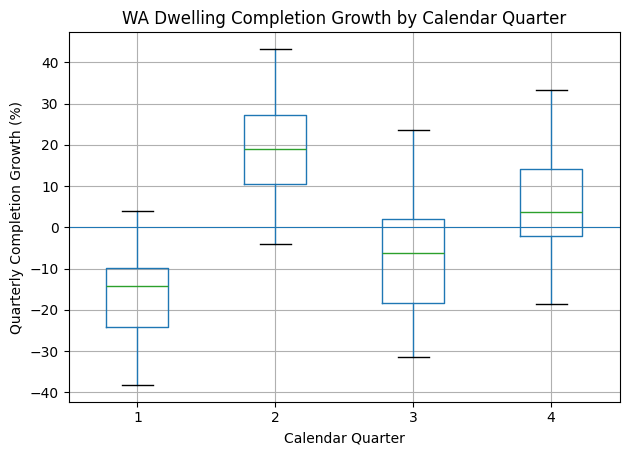

In [ ]:
# ==========================================
# MODEL 2 — STEP 11
# Check quarterly seasonality
# ==========================================

# Extract quarter number
model2_work["Quarter_Number"] = (
    model2_work["Quarter_Period"].dt.quarter
)

seasonality = model2_work.groupby(
    "Quarter_Number"
)["dln_WA_Dwelling_Completions"].agg(
    ["count", "mean", "median", "std"]
)

print("Completion Growth by Calendar Quarter:")
display(seasonality.round(3))

# Boxplot
plt.figure(figsize=(8, 5))

model2_work.boxplot(
    column="dln_WA_Dwelling_Completions",
    by="Quarter_Number"
)

plt.title("WA Dwelling Completion Growth by Calendar Quarter")
plt.suptitle("")
plt.xlabel("Calendar Quarter")
plt.ylabel("Quarterly Completion Growth (%)")
plt.axhline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# MODEL 2E — DYNAMIC + SEASONAL SUPPLY MODEL
# ==========================================

# Create seasonal dummy variables
quarter_dummies = pd.get_dummies(
    model2_work["Quarter_Number"],
    prefix="Q",
    drop_first=True,
    dtype=int
)

model2_work = pd.concat(
    [model2_work, quarter_dummies],
    axis=1
)

predictors_2E = [
    "Completions_Growth_L1",
    "Approvals_Growth_L4",
    "dln_WA_Population",
    "d_Housing_Lending_Rate",
    "dln_Perth_Construction_Cost_Index",
    "Q_2",
    "Q_3",
    "Q_4"
]

data_2E = model2_work[
    ["Quarter", "dln_WA_Dwelling_Completions"] +
    predictors_2E
].dropna().copy()

X2E = sm.add_constant(data_2E[predictors_2E])
y2E = data_2E["dln_WA_Dwelling_Completions"]

result_2E = sm.OLS(y2E, X2E).fit()

print("MODEL 2E — DYNAMIC + SEASONAL SUPPLY MODEL")
print(
    "Period:",
    data_2E["Quarter"].iloc[0],
    "to",
    data_2E["Quarter"].iloc[-1]
)
print("Observations:", len(data_2E))

print(result_2E.summary())


# Compare with Model 2C
comparison_2E = pd.DataFrame({
    "Model": [
        "2C - Dynamic",
        "2E - Dynamic + Seasonality"
    ],
    "R2": [
        result_2C.rsquared,
        result_2E.rsquared
    ],
    "Adjusted_R2": [
        result_2C.rsquared_adj,
        result_2E.rsquared_adj
    ],
    "AIC": [
        result_2C.aic,
        result_2E.aic
    ],
    "BIC": [
        result_2C.bic,
        result_2E.bic
    ],
    "Durbin_Watson": [
        sm.stats.stattools.durbin_watson(result_2C.resid),
        sm.stats.stattools.durbin_watson(result_2E.resid)
    ]
})

print("\nMODEL COMPARISON")
display(comparison_2E.round(3))

MODEL 2E — DYNAMIC + SEASONAL SUPPLY MODEL
Period: 2002Q4 to 2025Q4
Observations: 93
                                 OLS Regression Results                                
Dep. Variable:     dln_WA_Dwelling_Completions   R-squared:                       0.594
Model:                                     OLS   Adj. R-squared:                  0.556
Method:                          Least Squares   F-statistic:                     15.39
Date:                         Sun, 27 Sep 2026   Prob (F-statistic):           1.09e-13
Time:                                 13:45:13   Log-Likelihood:                -363.33
No. Observations:                           93   AIC:                             744.7
Df Residuals:                               84   BIC:                             767.5
Df Model:                                    8                                         
Covariance Type:                     nonrobust                                         
                                   

,Model,R2,Adjusted_R2,AIC,BIC,Durbin_Watson
0,2C - Dynamic,0.417,0.384,772.375,787.571,2.028
1,2E - Dynamic + Seasonality,0.594,0.556,744.662,767.455,1.992


/tmp/ipykernel_2421/2270038593.py:11: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_2E = acorr_breusch_godfrey(


MODEL 2E DIAGNOSTICS
--------------------
Durbin-Watson: 1.9922
Breusch-Godfrey p-value: 0.7326
Breusch-Pagan p-value: 0.8445
Jarque-Bera p-value: 0.7604

MODEL 2E — TIME-BASED VALIDATION
--------------------------------
Training: 2002Q4 to 2021Q1
Testing: 2021Q2 to 2025Q4
Test MAE: 14.1109 percentage points
Test RMSE: 18.3271 percentage points


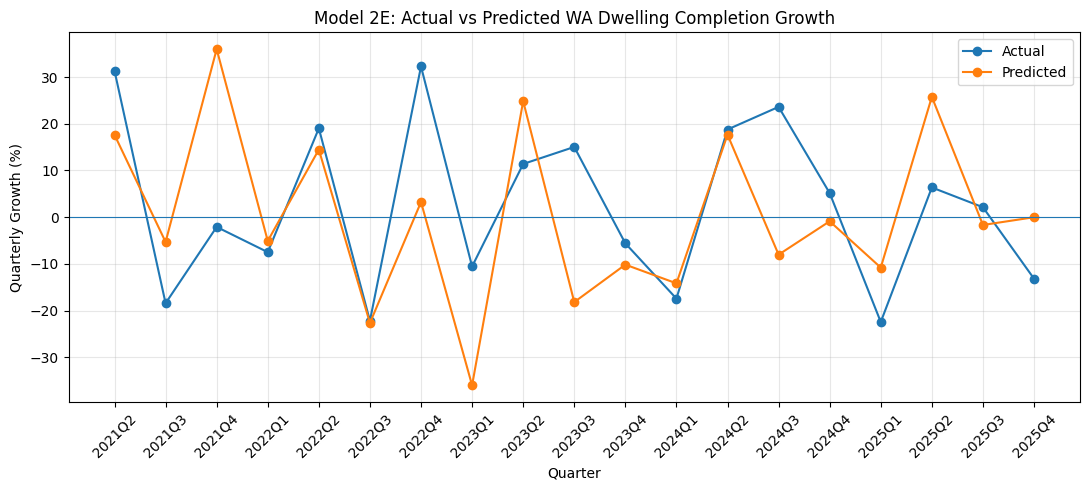

In [ ]:
# ==========================================
# MODEL 2E — DIAGNOSTICS
# ==========================================

from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey,
    het_breuschpagan
)
from statsmodels.stats.stattools import jarque_bera

bg_2E = acorr_breusch_godfrey(
    result_2E, nlags=4, store=False
)

bp_2E = het_breuschpagan(
    result_2E.resid,
    result_2E.model.exog
)

jb_2E = jarque_bera(result_2E.resid)

print("MODEL 2E DIAGNOSTICS")
print("--------------------")
print(f"Durbin-Watson: {sm.stats.stattools.durbin_watson(result_2E.resid):.4f}")
print(f"Breusch-Godfrey p-value: {bg_2E[1]:.4f}")
print(f"Breusch-Pagan p-value: {bp_2E[1]:.4f}")
print(f"Jarque-Bera p-value: {jb_2E[1]:.4f}")


# ==========================================
# MODEL 2E — TIME-BASED VALIDATION
# ==========================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

validation_2E = data_2E.copy().reset_index(drop=True)

split_index = int(len(validation_2E) * 0.80)

train_2E = validation_2E.iloc[:split_index].copy()
test_2E = validation_2E.iloc[split_index:].copy()

X_train_2E = sm.add_constant(
    train_2E[predictors_2E],
    has_constant="add"
)

X_test_2E = sm.add_constant(
    test_2E[predictors_2E],
    has_constant="add"
)

y_train_2E = train_2E["dln_WA_Dwelling_Completions"]
y_test_2E = test_2E["dln_WA_Dwelling_Completions"]

validation_model_2E = sm.OLS(
    y_train_2E,
    X_train_2E
).fit()

pred_2E = validation_model_2E.predict(X_test_2E)

mae_2E = mean_absolute_error(y_test_2E, pred_2E)
rmse_2E = np.sqrt(mean_squared_error(y_test_2E, pred_2E))

print("\nMODEL 2E — TIME-BASED VALIDATION")
print("--------------------------------")
print("Training:",
      train_2E["Quarter"].iloc[0],
      "to",
      train_2E["Quarter"].iloc[-1])

print("Testing:",
      test_2E["Quarter"].iloc[0],
      "to",
      test_2E["Quarter"].iloc[-1])

print(f"Test MAE: {mae_2E:.4f} percentage points")
print(f"Test RMSE: {rmse_2E:.4f} percentage points")


# Graph
plt.figure(figsize=(11,5))

plt.plot(
    test_2E["Quarter"],
    y_test_2E,
    marker="o",
    label="Actual"
)

plt.plot(
    test_2E["Quarter"],
    pred_2E,
    marker="o",
    label="Predicted"
)

plt.axhline(0, linewidth=0.8)

plt.title(
    "Model 2E: Actual vs Predicted WA Dwelling Completion Growth"
)
plt.xlabel("Quarter")
plt.ylabel("Quarterly Growth (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
DATA_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Datasets"
)

In [ ]:
import os

raw_file = os.path.join(
    DATA_FOLDER,
    "ABS_Building_Activity.xlsb"
)

print("File:", raw_file)
print("Exists:", os.path.exists(raw_file))

File: /content/drive/MyDrive/WA_Housing_Project/Datasets/ABS_Building_Activity.xlsb
Exists: True


In [ ]:
!pip -q install pyxlsb

In [ ]:
import pandas as pd
import os

DATA_FOLDER = os.path.join(PROJECT_FOLDER, "Datasets")

raw_file = os.path.join(
    DATA_FOLDER,
    "ABS_Building_Activity.xlsb"
)

print("File exists:", os.path.exists(raw_file))

xls = pd.ExcelFile(raw_file, engine="pyxlsb")

print("\nSheet names:")
for i, sheet in enumerate(xls.sheet_names):
    print(i, sheet)

File exists: True

Sheet names:
0 Sheet1
1 87520_activity


In [ ]:
# Read only the first 25 rows without treating any row as a header
activity_preview = pd.read_excel(
    raw_file,
    sheet_name="87520_activity",
    engine="pyxlsb",
    header=None,
    nrows=25
)

# Show all columns/rows clearly
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

display(activity_preview)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
0,Type of Building,Type of Work,Reference Quarter,Sector of Ownership,State/Territory,Value of work done during quarter ($ Millions),Value of work done during quarter - Annotation,Value of work yet to be done ($ Millions),Value of work yet to be done - Annotation,Value of work in the pipeline ($ Millions),Value of work in the pipeline - Annotation,Value of work not yet commenced ($ Millions),Value of work not yet commenced - Annotation,Value of work commenced ($ Millions),Value of work commenced - Annotation,Value of work completed ($ Millions),Value of work completed - Annotation,Value of work under construction ($ Millions),Value of work under construction - Annotation,Dwelling units not yet commenced (Number),Dwelling units not yet commenced - Annotation,Dwelling units commenced (Number),Dwelling units commenced - Annotation,Dwelling units completed (Number),Dwelling units completed - Annotation,Dwelling units under construction (Number),Dwelling units under construction - Annotation
1,Houses,New,37135,Private Sector,Australia,3505.079,NaN,3161.985,NaN,4842.626,NaN,1680.641,NaN,3990.954,NaN,3108.172,NaN,6546.636,NaN,10796,NaN,27124,NaN,20630,NaN,40549,NaN
2,Houses,New,37135,Private Sector,New South Wales,888.121,NaN,897.386,NaN,1698.217,NaN,800.831,NaN,940.798,NaN,810.764,NaN,1848.516,NaN,4579,NaN,5766,NaN,4611,NaN,10228,NaN
3,Houses,New,37135,Private Sector,Victoria,1133.657,NaN,1159.126,NaN,1576.68,NaN,417.554,NaN,1289.453,NaN,1022.292,NaN,2371.206,NaN,2647,NaN,8188,NaN,6622,NaN,14466,NaN
4,Houses,New,37135,Private Sector,Queensland,749.807,NaN,420.422,NaN,521.771,NaN,101.349,^,912.378,NaN,614.415,NaN,919.502,NaN,762,^,6537,NaN,4456,NaN,6180,NaN
5,Houses,New,37135,Private Sector,South Australia,184.808,NaN,169.843,NaN,283.876,NaN,114.033,NaN,221.001,NaN,150.271,NaN,345.427,NaN,954,NaN,1841,NaN,1296,NaN,2609,NaN
6,Houses,New,37135,Private Sector,Western Australia,441.485,NaN,432.5,NaN,650.83,NaN,218.33,NaN,521.927,NaN,412.168,NaN,873.617,NaN,1607,NaN,4016,NaN,2954,NaN,5651,NaN
7,Houses,New,37135,Private Sector,Tasmania,36.615,NaN,39.535,NaN,59.03,NaN,19.495,NaN,37.008,NaN,33.45,NaN,87.641,NaN,191,NaN,316,NaN,276,NaN,816,NaN
8,Houses,New,37135,Private Sector,Northern Territory,26.585,NaN,14.382,NaN,20.56,NaN,6.177,NaN,25.132,NaN,24.776,NaN,33.536,NaN,36,NaN,178,NaN,158,NaN,231,NaN
9,Houses,New,37135,Private Sector,Australian Capital Territory,44.002,NaN,28.79,NaN,31.662,NaN,2.872,^,43.258,NaN,40.037,NaN,67.191,NaN,19,^,282,NaN,255,NaN,369,NaN


In [ ]:
# Inspect Sheet1 for ABS metadata / notes

sheet1_preview = pd.read_excel(
    raw_file,
    sheet_name="Sheet1",
    engine="pyxlsb",
    header=None,
    nrows=100
)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

display(sheet1_preview)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38
0,NaN,NaN,NaN,NaN,NaN,Type of Building,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Type of Work,Reference Quarter,Sector of Ownership,State/Territory,Data,Aged care facilities,Agricultural and aquacultural buildings,Apartments - In a four or more storey block,Apartments - In a four to eight storey block,Apartments - In a nine or more storey block,Apartments - In a one or two storey block,Apartments - In a three storey block,Apartments - Total including those attached to a house,Commercial Buildings - Total,Commercial buildings n.e.c.,Dwellings excluding houses,Dwellings excluding new residential (b),Education buildings,Entertainment and recreation buildings,Factories and other secondary production buildings,Health buildings,Houses,Industrial Buildings - Total,Offices,Other industrial buildings n.e.c.,Other Non-residential - Total,Other non-residential n.e.c.,Religion buildings,Retail and wholesale trade buildings,"Semi-detached, row or terrace houses, townhouses - One storey","Semi-detached, row or terrace houses, townhouses - Total","Semi-detached, row or terrace houses, townhouses - Two or more storeys",Short term accommodation buildings,Total,Total Non-residential,Total Other Residential,Total Residential (a),Transport buildings,Warehouses
2,Alterations and additions including conversions,37135,Private Sector,Australia,Value of work done during quarter ($ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,942.217,NaN,NaN
3,NaN,NaN,NaN,NaN,Value of work yet to be done ($ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,826.934,NaN,NaN
4,NaN,NaN,NaN,NaN,Value of work in the pipeline ($ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1461.842,NaN,NaN
5,NaN,NaN,NaN,NaN,Value of work not yet commenced ($ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,634.908,NaN,NaN
6,NaN,NaN,NaN,NaN,Value of work commenced ($ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,975.745,NaN,NaN
7,NaN,NaN,NaN,NaN,Value of work completed ($ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,821.346,NaN,NaN
8,NaN,NaN,NaN,NaN,Value of work under construction ($ Millions),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1937.339,NaN,NaN
9,NaN,NaN,NaN,NaN,Dwelling units not yet commenced (Number),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,524,NaN,NaN


#Model 3

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"
CLEAN_FOLDER = os.path.join(PROJECT_FOLDER, "Clean_Data")

print("Project exists:", os.path.exists(PROJECT_FOLDER))
print("Clean_Data exists:", os.path.exists(CLEAN_FOLDER))

print("\nFiles:")
print(os.listdir(CLEAN_FOLDER))

Project exists: True
Clean_Data exists: True

Files:
['01_WA_Population_Clean.csv', '02_WA_Population_Components_Clean.csv', '03_WA_Dwelling_Approvals_Clean.csv', '04_WA_Building_Activity_Clean.csv', '05_WA_Dwelling_Price_Clean.csv', '06_Perth_Rent_Index_Clean.csv', '07_Housing_Lending_Rate_Clean.csv', '08_WA_Unemployment_Rate_Clean.csv', '09_WA_Wage_Index_Clean.csv', '10_Perth_Construction_Cost_Index_Clean.csv', '05B_Perth_Historical_RPPI_Clean.csv', '11_WA_Dwelling_Stock_Clean.csv', 'WA_Housing_Master_Full_1959Q1_2026Q2.csv', 'WA_Housing_Core_Model_2003Q3_2021Q4.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

MASTER_FILE = os.path.join(
    CLEAN_FOLDER,
    "WA_Housing_Master_Full_1959Q1_2026Q2.csv"
)

master_df = pd.read_csv(MASTER_FILE)

print("Shape:", master_df.shape)
print("Period:", master_df["Quarter"].iloc[0],
      "to", master_df["Quarter"].iloc[-1])

Shape: (270, 17)
Period: 1959Q1 to 2026Q2


In [ ]:
# ============================================================
# MODEL 3 — RESTORE WORKING DATASET AFTER COLAB DISCONNECTION
# ============================================================

# Select Model 3 variables
model3_vars = [
    "Quarter",
    "WA_Dwelling_Approvals",
    "WA_Population",
    "WA_NOM",
    "WA_NIM",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate",
    "Perth_Construction_Cost_Index"
]

# Create common sample
model3 = master_df[model3_vars].dropna().copy()

# Create quarterly time variable
model3["Quarter_Period"] = pd.PeriodIndex(
    model3["Quarter"],
    freq="Q"
)

# Working dataframe
model3_work = model3.copy()

# Log-growth variables
log_vars = [
    "WA_Dwelling_Approvals",
    "WA_Population",
    "Perth_Construction_Cost_Index"
]

for var in log_vars:
    model3_work["ln_" + var] = np.log(model3_work[var])

    model3_work["dln_" + var] = (
        model3_work["ln_" + var].diff() * 100
    )

# Migration relative to population
model3_work["NOM_per_1000"] = (
    model3_work["WA_NOM"]
    / model3_work["WA_Population"]
    * 1000
)

model3_work["NIM_per_1000"] = (
    model3_work["WA_NIM"]
    / model3_work["WA_Population"]
    * 1000
)

# Changes in rates
model3_work["d_Housing_Lending_Rate"] = (
    model3_work["Housing_Lending_Rate"].diff()
)

model3_work["d_WA_Unemployment_Rate"] = (
    model3_work["WA_Unemployment_Rate"].diff()
)

# Calendar quarter
model3_work["Quarter_Number"] = (
    model3_work["Quarter_Period"].dt.quarter
)

print("MODEL 3 RESTORED")
print("=" * 50)
print("Observations:", len(model3_work))
print(
    "Period:",
    model3_work["Quarter"].iloc[0],
    "to",
    model3_work["Quarter"].iloc[-1]
)

print("\nMissing values in transformed variables:")

check_vars = [
    "dln_WA_Dwelling_Approvals",
    "dln_WA_Population",
    "NOM_per_1000",
    "NIM_per_1000",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate",
    "dln_Perth_Construction_Cost_Index"
]

print(model3_work[check_vars].isna().sum())

MODEL 3 RESTORED
Observations: 170
Period: 1983Q3 to 2025Q4

Missing values in transformed variables:
dln_WA_Dwelling_Approvals            1
dln_WA_Population                    1
NOM_per_1000                         0
NIM_per_1000                         0
d_Housing_Lending_Rate               1
d_WA_Unemployment_Rate               1
dln_Perth_Construction_Cost_Index    1
dtype: int64


In [ ]:
# ============================================================
# MODEL 3 — APPROVALS GROWTH PERSISTENCE
# ============================================================

approval_lag_results = []

for lag in range(1, 9):

    corr = model3_work[
        "dln_WA_Dwelling_Approvals"
    ].corr(
        model3_work[
            "dln_WA_Dwelling_Approvals"
        ].shift(lag)
    )

    approval_lag_results.append({
        "Lag_Quarters": lag,
        "Correlation": corr
    })

approval_lag_table = pd.DataFrame(approval_lag_results)

print("DWELLING APPROVALS GROWTH — AUTOCORRELATION BY LAG")
print("=" * 60)

print(
    approval_lag_table
    .round(3)
    .to_string(index=False)
)

DWELLING APPROVALS GROWTH — AUTOCORRELATION BY LAG
 Lag_Quarters  Correlation
            1       -0.036
            2       -0.014
            3       -0.084
            4        0.075
            5       -0.151
            6       -0.050
            7       -0.126
            8        0.175


In [ ]:
# ============================================================
# MODEL 3A — BASELINE POPULATION & HOUSING DEVELOPMENT MODEL
# ============================================================

import statsmodels.api as sm

# Create 5-quarter lagged demographic variables
model3_work["Population_Growth_L5"] = (
    model3_work["dln_WA_Population"].shift(5)
)

model3_work["NOM_per_1000_L5"] = (
    model3_work["NOM_per_1000"].shift(5)
)

model3_work["NIM_per_1000_L5"] = (
    model3_work["NIM_per_1000"].shift(5)
)

# Create seasonal dummy variables
quarter_dummies = pd.get_dummies(
    model3_work["Quarter_Number"],
    prefix="Q",
    drop_first=True,
    dtype=int
)

model3_reg = pd.concat(
    [model3_work, quarter_dummies],
    axis=1
)

# Variables for Model 3A
y_var = "dln_WA_Dwelling_Approvals"

x_vars = [
    "Population_Growth_L5",
    "NOM_per_1000_L5",
    "NIM_per_1000_L5",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate",
    "dln_Perth_Construction_Cost_Index",
    "Q_2",
    "Q_3",
    "Q_4"
]

# Keep complete observations for this model only
model3a_data = model3_reg[
    ["Quarter", y_var] + x_vars
].dropna().copy()

# Dependent and explanatory variables
y = model3a_data[y_var]

X = model3a_data[x_vars].astype(float)
X = sm.add_constant(X)

# Fit OLS
model3a = sm.OLS(y, X).fit()

print("MODEL 3A — BASELINE REGRESSION")
print("=" * 70)

print(
    "Period:",
    model3a_data["Quarter"].iloc[0],
    "to",
    model3a_data["Quarter"].iloc[-1]
)

print("Observations:", len(model3a_data))

print(model3a.summary())


MODEL 3A — BASELINE REGRESSION
Period: 1985Q1 to 2025Q4
Observations: 164
                                OLS Regression Results                               
Dep. Variable:     dln_WA_Dwelling_Approvals   R-squared:                       0.291
Model:                                   OLS   Adj. R-squared:                  0.249
Method:                        Least Squares   F-statistic:                     7.013
Date:                       Mon, 28 Sep 2026   Prob (F-statistic):           1.84e-08
Time:                               03:52:58   Log-Likelihood:                -639.42
No. Observations:                        164   AIC:                             1299.
Df Residuals:                            154   BIC:                             1330.
Df Model:                                  9                                         
Covariance Type:                   nonrobust                                         
                                        coef    std err          t

In [ ]:
# ============================================================
# MODEL 3A — MULTICOLLINEARITY CHECK (VIF)
# ============================================================

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = model3a_data[x_vars].astype(float)

vif_table = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_table = vif_table.sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

print("MODEL 3A — VARIANCE INFLATION FACTORS")
print("=" * 55)
print(vif_table.round(3).to_string(index=False))

MODEL 3A — VARIANCE INFLATION FACTORS
                         Variable    VIF
             Population_Growth_L5 13.843
                  NOM_per_1000_L5  8.945
                  NIM_per_1000_L5  3.409
                              Q_2  1.710
                              Q_3  1.545
                              Q_4  1.535
dln_Perth_Construction_Cost_Index  1.391
           d_Housing_Lending_Rate  1.214
           d_WA_Unemployment_Rate  1.153


In [ ]:
# ============================================================
# MODEL 3 — COMPARE DEMOGRAPHIC SPECIFICATIONS
# ============================================================

def fit_model3(name, predictors):

    data = model3_reg[
        ["Quarter", "dln_WA_Dwelling_Approvals"] + predictors
    ].dropna().copy()

    y = data["dln_WA_Dwelling_Approvals"]

    X = data[predictors].astype(float)
    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        "Period:",
        data["Quarter"].iloc[0],
        "to",
        data["Quarter"].iloc[-1]
    )

    print("Observations:", len(data))
    print(model.summary())

    return model, data


# Common control variables
controls = [
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate",
    "dln_Perth_Construction_Cost_Index",
    "Q_2",
    "Q_3",
    "Q_4"
]


# Model 3B — Population only
model3b, model3b_data = fit_model3(
    "MODEL 3B — POPULATION MODEL",
    ["Population_Growth_L5"] + controls
)


# Model 3C — Migration model
model3c, model3c_data = fit_model3(
    "MODEL 3C — NOM + NIM MODEL",
    [
        "NOM_per_1000_L5",
        "NIM_per_1000_L5"
    ] + controls
)


# Model 3D — NOM only
model3d, model3d_data = fit_model3(
    "MODEL 3D — NOM MODEL",
    ["NOM_per_1000_L5"] + controls
)


# ============================================================
# MODEL COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "3A Population + NOM + NIM",
        "3B Population",
        "3C NOM + NIM",
        "3D NOM"
    ],

    "R2": [
        model3a.rsquared,
        model3b.rsquared,
        model3c.rsquared,
        model3d.rsquared
    ],

    "Adjusted_R2": [
        model3a.rsquared_adj,
        model3b.rsquared_adj,
        model3c.rsquared_adj,
        model3d.rsquared_adj
    ],

    "AIC": [
        model3a.aic,
        model3b.aic,
        model3c.aic,
        model3d.aic
    ],

    "BIC": [
        model3a.bic,
        model3b.bic,
        model3c.bic,
        model3d.bic
    ]
})

print("\nMODEL 3 COMPARISON")
print("=" * 70)

print(
    comparison
    .round(3)
    .to_string(index=False)
)


MODEL 3B — POPULATION MODEL
Period: 1985Q1 to 2025Q4
Observations: 164
                                OLS Regression Results                               
Dep. Variable:     dln_WA_Dwelling_Approvals   R-squared:                       0.290
Model:                                   OLS   Adj. R-squared:                  0.258
Method:                        Least Squares   F-statistic:                     9.090
Date:                       Mon, 28 Sep 2026   Prob (F-statistic):           2.15e-09
Time:                               03:54:16   Log-Likelihood:                -639.53
No. Observations:                        164   AIC:                             1295.
Df Residuals:                            156   BIC:                             1320.
Df Model:                                  7                                         
Covariance Type:                   nonrobust                                         
                                        coef    std err          t  

In [ ]:
# ============================================================
# MODEL 3B — FINAL DIAGNOSTICS
# ============================================================

from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import jarque_bera
from statsmodels.stats.stattools import durbin_watson

# ------------------------------------------
# 1. Durbin-Watson
# ------------------------------------------

dw = durbin_watson(model3b.resid)


# ------------------------------------------
# 2. Breusch-Godfrey serial correlation test
# 4 quarterly lags
# ------------------------------------------

bg = acorr_breusch_godfrey(
    model3b,
    nlags=4
)


# ------------------------------------------
# 3. Breusch-Pagan heteroskedasticity test
# ------------------------------------------

bp = het_breuschpagan(
    model3b.resid,
    model3b.model.exog
)


# ------------------------------------------
# 4. Jarque-Bera normality test
# ------------------------------------------

jb = jarque_bera(model3b.resid)


# ------------------------------------------
# 5. VIF
# ------------------------------------------

model3b_predictors = [
    "Population_Growth_L5",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate",
    "dln_Perth_Construction_Cost_Index",
    "Q_2",
    "Q_3",
    "Q_4"
]

X_vif = model3b_data[
    model3b_predictors
].astype(float)

vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.values, i
        )
        for i in range(X_vif.shape[1])
    ]
})


# ------------------------------------------
# PRINT RESULTS
# ------------------------------------------

print("MODEL 3B — DIAGNOSTIC TESTS")
print("=" * 65)

print(f"Durbin-Watson:                 {dw:.4f}")
print(f"Breusch-Godfrey LM p-value:    {bg[1]:.4f}")
print(f"Breusch-Pagan LM p-value:      {bp[1]:.4f}")
print(f"Jarque-Bera p-value:           {jb.pvalue:.4f}")

print("\nVIF")
print("=" * 65)

print(
    vif.sort_values(
        "VIF",
        ascending=False
    ).round(3).to_string(index=False)
)

MODEL 3B — DIAGNOSTIC TESTS
Durbin-Watson:                 2.0759
Breusch-Godfrey LM p-value:    0.1483
Breusch-Pagan LM p-value:      0.5166
Jarque-Bera p-value:           0.0000

VIF
                         Variable   VIF
                              Q_2 1.627
                              Q_4 1.534
                              Q_3 1.508
           d_Housing_Lending_Rate 1.211
           d_WA_Unemployment_Rate 1.150
             Population_Growth_L5 1.141
dln_Perth_Construction_Cost_Index 1.114


/tmp/ipykernel_1400/1563727701.py:23: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg = acorr_breusch_godfrey(


In [ ]:
# ============================================================
# MODEL 3B — HC3 ROBUST STANDARD ERRORS
# ============================================================

model3b_hc3 = model3b.get_robustcov_results(
    cov_type="HC3"
)

print("MODEL 3B — HC3 ROBUST RESULTS")
print("=" * 70)

print(model3b_hc3.summary())

MODEL 3B — HC3 ROBUST RESULTS
                                OLS Regression Results                               
Dep. Variable:     dln_WA_Dwelling_Approvals   R-squared:                       0.290
Model:                                   OLS   Adj. R-squared:                  0.258
Method:                        Least Squares   F-statistic:                     9.006
Date:                       Mon, 28 Sep 2026   Prob (F-statistic):           2.61e-09
Time:                               03:56:55   Log-Likelihood:                -639.53
No. Observations:                        164   AIC:                             1295.
Df Residuals:                            156   BIC:                             1320.
Df Model:                                  7                                         
Covariance Type:                         HC3                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
--------

MODEL 3B — CHRONOLOGICAL VALIDATION
Training period: 1985Q1 to 2017Q3
Test period: 2017Q4 to 2025Q4
Training observations: 131
Test observations: 33

Test MAE:  11.0675 percentage points
Test RMSE: 15.5772 percentage points


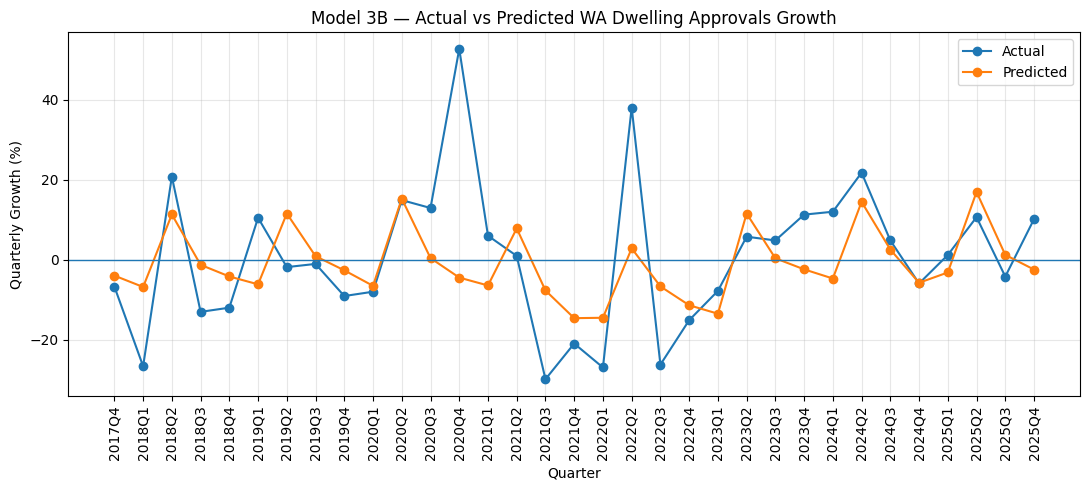

In [ ]:
# ============================================================
# MODEL 3B — CHRONOLOGICAL TRAIN / TEST VALIDATION
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Variables
target = "dln_WA_Dwelling_Approvals"

predictors = [
    "Population_Growth_L5",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate",
    "dln_Perth_Construction_Cost_Index",
    "Q_2",
    "Q_3",
    "Q_4"
]

# Complete Model 3B data
validation_data = model3_reg[
    ["Quarter", target] + predictors
].dropna().copy()

# Chronological 80/20 split
split_index = int(len(validation_data) * 0.80)

train = validation_data.iloc[:split_index].copy()
test = validation_data.iloc[split_index:].copy()

# Training data
X_train = sm.add_constant(
    train[predictors].astype(float),
    has_constant="add"
)

y_train = train[target]

# Test data
X_test = sm.add_constant(
    test[predictors].astype(float),
    has_constant="add"
)

y_test = test[target]

# Fit only on training period
validation_model = sm.OLS(
    y_train,
    X_train
).fit()

# Predict unseen test period
predictions = validation_model.predict(X_test)

# Accuracy measures
mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

print("MODEL 3B — CHRONOLOGICAL VALIDATION")
print("=" * 65)

print(
    "Training period:",
    train["Quarter"].iloc[0],
    "to",
    train["Quarter"].iloc[-1]
)

print(
    "Test period:",
    test["Quarter"].iloc[0],
    "to",
    test["Quarter"].iloc[-1]
)

print("Training observations:", len(train))
print("Test observations:", len(test))

print(f"\nTest MAE:  {mae:.4f} percentage points")
print(f"Test RMSE: {rmse:.4f} percentage points")


# ============================================================
# ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    test["Quarter"],
    y_test,
    marker="o",
    label="Actual"
)

plt.plot(
    test["Quarter"],
    predictions,
    marker="o",
    label="Predicted"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Model 3B — Actual vs Predicted WA Dwelling Approvals Growth"
)

plt.xlabel("Quarter")
plt.ylabel("Quarterly Growth (%)")

plt.xticks(
    rotation=90
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#Model 4

In [ ]:
# ============================================================
# MODEL 4 — STEP 1
# RECENT WA HOUSING MARKET DATASET
# ============================================================

model4_vars = [
    "Quarter",
    "WA_Mean_Dwelling_Price_000",
    "WA_Population",
    "WA_Dwelling_Stock_000",
    "WA_NOM",
    "WA_NIM",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate"
]

# Keep master unchanged
model4_full = master_df[model4_vars].copy()

# Common sample for these Model 4 variables only
model4 = model4_full.dropna().copy()

# Quarterly time variable
model4["Quarter_Period"] = pd.PeriodIndex(
    model4["Quarter"],
    freq="Q"
)

print("MODEL 4 — RECENT HOUSING MARKET")
print("=" * 60)

print("Shape:", model4.shape)

print(
    "Period:",
    model4["Quarter"].iloc[0],
    "to",
    model4["Quarter"].iloc[-1]
)

print(
    "Duplicate quarters:",
    model4["Quarter"].duplicated().sum()
)

print("\nMissing values:")
print(
    model4[model4_vars]
    .isna()
    .sum()
)

print("\nFirst 5 rows:")
print(model4.head().to_string(index=False))

print("\nLast 5 rows:")
print(model4.tail().to_string(index=False))

MODEL 4 — RECENT HOUSING MARKET
Shape: (56, 10)
Period: 2011Q3 to 2025Q2
Duplicate quarters: 0

Missing values:
Quarter                       0
WA_Mean_Dwelling_Price_000    0
WA_Population                 0
WA_Dwelling_Stock_000         0
WA_NOM                        0
WA_NIM                        0
Perth_Rent_Index              0
Housing_Lending_Rate          0
WA_Unemployment_Rate          0
dtype: int64

First 5 rows:
Quarter  WA_Mean_Dwelling_Price_000  WA_Population  WA_Dwelling_Stock_000  WA_NOM  WA_NIM  Perth_Rent_Index  Housing_Lending_Rate  WA_Unemployment_Rate Quarter_Period
 2011Q3                       524.8      2369612.0                  942.0 11922.0  1444.0              98.0              7.790000              4.221502         2011Q3
 2011Q4                       521.4      2385947.0                  946.3 11441.0  2137.0              99.2              7.546667              4.240467         2011Q4
 2012Q1                       532.4      2408108.0                  950

In [ ]:
# ============================================================
# MODEL 4 — STEP 2
# VARIABLE TRANSFORMATIONS
# ============================================================

model4_work = model4.copy()

# ------------------------------------------------------------
# 1. Log growth variables (%)
# ------------------------------------------------------------

log_vars = [
    "WA_Mean_Dwelling_Price_000",
    "WA_Population",
    "WA_Dwelling_Stock_000",
    "Perth_Rent_Index"
]

for var in log_vars:

    model4_work["ln_" + var] = np.log(
        model4_work[var]
    )

    model4_work["dln_" + var] = (
        model4_work["ln_" + var].diff() * 100
    )


# ------------------------------------------------------------
# 2. Population relative to dwelling stock
# Stock is recorded in thousands of dwellings
# ------------------------------------------------------------

model4_work["Persons_Per_Dwelling"] = (
    model4_work["WA_Population"]
    / (model4_work["WA_Dwelling_Stock_000"] * 1000)
)

# Quarterly change in population pressure
model4_work["d_Persons_Per_Dwelling"] = (
    model4_work["Persons_Per_Dwelling"].diff()
)


# ------------------------------------------------------------
# 3. Migration relative to population
# ------------------------------------------------------------

model4_work["NOM_per_1000"] = (
    model4_work["WA_NOM"]
    / model4_work["WA_Population"]
    * 1000
)

model4_work["NIM_per_1000"] = (
    model4_work["WA_NIM"]
    / model4_work["WA_Population"]
    * 1000
)


# ------------------------------------------------------------
# 4. Changes in interest and unemployment rates
# ------------------------------------------------------------

model4_work["d_Housing_Lending_Rate"] = (
    model4_work["Housing_Lending_Rate"].diff()
)

model4_work["d_WA_Unemployment_Rate"] = (
    model4_work["WA_Unemployment_Rate"].diff()
)


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

transform_vars = [
    "dln_WA_Mean_Dwelling_Price_000",
    "dln_WA_Population",
    "dln_WA_Dwelling_Stock_000",
    "Persons_Per_Dwelling",
    "d_Persons_Per_Dwelling",
    "dln_Perth_Rent_Index",
    "NOM_per_1000",
    "NIM_per_1000",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

print("MODEL 4 — TRANSFORMATION SUMMARY")
print("=" * 70)

print(
    model4_work[transform_vars]
    .describe()
    .T
    .round(4)
)

print("\nMISSING VALUES")
print("=" * 70)

print(
    model4_work[transform_vars]
    .isna()
    .sum()
)

MODEL 4 — TRANSFORMATION SUMMARY
                                count    mean     std     min     25%     50%  \
dln_WA_Mean_Dwelling_Price_000   55.0  1.0097  2.3832 -2.8885 -0.8533  0.6772   
dln_WA_Population                55.0  0.4567  0.2337  0.0576  0.2630  0.3989   
dln_WA_Dwelling_Stock_000        55.0  0.4196  0.1647  0.2050  0.2863  0.3645   
Persons_Per_Dwelling             56.0  2.4803  0.0581  2.4043  2.4291  2.4727   
d_Persons_Per_Dwelling           55.0  0.0009  0.0086 -0.0198 -0.0028  0.0012   
dln_Perth_Rent_Index             55.0  0.4598  1.5940 -2.4766 -0.7271  0.5386   
NOM_per_1000                     56.0  2.5397  2.0710 -0.8518  0.8798  2.2773   
NIM_per_1000                     56.0  0.2552  0.9012 -1.4278 -0.4827  0.2941   
d_Housing_Lending_Rate           55.0  0.0108  0.2911 -0.3567 -0.1500  0.0000   
d_WA_Unemployment_Rate           55.0 -0.0036  0.4447 -0.8727 -0.2276 -0.0049   

                                   75%     max  
dln_WA_Mean_Dwelling_Price

In [ ]:
# ============================================================
# MODEL 4 — STEP 3
# CORRELATION WITH PRICE GROWTH AT DIFFERENT LAGS
# ============================================================

target = model4_work[
    "dln_WA_Mean_Dwelling_Price_000"
]

lag_variables = {
    "Population_Growth": "dln_WA_Population",
    "Dwelling_Stock_Growth": "dln_WA_Dwelling_Stock_000",
    "Persons_Per_Dwelling_Change": "d_Persons_Per_Dwelling",
    "Rent_Growth": "dln_Perth_Rent_Index",
    "NOM_per_1000": "NOM_per_1000",
    "NIM_per_1000": "NIM_per_1000",
    "Lending_Rate_Change": "d_Housing_Lending_Rate",
    "Unemployment_Change": "d_WA_Unemployment_Rate"
}

lag_results = []

for lag in range(0, 5):

    row = {"Lag_Quarters": lag}

    for label, variable in lag_variables.items():

        row[label] = target.corr(
            model4_work[variable].shift(lag)
        )

    lag_results.append(row)

lag_table4 = pd.DataFrame(lag_results)

print(
    "CORRELATION WITH CURRENT WA MEAN DWELLING PRICE GROWTH"
)
print("=" * 110)

print(
    lag_table4
    .round(3)
    .to_string(index=False)
)

CORRELATION WITH CURRENT WA MEAN DWELLING PRICE GROWTH
 Lag_Quarters  Population_Growth  Dwelling_Stock_Growth  Persons_Per_Dwelling_Change  Rent_Growth  NOM_per_1000  NIM_per_1000  Lending_Rate_Change  Unemployment_Change
            0              0.304                 -0.437                        0.417        0.542         0.135         0.643                0.027               -0.176
            1              0.442                 -0.478                        0.532        0.533         0.270         0.619                0.145                0.053
            2              0.431                 -0.424                        0.497        0.492         0.300         0.588                0.206               -0.003
            3              0.664                 -0.524                        0.701        0.469         0.507         0.569                0.296               -0.005
            4              0.593                 -0.450                        0.614        0.401        

In [ ]:
# ============================================================
# PRICE GROWTH AUTOCORRELATION
# ============================================================

price_lags = []

for lag in range(1, 5):

    corr = target.corr(
        target.shift(lag)
    )

    price_lags.append({
        "Lag_Quarters": lag,
        "Price_Growth_Autocorrelation": corr
    })

price_lag_table = pd.DataFrame(price_lags)

print("\nPRICE GROWTH AUTOCORRELATION")
print("=" * 50)

print(
    price_lag_table
    .round(3)
    .to_string(index=False)
)


PRICE GROWTH AUTOCORRELATION
 Lag_Quarters  Price_Growth_Autocorrelation
            1                         0.457
            2                         0.517
            3                         0.301
            4                         0.405


In [ ]:
# ============================================================
# MODEL 4A — RECENT HOUSING MARKET BASELINE
# ============================================================

import statsmodels.api as sm

# Target
model4_work["Price_Growth"] = (
    model4_work["dln_WA_Mean_Dwelling_Price_000"]
)

# Price momentum
model4_work["Price_Growth_L1"] = (
    model4_work["Price_Growth"].shift(1)
)

model4_work["Price_Growth_L2"] = (
    model4_work["Price_Growth"].shift(2)
)

# Population pressure — 3 quarter lag
model4_work["Persons_Per_Dwelling_Change_L3"] = (
    model4_work["d_Persons_Per_Dwelling"].shift(3)
)

# Interstate migration — 1 quarter lag
model4_work["NIM_per_1000_L1"] = (
    model4_work["NIM_per_1000"].shift(1)
)

# Predictors
model4a_predictors = [
    "Price_Growth_L1",
    "Price_Growth_L2",
    "Persons_Per_Dwelling_Change_L3",
    "dln_Perth_Rent_Index",
    "NIM_per_1000_L1",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

# Complete sample for this model only
model4a_data = model4_work[
    ["Quarter", "Price_Growth"] + model4a_predictors
].dropna().copy()

# Fit OLS
y = model4a_data["Price_Growth"]

X = model4a_data[
    model4a_predictors
].astype(float)

X = sm.add_constant(X)

model4a = sm.OLS(y, X).fit()

print("MODEL 4A — RECENT HOUSING MARKET")
print("=" * 70)

print(
    "Period:",
    model4a_data["Quarter"].iloc[0],
    "to",
    model4a_data["Quarter"].iloc[-1]
)

print("Observations:", len(model4a_data))

print(model4a.summary())

MODEL 4A — RECENT HOUSING MARKET
Period: 2012Q3 to 2025Q2
Observations: 52
                            OLS Regression Results                            
Dep. Variable:           Price_Growth   R-squared:                       0.598
Model:                            OLS   Adj. R-squared:                  0.535
Method:                 Least Squares   F-statistic:                     9.369
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           4.71e-07
Time:                        04:03:49   Log-Likelihood:                -95.693
No. Observations:                  52   AIC:                             207.4
Df Residuals:                      44   BIC:                             223.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------

In [ ]:
# ============================================================
# MODEL 4A — MULTICOLLINEARITY CHECK
# ============================================================

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = model4a_data[
    model4a_predictors
].astype(float)

vif4 = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.values, i
        )
        for i in range(X_vif.shape[1])
    ]
})

vif4 = vif4.sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

print("MODEL 4A — VARIANCE INFLATION FACTORS")
print("=" * 60)

print(
    vif4
    .round(3)
    .to_string(index=False)
)

MODEL 4A — VARIANCE INFLATION FACTORS
                      Variable    VIF
               NIM_per_1000_L1 10.396
          dln_Perth_Rent_Index  8.185
Persons_Per_Dwelling_Change_L3  2.756
               Price_Growth_L2  2.085
               Price_Growth_L1  1.847
        d_Housing_Lending_Rate  1.253
        d_WA_Unemployment_Rate  1.194


In [ ]:
# ============================================================
# MODEL 4 — COMPARE SIMPLER SPECIFICATIONS
# ============================================================

def fit_model4(name, predictors):

    data = model4_work[
        ["Quarter", "Price_Growth"] + predictors
    ].dropna().copy()

    y = data["Price_Growth"]

    X = data[predictors].astype(float)
    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()

    print("\n" + "=" * 75)
    print(name)
    print("=" * 75)

    print(
        "Period:",
        data["Quarter"].iloc[0],
        "to",
        data["Quarter"].iloc[-1]
    )

    print("Observations:", len(data))

    print(model.summary())

    return model, data


# ------------------------------------------------------------
# Common variables
# ------------------------------------------------------------

common = [
    "Price_Growth_L1",
    "Price_Growth_L2",
    "Persons_Per_Dwelling_Change_L3",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]


# ------------------------------------------------------------
# Model 4B — Housing pressure + Rent
# ------------------------------------------------------------

model4b, model4b_data = fit_model4(
    "MODEL 4B — HOUSING PRESSURE + RENT",
    common + [
        "dln_Perth_Rent_Index"
    ]
)


# ------------------------------------------------------------
# Model 4C — Housing pressure + Interstate migration
# ------------------------------------------------------------

model4c, model4c_data = fit_model4(
    "MODEL 4C — HOUSING PRESSURE + NIM",
    common + [
        "NIM_per_1000_L1"
    ]
)


# ------------------------------------------------------------
# Model 4D — Housing pressure only
# ------------------------------------------------------------

model4d, model4d_data = fit_model4(
    "MODEL 4D — HOUSING PRESSURE MODEL",
    common
)


# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

comparison4 = pd.DataFrame({

    "Model": [
        "4A Pressure + Rent + NIM",
        "4B Pressure + Rent",
        "4C Pressure + NIM",
        "4D Pressure"
    ],

    "R2": [
        model4a.rsquared,
        model4b.rsquared,
        model4c.rsquared,
        model4d.rsquared
    ],

    "Adjusted_R2": [
        model4a.rsquared_adj,
        model4b.rsquared_adj,
        model4c.rsquared_adj,
        model4d.rsquared_adj
    ],

    "AIC": [
        model4a.aic,
        model4b.aic,
        model4c.aic,
        model4d.aic
    ],

    "BIC": [
        model4a.bic,
        model4b.bic,
        model4c.bic,
        model4d.bic
    ],

    "DW": [
        sm.stats.stattools.durbin_watson(model4a.resid),
        sm.stats.stattools.durbin_watson(model4b.resid),
        sm.stats.stattools.durbin_watson(model4c.resid),
        sm.stats.stattools.durbin_watson(model4d.resid)
    ]
})

print("\nMODEL 4 COMPARISON")
print("=" * 85)

print(
    comparison4
    .round(3)
    .to_string(index=False)
)


MODEL 4B — HOUSING PRESSURE + RENT
Period: 2012Q3 to 2025Q2
Observations: 52
                            OLS Regression Results                            
Dep. Variable:           Price_Growth   R-squared:                       0.562
Model:                            OLS   Adj. R-squared:                  0.503
Method:                 Least Squares   F-statistic:                     9.614
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           8.42e-07
Time:                        04:05:22   Log-Likelihood:                -97.968
No. Observations:                  52   AIC:                             209.9
Df Residuals:                      45   BIC:                             223.6
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

In [ ]:
# ============================================================
# MODEL 4D — FINAL DIAGNOSTICS
# ============================================================

from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey,
    het_breuschpagan
)

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from statsmodels.stats.stattools import durbin_watson
from scipy.stats import jarque_bera


# ------------------------------------------------------------
# 1. Durbin-Watson
# ------------------------------------------------------------

dw4 = durbin_watson(model4d.resid)


# ------------------------------------------------------------
# 2. Breusch-Godfrey — 4 quarterly lags
# ------------------------------------------------------------

bg4 = acorr_breusch_godfrey(
    model4d,
    nlags=4
)


# ------------------------------------------------------------
# 3. Breusch-Pagan
# ------------------------------------------------------------

bp4 = het_breuschpagan(
    model4d.resid,
    model4d.model.exog
)


# ------------------------------------------------------------
# 4. Jarque-Bera
# ------------------------------------------------------------

jb4 = jarque_bera(
    model4d.resid
)


# ------------------------------------------------------------
# 5. VIF
# ------------------------------------------------------------

model4d_predictors = [
    "Price_Growth_L1",
    "Price_Growth_L2",
    "Persons_Per_Dwelling_Change_L3",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

X_vif4 = model4d_data[
    model4d_predictors
].astype(float)

vif4d = pd.DataFrame({
    "Variable": X_vif4.columns,

    "VIF": [
        variance_inflation_factor(
            X_vif4.values,
            i
        )
        for i in range(X_vif4.shape[1])
    ]
})


# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("MODEL 4D — DIAGNOSTIC TESTS")
print("=" * 65)

print(f"Durbin-Watson:              {dw4:.4f}")
print(f"Breusch-Godfrey p-value:    {bg4[1]:.4f}")
print(f"Breusch-Pagan p-value:      {bp4[1]:.4f}")
print(f"Jarque-Bera p-value:        {jb4.pvalue:.4f}")

print("\nVIF")
print("=" * 65)

print(
    vif4d
    .sort_values("VIF", ascending=False)
    .round(3)
    .to_string(index=False)
)

MODEL 4D — DIAGNOSTIC TESTS
Durbin-Watson:              1.8438
Breusch-Godfrey p-value:    0.5813
Breusch-Pagan p-value:      0.7978
Jarque-Bera p-value:        0.5456

VIF
                      Variable   VIF
Persons_Per_Dwelling_Change_L3 1.682
               Price_Growth_L2 1.652
               Price_Growth_L1 1.474
        d_WA_Unemployment_Rate 1.161
        d_Housing_Lending_Rate 1.035


/tmp/ipykernel_1400/2024769246.py:29: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg4 = acorr_breusch_godfrey(


MODEL 4D — CHRONOLOGICAL VALIDATION
Training period: 2012Q3 to 2022Q3
Test period: 2022Q4 to 2025Q2
Training observations: 41
Test observations: 11

Test MAE:  1.6657 percentage points
Test RMSE: 2.0673 percentage points


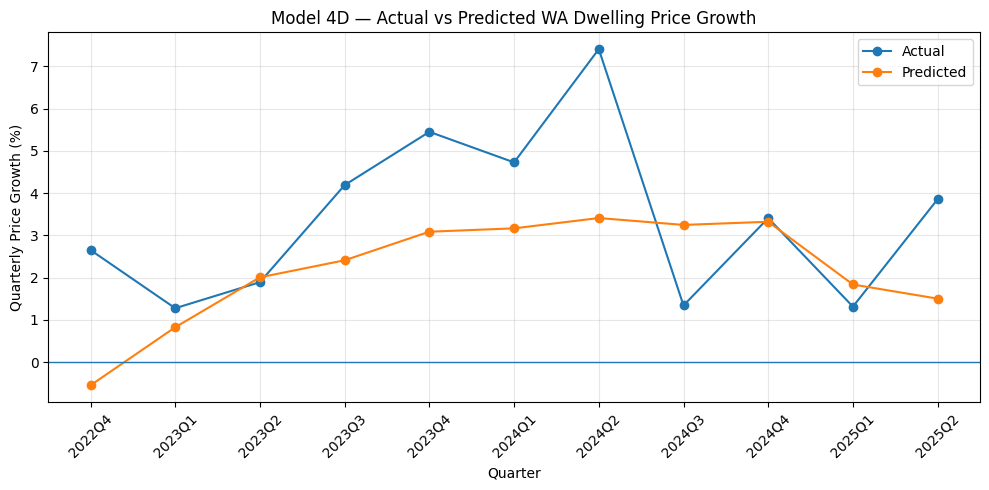

In [ ]:
# ============================================================
# MODEL 4D — CHRONOLOGICAL TRAIN / TEST VALIDATION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

target4 = "Price_Growth"

predictors4 = [
    "Price_Growth_L1",
    "Price_Growth_L2",
    "Persons_Per_Dwelling_Change_L3",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

validation4 = model4_work[
    ["Quarter", target4] + predictors4
].dropna().copy()

# 80/20 chronological split
split4 = int(len(validation4) * 0.80)

train4 = validation4.iloc[:split4].copy()
test4 = validation4.iloc[split4:].copy()

# Training
X_train4 = sm.add_constant(
    train4[predictors4].astype(float),
    has_constant="add"
)

y_train4 = train4[target4]

# Test
X_test4 = sm.add_constant(
    test4[predictors4].astype(float),
    has_constant="add"
)

y_test4 = test4[target4]

# Fit model using training period only
validation_model4 = sm.OLS(
    y_train4,
    X_train4
).fit()

# One-step-ahead-style predictions
pred4 = validation_model4.predict(X_test4)

# Performance
mae4 = mean_absolute_error(
    y_test4,
    pred4
)

rmse4 = np.sqrt(
    mean_squared_error(
        y_test4,
        pred4
    )
)

print("MODEL 4D — CHRONOLOGICAL VALIDATION")
print("=" * 65)

print(
    "Training period:",
    train4["Quarter"].iloc[0],
    "to",
    train4["Quarter"].iloc[-1]
)

print(
    "Test period:",
    test4["Quarter"].iloc[0],
    "to",
    test4["Quarter"].iloc[-1]
)

print("Training observations:", len(train4))
print("Test observations:", len(test4))

print(f"\nTest MAE:  {mae4:.4f} percentage points")
print(f"Test RMSE: {rmse4:.4f} percentage points")


# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    test4["Quarter"],
    y_test4,
    marker="o",
    label="Actual"
)

plt.plot(
    test4["Quarter"],
    pred4,
    marker="o",
    label="Predicted"
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Model 4D — Actual vs Predicted WA Dwelling Price Growth"
)

plt.xlabel("Quarter")
plt.ylabel("Quarterly Price Growth (%)")

plt.xticks(rotation=45)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#MACHINE LEARNING MODELS

##XGBOOST

In [ ]:
# ============================================================
# RECREATE MODEL 1 WORKING DATA FOR ML
# ============================================================

# Variables required from master dataset
model1_vars = [
    "Quarter",
    "Perth_RPPI",
    "WA_Population",
    "WA_Dwelling_Completions",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate"
]

# Create Model 1 common sample
model1_work = master_df[
    model1_vars
].dropna().copy()

# Ensure chronological order
model1_work["Quarter_Period"] = pd.PeriodIndex(
    model1_work["Quarter"],
    freq="Q"
)

model1_work = model1_work.sort_values(
    "Quarter_Period"
).reset_index(drop=True)


# ------------------------------------------------------------
# Transform variables
# ------------------------------------------------------------

# RPPI quarterly log growth (%)
model1_work["dln_Perth_RPPI"] = (
    np.log(model1_work["Perth_RPPI"]).diff() * 100
)

# Population quarterly log growth (%)
model1_work["dln_WA_Population"] = (
    np.log(model1_work["WA_Population"]).diff() * 100
)

# Completions quarterly log growth (%)
model1_work["dln_WA_Dwelling_Completions"] = (
    np.log(model1_work["WA_Dwelling_Completions"]).diff() * 100
)

# Rent quarterly log growth (%)
model1_work["dln_Rent"] = (
    np.log(model1_work["Perth_Rent_Index"]).diff() * 100
)

# Lending-rate quarterly change
model1_work["d_Housing_Lending_Rate"] = (
    model1_work["Housing_Lending_Rate"].diff()
)

# Unemployment-rate quarterly change
model1_work["d_WA_Unemployment_Rate"] = (
    model1_work["WA_Unemployment_Rate"].diff()
)


# ------------------------------------------------------------
# Recreate final Model 1C lags
# ------------------------------------------------------------

model1_work["RPPI_Growth_L1"] = (
    model1_work["dln_Perth_RPPI"].shift(1)
)

model1_work["Population_Growth_L3"] = (
    model1_work["dln_WA_Population"].shift(3)
)

model1_work["Completions_Growth_L2"] = (
    model1_work["dln_WA_Dwelling_Completions"].shift(2)
)


# ------------------------------------------------------------
# Prepare exact ML dataset
# ------------------------------------------------------------

xgb1_predictors = [
    "RPPI_Growth_L1",
    "Population_Growth_L3",
    "Completions_Growth_L2",
    "dln_Rent",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

target1 = "dln_Perth_RPPI"

xgb1_data = model1_work[
    ["Quarter", target1] + xgb1_predictors
].dropna().copy()


# ------------------------------------------------------------
# Check
# ------------------------------------------------------------

print("XGBOOST MODEL 1 DATA")
print("=" * 60)

print("Shape:", xgb1_data.shape)

print(
    "Period:",
    xgb1_data["Quarter"].iloc[0],
    "to",
    xgb1_data["Quarter"].iloc[-1]
)

print("Observations:", len(xgb1_data))

print("\nMissing values:")
print(xgb1_data.isna().sum())

XGBOOST MODEL 1 DATA
Shape: (70, 8)
Period: 2004Q3 to 2021Q4
Observations: 70

Missing values:
Quarter                   0
dln_Perth_RPPI            0
RPPI_Growth_L1            0
Population_Growth_L3      0
Completions_Growth_L2     0
dln_Rent                  0
d_Housing_Lending_Rate    0
d_WA_Unemployment_Rate    0
dtype: int64


In [ ]:
# ============================================================
# XGBOOST — MODEL 1 HISTORICAL PRICE
# STEP 2: BASELINE MODEL
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Chronological 80/20 split
# ------------------------------------------------------------

split1 = int(len(xgb1_data) * 0.80)

xgb1_train = xgb1_data.iloc[:split1].copy()
xgb1_test = xgb1_data.iloc[split1:].copy()

X_train1 = xgb1_train[xgb1_predictors]
y_train1 = xgb1_train[target1]

X_test1 = xgb1_test[xgb1_predictors]
y_test1 = xgb1_test[target1]


print("XGBOOST MODEL 1 — DATA SPLIT")
print("=" * 60)

print(
    "Training period:",
    xgb1_train["Quarter"].iloc[0],
    "to",
    xgb1_train["Quarter"].iloc[-1]
)

print(
    "Test period:",
    xgb1_test["Quarter"].iloc[0],
    "to",
    xgb1_test["Quarter"].iloc[-1]
)

print("Training observations:", len(xgb1_train))
print("Test observations:", len(xgb1_test))


# ------------------------------------------------------------
# 2. Baseline XGBoost model
# ------------------------------------------------------------

xgb_model1 = XGBRegressor(
    objective="reg:squarederror",

    n_estimators=100,
    learning_rate=0.05,

    max_depth=2,
    min_child_weight=3,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=1.0,

    random_state=42
)

xgb_model1.fit(
    X_train1,
    y_train1
)


# ------------------------------------------------------------
# 3. Test predictions
# ------------------------------------------------------------

xgb_pred1 = xgb_model1.predict(
    X_test1
)


# ------------------------------------------------------------
# 4. Performance
# ------------------------------------------------------------

xgb_mae1 = mean_absolute_error(
    y_test1,
    xgb_pred1
)

xgb_rmse1 = np.sqrt(
    mean_squared_error(
        y_test1,
        xgb_pred1
    )
)

xgb_r2_test1 = r2_score(
    y_test1,
    xgb_pred1
)


print("\nXGBOOST MODEL 1 — TEST PERFORMANCE")
print("=" * 60)

print(f"MAE:     {xgb_mae1:.4f} percentage points")
print(f"RMSE:    {xgb_rmse1:.4f} percentage points")
print(f"Test R²: {xgb_r2_test1:.4f}")

XGBOOST MODEL 1 — DATA SPLIT
Training period: 2004Q3 to 2018Q2
Test period: 2018Q3 to 2021Q4
Training observations: 56
Test observations: 14

XGBOOST MODEL 1 — TEST PERFORMANCE
MAE:     1.1509 percentage points
RMSE:    1.5987 percentage points
Test R²: 0.4257


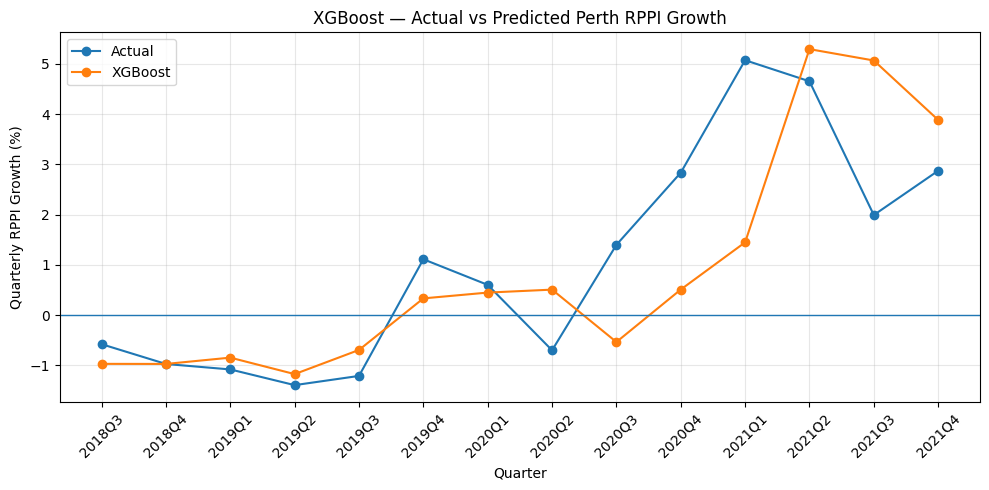

XGBOOST MODEL 1 — FEATURE IMPORTANCE
              Variable  Importance
        RPPI_Growth_L1      0.4263
d_WA_Unemployment_Rate      0.1494
 Completions_Growth_L2      0.1413
              dln_Rent      0.0967
  Population_Growth_L3      0.0951
d_Housing_Lending_Rate      0.0912


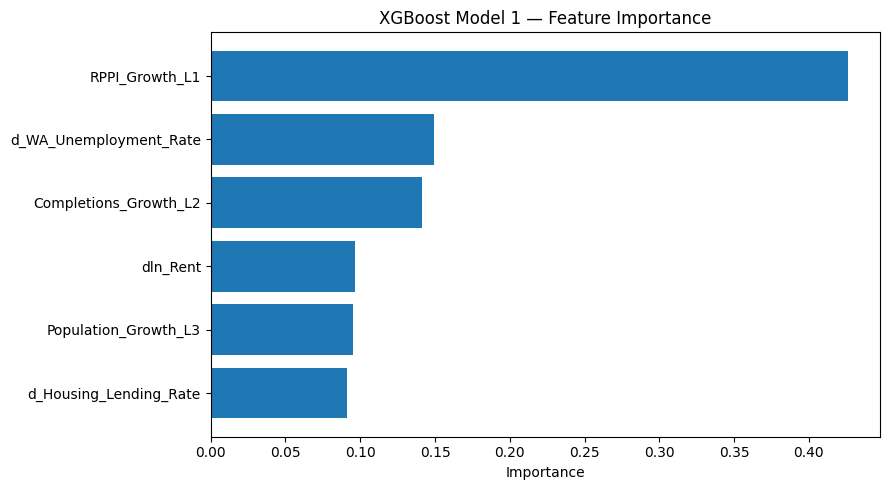

In [ ]:
# ============================================================
# XGBOOST MODEL 1
# ACTUAL VS PREDICTED + FEATURE IMPORTANCE
# ============================================================

# ------------------------------------------------------------
# 1. Actual vs predicted
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    xgb1_test["Quarter"],
    y_test1,
    marker="o",
    label="Actual"
)

plt.plot(
    xgb1_test["Quarter"],
    xgb_pred1,
    marker="o",
    label="XGBoost"
)

plt.axhline(0, linewidth=1)

plt.title(
    "XGBoost — Actual vs Predicted Perth RPPI Growth"
)

plt.xlabel("Quarter")
plt.ylabel("Quarterly RPPI Growth (%)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Feature importance
# ------------------------------------------------------------

importance1 = pd.DataFrame({
    "Variable": xgb1_predictors,
    "Importance": xgb_model1.feature_importances_
})

importance1 = importance1.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("XGBOOST MODEL 1 — FEATURE IMPORTANCE")
print("=" * 60)

print(
    importance1
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 3. Plot feature importance
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.barh(
    importance1["Variable"][::-1],
    importance1["Importance"][::-1]
)

plt.title(
    "XGBoost Model 1 — Feature Importance"
)

plt.xlabel("Importance")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# XGBOOST MODEL 1 — TIME-SERIES TUNING
# Training data ONLY
# ============================================================

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from xgboost import XGBRegressor
import pandas as pd

# ------------------------------------------------------------
# 1. Time-series cross-validation
# ------------------------------------------------------------

tscv = TimeSeriesSplit(n_splits=4)


# ------------------------------------------------------------
# 2. Base XGBoost model
# ------------------------------------------------------------

xgb_tune1 = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 3. Small parameter grid
# ------------------------------------------------------------

param_grid1 = {

    "n_estimators": [
        50,
        100,
        150
    ],

    "learning_rate": [
        0.03,
        0.05,
        0.10
    ],

    "max_depth": [
        1,
        2,
        3
    ],

    "min_child_weight": [
        1,
        3
    ],

    "subsample": [
        0.8,
        1.0
    ],

    "colsample_bytree": [
        0.8,
        1.0
    ]
}


# ------------------------------------------------------------
# 4. Grid search
# IMPORTANT:
# Only X_train1 and y_train1 are used here.
# Test data is NOT used for model selection.
# ------------------------------------------------------------

grid1 = GridSearchCV(
    estimator=xgb_tune1,
    param_grid=param_grid1,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

grid1.fit(
    X_train1,
    y_train1
)


# ------------------------------------------------------------
# 5. Best training-CV result
# ------------------------------------------------------------

print("\nXGBOOST MODEL 1 — TUNING RESULTS")
print("=" * 65)

print("Best parameters:")
print(grid1.best_params_)

print(
    "\nBest Time-Series CV MAE:",
    round(-grid1.best_score_, 4),
    "percentage points"
)

Fitting 4 folds for each of 216 candidates, totalling 864 fits

XGBOOST MODEL 1 — TUNING RESULTS
Best parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 1, 'min_child_weight': 3, 'n_estimators': 100, 'subsample': 1.0}

Best Time-Series CV MAE: 1.3144 percentage points


In [ ]:
# ============================================================
# XGBOOST MODEL 1 — FINAL TUNED MODEL
# UNTOUCHED TEST SET EVALUATION
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Best model selected from training CV
# ------------------------------------------------------------

xgb1_tuned = XGBRegressor(
    objective="reg:squarederror",

    colsample_bytree=1.0,
    learning_rate=0.1,
    max_depth=1,
    min_child_weight=3,
    n_estimators=100,
    subsample=1.0,

    random_state=42
)

# Train using ALL 56 training observations
xgb1_tuned.fit(
    X_train1,
    y_train1
)


# ------------------------------------------------------------
# 2. Predict untouched test period
# ------------------------------------------------------------

xgb1_tuned_pred = xgb1_tuned.predict(
    X_test1
)


# ------------------------------------------------------------
# 3. Performance
# ------------------------------------------------------------

tuned_mae1 = mean_absolute_error(
    y_test1,
    xgb1_tuned_pred
)

tuned_rmse1 = np.sqrt(
    mean_squared_error(
        y_test1,
        xgb1_tuned_pred
    )
)

tuned_r2_1 = r2_score(
    y_test1,
    xgb1_tuned_pred
)


print("TUNED XGBOOST MODEL 1 — TEST PERFORMANCE")
print("=" * 60)

print(f"MAE:     {tuned_mae1:.4f} percentage points")
print(f"RMSE:    {tuned_rmse1:.4f} percentage points")
print(f"Test R²: {tuned_r2_1:.4f}")


# ------------------------------------------------------------
# 4. Final comparison
# ------------------------------------------------------------

comparison_ml1 = pd.DataFrame({

    "Model": [
        "Dynamic OLS",
        "Baseline XGBoost",
        "Tuned XGBoost"
    ],

    "Test_MAE": [
        1.1477,
        xgb_mae1,
        tuned_mae1
    ],

    "Test_RMSE": [
        1.3934,
        xgb_rmse1,
        tuned_rmse1
    ]
})

print("\nMODEL 1 — FINAL OUT-OF-SAMPLE COMPARISON")
print("=" * 65)

print(
    comparison_ml1
    .round(4)
    .to_string(index=False)
)

TUNED XGBOOST MODEL 1 — TEST PERFORMANCE
MAE:     0.9894 percentage points
RMSE:    1.3378 percentage points
Test R²: 0.5979

MODEL 1 — FINAL OUT-OF-SAMPLE COMPARISON
           Model  Test_MAE  Test_RMSE
     Dynamic OLS    1.1477     1.3934
Baseline XGBoost    1.1509     1.5987
   Tuned XGBoost    0.9894     1.3378


In [ ]:
# ============================================================
# XGBOOST MODEL 2 — CHECK EXISTING DATA
# ============================================================

print("Checking Model 2 working dataframe...")

try:
    print("model2_work: FOUND")
    print("Shape:", model2_work.shape)

    required_model2 = [
        "dln_WA_Dwelling_Completions",
        "Completions_Growth_L1",
        "Approvals_Growth_L4",
        "dln_WA_Population",
        "d_Housing_Lending_Rate",
        "dln_Perth_Construction_Cost_Index",
        "Q_2",
        "Q_3",
        "Q_4"
    ]

    print("\nRequired variables:")

    for var in required_model2:
        print(
            f"{var}:",
            "FOUND" if var in model2_work.columns else "MISSING"
        )

except NameError:
    print("model2_work: MISSING")

Checking Model 2 working dataframe...
model2_work: FOUND
model2_work: MISSING


In [ ]:
# ============================================================
# RECREATE FINAL MODEL 2E DATA FOR MACHINE LEARNING
# ============================================================

# ------------------------------------------------------------
# 1. Variables from master
# ------------------------------------------------------------

model2_vars = [
    "Quarter",
    "WA_Dwelling_Completions",
    "WA_Dwelling_Approvals",
    "WA_Population",
    "Housing_Lending_Rate",
    "Perth_Construction_Cost_Index"
]

model2_work = master_df[
    model2_vars
].dropna().copy()

# Quarterly time variable
model2_work["Quarter_Period"] = pd.PeriodIndex(
    model2_work["Quarter"],
    freq="Q"
)

model2_work = model2_work.sort_values(
    "Quarter_Period"
).reset_index(drop=True)


# ------------------------------------------------------------
# 2. Growth / change transformations
# ------------------------------------------------------------

model2_work["dln_WA_Dwelling_Completions"] = (
    np.log(
        model2_work["WA_Dwelling_Completions"]
    ).diff() * 100
)

model2_work["dln_WA_Dwelling_Approvals"] = (
    np.log(
        model2_work["WA_Dwelling_Approvals"]
    ).diff() * 100
)

model2_work["dln_WA_Population"] = (
    np.log(
        model2_work["WA_Population"]
    ).diff() * 100
)

model2_work["d_Housing_Lending_Rate"] = (
    model2_work["Housing_Lending_Rate"].diff()
)

model2_work["dln_Perth_Construction_Cost_Index"] = (
    np.log(
        model2_work["Perth_Construction_Cost_Index"]
    ).diff() * 100
)


# ------------------------------------------------------------
# 3. Lags from final Model 2E
# ------------------------------------------------------------

model2_work["Completions_Growth_L1"] = (
    model2_work[
        "dln_WA_Dwelling_Completions"
    ].shift(1)
)

model2_work["Approvals_Growth_L4"] = (
    model2_work[
        "dln_WA_Dwelling_Approvals"
    ].shift(4)
)


# ------------------------------------------------------------
# 4. Calendar-quarter indicators
# Q1 = reference quarter
# ------------------------------------------------------------

model2_work["Quarter_Number"] = (
    model2_work["Quarter_Period"].dt.quarter
)

quarter_dummies = pd.get_dummies(
    model2_work["Quarter_Number"],
    prefix="Q",
    dtype=int
)

model2_work = pd.concat(
    [
        model2_work,
        quarter_dummies
    ],
    axis=1
)


# ------------------------------------------------------------
# 5. Final Model 2E predictors
# ------------------------------------------------------------

xgb2_predictors = [
    "Completions_Growth_L1",
    "Approvals_Growth_L4",
    "dln_WA_Population",
    "d_Housing_Lending_Rate",
    "dln_Perth_Construction_Cost_Index",
    "Q_2",
    "Q_3",
    "Q_4"
]

target2 = "dln_WA_Dwelling_Completions"


# ------------------------------------------------------------
# 6. Exact modelling dataset
# ------------------------------------------------------------

xgb2_data = model2_work[
    ["Quarter", target2] + xgb2_predictors
].dropna().copy()


# ------------------------------------------------------------
# 7. Check
# ------------------------------------------------------------

print("XGBOOST MODEL 2 DATA")
print("=" * 65)

print("Shape:", xgb2_data.shape)

print(
    "Period:",
    xgb2_data["Quarter"].iloc[0],
    "to",
    xgb2_data["Quarter"].iloc[-1]
)

print("Observations:", len(xgb2_data))

print("\nMissing values:")
print(
    xgb2_data.isna().sum()
)

XGBOOST MODEL 2 DATA
Shape: (93, 10)
Period: 2002Q4 to 2025Q4
Observations: 93

Missing values:
Quarter                              0
dln_WA_Dwelling_Completions          0
Completions_Growth_L1                0
Approvals_Growth_L4                  0
dln_WA_Population                    0
d_Housing_Lending_Rate               0
dln_Perth_Construction_Cost_Index    0
Q_2                                  0
Q_3                                  0
Q_4                                  0
dtype: int64


In [ ]:
# ============================================================
# XGBOOST MODEL 2 — BASELINE
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Chronological 80/20 split
# ------------------------------------------------------------

split2 = int(len(xgb2_data) * 0.80)

xgb2_train = xgb2_data.iloc[:split2].copy()
xgb2_test = xgb2_data.iloc[split2:].copy()

X_train2 = xgb2_train[xgb2_predictors]
y_train2 = xgb2_train[target2]

X_test2 = xgb2_test[xgb2_predictors]
y_test2 = xgb2_test[target2]


print("XGBOOST MODEL 2 — DATA SPLIT")
print("=" * 60)

print(
    "Training period:",
    xgb2_train["Quarter"].iloc[0],
    "to",
    xgb2_train["Quarter"].iloc[-1]
)

print(
    "Test period:",
    xgb2_test["Quarter"].iloc[0],
    "to",
    xgb2_test["Quarter"].iloc[-1]
)

print("Training observations:", len(xgb2_train))
print("Test observations:", len(xgb2_test))


# ------------------------------------------------------------
# 2. Baseline XGBoost
# ------------------------------------------------------------

xgb_model2 = XGBRegressor(
    objective="reg:squarederror",

    n_estimators=100,
    learning_rate=0.05,

    max_depth=2,
    min_child_weight=3,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=1.0,

    random_state=42
)

xgb_model2.fit(
    X_train2,
    y_train2
)


# ------------------------------------------------------------
# 3. Predictions
# ------------------------------------------------------------

xgb_pred2 = xgb_model2.predict(
    X_test2
)


# ------------------------------------------------------------
# 4. Test performance
# ------------------------------------------------------------

xgb_mae2 = mean_absolute_error(
    y_test2,
    xgb_pred2
)

xgb_rmse2 = np.sqrt(
    mean_squared_error(
        y_test2,
        xgb_pred2
    )
)

xgb_r2_test2 = r2_score(
    y_test2,
    xgb_pred2
)


print("\nXGBOOST MODEL 2 — TEST PERFORMANCE")
print("=" * 60)

print(
    f"MAE:     {xgb_mae2:.4f} percentage points"
)

print(
    f"RMSE:    {xgb_rmse2:.4f} percentage points"
)

print(
    f"Test R²: {xgb_r2_test2:.4f}"
)


# ------------------------------------------------------------
# 5. Initial OLS comparison
# ------------------------------------------------------------

print("\nINITIAL COMPARISON")
print("=" * 60)

print("OLS Model 2E")
print("MAE:  14.1109")
print("RMSE: 18.3271")

print("\nBaseline XGBoost")
print(f"MAE:  {xgb_mae2:.4f}")
print(f"RMSE: {xgb_rmse2:.4f}")

XGBOOST MODEL 2 — DATA SPLIT
Training period: 2002Q4 to 2021Q1
Test period: 2021Q2 to 2025Q4
Training observations: 74
Test observations: 19

XGBOOST MODEL 2 — TEST PERFORMANCE
MAE:     13.7116 percentage points
RMSE:    17.2533 percentage points
Test R²: -0.0043

INITIAL COMPARISON
OLS Model 2E
MAE:  14.1109
RMSE: 18.3271

Baseline XGBoost
MAE:  13.7116
RMSE: 17.2533


In [ ]:
# ============================================================
# XGBOOST MODEL 2 — TIME-SERIES TUNING
# TRAINING DATA ONLY
# ============================================================

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)

# ------------------------------------------------------------
# 1. Time-series CV
# ------------------------------------------------------------

tscv2 = TimeSeriesSplit(
    n_splits=4
)


# ------------------------------------------------------------
# 2. Base model
# ------------------------------------------------------------

xgb_tune2 = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 3. Parameter grid
# ------------------------------------------------------------

param_grid2 = {

    "n_estimators": [
        50,
        100,
        150
    ],

    "learning_rate": [
        0.03,
        0.05,
        0.10
    ],

    "max_depth": [
        1,
        2,
        3
    ],

    "min_child_weight": [
        1,
        3
    ],

    "subsample": [
        0.8,
        1.0
    ],

    "colsample_bytree": [
        0.8,
        1.0
    ]
}


# ------------------------------------------------------------
# 4. Grid search
# Test set is NOT used
# ------------------------------------------------------------

grid2 = GridSearchCV(
    estimator=xgb_tune2,
    param_grid=param_grid2,
    scoring="neg_mean_absolute_error",
    cv=tscv2,
    n_jobs=-1,
    verbose=1
)

grid2.fit(
    X_train2,
    y_train2
)


# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------

print("\nXGBOOST MODEL 2 — TUNING RESULTS")
print("=" * 65)

print("Best parameters:")
print(
    grid2.best_params_
)

print(
    "\nBest Time-Series CV MAE:",
    round(
        -grid2.best_score_,
        4
    ),
    "percentage points"
)

Fitting 4 folds for each of 216 candidates, totalling 864 fits

XGBOOST MODEL 2 — TUNING RESULTS
Best parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 1, 'min_child_weight': 3, 'n_estimators': 50, 'subsample': 0.8}

Best Time-Series CV MAE: 12.8231 percentage points


In [ ]:
# ============================================================
# XGBOOST MODEL 2 — FINAL TUNED MODEL
# ============================================================

# ------------------------------------------------------------
# 1. Selected model
# ------------------------------------------------------------

xgb2_tuned = XGBRegressor(
    objective="reg:squarederror",

    colsample_bytree=0.8,
    learning_rate=0.05,
    max_depth=1,
    min_child_weight=3,
    n_estimators=50,
    subsample=0.8,

    random_state=42
)


# ------------------------------------------------------------
# 2. Fit on ALL training data
# ------------------------------------------------------------

xgb2_tuned.fit(
    X_train2,
    y_train2
)


# ------------------------------------------------------------
# 3. Predict untouched test data
# ------------------------------------------------------------

xgb2_tuned_pred = xgb2_tuned.predict(
    X_test2
)


# ------------------------------------------------------------
# 4. Performance
# ------------------------------------------------------------

tuned_mae2 = mean_absolute_error(
    y_test2,
    xgb2_tuned_pred
)

tuned_rmse2 = np.sqrt(
    mean_squared_error(
        y_test2,
        xgb2_tuned_pred
    )
)

tuned_r2_2 = r2_score(
    y_test2,
    xgb2_tuned_pred
)


print("TUNED XGBOOST MODEL 2 — TEST PERFORMANCE")
print("=" * 65)

print(f"MAE:     {tuned_mae2:.4f} percentage points")
print(f"RMSE:    {tuned_rmse2:.4f} percentage points")
print(f"Test R²: {tuned_r2_2:.4f}")


# ------------------------------------------------------------
# 5. Final comparison
# ------------------------------------------------------------

comparison_ml2 = pd.DataFrame({

    "Model": [
        "Seasonal Dynamic OLS",
        "Baseline XGBoost",
        "Tuned XGBoost"
    ],

    "Test_MAE": [
        14.1109,
        xgb_mae2,
        tuned_mae2
    ],

    "Test_RMSE": [
        18.3271,
        xgb_rmse2,
        tuned_rmse2
    ]
})

print("\nMODEL 2 — FINAL OUT-OF-SAMPLE COMPARISON")
print("=" * 70)

print(
    comparison_ml2
    .round(4)
    .to_string(index=False)
)

TUNED XGBOOST MODEL 2 — TEST PERFORMANCE
MAE:     12.8422 percentage points
RMSE:    15.3131 percentage points
Test R²: 0.2088

MODEL 2 — FINAL OUT-OF-SAMPLE COMPARISON
               Model  Test_MAE  Test_RMSE
Seasonal Dynamic OLS   14.1109    18.3271
    Baseline XGBoost   13.7116    17.2533
       Tuned XGBoost   12.8422    15.3131


In [ ]:
# ============================================================
# XGBOOST MODEL 3 — CHECK DATA
# ============================================================

try:

    required_model3 = [
        "dln_WA_Dwelling_Approvals",
        "Population_Growth_L5",
        "d_Housing_Lending_Rate",
        "d_WA_Unemployment_Rate",
        "dln_Perth_Construction_Cost_Index",
        "Q_2",
        "Q_3",
        "Q_4"
    ]

    print("model3_work: FOUND")
    print("Shape:", model3_work.shape)

    print("\nRequired variables:")

    for var in required_model3:

        print(
            f"{var}:",
            "FOUND"
            if var in model3_work.columns
            else "MISSING"
        )

except NameError:

    print("model3_work: MISSING")

model3_work: FOUND
Shape: (170, 23)

Required variables:
dln_WA_Dwelling_Approvals: FOUND
Population_Growth_L5: FOUND
d_Housing_Lending_Rate: FOUND
d_WA_Unemployment_Rate: FOUND
dln_Perth_Construction_Cost_Index: FOUND
Q_2: MISSING
Q_3: MISSING
Q_4: MISSING


In [ ]:
# ============================================================
# XGBOOST MODEL 3 — PREPARE DATA
# ============================================================

# ------------------------------------------------------------
# 1. Recreate quarterly dummy variables
# ------------------------------------------------------------

# Quarter_Period already exists in model3_work
model3_work["Quarter_Number"] = (
    model3_work["Quarter_Period"].dt.quarter
)

quarter_dummies3 = pd.get_dummies(
    model3_work["Quarter_Number"],
    prefix="Q",
    dtype=int
)

# Avoid duplicate columns if cell is rerun
for col in ["Q_1", "Q_2", "Q_3", "Q_4"]:
    if col in model3_work.columns:
        model3_work.drop(
            columns=col,
            inplace=True
        )

model3_work = pd.concat(
    [
        model3_work,
        quarter_dummies3
    ],
    axis=1
)


# ------------------------------------------------------------
# 2. Same predictors as final Model 3B
# ------------------------------------------------------------

xgb3_predictors = [
    "Population_Growth_L5",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate",
    "dln_Perth_Construction_Cost_Index",
    "Q_2",
    "Q_3",
    "Q_4"
]

target3 = "dln_WA_Dwelling_Approvals"


# ------------------------------------------------------------
# 3. Exact modelling dataset
# ------------------------------------------------------------

xgb3_data = model3_work[
    ["Quarter", target3] + xgb3_predictors
].dropna().copy()


# ------------------------------------------------------------
# 4. Check
# ------------------------------------------------------------

print("XGBOOST MODEL 3 DATA")
print("=" * 65)

print(
    "Shape:",
    xgb3_data.shape
)

print(
    "Period:",
    xgb3_data["Quarter"].iloc[0],
    "to",
    xgb3_data["Quarter"].iloc[-1]
)

print(
    "Observations:",
    len(xgb3_data)
)

print("\nMissing values:")

print(
    xgb3_data
    .isna()
    .sum()
)

XGBOOST MODEL 3 DATA
Shape: (164, 9)
Period: 1985Q1 to 2025Q4
Observations: 164

Missing values:
Quarter                              0
dln_WA_Dwelling_Approvals            0
Population_Growth_L5                 0
d_Housing_Lending_Rate               0
d_WA_Unemployment_Rate               0
dln_Perth_Construction_Cost_Index    0
Q_2                                  0
Q_3                                  0
Q_4                                  0
dtype: int64


In [ ]:
# ============================================================
# XGBOOST MODEL 3 — BASELINE
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Chronological 80/20 split
# ------------------------------------------------------------

split3 = int(len(xgb3_data) * 0.80)

xgb3_train = xgb3_data.iloc[:split3].copy()
xgb3_test = xgb3_data.iloc[split3:].copy()

X_train3 = xgb3_train[xgb3_predictors]
y_train3 = xgb3_train[target3]

X_test3 = xgb3_test[xgb3_predictors]
y_test3 = xgb3_test[target3]


print("XGBOOST MODEL 3 — DATA SPLIT")
print("=" * 60)

print(
    "Training period:",
    xgb3_train["Quarter"].iloc[0],
    "to",
    xgb3_train["Quarter"].iloc[-1]
)

print(
    "Test period:",
    xgb3_test["Quarter"].iloc[0],
    "to",
    xgb3_test["Quarter"].iloc[-1]
)

print("Training observations:", len(xgb3_train))
print("Test observations:", len(xgb3_test))


# ------------------------------------------------------------
# 2. Baseline XGBoost
# ------------------------------------------------------------

xgb_model3 = XGBRegressor(
    objective="reg:squarederror",

    n_estimators=100,
    learning_rate=0.05,

    max_depth=2,
    min_child_weight=3,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=1.0,

    random_state=42
)

xgb_model3.fit(
    X_train3,
    y_train3
)


# ------------------------------------------------------------
# 3. Predict test period
# ------------------------------------------------------------

xgb_pred3 = xgb_model3.predict(
    X_test3
)


# ------------------------------------------------------------
# 4. Test performance
# ------------------------------------------------------------

xgb_mae3 = mean_absolute_error(
    y_test3,
    xgb_pred3
)

xgb_rmse3 = np.sqrt(
    mean_squared_error(
        y_test3,
        xgb_pred3
    )
)

xgb_r2_test3 = r2_score(
    y_test3,
    xgb_pred3
)


print("\nXGBOOST MODEL 3 — TEST PERFORMANCE")
print("=" * 60)

print(
    f"MAE:     {xgb_mae3:.4f} percentage points"
)

print(
    f"RMSE:    {xgb_rmse3:.4f} percentage points"
)

print(
    f"Test R²: {xgb_r2_test3:.4f}"
)


# ------------------------------------------------------------
# 5. Initial comparison with Model 3B OLS
# ------------------------------------------------------------

print("\nINITIAL COMPARISON")
print("=" * 60)

print("OLS Model 3B")
print("MAE:  11.0675")
print("RMSE: 15.5772")

print("\nBaseline XGBoost")
print(f"MAE:  {xgb_mae3:.4f}")
print(f"RMSE: {xgb_rmse3:.4f}")

XGBOOST MODEL 3 — DATA SPLIT
Training period: 1985Q1 to 2017Q3
Test period: 2017Q4 to 2025Q4
Training observations: 131
Test observations: 33

XGBOOST MODEL 3 — TEST PERFORMANCE
MAE:     11.0127 percentage points
RMSE:    15.7044 percentage points
Test R²: 0.2274

INITIAL COMPARISON
OLS Model 3B
MAE:  11.0675
RMSE: 15.5772

Baseline XGBoost
MAE:  11.0127
RMSE: 15.7044


In [ ]:
# ============================================================
# XGBOOST MODEL 3 — TIME-SERIES TUNING
# TRAINING DATA ONLY
# ============================================================

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)

# ------------------------------------------------------------
# 1. Time-series cross-validation
# ------------------------------------------------------------

tscv3 = TimeSeriesSplit(
    n_splits=4
)


# ------------------------------------------------------------
# 2. Base XGBoost model
# ------------------------------------------------------------

xgb_tune3 = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 3. Parameter grid
# ------------------------------------------------------------

param_grid3 = {

    "n_estimators": [
        50,
        100,
        150
    ],

    "learning_rate": [
        0.03,
        0.05,
        0.10
    ],

    "max_depth": [
        1,
        2,
        3
    ],

    "min_child_weight": [
        1,
        3
    ],

    "subsample": [
        0.8,
        1.0
    ],

    "colsample_bytree": [
        0.8,
        1.0
    ]
}


# ------------------------------------------------------------
# 4. Grid search
# ------------------------------------------------------------

grid3 = GridSearchCV(
    estimator=xgb_tune3,
    param_grid=param_grid3,
    scoring="neg_mean_absolute_error",
    cv=tscv3,
    n_jobs=-1,
    verbose=1
)

grid3.fit(
    X_train3,
    y_train3
)


# ------------------------------------------------------------
# 5. Best result
# ------------------------------------------------------------

print("\nXGBOOST MODEL 3 — TUNING RESULTS")
print("=" * 65)

print("Best parameters:")
print(
    grid3.best_params_
)

print(
    "\nBest Time-Series CV MAE:",
    round(
        -grid3.best_score_,
        4
    ),
    "percentage points"
)

Fitting 4 folds for each of 216 candidates, totalling 864 fits

XGBOOST MODEL 3 — TUNING RESULTS
Best parameters:
{'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 1, 'min_child_weight': 3, 'n_estimators': 150, 'subsample': 0.8}

Best Time-Series CV MAE: 8.9957 percentage points


In [ ]:
# ============================================================
# XGBOOST MODEL 3 — FINAL TUNED MODEL
# ============================================================

# ------------------------------------------------------------
# 1. Selected tuned model
# ------------------------------------------------------------

xgb3_tuned = XGBRegressor(
    objective="reg:squarederror",

    colsample_bytree=0.8,
    learning_rate=0.03,
    max_depth=1,
    min_child_weight=3,
    n_estimators=150,
    subsample=0.8,

    random_state=42
)


# ------------------------------------------------------------
# 2. Fit on all training observations
# ------------------------------------------------------------

xgb3_tuned.fit(
    X_train3,
    y_train3
)


# ------------------------------------------------------------
# 3. Predict untouched test period
# ------------------------------------------------------------

xgb3_tuned_pred = xgb3_tuned.predict(
    X_test3
)


# ------------------------------------------------------------
# 4. Final test performance
# ------------------------------------------------------------

tuned_mae3 = mean_absolute_error(
    y_test3,
    xgb3_tuned_pred
)

tuned_rmse3 = np.sqrt(
    mean_squared_error(
        y_test3,
        xgb3_tuned_pred
    )
)

tuned_r2_3 = r2_score(
    y_test3,
    xgb3_tuned_pred
)


print("TUNED XGBOOST MODEL 3 — TEST PERFORMANCE")
print("=" * 65)

print(
    f"MAE:     {tuned_mae3:.4f} percentage points"
)

print(
    f"RMSE:    {tuned_rmse3:.4f} percentage points"
)

print(
    f"Test R²: {tuned_r2_3:.4f}"
)


# ------------------------------------------------------------
# 5. Final comparison
# ------------------------------------------------------------

comparison_ml3 = pd.DataFrame({

    "Model": [
        "OLS Model 3B",
        "Baseline XGBoost",
        "Tuned XGBoost"
    ],

    "Test_MAE": [
        11.0675,
        xgb_mae3,
        tuned_mae3
    ],

    "Test_RMSE": [
        15.5772,
        xgb_rmse3,
        tuned_rmse3
    ]
})

print("\nMODEL 3 — FINAL OUT-OF-SAMPLE COMPARISON")
print("=" * 70)

print(
    comparison_ml3
    .round(4)
    .to_string(index=False)
)

TUNED XGBOOST MODEL 3 — TEST PERFORMANCE
MAE:     11.6608 percentage points
RMSE:    15.7755 percentage points
Test R²: 0.2204

MODEL 3 — FINAL OUT-OF-SAMPLE COMPARISON
           Model  Test_MAE  Test_RMSE
    OLS Model 3B   11.0675    15.5772
Baseline XGBoost   11.0127    15.7044
   Tuned XGBoost   11.6608    15.7755


In [ ]:
# ============================================================
# XGBOOST MODEL 4 — CHECK EXISTING DATA
# ============================================================

try:

    required_model4 = [
        "dln_WA_Mean_Dwelling_Price_000",
        "Price_Growth_L1",
        "Price_Growth_L2",
        "Persons_Per_Dwelling_Change_L3",
        "d_Housing_Lending_Rate",
        "d_WA_Unemployment_Rate"
    ]

    print("model4_work: FOUND")
    print("Shape:", model4_work.shape)

    print("\nRequired variables:")

    for var in required_model4:

        print(
            f"{var}:",
            "FOUND"
            if var in model4_work.columns
            else "MISSING"
        )

except NameError:

    print("model4_work: MISSING")

model4_work: FOUND
Shape: (56, 29)

Required variables:
dln_WA_Mean_Dwelling_Price_000: FOUND
Price_Growth_L1: FOUND
Price_Growth_L2: FOUND
Persons_Per_Dwelling_Change_L3: FOUND
d_Housing_Lending_Rate: FOUND
d_WA_Unemployment_Rate: FOUND


In [ ]:
# ============================================================
# XGBOOST MODEL 4 — PREPARE DATA + BASELINE MODEL
# Recent WA Housing Market
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Same predictors as final OLS Model 4D
# ------------------------------------------------------------

xgb4_predictors = [
    "Price_Growth_L1",
    "Price_Growth_L2",
    "Persons_Per_Dwelling_Change_L3",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

target4 = "dln_WA_Mean_Dwelling_Price_000"


# ------------------------------------------------------------
# 2. Exact modelling dataset
# ------------------------------------------------------------

xgb4_data = model4_work[
    ["Quarter", target4] + xgb4_predictors
].dropna().copy()


print("XGBOOST MODEL 4 DATA")
print("=" * 60)

print("Shape:", xgb4_data.shape)

print(
    "Period:",
    xgb4_data["Quarter"].iloc[0],
    "to",
    xgb4_data["Quarter"].iloc[-1]
)

print("Observations:", len(xgb4_data))

print(
    "Missing values:",
    xgb4_data.isna().sum().sum()
)


# ------------------------------------------------------------
# 3. Chronological 80/20 split
# ------------------------------------------------------------

split4 = int(len(xgb4_data) * 0.80)

xgb4_train = xgb4_data.iloc[:split4].copy()
xgb4_test = xgb4_data.iloc[split4:].copy()

X_train4 = xgb4_train[xgb4_predictors]
y_train4 = xgb4_train[target4]

X_test4 = xgb4_test[xgb4_predictors]
y_test4 = xgb4_test[target4]


print("\nXGBOOST MODEL 4 — DATA SPLIT")
print("=" * 60)

print(
    "Training period:",
    xgb4_train["Quarter"].iloc[0],
    "to",
    xgb4_train["Quarter"].iloc[-1]
)

print(
    "Test period:",
    xgb4_test["Quarter"].iloc[0],
    "to",
    xgb4_test["Quarter"].iloc[-1]
)

print("Training observations:", len(xgb4_train))
print("Test observations:", len(xgb4_test))


# ------------------------------------------------------------
# 4. Baseline XGBoost
# ------------------------------------------------------------

xgb_model4 = XGBRegressor(
    objective="reg:squarederror",

    n_estimators=100,
    learning_rate=0.05,

    max_depth=2,
    min_child_weight=3,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.1,
    reg_lambda=1.0,

    random_state=42
)

xgb_model4.fit(
    X_train4,
    y_train4
)


# ------------------------------------------------------------
# 5. Predict test period
# ------------------------------------------------------------

xgb_pred4 = xgb_model4.predict(
    X_test4
)


# ------------------------------------------------------------
# 6. Test performance
# ------------------------------------------------------------

xgb_mae4 = mean_absolute_error(
    y_test4,
    xgb_pred4
)

xgb_rmse4 = np.sqrt(
    mean_squared_error(
        y_test4,
        xgb_pred4
    )
)

xgb_r2_test4 = r2_score(
    y_test4,
    xgb_pred4
)


print("\nXGBOOST MODEL 4 — TEST PERFORMANCE")
print("=" * 60)

print(
    f"MAE:     {xgb_mae4:.4f} percentage points"
)

print(
    f"RMSE:    {xgb_rmse4:.4f} percentage points"
)

print(
    f"Test R²: {xgb_r2_test4:.4f}"
)


# ------------------------------------------------------------
# 7. Compare with OLS Model 4D
# ------------------------------------------------------------

print("\nINITIAL COMPARISON")
print("=" * 60)

print("OLS Model 4D")
print("MAE:  1.6657")
print("RMSE: 2.0673")

print("\nBaseline XGBoost")
print(f"MAE:  {xgb_mae4:.4f}")
print(f"RMSE: {xgb_rmse4:.4f}")

XGBOOST MODEL 4 DATA
Shape: (52, 7)
Period: 2012Q3 to 2025Q2
Observations: 52
Missing values: 0

XGBOOST MODEL 4 — DATA SPLIT
Training period: 2012Q3 to 2022Q3
Test period: 2022Q4 to 2025Q2
Training observations: 41
Test observations: 11

XGBOOST MODEL 4 — TEST PERFORMANCE
MAE:     1.8842 percentage points
RMSE:    2.4406 percentage points
Test R²: -0.6920

INITIAL COMPARISON
OLS Model 4D
MAE:  1.6657
RMSE: 2.0673

Baseline XGBoost
MAE:  1.8842
RMSE: 2.4406


In [ ]:
# ============================================================
# XGBOOST MODEL 4 — TIME-SERIES TUNING
# TRAINING DATA ONLY
# ============================================================

from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)

# ------------------------------------------------------------
# 1. Time-series cross-validation
# ------------------------------------------------------------

tscv4 = TimeSeriesSplit(
    n_splits=4
)


# ------------------------------------------------------------
# 2. Base model
# ------------------------------------------------------------

xgb_tune4 = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 3. Parameter grid
# ------------------------------------------------------------

param_grid4 = {

    "n_estimators": [
        50,
        100,
        150
    ],

    "learning_rate": [
        0.03,
        0.05,
        0.10
    ],

    "max_depth": [
        1,
        2,
        3
    ],

    "min_child_weight": [
        1,
        3
    ],

    "subsample": [
        0.8,
        1.0
    ],

    "colsample_bytree": [
        0.8,
        1.0
    ]
}


# ------------------------------------------------------------
# 4. Grid search on TRAINING data only
# ------------------------------------------------------------

grid4 = GridSearchCV(
    estimator=xgb_tune4,
    param_grid=param_grid4,
    scoring="neg_mean_absolute_error",
    cv=tscv4,
    n_jobs=-1,
    verbose=1
)

grid4.fit(
    X_train4,
    y_train4
)


# ------------------------------------------------------------
# 5. Best tuning result
# ------------------------------------------------------------

print("\nXGBOOST MODEL 4 — TUNING RESULTS")
print("=" * 65)

print("Best parameters:")
print(
    grid4.best_params_
)

print(
    "\nBest Time-Series CV MAE:",
    round(
        -grid4.best_score_,
        4
    ),
    "percentage points"
)

Fitting 4 folds for each of 216 candidates, totalling 864 fits

XGBOOST MODEL 4 — TUNING RESULTS
Best parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 1, 'min_child_weight': 1, 'n_estimators': 100, 'subsample': 1.0}

Best Time-Series CV MAE: 1.7848 percentage points


In [ ]:
# ============================================================
# XGBOOST MODEL 4 — FINAL TUNED MODEL
# ============================================================

# ------------------------------------------------------------
# 1. Selected tuned model
# ------------------------------------------------------------

xgb4_tuned = XGBRegressor(
    objective="reg:squarederror",

    colsample_bytree=1.0,
    learning_rate=0.03,
    max_depth=1,
    min_child_weight=1,
    n_estimators=100,
    subsample=1.0,

    random_state=42
)


# ------------------------------------------------------------
# 2. Fit on all training observations
# ------------------------------------------------------------

xgb4_tuned.fit(
    X_train4,
    y_train4
)


# ------------------------------------------------------------
# 3. Predict untouched test period
# ------------------------------------------------------------

xgb4_tuned_pred = xgb4_tuned.predict(
    X_test4
)


# ------------------------------------------------------------
# 4. Final test performance
# ------------------------------------------------------------

tuned_mae4 = mean_absolute_error(
    y_test4,
    xgb4_tuned_pred
)

tuned_rmse4 = np.sqrt(
    mean_squared_error(
        y_test4,
        xgb4_tuned_pred
    )
)

tuned_r2_4 = r2_score(
    y_test4,
    xgb4_tuned_pred
)


print("TUNED XGBOOST MODEL 4 — TEST PERFORMANCE")
print("=" * 65)

print(
    f"MAE:     {tuned_mae4:.4f} percentage points"
)

print(
    f"RMSE:    {tuned_rmse4:.4f} percentage points"
)

print(
    f"Test R²: {tuned_r2_4:.4f}"
)


# ------------------------------------------------------------
# 5. Final Model 4 comparison
# ------------------------------------------------------------

comparison_ml4 = pd.DataFrame({

    "Model": [
        "OLS Model 4D",
        "Baseline XGBoost",
        "Tuned XGBoost"
    ],

    "Test_MAE": [
        1.6657,
        xgb_mae4,
        tuned_mae4
    ],

    "Test_RMSE": [
        2.0673,
        xgb_rmse4,
        tuned_rmse4
    ]
})

print("\nMODEL 4 — FINAL OUT-OF-SAMPLE COMPARISON")
print("=" * 70)

print(
    comparison_ml4
    .round(4)
    .to_string(index=False)
)

TUNED XGBOOST MODEL 4 — TEST PERFORMANCE
MAE:     2.1564 percentage points
RMSE:    2.7928 percentage points
Test R²: -1.2155

MODEL 4 — FINAL OUT-OF-SAMPLE COMPARISON
           Model  Test_MAE  Test_RMSE
    OLS Model 4D    1.6657     2.0673
Baseline XGBoost    1.8842     2.4406
   Tuned XGBoost    2.1564     2.7928


In [ ]:
# ============================================================
# FINAL REGRESSION COMPARISON — OLS vs XGBOOST
# Models 1–4
# ============================================================

import pandas as pd
import os

regression_comparison = pd.DataFrame({

    "Model": [
        "Model 1 - Historical Price",
        "Model 2 - Housing Supply",
        "Model 3 - Population & Development",
        "Model 4 - Recent Housing Market"
    ],

    "Outcome": [
        "Perth RPPI Growth",
        "WA Dwelling Completions Growth",
        "WA Dwelling Approvals Growth",
        "WA Mean Dwelling Price Growth"
    ],

    "Test_Period": [
        "2018Q3-2021Q4",
        "2021Q2-2025Q4",
        "2017Q4-2025Q4",
        "2022Q4-2025Q2"
    ],

    "Test_N": [
        14,
        19,
        33,
        11
    ],

    # OLS results
    "OLS_MAE": [
        1.1477,
        14.1109,
        11.0675,
        1.6657
    ],

    "OLS_RMSE": [
        1.3934,
        18.3271,
        15.5772,
        2.0673
    ],

    # Baseline XGBoost
    "Baseline_XGB_MAE": [
        1.1509,
        13.7116,
        11.0127,
        1.8842
    ],

    "Baseline_XGB_RMSE": [
        1.5987,
        17.2533,
        15.7044,
        2.4406
    ],

    # Tuned XGBoost
    "Tuned_XGB_MAE": [
        0.9894,
        12.8422,
        11.6608,
        2.1564
    ],

    "Tuned_XGB_RMSE": [
        1.3378,
        15.3131,
        15.7755,
        2.7928
    ],

    "Tuned_XGB_Test_R2": [
        0.5979,
        0.2088,
        0.2204,
        -1.2155
    ]
})


# ============================================================
# CALCULATE DIFFERENCE: TUNED XGB RELATIVE TO OLS
# Negative = XGBoost has lower error
# ============================================================

regression_comparison["MAE_Difference_XGB_vs_OLS"] = (
    regression_comparison["Tuned_XGB_MAE"]
    - regression_comparison["OLS_MAE"]
)

regression_comparison["RMSE_Difference_XGB_vs_OLS"] = (
    regression_comparison["Tuned_XGB_RMSE"]
    - regression_comparison["OLS_RMSE"]
)


# ============================================================
# DISPLAY
# ============================================================

print("FINAL REGRESSION COMPARISON")
print("=" * 100)

print(
    regression_comparison
    .round(4)
    .to_string(index=False)
)


# ============================================================
# SAVE TO GOOGLE DRIVE
# ============================================================

comparison_file = os.path.join(
    CLEAN_FOLDER,
    "Final_Regression_OLS_vs_XGBoost_Comparison.csv"
)

regression_comparison.to_csv(
    comparison_file,
    index=False
)

print("\nSaved successfully:")
print(comparison_file)

FINAL REGRESSION COMPARISON
                             Model                        Outcome   Test_Period  Test_N  OLS_MAE  OLS_RMSE  Baseline_XGB_MAE  Baseline_XGB_RMSE  Tuned_XGB_MAE  Tuned_XGB_RMSE  Tuned_XGB_Test_R2  MAE_Difference_XGB_vs_OLS  RMSE_Difference_XGB_vs_OLS
        Model 1 - Historical Price              Perth RPPI Growth 2018Q3-2021Q4      14   1.1477    1.3934            1.1509             1.5987         0.9894          1.3378             0.5979                    -0.1583                     -0.0556
          Model 2 - Housing Supply WA Dwelling Completions Growth 2021Q2-2025Q4      19  14.1109   18.3271           13.7116            17.2533        12.8422         15.3131             0.2088                    -1.2687                     -3.0140
Model 3 - Population & Development   WA Dwelling Approvals Growth 2017Q4-2025Q4      33  11.0675   15.5772           11.0127            15.7044        11.6608         15.7755             0.2204                     0.5933     

In [ ]:
# ============================================================
# FINAL XGBOOST FEATURE IMPORTANCE — MODELS 1–4
# ============================================================

import pandas as pd
import os


def get_feature_importance(model, predictors, model_name):

    importance_df = pd.DataFrame({
        "Model": model_name,
        "Feature": predictors,
        "Importance": model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    importance_df["Rank"] = range(
        1,
        len(importance_df) + 1
    )

    return importance_df[
        ["Model", "Rank", "Feature", "Importance"]
    ]


# ------------------------------------------------------------
# Model 1
# ------------------------------------------------------------

importance1 = get_feature_importance(
    xgb1_tuned,
    xgb1_predictors,
    "Model 1 - Historical Price"
)


# ------------------------------------------------------------
# Model 2
# ------------------------------------------------------------

importance2 = get_feature_importance(
    xgb2_tuned,
    xgb2_predictors,
    "Model 2 - Housing Supply"
)


# ------------------------------------------------------------
# Model 3
# ------------------------------------------------------------

importance3 = get_feature_importance(
    xgb3_tuned,
    xgb3_predictors,
    "Model 3 - Population & Development"
)


# ------------------------------------------------------------
# Model 4
# ------------------------------------------------------------

importance4 = get_feature_importance(
    xgb4_tuned,
    xgb4_predictors,
    "Model 4 - Recent Housing Market"
)


# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

all_feature_importance = pd.concat(
    [
        importance1,
        importance2,
        importance3,
        importance4
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Display separately
# ------------------------------------------------------------

for model_name in all_feature_importance["Model"].unique():

    print("\n" + "=" * 75)
    print(model_name.upper())
    print("=" * 75)

    display_df = all_feature_importance[
        all_feature_importance["Model"] == model_name
    ]

    print(
        display_df[
            ["Rank", "Feature", "Importance"]
        ]
        .round(4)
        .to_string(index=False)
    )


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

importance_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Feature_Importance_Models_1_to_4.csv"
)

all_feature_importance.to_csv(
    importance_file,
    index=False
)

print("\nSaved successfully:")
print(importance_file)


MODEL 1 - HISTORICAL PRICE
 Rank                Feature  Importance
    1         RPPI_Growth_L1      0.6844
    2  Completions_Growth_L2      0.1467
    3 d_WA_Unemployment_Rate      0.0656
    4   Population_Growth_L3      0.0552
    5               dln_Rent      0.0482
    6 d_Housing_Lending_Rate      0.0000

MODEL 2 - HOUSING SUPPLY
 Rank                           Feature  Importance
    1                               Q_2      0.4737
    2             Completions_Growth_L1      0.3292
    3               Approvals_Growth_L4      0.1971
    4                 dln_WA_Population      0.0000
    5            d_Housing_Lending_Rate      0.0000
    6 dln_Perth_Construction_Cost_Index      0.0000
    7                               Q_3      0.0000
    8                               Q_4      0.0000

MODEL 3 - POPULATION & DEVELOPMENT
 Rank                           Feature  Importance
    1                               Q_2      0.3677
    2            d_Housing_Lending_Rate      0.1420

In [ ]:
# ============================================================
# SAVE FINAL XGBOOST TEST PREDICTIONS — MODELS 1–4
# ============================================================

import pandas as pd
import os


def make_prediction_file(
    test_data,
    actual,
    predicted,
    model_name
):

    result = pd.DataFrame({
        "Quarter": test_data["Quarter"].values,
        "Actual": actual.values,
        "Predicted_XGBoost": predicted
    })

    result["Error"] = (
        result["Predicted_XGBoost"]
        - result["Actual"]
    )

    result["Absolute_Error"] = (
        result["Error"].abs()
    )

    result["Model"] = model_name

    return result


# ------------------------------------------------------------
# Model 1
# ------------------------------------------------------------

predictions1 = make_prediction_file(
    xgb1_test,
    y_test1,
    xgb1_tuned_pred,
    "Model 1 - Historical Price"
)


# ------------------------------------------------------------
# Model 2
# ------------------------------------------------------------

predictions2 = make_prediction_file(
    xgb2_test,
    y_test2,
    xgb2_tuned_pred,
    "Model 2 - Housing Supply"
)


# ------------------------------------------------------------
# Model 3
# ------------------------------------------------------------

predictions3 = make_prediction_file(
    xgb3_test,
    y_test3,
    xgb3_tuned_pred,
    "Model 3 - Population & Development"
)


# ------------------------------------------------------------
# Model 4
# ------------------------------------------------------------

predictions4 = make_prediction_file(
    xgb4_test,
    y_test4,
    xgb4_tuned_pred,
    "Model 4 - Recent Housing Market"
)


# ------------------------------------------------------------
# Combine all
# ------------------------------------------------------------

all_xgb_predictions = pd.concat(
    [
        predictions1,
        predictions2,
        predictions3,
        predictions4
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("FINAL XGBOOST TEST PREDICTIONS")
print("=" * 70)

print(
    all_xgb_predictions
    .groupby("Model")
    .agg(
        Observations=("Actual", "count"),
        Mean_Absolute_Error=("Absolute_Error", "mean")
    )
    .round(4)
)


# ------------------------------------------------------------
# Save combined file
# ------------------------------------------------------------

prediction_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Test_Predictions_Models_1_to_4.csv"
)

all_xgb_predictions.to_csv(
    prediction_file,
    index=False
)

print("\nSaved successfully:")
print(prediction_file)

FINAL XGBOOST TEST PREDICTIONS
                                    Observations  Mean_Absolute_Error
Model                                                                
Model 1 - Historical Price                    14               0.9894
Model 2 - Housing Supply                      19              12.8422
Model 3 - Population & Development            33              11.6608
Model 4 - Recent Housing Market               11               2.1564

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/Final_XGBoost_Test_Predictions_Models_1_to_4.csv


In [ ]:
# ============================================================
# RECREATE FINAL OLS MODEL 1 TEST PREDICTIONS
# ============================================================

import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Same data already used for XGBoost Model 1
ols1_data = xgb1_data.copy()

# Same chronological split
split1 = int(len(ols1_data) * 0.80)

ols1_train = ols1_data.iloc[:split1].copy()
ols1_test = ols1_data.iloc[split1:].copy()

# Same final Model 1C predictors
ols1_predictors = [
    "RPPI_Growth_L1",
    "Population_Growth_L3",
    "Completions_Growth_L2",
    "dln_Rent",
    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]

# Training matrices
X_ols1_train = sm.add_constant(
    ols1_train[ols1_predictors],
    has_constant="add"
)

y_ols1_train = ols1_train["dln_Perth_RPPI"]

# Test matrices
X_ols1_test = sm.add_constant(
    ols1_test[ols1_predictors],
    has_constant="add"
)

y_ols1_test = ols1_test["dln_Perth_RPPI"]


# ------------------------------------------------------------
# Fit using TRAINING data only
# ------------------------------------------------------------

ols1_recreated = sm.OLS(
    y_ols1_train,
    X_ols1_train
).fit()


# ------------------------------------------------------------
# Predict test period
# ------------------------------------------------------------

ols1_test_pred = ols1_recreated.predict(
    X_ols1_test
)


# ------------------------------------------------------------
# Check against original validation results
# ------------------------------------------------------------

ols1_check_mae = mean_absolute_error(
    y_ols1_test,
    ols1_test_pred
)

ols1_check_rmse = np.sqrt(
    mean_squared_error(
        y_ols1_test,
        ols1_test_pred
    )
)


print("RECREATED OLS MODEL 1")
print("=" * 60)

print(
    "Test period:",
    ols1_test["Quarter"].iloc[0],
    "to",
    ols1_test["Quarter"].iloc[-1]
)

print("Test observations:", len(ols1_test))

print(
    f"MAE:  {ols1_check_mae:.4f}"
)

print(
    f"RMSE: {ols1_check_rmse:.4f}"
)

print("\nExpected original results:")
print("MAE:  1.1477")
print("RMSE: 1.3934")

RECREATED OLS MODEL 1
Test period: 2018Q3 to 2021Q4
Test observations: 14
MAE:  1.1477
RMSE: 1.3934

Expected original results:
MAE:  1.1477
RMSE: 1.3934


In [ ]:
# ============================================================
# RECREATE FINAL OLS TEST PREDICTIONS — MODELS 2, 3 & 4
# ============================================================

import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


def recreate_ols_predictions(
    data,
    predictors,
    target,
    expected_mae,
    expected_rmse,
    model_name
):

    # Same chronological 80/20 split
    split = int(len(data) * 0.80)

    train = data.iloc[:split].copy()
    test = data.iloc[split:].copy()

    # Training data
    X_train = sm.add_constant(
        train[predictors],
        has_constant="add"
    )

    y_train = train[target]

    # Test data
    X_test = sm.add_constant(
        test[predictors],
        has_constant="add"
    )

    y_test = test[target]

    # Fit OLS on training period only
    model = sm.OLS(
        y_train,
        X_train
    ).fit()

    # Predict untouched test period
    prediction = model.predict(
        X_test
    )

    # Metrics
    mae = mean_absolute_error(
        y_test,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            prediction
        )
    )

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(
        "Test period:",
        test["Quarter"].iloc[0],
        "to",
        test["Quarter"].iloc[-1]
    )

    print("Test observations:", len(test))

    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")

    print("\nExpected:")
    print(f"MAE:  {expected_mae:.4f}")
    print(f"RMSE: {expected_rmse:.4f}")

    return model, test, y_test, prediction


# ============================================================
# MODEL 2 — HOUSING SUPPLY
# ============================================================

ols2_recreated, ols2_test, y_ols2_test, ols2_test_pred = (
    recreate_ols_predictions(

        xgb2_data,

        xgb2_predictors,

        "dln_WA_Dwelling_Completions",

        14.1109,
        18.3271,

        "RECREATED OLS MODEL 2"
    )
)


# ============================================================
# MODEL 3 — POPULATION & DEVELOPMENT
# ============================================================

ols3_recreated, ols3_test, y_ols3_test, ols3_test_pred = (
    recreate_ols_predictions(

        xgb3_data,

        xgb3_predictors,

        "dln_WA_Dwelling_Approvals",

        11.0675,
        15.5772,

        "RECREATED OLS MODEL 3"
    )
)


# ============================================================
# MODEL 4 — RECENT HOUSING MARKET
# ============================================================

ols4_recreated, ols4_test, y_ols4_test, ols4_test_pred = (
    recreate_ols_predictions(

        xgb4_data,

        xgb4_predictors,

        "dln_WA_Mean_Dwelling_Price_000",

        1.6657,
        2.0673,

        "RECREATED OLS MODEL 4"
    )
)


RECREATED OLS MODEL 2
Test period: 2021Q2 to 2025Q4
Test observations: 19
MAE:  14.1109
RMSE: 18.3271

Expected:
MAE:  14.1109
RMSE: 18.3271

RECREATED OLS MODEL 3
Test period: 2017Q4 to 2025Q4
Test observations: 33
MAE:  11.0675
RMSE: 15.5772

Expected:
MAE:  11.0675
RMSE: 15.5772

RECREATED OLS MODEL 4
Test period: 2022Q4 to 2025Q2
Test observations: 11
MAE:  1.6657
RMSE: 2.0673

Expected:
MAE:  1.6657
RMSE: 2.0673


In [ ]:
# ============================================================
# FINAL REGRESSION PREDICTIONS
# ACTUAL vs OLS vs TUNED XGBOOST — MODELS 1–4
# ============================================================

import pandas as pd
import os


def create_final_predictions(
    test_data,
    actual,
    ols_pred,
    xgb_pred,
    model_name
):

    df = pd.DataFrame({
        "Model": model_name,
        "Quarter": test_data["Quarter"].values,
        "Actual": np.asarray(actual),
        "OLS_Prediction": np.asarray(ols_pred),
        "XGBoost_Prediction": np.asarray(xgb_pred)
    })

    # Prediction errors
    df["OLS_Error"] = (
        df["OLS_Prediction"] - df["Actual"]
    )

    df["XGBoost_Error"] = (
        df["XGBoost_Prediction"] - df["Actual"]
    )

    df["OLS_Absolute_Error"] = (
        df["OLS_Error"].abs()
    )

    df["XGBoost_Absolute_Error"] = (
        df["XGBoost_Error"].abs()
    )

    return df


# ------------------------------------------------------------
# Model 1
# ------------------------------------------------------------

final_pred1 = create_final_predictions(
    ols1_test,
    y_ols1_test,
    ols1_test_pred,
    xgb1_tuned_pred,
    "Model 1 - Historical Price"
)


# ------------------------------------------------------------
# Model 2
# ------------------------------------------------------------

final_pred2 = create_final_predictions(
    ols2_test,
    y_ols2_test,
    ols2_test_pred,
    xgb2_tuned_pred,
    "Model 2 - Housing Supply"
)


# ------------------------------------------------------------
# Model 3
# ------------------------------------------------------------

final_pred3 = create_final_predictions(
    ols3_test,
    y_ols3_test,
    ols3_test_pred,
    xgb3_tuned_pred,
    "Model 3 - Population & Development"
)


# ------------------------------------------------------------
# Model 4
# ------------------------------------------------------------

final_pred4 = create_final_predictions(
    ols4_test,
    y_ols4_test,
    ols4_test_pred,
    xgb4_tuned_pred,
    "Model 4 - Recent Housing Market"
)


# ------------------------------------------------------------
# Combine all models
# ------------------------------------------------------------

final_regression_predictions = pd.concat(
    [
        final_pred1,
        final_pred2,
        final_pred3,
        final_pred4
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Verify MAE from saved prediction data
# ------------------------------------------------------------

verification = (
    final_regression_predictions
    .groupby("Model")
    .agg(
        Test_N=("Actual", "count"),
        OLS_MAE=("OLS_Absolute_Error", "mean"),
        XGBoost_MAE=("XGBoost_Absolute_Error", "mean")
    )
    .round(4)
)


print("FINAL REGRESSION PREDICTION VERIFICATION")
print("=" * 75)

print(verification)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

final_prediction_file = os.path.join(
    CLEAN_FOLDER,
    "Final_Regression_Actual_OLS_XGBoost_Predictions.csv"
)

final_regression_predictions.to_csv(
    final_prediction_file,
    index=False
)

print("\nSaved successfully:")
print(final_prediction_file)

FINAL REGRESSION PREDICTION VERIFICATION
                                    Test_N  OLS_MAE  XGBoost_MAE
Model                                                           
Model 1 - Historical Price              14   1.1477       0.9894
Model 2 - Housing Supply                19  14.1109      12.8422
Model 3 - Population & Development      33  11.0675      11.6608
Model 4 - Recent Housing Market         11   1.6657       2.1564

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/Final_Regression_Actual_OLS_XGBoost_Predictions.csv


#CLASSIFICATION

In [ ]:
# ============================================================
# CLASSIFICATION STAGE 1
# Predict whether WA dwelling prices rise NEXT quarter
# ============================================================

import pandas as pd
import numpy as np

# Start from our existing recent-housing dataframe
classification_df = model4_work.copy()

classification_df = classification_df.sort_values(
    "Quarter_Period"
).reset_index(drop=True)


# ------------------------------------------------------------
# 1. Current-quarter price growth
# ------------------------------------------------------------

# Already exists:
# dln_WA_Mean_Dwelling_Price_000


# ------------------------------------------------------------
# 2. Create NEXT-quarter price growth
# ------------------------------------------------------------

classification_df["Next_Quarter_Price_Growth"] = (
    classification_df[
        "dln_WA_Mean_Dwelling_Price_000"
    ].shift(-1)
)


# ------------------------------------------------------------
# 3. Binary target
# 1 = price increases next quarter
# 0 = price stays unchanged or falls
# ------------------------------------------------------------

classification_df["Price_Up_Next_Quarter"] = np.where(
    classification_df["Next_Quarter_Price_Growth"].isna(),
    np.nan,
    (
        classification_df["Next_Quarter_Price_Growth"] > 0
    ).astype(int)
)


# ------------------------------------------------------------
# 4. Remove final quarter because its future outcome
#    is unavailable
# ------------------------------------------------------------

classification_target_data = classification_df[
    [
        "Quarter",
        "dln_WA_Mean_Dwelling_Price_000",
        "Next_Quarter_Price_Growth",
        "Price_Up_Next_Quarter"
    ]
].dropna().copy()


# ------------------------------------------------------------
# 5. Check dataset
# ------------------------------------------------------------

print("CLASSIFICATION TARGET DATA")
print("=" * 65)

print(
    "Period:",
    classification_target_data["Quarter"].iloc[0],
    "to",
    classification_target_data["Quarter"].iloc[-1]
)

print(
    "Observations:",
    len(classification_target_data)
)


# ------------------------------------------------------------
# 6. Class distribution
# ------------------------------------------------------------

class_counts = (
    classification_target_data[
        "Price_Up_Next_Quarter"
    ]
    .value_counts()
    .sort_index()
)

class_percentages = (
    classification_target_data[
        "Price_Up_Next_Quarter"
    ]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)


print("\nCLASS DISTRIBUTION")
print("=" * 65)

print(
    "0 = Price unchanged/falls next quarter:",
    int(class_counts.get(0, 0)),
    f"({class_percentages.get(0, 0):.2f}%)"
)

print(
    "1 = Price increases next quarter:",
    int(class_counts.get(1, 0)),
    f"({class_percentages.get(1, 0):.2f}%)"
)


# ------------------------------------------------------------
# 7. Simple majority-class benchmark
# ------------------------------------------------------------

majority_accuracy = (
    class_counts.max()
    / class_counts.sum()
)

print("\nNAIVE MAJORITY-CLASS BENCHMARK")
print("=" * 65)

print(
    f"Accuracy if we always predicted the majority class: "
    f"{majority_accuracy:.4f} "
    f"({majority_accuracy * 100:.2f}%)"
)


# ------------------------------------------------------------
# 8. Show final observations
# ------------------------------------------------------------

print("\nLAST 12 OBSERVATIONS")
print("=" * 65)

print(
    classification_target_data[
        [
            "Quarter",
            "dln_WA_Mean_Dwelling_Price_000",
            "Next_Quarter_Price_Growth",
            "Price_Up_Next_Quarter"
        ]
    ]
    .tail(12)
    .round(4)
    .to_string(index=False)
)

CLASSIFICATION TARGET DATA
Period: 2011Q4 to 2025Q1
Observations: 54

CLASS DISTRIBUTION
0 = Price unchanged/falls next quarter: 20 (37.04%)
1 = Price increases next quarter: 34 (62.96%)

NAIVE MAJORITY-CLASS BENCHMARK
Accuracy if we always predicted the majority class: 0.6296 (62.96%)

LAST 12 OBSERVATIONS
Quarter  dln_WA_Mean_Dwelling_Price_000  Next_Quarter_Price_Growth  Price_Up_Next_Quarter
 2022Q2                          2.4056                    -2.4056                    0.0
 2022Q3                         -2.4056                     2.6538                    1.0
 2022Q4                          2.6538                     1.2780                    1.0
 2023Q1                          1.2780                     1.8944                    1.0
 2023Q2                          1.8944                     4.1896                    1.0
 2023Q3                          4.1896                     5.4491                    1.0
 2023Q4                          5.4491                     4

In [ ]:
# ============================================================
# CLASSIFICATION STAGE 2
# Prepare candidate predictors
# ============================================================

class_work = classification_df.copy()


# ------------------------------------------------------------
# 1. Additional lagged housing-pressure variables
# ------------------------------------------------------------

class_work["Persons_Per_Dwelling_Change_L1"] = (
    class_work["d_Persons_Per_Dwelling"].shift(1)
)

class_work["Persons_Per_Dwelling_Change_L2"] = (
    class_work["d_Persons_Per_Dwelling"].shift(2)
)

# L3 already exists, but recreate safely
class_work["Persons_Per_Dwelling_Change_L3"] = (
    class_work["d_Persons_Per_Dwelling"].shift(3)
)


# ------------------------------------------------------------
# 2. Candidate predictors
# All are known at quarter t
# ------------------------------------------------------------

classification_predictors = [

    "dln_WA_Mean_Dwelling_Price_000",

    "Price_Growth_L1",
    "Price_Growth_L2",

    "dln_WA_Population",

    "d_Persons_Per_Dwelling",
    "Persons_Per_Dwelling_Change_L1",
    "Persons_Per_Dwelling_Change_L2",
    "Persons_Per_Dwelling_Change_L3",

    "dln_Perth_Rent_Index",

    "NOM_per_1000",
    "NIM_per_1000",

    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]


# ------------------------------------------------------------
# 3. Build complete classification dataset
# ------------------------------------------------------------

classification_model_data = class_work[
    ["Quarter", "Price_Up_Next_Quarter"]
    + classification_predictors
].dropna().copy()


# Convert target to integer
classification_model_data[
    "Price_Up_Next_Quarter"
] = classification_model_data[
    "Price_Up_Next_Quarter"
].astype(int)


# ------------------------------------------------------------
# 4. Check usable sample
# ------------------------------------------------------------

print("FINAL CANDIDATE CLASSIFICATION DATA")
print("=" * 70)

print(
    "Period:",
    classification_model_data["Quarter"].iloc[0],
    "to",
    classification_model_data["Quarter"].iloc[-1]
)

print(
    "Observations:",
    len(classification_model_data)
)

print(
    "Predictors:",
    len(classification_predictors)
)


# ------------------------------------------------------------
# 5. Overall class balance
# ------------------------------------------------------------

print("\nOVERALL CLASS BALANCE")
print("=" * 70)

print(
    classification_model_data[
        "Price_Up_Next_Quarter"
    ]
    .value_counts()
    .sort_index()
)

print("\nPercentages:")

print(
    (
        classification_model_data[
            "Price_Up_Next_Quarter"
        ]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)


# ------------------------------------------------------------
# 6. Chronological 80/20 split
# ------------------------------------------------------------

split_class = int(
    len(classification_model_data) * 0.80
)

class_train = classification_model_data.iloc[
    :split_class
].copy()

class_test = classification_model_data.iloc[
    split_class:
].copy()


print("\nCHRONOLOGICAL SPLIT")
print("=" * 70)

print(
    "Training:",
    class_train["Quarter"].iloc[0],
    "to",
    class_train["Quarter"].iloc[-1],
    "| N =",
    len(class_train)
)

print(
    "Test:",
    class_test["Quarter"].iloc[0],
    "to",
    class_test["Quarter"].iloc[-1],
    "| N =",
    len(class_test)
)


# ------------------------------------------------------------
# 7. CRITICAL: class balance separately in train/test
# ------------------------------------------------------------

print("\nTRAIN CLASS DISTRIBUTION")
print("=" * 70)

print(
    class_train[
        "Price_Up_Next_Quarter"
    ]
    .value_counts()
    .sort_index()
)


print("\nTEST CLASS DISTRIBUTION")
print("=" * 70)

print(
    class_test[
        "Price_Up_Next_Quarter"
    ]
    .value_counts()
    .sort_index()
)

FINAL CANDIDATE CLASSIFICATION DATA
Period: 2012Q3 to 2025Q1
Observations: 51
Predictors: 13

OVERALL CLASS BALANCE
Price_Up_Next_Quarter
0    19
1    32
Name: count, dtype: int64

Percentages:
Price_Up_Next_Quarter
0    37.25
1    62.75
Name: proportion, dtype: float64

CHRONOLOGICAL SPLIT
Training: 2012Q3 to 2022Q2 | N = 40
Test: 2022Q3 to 2025Q1 | N = 11

TRAIN CLASS DISTRIBUTION
Price_Up_Next_Quarter
0    19
1    21
Name: count, dtype: int64

TEST CLASS DISTRIBUTION
Price_Up_Next_Quarter
1    11
Name: count, dtype: int64


In [ ]:
# ============================================================
# CLASSIFICATION STAGE 3
# CHECK WALK-FORWARD VALIDATION WINDOWS
# ============================================================

import pandas as pd
import numpy as np

target_class = "Price_Up_Next_Quarter"


# ------------------------------------------------------------
# Test several reasonable initial training sizes
# ------------------------------------------------------------

initial_train_sizes = [
    20,
    24,
    28,
    32
]

results = []

for initial_size in initial_train_sizes:

    validation_data = classification_model_data.iloc[
        initial_size:
    ].copy()

    class_counts = (
        validation_data[target_class]
        .value_counts()
        .sort_index()
    )

    n_class0 = int(
        class_counts.get(0, 0)
    )

    n_class1 = int(
        class_counts.get(1, 0)
    )

    results.append({
        "Initial_Training_N": initial_size,

        "Initial_Training_End": (
            classification_model_data[
                "Quarter"
            ].iloc[initial_size - 1]
        ),

        "Walk_Forward_Start": (
            classification_model_data[
                "Quarter"
            ].iloc[initial_size]
        ),

        "Walk_Forward_End": (
            classification_model_data[
                "Quarter"
            ].iloc[-1]
        ),

        "Validation_N": len(
            validation_data
        ),

        "Class_0": n_class0,

        "Class_1": n_class1,

        "Class_0_Percent": (
            n_class0 /
            len(validation_data)
            * 100
        ),

        "Class_1_Percent": (
            n_class1 /
            len(validation_data)
            * 100
        )
    })


walkforward_options = pd.DataFrame(
    results
)


print("WALK-FORWARD VALIDATION OPTIONS")
print("=" * 100)

print(
    walkforward_options
    .round(2)
    .to_string(index=False)
)


# ------------------------------------------------------------
# Also inspect target sequence
# ------------------------------------------------------------

print("\nCLASSIFICATION TARGET BY QUARTER")
print("=" * 70)

print(
    classification_model_data[
        [
            "Quarter",
            target_class
        ]
    ]
    .to_string(index=False)
)

WALK-FORWARD VALIDATION OPTIONS
 Initial_Training_N Initial_Training_End Walk_Forward_Start Walk_Forward_End  Validation_N  Class_0  Class_1  Class_0_Percent  Class_1_Percent
                 20               2017Q2             2017Q3           2025Q1            31        8       23            25.81            74.19
                 24               2018Q2             2018Q3           2025Q1            27        6       21            22.22            77.78
                 28               2019Q2             2019Q3           2025Q1            23        3       20            13.04            86.96
                 32               2020Q2             2020Q3           2025Q1            19        1       18             5.26            94.74

CLASSIFICATION TARGET BY QUARTER
Quarter  Price_Up_Next_Quarter
 2012Q3                      1
 2012Q4                      1
 2013Q1                      1
 2013Q2                      0
 2013Q3                      1
 2013Q4                      1
 2

In [ ]:
# ============================================================
# CLASSIFICATION STAGE 4
# WALK-FORWARD BENCHMARK
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Final walk-forward setup
# ------------------------------------------------------------

INITIAL_TRAIN_SIZE = 20

walkforward_actual = (
    classification_model_data[
        "Price_Up_Next_Quarter"
    ]
    .iloc[INITIAL_TRAIN_SIZE:]
    .astype(int)
    .values
)

walkforward_quarters = (
    classification_model_data[
        "Quarter"
    ]
    .iloc[INITIAL_TRAIN_SIZE:]
    .values
)


# ------------------------------------------------------------
# 2. Naive benchmark:
# Always predict UP = 1
# ------------------------------------------------------------

benchmark_pred = np.ones(
    len(walkforward_actual),
    dtype=int
)


# ------------------------------------------------------------
# 3. Metrics
# ------------------------------------------------------------

benchmark_accuracy = accuracy_score(
    walkforward_actual,
    benchmark_pred
)

benchmark_balanced_accuracy = balanced_accuracy_score(
    walkforward_actual,
    benchmark_pred
)

benchmark_precision = precision_score(
    walkforward_actual,
    benchmark_pred,
    zero_division=0
)

benchmark_recall = recall_score(
    walkforward_actual,
    benchmark_pred,
    zero_division=0
)

benchmark_f1 = f1_score(
    walkforward_actual,
    benchmark_pred,
    zero_division=0
)

benchmark_cm = confusion_matrix(
    walkforward_actual,
    benchmark_pred,
    labels=[0, 1]
)


# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

print("FINAL WALK-FORWARD CLASSIFICATION BENCHMARK")
print("=" * 65)

print(
    "Validation period:",
    walkforward_quarters[0],
    "to",
    walkforward_quarters[-1]
)

print(
    "Validation observations:",
    len(walkforward_actual)
)

print(
    "Class 0:",
    np.sum(walkforward_actual == 0)
)

print(
    "Class 1:",
    np.sum(walkforward_actual == 1)
)

print("\nALWAYS-PREDICT-UP BENCHMARK")
print("=" * 65)

print(f"Accuracy:          {benchmark_accuracy:.4f}")
print(f"Balanced Accuracy: {benchmark_balanced_accuracy:.4f}")
print(f"Precision:         {benchmark_precision:.4f}")
print(f"Recall:            {benchmark_recall:.4f}")
print(f"F1 Score:          {benchmark_f1:.4f}")

print("\nConfusion Matrix:")
print("                 Predicted 0   Predicted 1")
print(
    f"Actual 0              "
    f"{benchmark_cm[0,0]:>3}           "
    f"{benchmark_cm[0,1]:>3}"
)
print(
    f"Actual 1              "
    f"{benchmark_cm[1,0]:>3}           "
    f"{benchmark_cm[1,1]:>3}"
)

FINAL WALK-FORWARD CLASSIFICATION BENCHMARK
Validation period: 2017Q3 to 2025Q1
Validation observations: 31
Class 0: 8
Class 1: 23

ALWAYS-PREDICT-UP BENCHMARK
Accuracy:          0.7419
Balanced Accuracy: 0.5000
Precision:         0.7419
Recall:            1.0000
F1 Score:          0.8519

Confusion Matrix:
                 Predicted 0   Predicted 1
Actual 0                0             8
Actual 1                0            23


In [ ]:
# ============================================================
# CLASSIFICATION STAGE 5
# BASELINE MODELS — EXPANDING WALK-FORWARD VALIDATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Data
# ------------------------------------------------------------

X_class = classification_model_data[
    classification_predictors
].copy()

y_class = classification_model_data[
    "Price_Up_Next_Quarter"
].astype(int).copy()

quarters_class = classification_model_data[
    "Quarter"
].copy()

INITIAL_TRAIN_SIZE = 20


# ------------------------------------------------------------
# 2. Models
# ------------------------------------------------------------

classification_models = {

    "Logistic Regression": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
        )
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_child_weight=2,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ),

    "SVM (RBF)": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                class_weight="balanced",
                probability=True,
                random_state=42
            )
        )
    ])
}


# ------------------------------------------------------------
# 3. Walk-forward evaluation function
# ------------------------------------------------------------

def walk_forward_classification(
    model,
    X,
    y,
    quarters,
    initial_train_size
):

    predictions = []
    probabilities = []
    actuals = []
    prediction_quarters = []

    for i in range(
        initial_train_size,
        len(X)
    ):

        # Everything BEFORE quarter i
        X_train = X.iloc[:i]
        y_train = y.iloc[:i]

        # Predict quarter i only
        X_test = X.iloc[[i]]
        y_test = int(y.iloc[i])

        # Fit using historical data only
        model.fit(
            X_train,
            y_train
        )

        pred = int(
            model.predict(X_test)[0]
        )

        # Probability of class 1
        if hasattr(model, "predict_proba"):

            prob = float(
                model.predict_proba(
                    X_test
                )[0, 1]
            )

        else:
            prob = np.nan

        predictions.append(pred)
        probabilities.append(prob)
        actuals.append(y_test)
        prediction_quarters.append(
            quarters.iloc[i]
        )

    return (
        np.array(actuals),
        np.array(predictions),
        np.array(probabilities),
        prediction_quarters
    )


# ------------------------------------------------------------
# 4. Run all models
# ------------------------------------------------------------

classification_results = []
classification_prediction_files = {}

for model_name, model in classification_models.items():

    actual, pred, prob, pred_quarters = (
        walk_forward_classification(
            model,
            X_class,
            y_class,
            quarters_class,
            INITIAL_TRAIN_SIZE
        )
    )

    # Metrics
    accuracy = accuracy_score(
        actual,
        pred
    )

    balanced_accuracy = balanced_accuracy_score(
        actual,
        pred
    )

    precision = precision_score(
        actual,
        pred,
        zero_division=0
    )

    recall = recall_score(
        actual,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        actual,
        pred,
        zero_division=0
    )

    auc = roc_auc_score(
        actual,
        prob
    )

    cm = confusion_matrix(
        actual,
        pred,
        labels=[0, 1]
    )

    classification_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Balanced_Accuracy": balanced_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })

    # Preserve quarter-by-quarter predictions
    classification_prediction_files[
        model_name
    ] = pd.DataFrame({
        "Quarter": pred_quarters,
        "Actual": actual,
        "Predicted": pred,
        "Probability_Up": prob
    })


# ------------------------------------------------------------
# 5. Results table
# ------------------------------------------------------------

classification_results_df = pd.DataFrame(
    classification_results
)

print(
    "BASELINE CLASSIFICATION — WALK-FORWARD RESULTS"
)
print("=" * 110)

print(
    classification_results_df
    .round(4)
    .to_string(index=False)
)

BASELINE CLASSIFICATION — WALK-FORWARD RESULTS
              Model  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  TN  FP  FN  TP
Logistic Regression    0.6774             0.5380     0.7600  0.8261 0.7917   0.5707   2   6   4  19
      Random Forest    0.7419             0.5408     0.7586  0.9565 0.8462   0.7391   1   7   1  22
            XGBoost    0.6774             0.4565     0.7241  0.9130 0.8077   0.7554   0   8   2  21
  Gradient Boosting    0.7097             0.6005     0.7917  0.8261 0.8085   0.6304   3   5   4  19
          SVM (RBF)    0.7419             0.6223     0.8000  0.8696 0.8333   0.7120   3   5   3  20


In [ ]:
# ============================================================
# RESTORE WA HOUSING PROJECT — COLAB
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import (
    XGBRegressor,
    XGBClassifier
)

# ------------------------------------------------------------
# Project folders
# ------------------------------------------------------------

PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"

DATA_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Datasets"
)

CLEAN_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Clean_Data"
)

# ------------------------------------------------------------
# Load master dataset
# ------------------------------------------------------------

MASTER_FILE = os.path.join(
    CLEAN_FOLDER,
    "WA_Housing_Master_Full_1959Q1_2026Q2.csv"
)

master_df = pd.read_csv(
    MASTER_FILE
)

print("PROJECT RESTORED")
print("=" * 60)

print("Master shape:", master_df.shape)

print(
    "Period:",
    master_df["Quarter"].iloc[0],
    "to",
    master_df["Quarter"].iloc[-1]
)

print("\nClean data folder:")
print(CLEAN_FOLDER)

Mounted at /content/drive
PROJECT RESTORED
Master shape: (270, 17)
Period: 1959Q1 to 2026Q2

Clean data folder:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data


In [ ]:
# ============================================================
# RESTORE CLASSIFICATION DATASET
# ============================================================

# ------------------------------------------------------------
# 1. Select variables required for classification
# ------------------------------------------------------------

class_vars = [
    "Quarter",
    "WA_Mean_Dwelling_Price_000",
    "WA_Population",
    "WA_Dwelling_Stock_000",
    "WA_NOM",
    "WA_NIM",
    "Perth_Rent_Index",
    "Housing_Lending_Rate",
    "WA_Unemployment_Rate"
]

model4_work = master_df[
    class_vars
].dropna().copy()


# ------------------------------------------------------------
# 2. Sort chronologically
# ------------------------------------------------------------

model4_work["Quarter_Period"] = pd.PeriodIndex(
    model4_work["Quarter"],
    freq="Q"
)

model4_work = model4_work.sort_values(
    "Quarter_Period"
).reset_index(drop=True)


# ------------------------------------------------------------
# 3. Transform variables
# ------------------------------------------------------------

model4_work["dln_WA_Mean_Dwelling_Price_000"] = (
    np.log(
        model4_work["WA_Mean_Dwelling_Price_000"]
    ).diff() * 100
)

model4_work["dln_WA_Population"] = (
    np.log(
        model4_work["WA_Population"]
    ).diff() * 100
)

model4_work["dln_WA_Dwelling_Stock_000"] = (
    np.log(
        model4_work["WA_Dwelling_Stock_000"]
    ).diff() * 100
)

model4_work["Persons_Per_Dwelling"] = (
    model4_work["WA_Population"]
    /
    (
        model4_work["WA_Dwelling_Stock_000"]
        * 1000
    )
)

model4_work["d_Persons_Per_Dwelling"] = (
    model4_work["Persons_Per_Dwelling"].diff()
)

model4_work["dln_Perth_Rent_Index"] = (
    np.log(
        model4_work["Perth_Rent_Index"]
    ).diff() * 100
)

model4_work["NOM_per_1000"] = (
    model4_work["WA_NOM"]
    /
    model4_work["WA_Population"]
    * 1000
)

model4_work["NIM_per_1000"] = (
    model4_work["WA_NIM"]
    /
    model4_work["WA_Population"]
    * 1000
)

model4_work["d_Housing_Lending_Rate"] = (
    model4_work["Housing_Lending_Rate"].diff()
)

model4_work["d_WA_Unemployment_Rate"] = (
    model4_work["WA_Unemployment_Rate"].diff()
)


# ------------------------------------------------------------
# 4. Price-growth lags
# ------------------------------------------------------------

model4_work["Price_Growth_L1"] = (
    model4_work[
        "dln_WA_Mean_Dwelling_Price_000"
    ].shift(1)
)

model4_work["Price_Growth_L2"] = (
    model4_work[
        "dln_WA_Mean_Dwelling_Price_000"
    ].shift(2)
)


# ------------------------------------------------------------
# 5. Persons-per-dwelling lags
# ------------------------------------------------------------

model4_work["Persons_Per_Dwelling_Change_L1"] = (
    model4_work[
        "d_Persons_Per_Dwelling"
    ].shift(1)
)

model4_work["Persons_Per_Dwelling_Change_L2"] = (
    model4_work[
        "d_Persons_Per_Dwelling"
    ].shift(2)
)

model4_work["Persons_Per_Dwelling_Change_L3"] = (
    model4_work[
        "d_Persons_Per_Dwelling"
    ].shift(3)
)


# ------------------------------------------------------------
# 6. NEXT-quarter target
# ------------------------------------------------------------

model4_work["Next_Quarter_Price_Growth"] = (
    model4_work[
        "dln_WA_Mean_Dwelling_Price_000"
    ].shift(-1)
)

model4_work["Price_Up_Next_Quarter"] = np.where(
    model4_work[
        "Next_Quarter_Price_Growth"
    ].isna(),
    np.nan,
    (
        model4_work[
            "Next_Quarter_Price_Growth"
        ] > 0
    ).astype(int)
)


# ------------------------------------------------------------
# 7. Candidate predictors
# ------------------------------------------------------------

classification_predictors = [

    "dln_WA_Mean_Dwelling_Price_000",

    "Price_Growth_L1",
    "Price_Growth_L2",

    "dln_WA_Population",

    "d_Persons_Per_Dwelling",
    "Persons_Per_Dwelling_Change_L1",
    "Persons_Per_Dwelling_Change_L2",
    "Persons_Per_Dwelling_Change_L3",

    "dln_Perth_Rent_Index",

    "NOM_per_1000",
    "NIM_per_1000",

    "d_Housing_Lending_Rate",
    "d_WA_Unemployment_Rate"
]


# ------------------------------------------------------------
# 8. Final complete classification dataset
# ------------------------------------------------------------

classification_model_data = model4_work[
    [
        "Quarter",
        "Price_Up_Next_Quarter"
    ]
    + classification_predictors
].dropna().copy()

classification_model_data[
    "Price_Up_Next_Quarter"
] = classification_model_data[
    "Price_Up_Next_Quarter"
].astype(int)


# ------------------------------------------------------------
# 9. Restore ML objects
# ------------------------------------------------------------

X_class = classification_model_data[
    classification_predictors
].copy()

y_class = classification_model_data[
    "Price_Up_Next_Quarter"
].copy()

quarters_class = classification_model_data[
    "Quarter"
].copy()

INITIAL_TRAIN_SIZE = 20


# ------------------------------------------------------------
# 10. Verification
# ------------------------------------------------------------

print("CLASSIFICATION DATA RESTORED")
print("=" * 65)

print(
    "Period:",
    classification_model_data["Quarter"].iloc[0],
    "to",
    classification_model_data["Quarter"].iloc[-1]
)

print(
    "Observations:",
    len(classification_model_data)
)

print(
    "Predictors:",
    len(classification_predictors)
)

print("\nClass distribution:")

print(
    classification_model_data[
        "Price_Up_Next_Quarter"
    ]
    .value_counts()
    .sort_index()
)

print("\nWalk-forward validation:")

validation_target = y_class.iloc[
    INITIAL_TRAIN_SIZE:
]

print(
    "Period:",
    quarters_class.iloc[INITIAL_TRAIN_SIZE],
    "to",
    quarters_class.iloc[-1]
)

print(
    "Observations:",
    len(validation_target)
)

print(
    "Class 0:",
    int((validation_target == 0).sum())
)

print(
    "Class 1:",
    int((validation_target == 1).sum())
)

CLASSIFICATION DATA RESTORED
Period: 2012Q3 to 2025Q1
Observations: 51
Predictors: 13

Class distribution:
Price_Up_Next_Quarter
0    19
1    32
Name: count, dtype: int64

Walk-forward validation:
Period: 2017Q3 to 2025Q1
Observations: 31
Class 0: 8
Class 1: 23


In [ ]:
# ============================================================
# RESTORE WALK-FORWARD CLASSIFICATION FUNCTION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

def walk_forward_classification(
    model,
    X,
    y,
    quarters,
    initial_train_size
):

    predictions = []
    probabilities = []
    actuals = []
    prediction_quarters = []

    # --------------------------------------------------------
    # Expanding-window validation
    # --------------------------------------------------------

    for i in range(
        initial_train_size,
        len(X)
    ):

        # Historical observations only
        X_train = X.iloc[:i]
        y_train = y.iloc[:i]

        # Predict ONE future quarter
        X_test = X.iloc[[i]]
        y_test = int(y.iloc[i])

        # Refit using all information available up to that point
        model.fit(
            X_train,
            y_train
        )

        # Class prediction
        pred = int(
            model.predict(X_test)[0]
        )

        # Probability that next quarter = UP
        if hasattr(model, "predict_proba"):

            prob = float(
                model.predict_proba(
                    X_test
                )[0, 1]
            )

        else:
            prob = np.nan

        predictions.append(pred)
        probabilities.append(prob)
        actuals.append(y_test)

        prediction_quarters.append(
            quarters.iloc[i]
        )

    return (
        np.array(actuals),
        np.array(predictions),
        np.array(probabilities),
        prediction_quarters
    )


print("Walk-forward function restored successfully.")
print()
print("Initial training observations:", INITIAL_TRAIN_SIZE)
print(
    "Walk-forward predictions:",
    len(X_class) - INITIAL_TRAIN_SIZE
)

Walk-forward function restored successfully.

Initial training observations: 20
Walk-forward predictions: 31


In [ ]:
# ============================================================
# CLASSIFICATION — SVM CONTROLLED TUNING
# Expanding walk-forward validation
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_configs = [

    {"C": 0.1, "gamma": "scale"},
    {"C": 0.5, "gamma": "scale"},
    {"C": 1.0, "gamma": "scale"},
    {"C": 2.0, "gamma": "scale"},
    {"C": 5.0, "gamma": "scale"},

    {"C": 0.5, "gamma": 0.01},
    {"C": 1.0, "gamma": 0.01},
    {"C": 2.0, "gamma": 0.01},

    {"C": 0.5, "gamma": 0.1},
    {"C": 1.0, "gamma": 0.1},
    {"C": 2.0, "gamma": 0.1}
]


svm_tuning_results = []


for config in svm_configs:

    svm_model = Pipeline([

        (
            "scaler",
            StandardScaler()
        ),

        (
            "model",
            SVC(
                kernel="rbf",

                C=config["C"],
                gamma=config["gamma"],

                class_weight="balanced",

                probability=True,

                random_state=42
            )
        )
    ])


    # --------------------------------------------------------
    # Walk-forward evaluation
    # --------------------------------------------------------

    actual, pred, prob, pred_quarters = (
        walk_forward_classification(
            svm_model,
            X_class,
            y_class,
            quarters_class,
            INITIAL_TRAIN_SIZE
        )
    )


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        actual,
        pred,
        labels=[0, 1]
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    svm_tuning_results.append({

        "C": config["C"],

        "Gamma": config["gamma"],

        "Accuracy": accuracy_score(
            actual,
            pred
        ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                actual,
                pred
            ),

        "Precision": precision_score(
            actual,
            pred,
            zero_division=0
        ),

        "Recall": recall_score(
            actual,
            pred,
            zero_division=0
        ),

        "F1": f1_score(
            actual,
            pred,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            actual,
            prob
        ),

        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })


# ============================================================
# Results
# ============================================================

svm_tuning_df = pd.DataFrame(
    svm_tuning_results
)


# Rank primarily by balanced accuracy,
# then ROC-AUC
svm_tuning_df = svm_tuning_df.sort_values(
    [
        "Balanced_Accuracy",
        "ROC_AUC"
    ],
    ascending=False
).reset_index(drop=True)


print("SVM — WALK-FORWARD PARAMETER RESULTS")
print("=" * 120)

print(
    svm_tuning_df
    .round(4)
    .to_string(index=False)
)

SVM — WALK-FORWARD PARAMETER RESULTS
  C Gamma  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  TN  FP  FN  TP
0.5  0.01    0.7419             0.6630     0.8261  0.8261 0.8261   0.7011   4   4   4  19
5.0 scale    0.7742             0.6440     0.8077  0.9130 0.8571   0.7391   3   5   2  21
2.0   0.1    0.7419             0.6223     0.8000  0.8696 0.8333   0.7446   3   5   3  20
0.5 scale    0.7419             0.6223     0.8000  0.8696 0.8333   0.7283   3   5   3  20
1.0   0.1    0.7419             0.6223     0.8000  0.8696 0.8333   0.7174   3   5   3  20
1.0 scale    0.7419             0.6223     0.8000  0.8696 0.8333   0.7120   3   5   3  20
0.5   0.1    0.7097             0.6005     0.7917  0.8261 0.8085   0.7663   3   5   4  19
1.0  0.01    0.7097             0.6005     0.7917  0.8261 0.8085   0.7174   3   5   4  19
2.0  0.01    0.7097             0.6005     0.7917  0.8261 0.8085   0.6984   3   5   4  19
2.0 scale    0.7097             0.5598     0.7692  0.8696 0.816

In [ ]:
# ============================================================
# CLASSIFICATION — GRADIENT BOOSTING CONTROLLED TUNING
# Expanding walk-forward validation
# ============================================================

from sklearn.ensemble import GradientBoostingClassifier

gb_configs = [

    # Conservative shallow models
    {"n_estimators": 50,  "learning_rate": 0.03, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 0.03, "max_depth": 1},
    {"n_estimators": 150, "learning_rate": 0.03, "max_depth": 1},

    {"n_estimators": 50,  "learning_rate": 0.05, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 1},
    {"n_estimators": 150, "learning_rate": 0.05, "max_depth": 1},

    # Slightly more flexible
    {"n_estimators": 50,  "learning_rate": 0.03, "max_depth": 2},
    {"n_estimators": 100, "learning_rate": 0.03, "max_depth": 2},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 2},

    {"n_estimators": 50,  "learning_rate": 0.10, "max_depth": 1},
    {"n_estimators": 100, "learning_rate": 0.10, "max_depth": 1}
]


gb_tuning_results = []


for config in gb_configs:

    gb_model = GradientBoostingClassifier(

        n_estimators=config["n_estimators"],

        learning_rate=config["learning_rate"],

        max_depth=config["max_depth"],

        random_state=42
    )


    # --------------------------------------------------------
    # Walk-forward validation
    # --------------------------------------------------------

    actual, pred, prob, pred_quarters = (
        walk_forward_classification(
            gb_model,
            X_class,
            y_class,
            quarters_class,
            INITIAL_TRAIN_SIZE
        )
    )


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        actual,
        pred,
        labels=[0, 1]
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    gb_tuning_results.append({

        "N_Estimators": config["n_estimators"],

        "Learning_Rate": config["learning_rate"],

        "Max_Depth": config["max_depth"],

        "Accuracy": accuracy_score(
            actual,
            pred
        ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                actual,
                pred
            ),

        "Precision": precision_score(
            actual,
            pred,
            zero_division=0
        ),

        "Recall": recall_score(
            actual,
            pred,
            zero_division=0
        ),

        "F1": f1_score(
            actual,
            pred,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            actual,
            prob
        ),

        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })


# ============================================================
# Results
# ============================================================

gb_tuning_df = pd.DataFrame(
    gb_tuning_results
)

gb_tuning_df = gb_tuning_df.sort_values(
    [
        "Balanced_Accuracy",
        "ROC_AUC"
    ],
    ascending=False
).reset_index(drop=True)


print(
    "GRADIENT BOOSTING — WALK-FORWARD PARAMETER RESULTS"
)

print("=" * 135)

print(
    gb_tuning_df
    .round(4)
    .to_string(index=False)
)

GRADIENT BOOSTING — WALK-FORWARD PARAMETER RESULTS
 N_Estimators  Learning_Rate  Max_Depth  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  TN  FP  FN  TP
           50           0.03          2    0.7419             0.6630     0.8261  0.8261 0.8261   0.6250   4   4   4  19
          100           0.03          1    0.7742             0.6440     0.8077  0.9130 0.8571   0.7609   3   5   2  21
          100           0.05          1    0.7742             0.6440     0.8077  0.9130 0.8571   0.7065   3   5   2  21
          150           0.05          1    0.7742             0.6440     0.8077  0.9130 0.8571   0.6957   3   5   2  21
           50           0.10          1    0.7742             0.6440     0.8077  0.9130 0.8571   0.6848   3   5   2  21
          100           0.10          1    0.7742             0.6440     0.8077  0.9130 0.8571   0.6739   3   5   2  21
           50           0.03          1    0.7419             0.6223     0.8000  0.8696 0.8333   0.7663   3  

In [ ]:
# ============================================================
# CLASSIFICATION — RANDOM FOREST CONTROLLED TUNING
# Expanding walk-forward validation
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_configs = [

    {"n_estimators": 200, "max_depth": 2,
     "min_samples_leaf": 1},

    {"n_estimators": 200, "max_depth": 2,
     "min_samples_leaf": 2},

    {"n_estimators": 200, "max_depth": 3,
     "min_samples_leaf": 1},

    {"n_estimators": 200, "max_depth": 3,
     "min_samples_leaf": 2},

    {"n_estimators": 300, "max_depth": 2,
     "min_samples_leaf": 1},

    {"n_estimators": 300, "max_depth": 2,
     "min_samples_leaf": 2},

    {"n_estimators": 300, "max_depth": 3,
     "min_samples_leaf": 1},

    {"n_estimators": 300, "max_depth": 3,
     "min_samples_leaf": 2},

    {"n_estimators": 300, "max_depth": 4,
     "min_samples_leaf": 2}
]


rf_tuning_results = []


for config in rf_configs:

    rf_model = RandomForestClassifier(

        n_estimators=config["n_estimators"],

        max_depth=config["max_depth"],

        min_samples_leaf=config["min_samples_leaf"],

        class_weight="balanced",

        max_features="sqrt",

        random_state=42,

        n_jobs=-1
    )


    # --------------------------------------------------------
    # Walk-forward validation
    # --------------------------------------------------------

    actual, pred, prob, pred_quarters = (
        walk_forward_classification(
            rf_model,
            X_class,
            y_class,
            quarters_class,
            INITIAL_TRAIN_SIZE
        )
    )


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        actual,
        pred,
        labels=[0, 1]
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    rf_tuning_results.append({

        "N_Estimators": config["n_estimators"],

        "Max_Depth": config["max_depth"],

        "Min_Leaf": config["min_samples_leaf"],

        "Accuracy": accuracy_score(
            actual,
            pred
        ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                actual,
                pred
            ),

        "Precision": precision_score(
            actual,
            pred,
            zero_division=0
        ),

        "Recall": recall_score(
            actual,
            pred,
            zero_division=0
        ),

        "F1": f1_score(
            actual,
            pred,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            actual,
            prob
        ),

        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1]
    })


# ============================================================
# Results
# ============================================================

rf_tuning_df = pd.DataFrame(
    rf_tuning_results
)

rf_tuning_df = rf_tuning_df.sort_values(
    [
        "Balanced_Accuracy",
        "ROC_AUC"
    ],
    ascending=False
).reset_index(drop=True)


print(
    "RANDOM FOREST — WALK-FORWARD PARAMETER RESULTS"
)

print("=" * 135)

print(
    rf_tuning_df
    .round(4)
    .to_string(index=False)
)

RANDOM FOREST — WALK-FORWARD PARAMETER RESULTS
 N_Estimators  Max_Depth  Min_Leaf  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  TN  FP  FN  TP
          300          4         2    0.7419             0.5408     0.7586  0.9565 0.8462   0.7446   1   7   1  22
          200          3         2    0.7419             0.5408     0.7586  0.9565 0.8462   0.7391   1   7   1  22
          200          3         1    0.7097             0.5190     0.7500  0.9130 0.8235   0.7228   1   7   2  21
          300          2         2    0.7419             0.5000     0.7419  1.0000 0.8519   0.7337   0   8   0  23
          300          3         2    0.7419             0.5000     0.7419  1.0000 0.8519   0.7337   0   8   0  23
          200          2         2    0.7097             0.4783     0.7333  0.9565 0.8302   0.7337   0   8   1  22
          300          2         1    0.7097             0.4783     0.7333  0.9565 0.8302   0.7065   0   8   1  22
          200          2         

In [ ]:
# ============================================================
# CLASSIFICATION — XGBOOST CONTROLLED TUNING
# Expanding walk-forward validation
# ============================================================

from xgboost import XGBClassifier


xgb_configs = [

    # Very conservative
    {
        "n_estimators": 50,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_child_weight": 1
    },

    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_child_weight": 1
    },

    {
        "n_estimators": 150,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_child_weight": 1
    },

    # Increase minimum child weight
    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_child_weight": 3
    },

    {
        "n_estimators": 150,
        "learning_rate": 0.03,
        "max_depth": 1,
        "min_child_weight": 3
    },

    # Slightly faster learning
    {
        "n_estimators": 50,
        "learning_rate": 0.05,
        "max_depth": 1,
        "min_child_weight": 1
    },

    {
        "n_estimators": 100,
        "learning_rate": 0.05,
        "max_depth": 1,
        "min_child_weight": 1
    },

    {
        "n_estimators": 100,
        "learning_rate": 0.05,
        "max_depth": 1,
        "min_child_weight": 3
    },

    # Slightly deeper trees
    {
        "n_estimators": 50,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_child_weight": 1
    },

    {
        "n_estimators": 100,
        "learning_rate": 0.03,
        "max_depth": 2,
        "min_child_weight": 1
    },

    {
        "n_estimators": 100,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_child_weight": 1
    }
]


xgb_tuning_results = []


for config in xgb_configs:

    xgb_model = XGBClassifier(

        objective="binary:logistic",

        eval_metric="logloss",

        n_estimators=config["n_estimators"],

        learning_rate=config["learning_rate"],

        max_depth=config["max_depth"],

        min_child_weight=config["min_child_weight"],

        subsample=0.8,

        colsample_bytree=0.8,

        reg_lambda=1.0,

        random_state=42,

        n_jobs=-1
    )


    # --------------------------------------------------------
    # Walk-forward validation
    # --------------------------------------------------------

    actual, pred, prob, pred_quarters = (
        walk_forward_classification(
            xgb_model,
            X_class,
            y_class,
            quarters_class,
            INITIAL_TRAIN_SIZE
        )
    )


    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        actual,
        pred,
        labels=[0, 1]
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    xgb_tuning_results.append({

        "N_Estimators": config["n_estimators"],

        "Learning_Rate": config["learning_rate"],

        "Max_Depth": config["max_depth"],

        "Min_Child": config["min_child_weight"],

        "Accuracy": accuracy_score(
            actual,
            pred
        ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                actual,
                pred
            ),

        "Precision": precision_score(
            actual,
            pred,
            zero_division=0
        ),

        "Recall": recall_score(
            actual,
            pred,
            zero_division=0
        ),

        "F1": f1_score(
            actual,
            pred,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            actual,
            prob
        ),

        "TN": cm[0, 0],

        "FP": cm[0, 1],

        "FN": cm[1, 0],

        "TP": cm[1, 1]
    })


# ============================================================
# Results
# ============================================================

xgb_tuning_df = pd.DataFrame(
    xgb_tuning_results
)

xgb_tuning_df = xgb_tuning_df.sort_values(
    [
        "Balanced_Accuracy",
        "ROC_AUC"
    ],
    ascending=False
).reset_index(drop=True)


print(
    "XGBOOST — WALK-FORWARD PARAMETER RESULTS"
)

print("=" * 145)

print(
    xgb_tuning_df
    .round(4)
    .to_string(index=False)
)

XGBOOST — WALK-FORWARD PARAMETER RESULTS
 N_Estimators  Learning_Rate  Max_Depth  Min_Child  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  TN  FP  FN  TP
          150           0.03          1          3    0.7742             0.7663     0.9000  0.7826 0.8372   0.7880   6   2   5  18
          100           0.05          1          3    0.7742             0.7663     0.9000  0.7826 0.8372   0.7880   6   2   5  18
          100           0.03          1          3    0.7419             0.7446     0.8947  0.7391 0.8095   0.7880   6   2   6  17
          100           0.05          2          1    0.8065             0.7065     0.8400  0.9130 0.8750   0.7772   4   4   2  21
          100           0.03          2          1    0.7419             0.6223     0.8000  0.8696 0.8333   0.7717   3   5   3  20
          150           0.03          1          1    0.7742             0.6033     0.7857  0.9565 0.8627   0.8098   2   6   1  22
          100           0.05          1   

In [ ]:
# ============================================================
# CLASSIFICATION — FINAL MODEL COMPARISON
# ============================================================

final_classification_comparison = pd.DataFrame([

    {
        "Model": "Always-UP Benchmark",
        "Accuracy": 0.7419,
        "Balanced_Accuracy": 0.5000,
        "Precision": 0.7419,
        "Recall": 1.0000,
        "F1": 0.8519,
        "ROC_AUC": np.nan,
        "TN": 0,
        "FP": 8,
        "FN": 0,
        "TP": 23
    },

    {
        "Model": "Logistic Regression",
        "Accuracy": 0.6774,
        "Balanced_Accuracy": 0.5380,
        "Precision": 0.7600,
        "Recall": 0.8261,
        "F1": 0.7917,
        "ROC_AUC": 0.5707,
        "TN": 2,
        "FP": 6,
        "FN": 4,
        "TP": 19
    },

    {
        "Model": "Random Forest",
        "Accuracy": 0.7419,
        "Balanced_Accuracy": 0.5408,
        "Precision": 0.7586,
        "Recall": 0.9565,
        "F1": 0.8462,
        "ROC_AUC": 0.7446,
        "TN": 1,
        "FP": 7,
        "FN": 1,
        "TP": 22
    },

    {
        "Model": "SVM (RBF)",
        "Accuracy": 0.7419,
        "Balanced_Accuracy": 0.6630,
        "Precision": 0.8261,
        "Recall": 0.8261,
        "F1": 0.8261,
        "ROC_AUC": 0.7011,
        "TN": 4,
        "FP": 4,
        "FN": 4,
        "TP": 19
    },

    {
        "Model": "Gradient Boosting",
        "Accuracy": 0.7419,
        "Balanced_Accuracy": 0.6630,
        "Precision": 0.8261,
        "Recall": 0.8261,
        "F1": 0.8261,
        "ROC_AUC": 0.6250,
        "TN": 4,
        "FP": 4,
        "FN": 4,
        "TP": 19
    },

    {
        "Model": "XGBoost",
        "Accuracy": 0.7742,
        "Balanced_Accuracy": 0.7663,
        "Precision": 0.9000,
        "Recall": 0.7826,
        "F1": 0.8372,
        "ROC_AUC": 0.7880,
        "TN": 6,
        "FP": 2,
        "FN": 5,
        "TP": 18
    }

])

print("FINAL CLASSIFICATION MODEL COMPARISON")
print("=" * 115)

print(
    final_classification_comparison
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

classification_comparison_file = os.path.join(
    CLEAN_FOLDER,
    "Final_Classification_Model_Comparison.csv"
)

final_classification_comparison.to_csv(
    classification_comparison_file,
    index=False
)

print("\nSaved:")
print(classification_comparison_file)

FINAL CLASSIFICATION MODEL COMPARISON
              Model  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  TN  FP  FN  TP
Always-UP Benchmark    0.7419             0.5000     0.7419  1.0000 0.8519      NaN   0   8   0  23
Logistic Regression    0.6774             0.5380     0.7600  0.8261 0.7917   0.5707   2   6   4  19
      Random Forest    0.7419             0.5408     0.7586  0.9565 0.8462   0.7446   1   7   1  22
          SVM (RBF)    0.7419             0.6630     0.8261  0.8261 0.8261   0.7011   4   4   4  19
  Gradient Boosting    0.7419             0.6630     0.8261  0.8261 0.8261   0.6250   4   4   4  19
            XGBoost    0.7742             0.7663     0.9000  0.7826 0.8372   0.7880   6   2   5  18

Saved:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/Final_Classification_Model_Comparison.csv


In [ ]:
# ============================================================
# CLASSIFICATION — SAVE FINAL XGBOOST WALK-FORWARD PREDICTIONS
# ============================================================

from xgboost import XGBClassifier


# ------------------------------------------------------------
# Selected XGBoost configuration
# ------------------------------------------------------------

final_xgb_classifier = XGBClassifier(

    objective="binary:logistic",
    eval_metric="logloss",

    n_estimators=150,
    learning_rate=0.03,
    max_depth=1,
    min_child_weight=3,

    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,

    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Walk-forward predictions
# ------------------------------------------------------------

actual, pred, prob, pred_quarters = (
    walk_forward_classification(
        final_xgb_classifier,
        X_class,
        y_class,
        quarters_class,
        INITIAL_TRAIN_SIZE
    )
)


# ------------------------------------------------------------
# Create prediction table
# ------------------------------------------------------------

final_classification_predictions = pd.DataFrame({

    "Predictor_Quarter": pred_quarters,

    "Actual_Direction": actual,

    "Predicted_Direction": pred,

    "Probability_Price_Up": prob

})


# Quarter being predicted = t + 1
final_classification_predictions[
    "Predicted_Quarter"
] = (
    pd.PeriodIndex(
        final_classification_predictions[
            "Predictor_Quarter"
        ],
        freq="Q"
    ) + 1
).astype(str)


# Make ordering clearer
final_classification_predictions = (
    final_classification_predictions[
        [
            "Predictor_Quarter",
            "Predicted_Quarter",
            "Actual_Direction",
            "Predicted_Direction",
            "Probability_Price_Up"
        ]
    ]
)


# ------------------------------------------------------------
# Correct / incorrect indicator
# ------------------------------------------------------------

final_classification_predictions[
    "Correct"
] = (
    final_classification_predictions[
        "Actual_Direction"
    ]
    ==
    final_classification_predictions[
        "Predicted_Direction"
    ]
).astype(int)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("FINAL XGBOOST CLASSIFICATION PREDICTIONS")
print("=" * 90)

print(
    final_classification_predictions
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# Verify final metrics
# ------------------------------------------------------------

print("\nFINAL VERIFICATION")
print("=" * 60)

print(
    "Accuracy:",
    round(
        accuracy_score(actual, pred),
        4
    )
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(actual, pred),
        4
    )
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(actual, prob),
        4
    )
)

print(
    "\nCorrect predictions:",
    int(
        final_classification_predictions[
            "Correct"
        ].sum()
    ),
    "/",
    len(final_classification_predictions)
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

prediction_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Classification_WalkForward_Predictions.csv"
)

final_classification_predictions.to_csv(
    prediction_file,
    index=False
)

print("\nSaved:")
print(prediction_file)

FINAL XGBOOST CLASSIFICATION PREDICTIONS
Predictor_Quarter Predicted_Quarter  Actual_Direction  Predicted_Direction  Probability_Price_Up  Correct
           2017Q3            2017Q4                 1                    0                0.4676        0
           2017Q4            2018Q1                 0                    0                0.4935        1
           2018Q1            2018Q2                 0                    0                0.4721        1
           2018Q2            2018Q3                 1                    0                0.4507        0
           2018Q3            2018Q4                 0                    0                0.4733        1
           2018Q4            2019Q1                 0                    0                0.4547        1
           2019Q1            2019Q2                 0                    0                0.4454        1
           2019Q2            2019Q3                 1                    0                0.4372        0
     

In [ ]:
# ============================================================
# CLASSIFICATION — FINAL XGBOOST FEATURE IMPORTANCE
# ============================================================

from xgboost import XGBClassifier


# ------------------------------------------------------------
# 1. Selected XGBoost specification
# ------------------------------------------------------------

final_xgb_full = XGBClassifier(

    objective="binary:logistic",
    eval_metric="logloss",

    n_estimators=150,
    learning_rate=0.03,
    max_depth=1,
    min_child_weight=3,

    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,

    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 2. Fit full classification dataset
#    Interpretation only — NOT validation
# ------------------------------------------------------------

final_xgb_full.fit(
    X_class,
    y_class
)


# ------------------------------------------------------------
# 3. Extract feature importance
# ------------------------------------------------------------

classification_feature_importance = pd.DataFrame({

    "Feature": classification_predictors,

    "Importance":
        final_xgb_full.feature_importances_

})


classification_feature_importance = (
    classification_feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

print(
    "FINAL XGBOOST CLASSIFICATION FEATURE IMPORTANCE"
)

print("=" * 75)

print(
    classification_feature_importance
    .round(4)
    .to_string(index=False)
)

print(
    "\nTotal importance:",
    round(
        classification_feature_importance[
            "Importance"
        ].sum(),
        4
    )
)


# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

importance_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Classification_Feature_Importance.csv"
)

classification_feature_importance.to_csv(
    importance_file,
    index=False
)

print("\nSaved:")
print(importance_file)

FINAL XGBOOST CLASSIFICATION FEATURE IMPORTANCE
                       Feature  Importance
                  NIM_per_1000      0.2590
Persons_Per_Dwelling_Change_L3      0.1781
          dln_Perth_Rent_Index      0.1399
Persons_Per_Dwelling_Change_L2      0.1112
Persons_Per_Dwelling_Change_L1      0.0755
        d_WA_Unemployment_Rate      0.0597
dln_WA_Mean_Dwelling_Price_000      0.0462
               Price_Growth_L2      0.0400
                  NOM_per_1000      0.0362
               Price_Growth_L1      0.0314
             dln_WA_Population      0.0228
        d_Persons_Per_Dwelling      0.0000
        d_Housing_Lending_Rate      0.0000

Total importance: 1.0

Saved:
/content/drive/MyDrive/WA_Housing_Project/Clean_Data/Final_XGBoost_Classification_Feature_Importance.csv


In [ ]:
# ============================================================
# FINAL RESULTS PREPARATION — STEP 1
# REGRESSION PERFORMANCE SUMMARY
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Project folders
# ------------------------------------------------------------

PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"

CLEAN_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Clean_Data"
)

RESULTS_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Final_Results"
)

os.makedirs(
    RESULTS_FOLDER,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Load saved regression comparison
# ------------------------------------------------------------

regression_file = os.path.join(
    CLEAN_FOLDER,
    "Final_Regression_OLS_vs_XGBoost_Comparison.csv"
)

regression_summary = pd.read_csv(
    regression_file
)


print("FINAL REGRESSION PERFORMANCE SUMMARY")
print("=" * 100)

print(
    regression_summary
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 3. Save copy to Final Results folder
# ------------------------------------------------------------

regression_output = os.path.join(
    RESULTS_FOLDER,
    "Table_Regression_Model_Performance.csv"
)

regression_summary.to_csv(
    regression_output,
    index=False
)


print("\nSaved:")
print(regression_output)

FINAL REGRESSION PERFORMANCE SUMMARY
                             Model                        Outcome   Test_Period  Test_N  OLS_MAE  OLS_RMSE  Baseline_XGB_MAE  Baseline_XGB_RMSE  Tuned_XGB_MAE  Tuned_XGB_RMSE  Tuned_XGB_Test_R2  MAE_Difference_XGB_vs_OLS  RMSE_Difference_XGB_vs_OLS
        Model 1 - Historical Price              Perth RPPI Growth 2018Q3-2021Q4      14   1.1477    1.3934            1.1509             1.5987         0.9894          1.3378             0.5979                    -0.1583                     -0.0556
          Model 2 - Housing Supply WA Dwelling Completions Growth 2021Q2-2025Q4      19  14.1109   18.3271           13.7116            17.2533        12.8422         15.3131             0.2088                    -1.2687                     -3.0140
Model 3 - Population & Development   WA Dwelling Approvals Growth 2017Q4-2025Q4      33  11.0675   15.5772           11.0127            15.7044        11.6608         15.7755             0.2204                     0.

Prediction file loaded:
Shape: (77, 9)

Columns:
['Model', 'Quarter', 'Actual', 'OLS_Prediction', 'XGBoost_Prediction', 'OLS_Error', 'XGBoost_Error', 'OLS_Absolute_Error', 'XGBoost_Absolute_Error']

Models:
Model
Model 3 - Population & Development    33
Model 2 - Housing Supply              19
Model 1 - Historical Price            14
Model 4 - Recent Housing Market       11
Name: count, dtype: int64


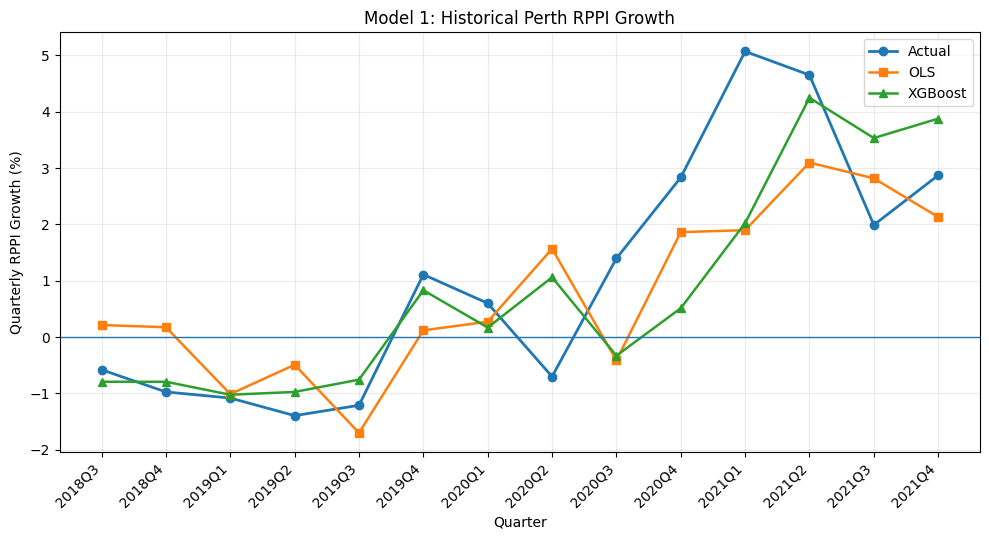

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_1__Historical_Price_Actual_vs_Predicted.png


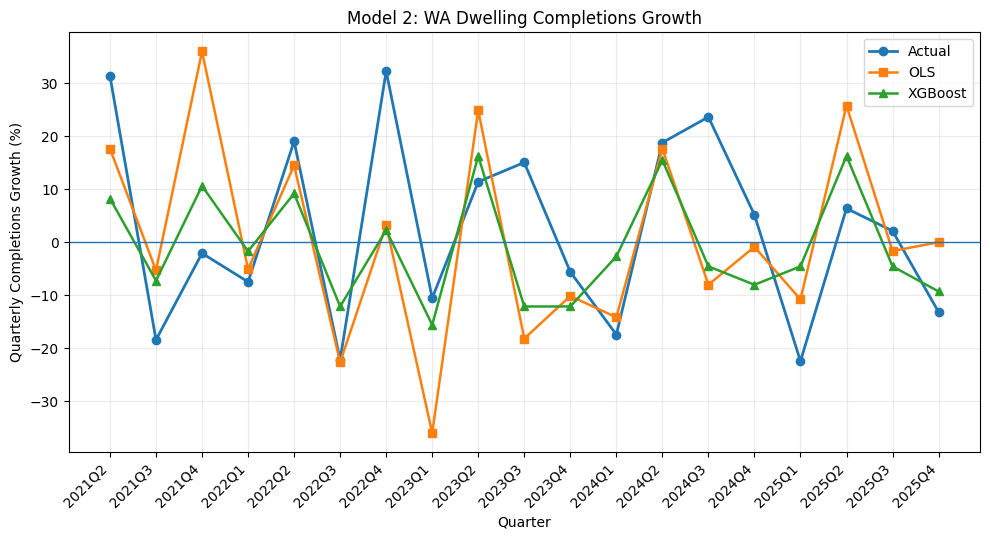

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_2__Housing_Supply_Actual_vs_Predicted.png


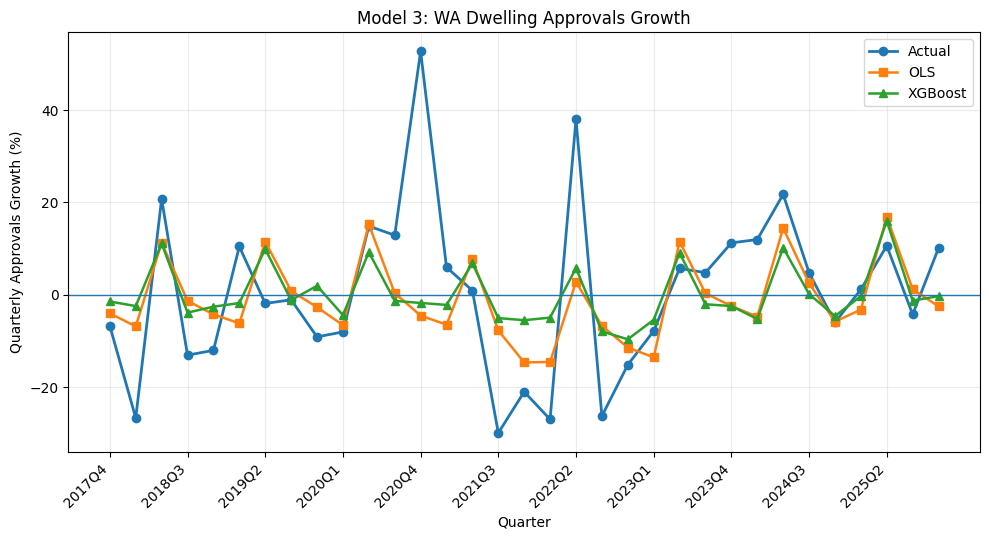

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_3__Population_and_Development_Actual_vs_Predicted.png


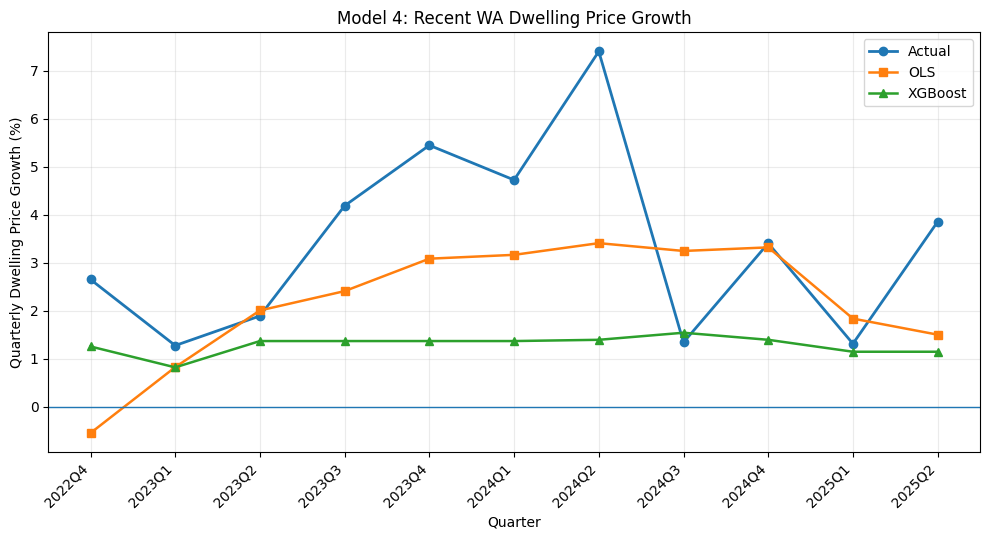

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_4__Recent_Housing_Market_Actual_vs_Predicted.png

All regression prediction figures saved.


In [ ]:
# ============================================================
# FINAL RESULTS PREPARATION — STEP 2
# ACTUAL vs OLS vs XGBOOST REGRESSION FIGURES
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Load saved prediction data
# ------------------------------------------------------------

prediction_file = os.path.join(
    CLEAN_FOLDER,
    "Final_Regression_Actual_OLS_XGBoost_Predictions.csv"
)

prediction_df = pd.read_csv(
    prediction_file
)


print("Prediction file loaded:")
print("Shape:", prediction_df.shape)

print("\nColumns:")
print(prediction_df.columns.tolist())


# ------------------------------------------------------------
# 2. Check model names
# ------------------------------------------------------------

print("\nModels:")
print(
    prediction_df["Model"]
    .value_counts()
)


# ------------------------------------------------------------
# 3. Figure titles
# ------------------------------------------------------------

figure_titles = {

    "Model 1 - Historical Price":
        "Model 1: Historical Perth RPPI Growth",

    "Model 2 - Housing Supply":
        "Model 2: WA Dwelling Completions Growth",

    "Model 3 - Population & Development":
        "Model 3: WA Dwelling Approvals Growth",

    "Model 4 - Recent Housing Market":
        "Model 4: Recent WA Dwelling Price Growth"
}


# ------------------------------------------------------------
# 4. Y-axis labels
# ------------------------------------------------------------

y_labels = {

    "Model 1 - Historical Price":
        "Quarterly RPPI Growth (%)",

    "Model 2 - Housing Supply":
        "Quarterly Completions Growth (%)",

    "Model 3 - Population & Development":
        "Quarterly Approvals Growth (%)",

    "Model 4 - Recent Housing Market":
        "Quarterly Dwelling Price Growth (%)"
}


# ------------------------------------------------------------
# 5. Generate one figure per model
# ------------------------------------------------------------

for model_name in prediction_df["Model"].unique():

    model_plot = (
        prediction_df[
            prediction_df["Model"] == model_name
        ]
        .copy()
        .reset_index(drop=True)
    )

    # ---------------------------------------------
    # Create figure
    # ---------------------------------------------

    plt.figure(
        figsize=(10, 5.5)
    )

    plt.plot(
        model_plot["Quarter"],
        model_plot["Actual"],
        marker="o",
        linewidth=2,
        label="Actual"
    )

    plt.plot(
        model_plot["Quarter"],
        model_plot["OLS_Prediction"],
        marker="s",
        linewidth=1.8,
        label="OLS"
    )

    plt.plot(
        model_plot["Quarter"],
        model_plot["XGBoost_Prediction"],
        marker="^",
        linewidth=1.8,
        label="XGBoost"
    )

    plt.axhline(
        y=0,
        linewidth=1
    )

    plt.title(
        figure_titles.get(
            model_name,
            model_name
        )
    )

    plt.xlabel(
        "Quarter"
    )

    plt.ylabel(
        y_labels.get(
            model_name,
            "Growth (%)"
        )
    )

    plt.legend()

    plt.grid(
        alpha=0.25
    )

    # Keep quarter labels readable
    step = max(
        1,
        len(model_plot) // 10
    )

    tick_positions = range(
        0,
        len(model_plot),
        step
    )

    plt.xticks(
        ticks=tick_positions,
        labels=model_plot[
            "Quarter"
        ].iloc[
            list(tick_positions)
        ],
        rotation=45,
        ha="right"
    )

    plt.tight_layout()


    # ---------------------------------------------
    # Safe filename
    # ---------------------------------------------

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("&", "and")
        .replace("-", "")
    )

    figure_file = os.path.join(
        RESULTS_FOLDER,
        f"Figure_{safe_name}_Actual_vs_Predicted.png"
    )


    # ---------------------------------------------
    # SAVE IMPORTANT FIGURE — 300 DPI
    # ---------------------------------------------

    plt.savefig(
        figure_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        "Saved:",
        figure_file
    )


print("\nAll regression prediction figures saved.")

FEATURE IMPORTANCE DATA
                             Model  Rank                           Feature  Importance
        Model 1 - Historical Price     1                    RPPI_Growth_L1      0.6844
        Model 1 - Historical Price     2             Completions_Growth_L2      0.1467
        Model 1 - Historical Price     3            d_WA_Unemployment_Rate      0.0656
        Model 1 - Historical Price     4              Population_Growth_L3      0.0552
        Model 1 - Historical Price     5                          dln_Rent      0.0482
        Model 1 - Historical Price     6            d_Housing_Lending_Rate      0.0000
          Model 2 - Housing Supply     1                               Q_2      0.4737
          Model 2 - Housing Supply     2             Completions_Growth_L1      0.3292
          Model 2 - Housing Supply     3               Approvals_Growth_L4      0.1971
          Model 2 - Housing Supply     4                 dln_WA_Population      0.0000
          Model 2 -

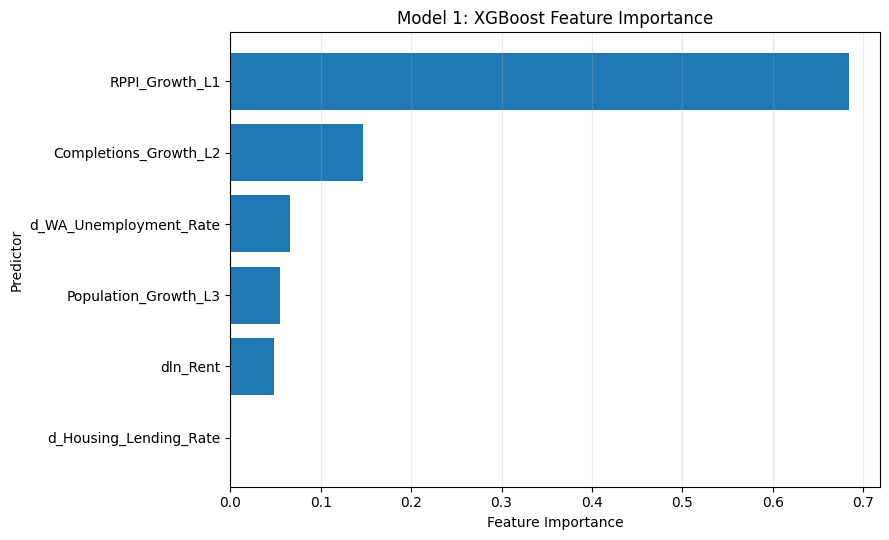

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_1__Historical_Price_XGBoost_Feature_Importance.png


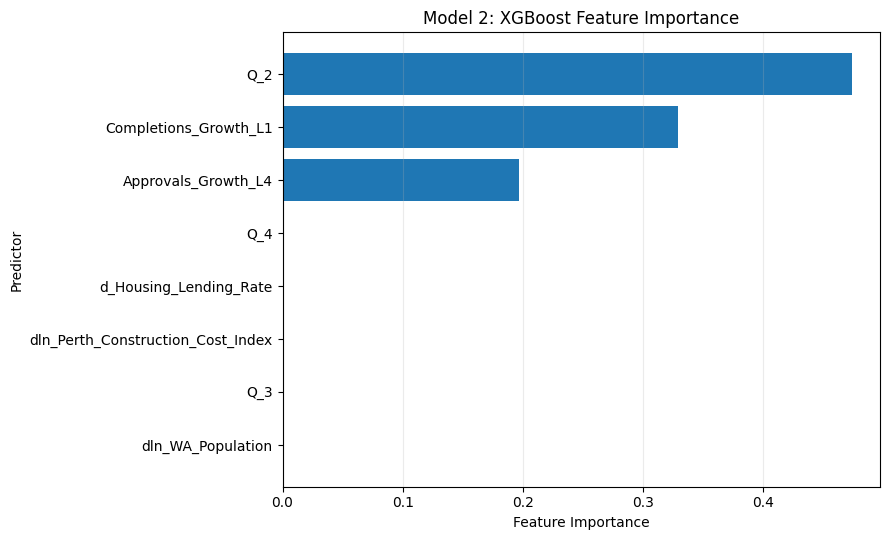

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_2__Housing_Supply_XGBoost_Feature_Importance.png


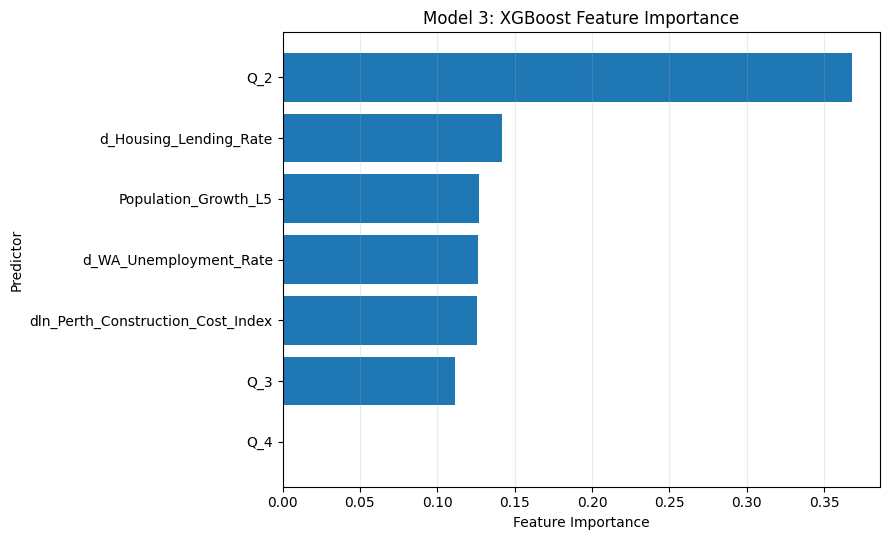

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_3__Population_and_Development_XGBoost_Feature_Importance.png


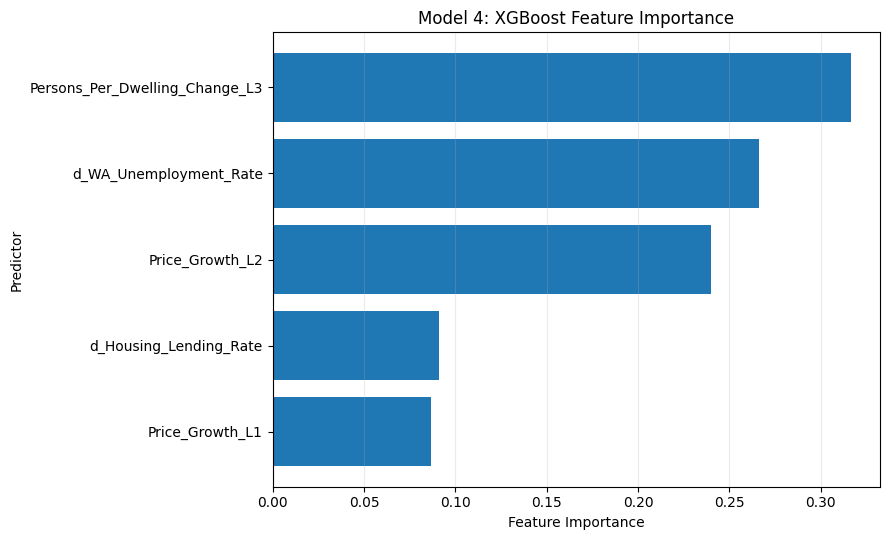

Saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Model_4__Recent_Housing_Market_XGBoost_Feature_Importance.png

All regression feature-importance figures saved.


In [ ]:
# ============================================================
# FINAL RESULTS PREPARATION — STEP 3
# XGBOOST REGRESSION FEATURE IMPORTANCE FIGURES
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Load saved feature importance
# ------------------------------------------------------------

importance_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Feature_Importance_Models_1_to_4.csv"
)

importance_df = pd.read_csv(
    importance_file
)


print("FEATURE IMPORTANCE DATA")
print("=" * 90)

print(
    importance_df
    .round(4)
    .to_string(index=False)
)

print("\nColumns:")
print(
    importance_df.columns.tolist()
)


# ------------------------------------------------------------
# 2. Save report-ready table
# ------------------------------------------------------------

importance_table_file = os.path.join(
    RESULTS_FOLDER,
    "Table_XGBoost_Regression_Feature_Importance.csv"
)

importance_df.to_csv(
    importance_table_file,
    index=False
)

print("\nTable saved:")
print(
    importance_table_file
)


# ------------------------------------------------------------
# 3. Model titles
# ------------------------------------------------------------

importance_titles = {

    "Model 1 - Historical Price":
        "Model 1: XGBoost Feature Importance",

    "Model 2 - Housing Supply":
        "Model 2: XGBoost Feature Importance",

    "Model 3 - Population & Development":
        "Model 3: XGBoost Feature Importance",

    "Model 4 - Recent Housing Market":
        "Model 4: XGBoost Feature Importance"
}


# ------------------------------------------------------------
# 4. Create one figure per model
# ------------------------------------------------------------

for model_name in importance_df["Model"].unique():

    model_imp = (
        importance_df[
            importance_df["Model"] == model_name
        ]
        .copy()
        .sort_values(
            "Importance",
            ascending=True
        )
    )


    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    plt.figure(
        figsize=(9, 5.5)
    )

    plt.barh(
        model_imp["Feature"],
        model_imp["Importance"]
    )

    plt.title(
        importance_titles.get(
            model_name,
            model_name
        )
    )

    plt.xlabel(
        "Feature Importance"
    )

    plt.ylabel(
        "Predictor"
    )

    plt.grid(
        axis="x",
        alpha=0.25
    )

    plt.tight_layout()


    # --------------------------------------------------------
    # Safe filename
    # --------------------------------------------------------

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("&", "and")
        .replace("-", "")
    )

    figure_file = os.path.join(
        RESULTS_FOLDER,
        f"Figure_{safe_name}_XGBoost_Feature_Importance.png"
    )


    # --------------------------------------------------------
    # SAVE — 300 DPI
    # --------------------------------------------------------

    plt.savefig(
        figure_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        "Saved:",
        figure_file
    )


print(
    "\nAll regression feature-importance figures saved."
)

CLASSIFICATION MODEL COMPARISON
              Model  Accuracy  Balanced_Accuracy  Precision  Recall     F1  ROC_AUC  TN  FP  FN  TP
Always-UP Benchmark    0.7419             0.5000     0.7419  1.0000 0.8519      NaN   0   8   0  23
Logistic Regression    0.6774             0.5380     0.7600  0.8261 0.7917   0.5707   2   6   4  19
      Random Forest    0.7419             0.5408     0.7586  0.9565 0.8462   0.7446   1   7   1  22
          SVM (RBF)    0.7419             0.6630     0.8261  0.8261 0.8261   0.7011   4   4   4  19
  Gradient Boosting    0.7419             0.6630     0.8261  0.8261 0.8261   0.6250   4   4   4  19
            XGBoost    0.7742             0.7663     0.9000  0.7826 0.8372   0.7880   6   2   5  18

Comparison table saved:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Table_Classification_Model_Performance.csv

XGBOOST CONFUSION MATRIX
[[ 6  2]
 [ 5 18]]

TN: 6
FP: 2
FN: 5
TP: 18

Confusion matrix table saved:
/content/drive/MyDrive/WA_Housing_Project/

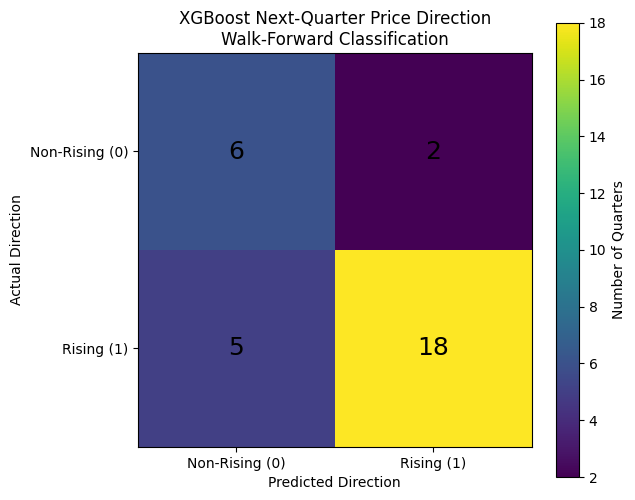


Confusion matrix figure saved:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_XGBoost_Classification_Confusion_Matrix.png


In [ ]:
# ============================================================
# FINAL RESULTS PREPARATION — STEP 4
# CLASSIFICATION TABLE + CONFUSION MATRIX
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix


# ------------------------------------------------------------
# 1. Load saved classification comparison
# ------------------------------------------------------------

comparison_file = os.path.join(
    CLEAN_FOLDER,
    "Final_Classification_Model_Comparison.csv"
)

classification_comparison = pd.read_csv(
    comparison_file
)


print("CLASSIFICATION MODEL COMPARISON")
print("=" * 110)

print(
    classification_comparison
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 2. Save report-ready comparison table
# ------------------------------------------------------------

comparison_output = os.path.join(
    RESULTS_FOLDER,
    "Table_Classification_Model_Performance.csv"
)

classification_comparison.to_csv(
    comparison_output,
    index=False
)

print("\nComparison table saved:")
print(comparison_output)


# ------------------------------------------------------------
# 3. Load final XGBoost walk-forward predictions
# ------------------------------------------------------------

prediction_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Classification_WalkForward_Predictions.csv"
)

class_predictions = pd.read_csv(
    prediction_file
)


# ------------------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    class_predictions["Actual_Direction"],
    class_predictions["Predicted_Direction"],
    labels=[0, 1]
)

print("\nXGBOOST CONFUSION MATRIX")
print("=" * 50)

print(cm)

print("\nTN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])


# ------------------------------------------------------------
# 5. Save confusion-matrix values as CSV
# ------------------------------------------------------------

cm_table = pd.DataFrame(
    cm,
    index=[
        "Actual Non-Rising",
        "Actual Rising"
    ],
    columns=[
        "Predicted Non-Rising",
        "Predicted Rising"
    ]
)

cm_csv_file = os.path.join(
    RESULTS_FOLDER,
    "Table_XGBoost_Classification_Confusion_Matrix.csv"
)

cm_table.to_csv(
    cm_csv_file
)

print("\nConfusion matrix table saved:")
print(cm_csv_file)


# ------------------------------------------------------------
# 6. Create confusion matrix figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6.5, 5.5)
)

image_plot = ax.imshow(
    cm
)

# Cell values
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=18
        )


ax.set_xticks(
    [0, 1]
)

ax.set_yticks(
    [0, 1]
)

ax.set_xticklabels(
    [
        "Non-Rising (0)",
        "Rising (1)"
    ]
)

ax.set_yticklabels(
    [
        "Non-Rising (0)",
        "Rising (1)"
    ]
)

ax.set_xlabel(
    "Predicted Direction"
)

ax.set_ylabel(
    "Actual Direction"
)

ax.set_title(
    "XGBoost Next-Quarter Price Direction\n"
    "Walk-Forward Classification"
)

fig.colorbar(
    image_plot,
    ax=ax,
    label="Number of Quarters"
)

plt.tight_layout()


# ------------------------------------------------------------
# 7. SAVE FIGURE — 300 DPI
# ------------------------------------------------------------

cm_figure_file = os.path.join(
    RESULTS_FOLDER,
    "Figure_XGBoost_Classification_Confusion_Matrix.png"
)

plt.savefig(
    cm_figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


print("\nConfusion matrix figure saved:")
print(cm_figure_file)

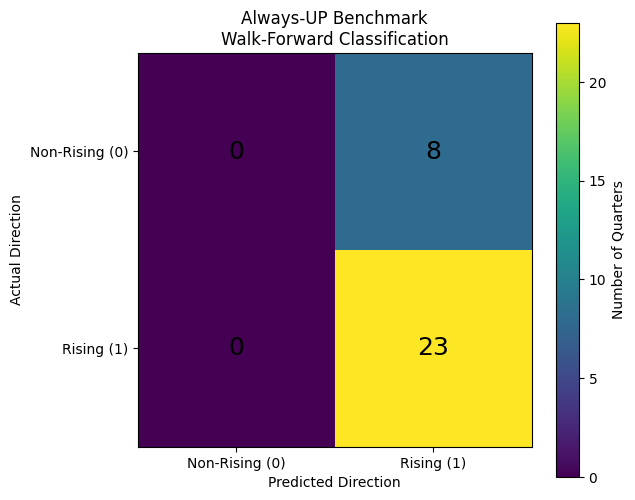

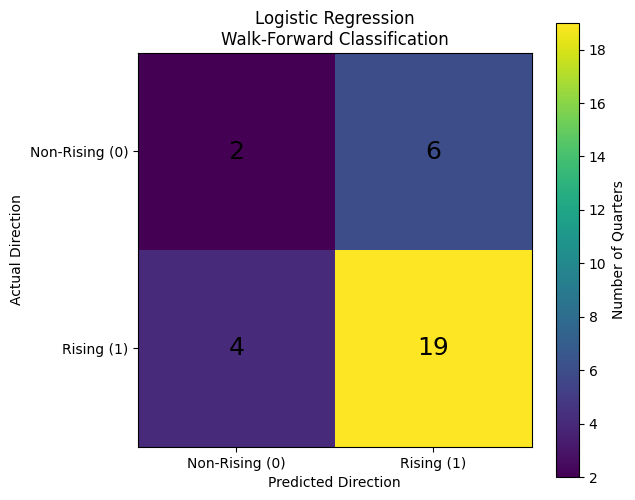

Logistic Regression saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Classification_CM_Logistic_Regression.png


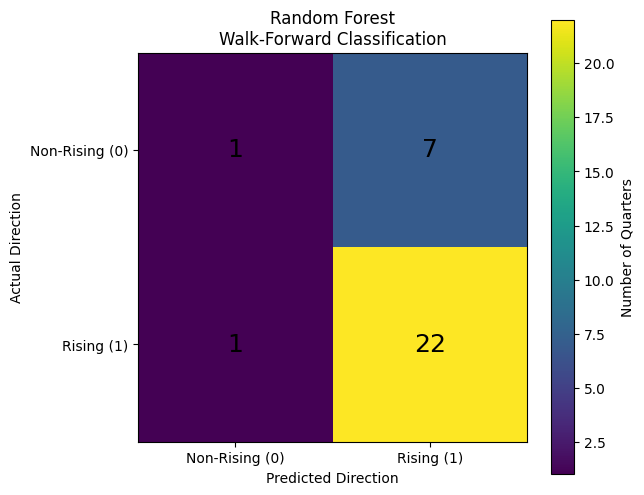

Random Forest saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Classification_CM_Random_Forest.png


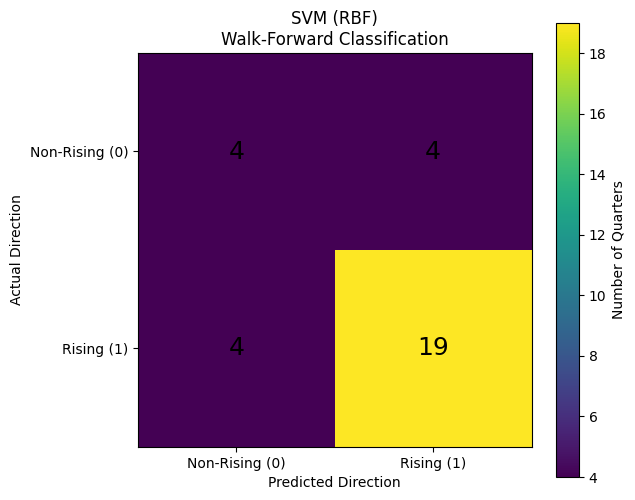

SVM (RBF) saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Classification_CM_SVM_RBF.png


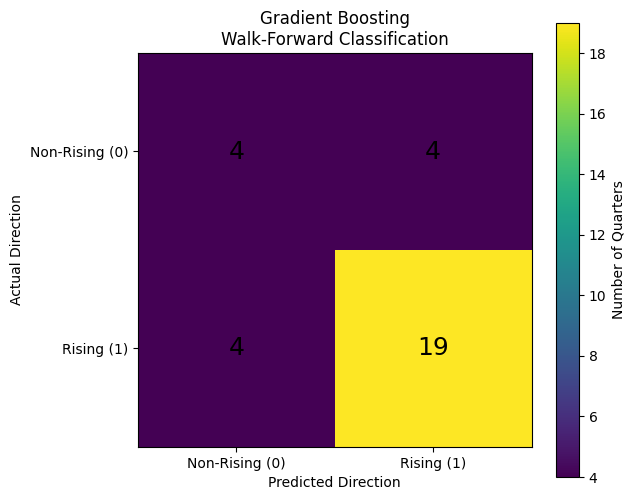

Gradient Boosting saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Classification_CM_Gradient_Boosting.png


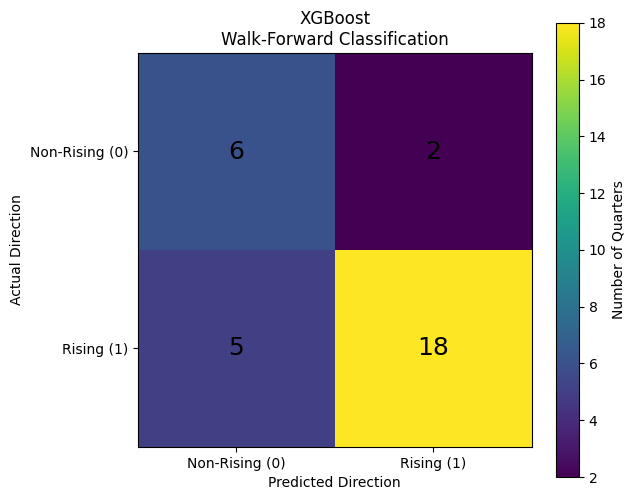

XGBoost saved: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_Classification_CM_XGBoost.png

ALL CLASSIFICATION CONFUSION MATRICES
              Model  TN  FP  FN  TP
Always-UP Benchmark   0   8   0  23
Logistic Regression   2   6   4  19
      Random Forest   1   7   1  22
          SVM (RBF)   4   4   4  19
  Gradient Boosting   4   4   4  19
            XGBoost   6   2   5  18

Saved summary:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Table_All_Classification_Confusion_Matrices.csv

Saved all predictions:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/All_Classification_WalkForward_Predictions.csv


In [ ]:
# ============================================================
# FINAL RESULTS — CONFUSION MATRICES FOR ALL CLASSIFIERS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import confusion_matrix

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


# ------------------------------------------------------------
# 1. Final/best configurations
# ------------------------------------------------------------

final_models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
        )
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=2,
        class_weight="balanced",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "SVM (RBF)": Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            SVC(
                kernel="rbf",
                C=0.5,
                gamma=0.01,
                class_weight="balanced",
                probability=True,
                random_state=42
            )
        )
    ]),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=50,
        learning_rate=0.03,
        max_depth=2,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=150,
        learning_rate=0.03,
        max_depth=1,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1
    )
}


# ------------------------------------------------------------
# 2. Storage
# ------------------------------------------------------------

all_cm_results = []

all_prediction_results = []


# ------------------------------------------------------------
# 3. Always-UP benchmark first
# ------------------------------------------------------------

benchmark_actual = (
    y_class.iloc[
        INITIAL_TRAIN_SIZE:
    ]
    .astype(int)
    .values
)

benchmark_pred = np.ones(
    len(benchmark_actual),
    dtype=int
)

benchmark_quarters = (
    quarters_class.iloc[
        INITIAL_TRAIN_SIZE:
    ]
    .values
)

benchmark_cm = confusion_matrix(
    benchmark_actual,
    benchmark_pred,
    labels=[0, 1]
)

all_cm_results.append({
    "Model": "Always-UP Benchmark",
    "TN": benchmark_cm[0, 0],
    "FP": benchmark_cm[0, 1],
    "FN": benchmark_cm[1, 0],
    "TP": benchmark_cm[1, 1]
})


# ------------------------------------------------------------
# 4. Benchmark figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6.5, 5.5)
)

im = ax.imshow(
    benchmark_cm
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(benchmark_cm[i, j]),
            ha="center",
            va="center",
            fontsize=18
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Non-Rising (0)",
    "Rising (1)"
])

ax.set_yticklabels([
    "Non-Rising (0)",
    "Rising (1)"
])

ax.set_xlabel(
    "Predicted Direction"
)

ax.set_ylabel(
    "Actual Direction"
)

ax.set_title(
    "Always-UP Benchmark\n"
    "Walk-Forward Classification"
)

fig.colorbar(
    im,
    ax=ax,
    label="Number of Quarters"
)

plt.tight_layout()

benchmark_figure = os.path.join(
    RESULTS_FOLDER,
    "Figure_Classification_CM_Always_UP_Benchmark.png"
)

plt.savefig(
    benchmark_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ------------------------------------------------------------
# 5. Run each actual classifier
# ------------------------------------------------------------

for model_name, model in final_models.items():

    actual, pred, prob, pred_quarters = (
        walk_forward_classification(
            model,
            X_class,
            y_class,
            quarters_class,
            INITIAL_TRAIN_SIZE
        )
    )

    cm = confusion_matrix(
        actual,
        pred,
        labels=[0, 1]
    )

    # ---------------------------------------------
    # Store confusion matrix values
    # ---------------------------------------------

    all_cm_results.append({

        "Model": model_name,

        "TN": cm[0, 0],

        "FP": cm[0, 1],

        "FN": cm[1, 0],

        "TP": cm[1, 1]
    })


    # ---------------------------------------------
    # Store quarter-level predictions
    # ---------------------------------------------

    model_predictions = pd.DataFrame({

        "Model": model_name,

        "Predictor_Quarter":
            pred_quarters,

        "Actual_Direction":
            actual,

        "Predicted_Direction":
            pred,

        "Probability_Up":
            prob
    })

    all_prediction_results.append(
        model_predictions
    )


    # ---------------------------------------------
    # Create confusion matrix figure
    # ---------------------------------------------

    fig, ax = plt.subplots(
        figsize=(6.5, 5.5)
    )

    im = ax.imshow(
        cm
    )

    for i in range(2):
        for j in range(2):

            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=18
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels([
        "Non-Rising (0)",
        "Rising (1)"
    ])

    ax.set_yticklabels([
        "Non-Rising (0)",
        "Rising (1)"
    ])

    ax.set_xlabel(
        "Predicted Direction"
    )

    ax.set_ylabel(
        "Actual Direction"
    )

    ax.set_title(
        f"{model_name}\n"
        "Walk-Forward Classification"
    )

    fig.colorbar(
        im,
        ax=ax,
        label="Number of Quarters"
    )

    plt.tight_layout()


    # ---------------------------------------------
    # Save important figure
    # ---------------------------------------------

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    figure_file = os.path.join(
        RESULTS_FOLDER,
        f"Figure_Classification_CM_{safe_name}.png"
    )

    plt.savefig(
        figure_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print(
        model_name,
        "saved:",
        figure_file
    )


# ------------------------------------------------------------
# 6. Save confusion-matrix summary table
# ------------------------------------------------------------

all_cm_df = pd.DataFrame(
    all_cm_results
)

cm_summary_file = os.path.join(
    RESULTS_FOLDER,
    "Table_All_Classification_Confusion_Matrices.csv"
)

all_cm_df.to_csv(
    cm_summary_file,
    index=False
)


# ------------------------------------------------------------
# 7. Save all model predictions
# ------------------------------------------------------------

all_classification_predictions = pd.concat(
    all_prediction_results,
    ignore_index=True
)

prediction_output_file = os.path.join(
    RESULTS_FOLDER,
    "All_Classification_WalkForward_Predictions.csv"
)

all_classification_predictions.to_csv(
    prediction_output_file,
    index=False
)


# ------------------------------------------------------------
# 8. Display summary
# ------------------------------------------------------------

print("\nALL CLASSIFICATION CONFUSION MATRICES")
print("=" * 80)

print(
    all_cm_df.to_string(
        index=False
    )
)

print("\nSaved summary:")
print(cm_summary_file)

print("\nSaved all predictions:")
print(prediction_output_file)

XGBOOST CLASSIFICATION PROBABILITY TIMELINE
Predicted_Quarter  Actual_Direction  Predicted_Direction  Probability_Price_Up  Correct
           2017Q4                 1                    0                0.4676    False
           2018Q1                 0                    0                0.4935     True
           2018Q2                 0                    0                0.4721     True
           2018Q3                 1                    0                0.4507    False
           2018Q4                 0                    0                0.4733     True
           2019Q1                 0                    0                0.4547     True
           2019Q2                 0                    0                0.4454     True
           2019Q3                 1                    0                0.4372    False
           2019Q4                 0                    0                0.4973     True
           2020Q1                 1                    1                0.51

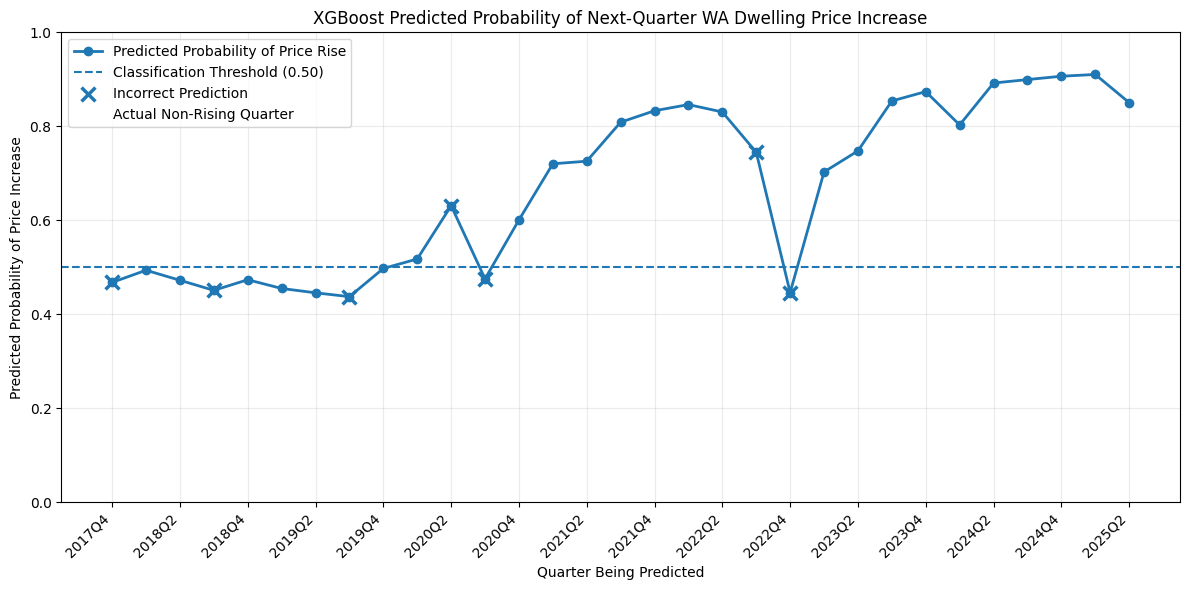


Probability timeline figure saved:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_XGBoost_Classification_Probability_Timeline.png


In [ ]:
# ============================================================
# FINAL RESULTS PREPARATION — STEP 5
# XGBOOST PRICE-DIRECTION PROBABILITY TIMELINE
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Load FINAL selected XGBoost predictions
# ------------------------------------------------------------

xgb_prediction_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Classification_WalkForward_Predictions.csv"
)

xgb_timeline = pd.read_csv(
    xgb_prediction_file
)


# ------------------------------------------------------------
# 2. Convert to the quarter actually being predicted
# ------------------------------------------------------------

xgb_timeline["Predicted_Quarter"] = (
    pd.PeriodIndex(
        xgb_timeline["Predictor_Quarter"],
        freq="Q"
    ) + 1
).astype(str)


# ------------------------------------------------------------
# 3. Correct / incorrect indicator
# ------------------------------------------------------------

xgb_timeline["Correct"] = (
    xgb_timeline["Actual_Direction"]
    ==
    xgb_timeline["Predicted_Direction"]
)


# ------------------------------------------------------------
# 4. Display data
# ------------------------------------------------------------

print("XGBOOST CLASSIFICATION PROBABILITY TIMELINE")
print("=" * 95)

print(
    xgb_timeline[
        [
            "Predicted_Quarter",
            "Actual_Direction",
            "Predicted_Direction",
            "Probability_Price_Up",
            "Correct"
        ]
    ]
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 5. Save report-ready timeline table
# ------------------------------------------------------------

timeline_table_file = os.path.join(
    RESULTS_FOLDER,
    "Table_XGBoost_Classification_Probability_Timeline.csv"
)

xgb_timeline.to_csv(
    timeline_table_file,
    index=False
)

print("\nTimeline table saved:")
print(timeline_table_file)


# ------------------------------------------------------------
# 6. Create timeline figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 6)
)


# Probability line
ax.plot(
    xgb_timeline["Predicted_Quarter"],
    xgb_timeline["Probability_Price_Up"],
    marker="o",
    linewidth=2,
    label="Predicted Probability of Price Rise"
)


# Classification threshold
ax.axhline(
    y=0.50,
    linestyle="--",
    linewidth=1.5,
    label="Classification Threshold (0.50)"
)


# ------------------------------------------------------------
# 7. Mark incorrect predictions
# ------------------------------------------------------------

incorrect = xgb_timeline[
    ~xgb_timeline["Correct"]
]

ax.scatter(
    incorrect["Predicted_Quarter"],
    incorrect["Probability_Price_Up"],
    marker="x",
    s=100,
    linewidths=2.5,
    label="Incorrect Prediction",
    zorder=5
)


# ------------------------------------------------------------
# 8. Actual non-rising quarters
# ------------------------------------------------------------

actual_down = xgb_timeline[
    xgb_timeline["Actual_Direction"] == 0
]

ax.scatter(
    actual_down["Predicted_Quarter"],
    actual_down["Probability_Price_Up"],
    marker="s",
    s=75,
    facecolors="none",
    linewidths=2,
    label="Actual Non-Rising Quarter",
    zorder=4
)


# ------------------------------------------------------------
# 9. Formatting
# ------------------------------------------------------------

ax.set_title(
    "XGBoost Predicted Probability of Next-Quarter "
    "WA Dwelling Price Increase"
)

ax.set_xlabel(
    "Quarter Being Predicted"
)

ax.set_ylabel(
    "Predicted Probability of Price Increase"
)

ax.set_ylim(
    0,
    1
)

ax.grid(
    alpha=0.25
)

ax.legend(
    loc="best"
)


# Reduce number of x labels
step = max(
    1,
    len(xgb_timeline) // 12
)

tick_positions = range(
    0,
    len(xgb_timeline),
    step
)

ax.set_xticks(
    list(tick_positions)
)

ax.set_xticklabels(
    xgb_timeline[
        "Predicted_Quarter"
    ].iloc[
        list(tick_positions)
    ],
    rotation=45,
    ha="right"
)

plt.tight_layout()


# ------------------------------------------------------------
# 10. SAVE IMPORTANT FIGURE — 300 DPI
# ------------------------------------------------------------

timeline_figure_file = os.path.join(
    RESULTS_FOLDER,
    "Figure_XGBoost_Classification_Probability_Timeline.png"
)

plt.savefig(
    timeline_figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


print("\nProbability timeline figure saved:")
print(timeline_figure_file)

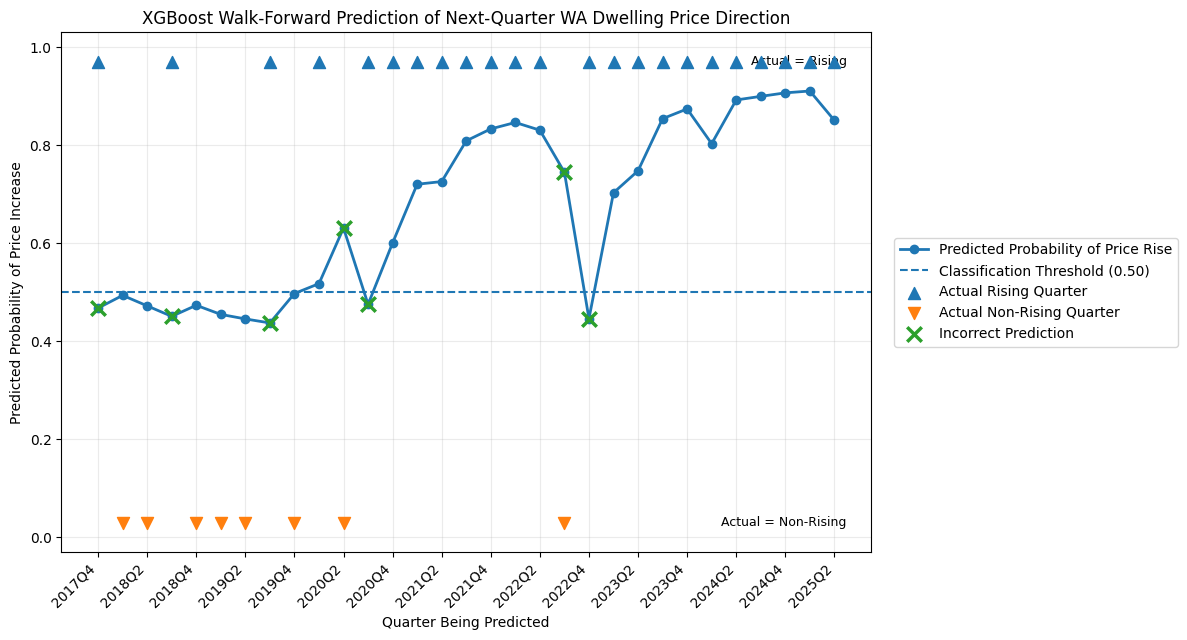

FINAL FIGURE SAVED:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_XGBoost_Classification_Probability_Timeline_FINAL.png

FINAL TABLE SAVED:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Table_XGBoost_Classification_Probability_Timeline_FINAL.csv

Forecast period: 2017Q4 to 2025Q2
Incorrect predictions: 7 of 31


In [ ]:
# ============================================================
# FINAL RESULTS — IMPROVED CLASSIFICATION PROBABILITY TIMELINE
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Load final XGBoost walk-forward predictions
# ------------------------------------------------------------

xgb_prediction_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Classification_WalkForward_Predictions.csv"
)

xgb_timeline = pd.read_csv(
    xgb_prediction_file
)


# ------------------------------------------------------------
# 2. Quarter actually being predicted
# ------------------------------------------------------------

xgb_timeline["Predicted_Quarter"] = (
    pd.PeriodIndex(
        xgb_timeline["Predictor_Quarter"],
        freq="Q"
    ) + 1
).astype(str)


# ------------------------------------------------------------
# 3. Correct / incorrect
# ------------------------------------------------------------

xgb_timeline["Correct"] = (
    xgb_timeline["Actual_Direction"]
    ==
    xgb_timeline["Predicted_Direction"]
)


# ------------------------------------------------------------
# 4. Separate actual UP and NON-RISING quarters
# ------------------------------------------------------------

actual_up = xgb_timeline[
    xgb_timeline["Actual_Direction"] == 1
].copy()

actual_non_rising = xgb_timeline[
    xgb_timeline["Actual_Direction"] == 0
].copy()

incorrect = xgb_timeline[
    xgb_timeline["Correct"] == False
].copy()


# ------------------------------------------------------------
# 5. Numerical x-axis
# ------------------------------------------------------------

x = np.arange(
    len(xgb_timeline)
)

up_positions = x[
    xgb_timeline["Actual_Direction"].values == 1
]

non_rising_positions = x[
    xgb_timeline["Actual_Direction"].values == 0
]

incorrect_positions = x[
    xgb_timeline["Correct"].values == False
]


# ------------------------------------------------------------
# 6. Create improved figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 6.5)
)


# Predicted probability
ax.plot(
    x,
    xgb_timeline["Probability_Price_Up"],
    marker="o",
    linewidth=2,
    label="Predicted Probability of Price Rise"
)


# Classification threshold
ax.axhline(
    y=0.50,
    linestyle="--",
    linewidth=1.5,
    label="Classification Threshold (0.50)"
)


# ------------------------------------------------------------
# 7. Show ACTUAL outcomes separately
# ------------------------------------------------------------

# Actual rising quarter
ax.scatter(
    up_positions,
    np.full(
        len(up_positions),
        0.97
    ),
    marker="^",
    s=75,
    label="Actual Rising Quarter",
    zorder=5
)


# Actual non-rising quarter
ax.scatter(
    non_rising_positions,
    np.full(
        len(non_rising_positions),
        0.03
    ),
    marker="v",
    s=75,
    label="Actual Non-Rising Quarter",
    zorder=5
)


# ------------------------------------------------------------
# 8. Incorrect predictions
# ------------------------------------------------------------

ax.scatter(
    incorrect_positions,
    xgb_timeline.loc[
        ~xgb_timeline["Correct"],
        "Probability_Price_Up"
    ],
    marker="x",
    s=110,
    linewidths=2.5,
    label="Incorrect Prediction",
    zorder=6
)


# ------------------------------------------------------------
# 9. Formatting
# ------------------------------------------------------------

ax.set_title(
    "XGBoost Walk-Forward Prediction of "
    "Next-Quarter WA Dwelling Price Direction"
)

ax.set_xlabel(
    "Quarter Being Predicted"
)

ax.set_ylabel(
    "Predicted Probability of Price Increase"
)

ax.set_ylim(
    -0.03,
    1.03
)

ax.grid(
    alpha=0.25
)


# ------------------------------------------------------------
# 10. Quarter labels
# ------------------------------------------------------------

step = 2

tick_positions = np.arange(
    0,
    len(xgb_timeline),
    step
)

ax.set_xticks(
    tick_positions
)

ax.set_xticklabels(
    xgb_timeline[
        "Predicted_Quarter"
    ].iloc[
        tick_positions
    ],
    rotation=45,
    ha="right"
)


# ------------------------------------------------------------
# 11. Explain top/bottom actual markers
# ------------------------------------------------------------

ax.text(
    len(xgb_timeline) - 0.5,
    0.97,
    "Actual = Rising",
    ha="right",
    va="center",
    fontsize=9
)

ax.text(
    len(xgb_timeline) - 0.5,
    0.03,
    "Actual = Non-Rising",
    ha="right",
    va="center",
    fontsize=9
)


# ------------------------------------------------------------
# 12. Legend
# ------------------------------------------------------------

ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

plt.tight_layout()


# ------------------------------------------------------------
# 13. SAVE FINAL FIGURE — 300 DPI
# ------------------------------------------------------------

timeline_figure_file = os.path.join(
    RESULTS_FOLDER,
    "Figure_XGBoost_Classification_Probability_Timeline_FINAL.png"
)

plt.savefig(
    timeline_figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 14. SAVE IMPORTANT UNDERLYING TABLE
# ------------------------------------------------------------

timeline_table_file = os.path.join(
    RESULTS_FOLDER,
    "Table_XGBoost_Classification_Probability_Timeline_FINAL.csv"
)

xgb_timeline.to_csv(
    timeline_table_file,
    index=False
)


print("FINAL FIGURE SAVED:")
print(timeline_figure_file)

print("\nFINAL TABLE SAVED:")
print(timeline_table_file)

print(
    "\nForecast period:",
    xgb_timeline["Predicted_Quarter"].iloc[0],
    "to",
    xgb_timeline["Predicted_Quarter"].iloc[-1]
)

print(
    "Incorrect predictions:",
    int((~xgb_timeline["Correct"]).sum()),
    "of",
    len(xgb_timeline)
)

XGBOOST CLASSIFICATION FEATURE IMPORTANCE
                       Feature  Importance
                  NIM_per_1000      0.2590
Persons_Per_Dwelling_Change_L3      0.1781
          dln_Perth_Rent_Index      0.1399
Persons_Per_Dwelling_Change_L2      0.1112
Persons_Per_Dwelling_Change_L1      0.0755
        d_WA_Unemployment_Rate      0.0597
dln_WA_Mean_Dwelling_Price_000      0.0462
               Price_Growth_L2      0.0400
                  NOM_per_1000      0.0362
               Price_Growth_L1      0.0314
             dln_WA_Population      0.0228
        d_Persons_Per_Dwelling      0.0000
        d_Housing_Lending_Rate      0.0000


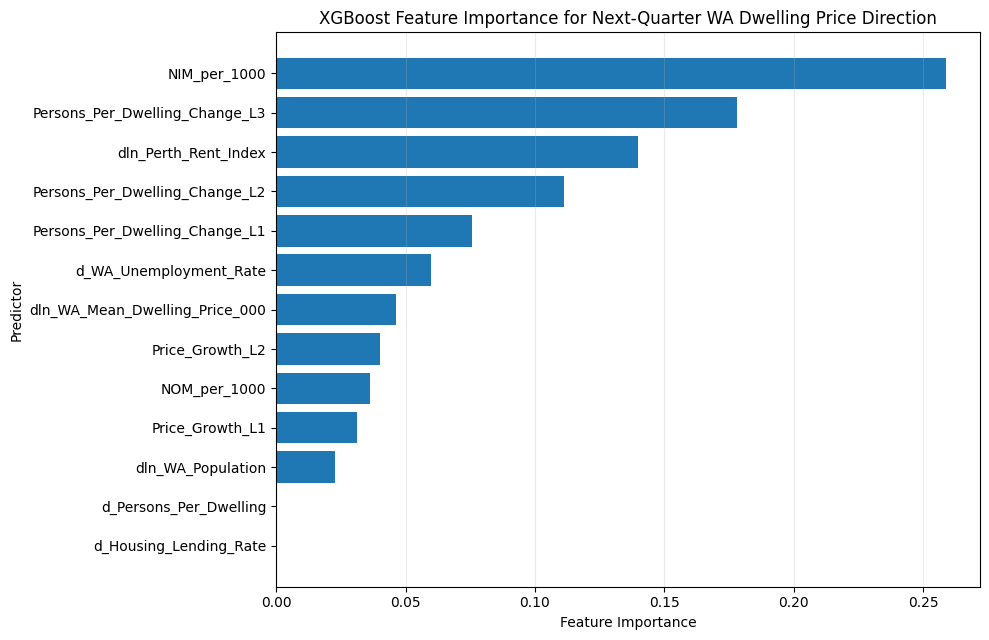


TABLE SAVED:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Table_XGBoost_Classification_Feature_Importance.csv

FIGURE SAVED:
/content/drive/MyDrive/WA_Housing_Project/Final_Results/Figure_XGBoost_Classification_Feature_Importance.png


In [ ]:
# ============================================================
# FINAL RESULTS PREPARATION — STEP 6
# CLASSIFICATION FEATURE IMPORTANCE
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Load saved feature importance
# ------------------------------------------------------------

importance_file = os.path.join(
    CLEAN_FOLDER,
    "Final_XGBoost_Classification_Feature_Importance.csv"
)

class_importance = pd.read_csv(
    importance_file
)


# ------------------------------------------------------------
# 2. Display
# ------------------------------------------------------------

print(
    "XGBOOST CLASSIFICATION FEATURE IMPORTANCE"
)

print("=" * 75)

print(
    class_importance
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 3. Save report-ready table
# ------------------------------------------------------------

importance_table_file = os.path.join(
    RESULTS_FOLDER,
    "Table_XGBoost_Classification_Feature_Importance.csv"
)

class_importance.to_csv(
    importance_table_file,
    index=False
)


# ------------------------------------------------------------
# 4. Sort for horizontal figure
# ------------------------------------------------------------

plot_importance = (
    class_importance
    .sort_values(
        "Importance",
        ascending=True
    )
)


# ------------------------------------------------------------
# 5. Figure
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6.5)
)

plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance"]
)

plt.title(
    "XGBoost Feature Importance for "
    "Next-Quarter WA Dwelling Price Direction"
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Predictor"
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()


# ------------------------------------------------------------
# 6. Save important figure — 300 DPI
# ------------------------------------------------------------

importance_figure_file = os.path.join(
    RESULTS_FOLDER,
    "Figure_XGBoost_Classification_Feature_Importance.png"
)

plt.savefig(
    importance_figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ------------------------------------------------------------
# 7. Confirm saved files
# ------------------------------------------------------------

print("\nTABLE SAVED:")
print(importance_table_file)

print("\nFIGURE SAVED:")
print(importance_figure_file)


In [ ]:
# ============================================================
# FINAL RESULTS PREPARATION — STEP 7
# CONSOLIDATED MODELLING RESULTS SUMMARY
# ============================================================

import os
import pandas as pd


# ------------------------------------------------------------
# 1. Construct consolidated summary
# ------------------------------------------------------------

final_model_summary = pd.DataFrame([

    {
        "Component":
            "Model 1 - Historical Price",

        "Outcome":
            "Perth RPPI quarterly growth",

        "Model_Period":
            "2004Q3-2021Q4",

        "N":
            70,

        "Key_Statistical_Result":
            "Lagged RPPI growth was the dominant statistical predictor",

        "Key_Estimate":
            "RPPI Growth L1 = +0.8066",

        "Statistical_Significance":
            "p < 0.001 (HC3)",

        "OLS_Adjusted_R2":
            0.609,

        "Validation_Period":
            "2018Q3-2021Q4",

        "OLS_MAE":
            1.1477,

        "OLS_RMSE":
            1.3934,

        "XGB_MAE":
            0.9894,

        "XGB_RMSE":
            1.3378,

        "XGB_Test_R2":
            0.5979,

        "Predictive_Comparison":
            "XGBoost lower MAE and RMSE",

        "Main_Interpretation":
            "Strong short-term price momentum; XGBoost provided a modest forecasting improvement."
    },


    {
        "Component":
            "Model 2 - Housing Supply",

        "Outcome":
            "WA dwelling completions quarterly growth",

        "Model_Period":
            "2002Q4-2025Q4",

        "N":
            93,

        "Key_Statistical_Result":
            "Quarterly seasonality and lagged completions dominated",

        "Key_Estimate":
            "Completions Growth L1 = -0.3925; Q2 = +26.5793",

        "Statistical_Significance":
            "Both p < 0.001",

        "OLS_Adjusted_R2":
            0.556,

        "Validation_Period":
            "2021Q2-2025Q4",

        "OLS_MAE":
            14.1109,

        "OLS_RMSE":
            18.3271,

        "XGB_MAE":
            12.8422,

        "XGB_RMSE":
            15.3131,

        "XGB_Test_R2":
            0.2088,

        "Predictive_Comparison":
            "XGBoost lower MAE and RMSE",

        "Main_Interpretation":
            "Supply growth showed strong quarterly seasonality and short-term reversal behaviour."
    },


    {
        "Component":
            "Model 3 - Population & Development",

        "Outcome":
            "WA dwelling approvals quarterly growth",

        "Model_Period":
            "1985Q1-2025Q4",

        "N":
            164,

        "Key_Statistical_Result":
            "Population growth at lag 5 was positively associated with approvals growth",

        "Key_Estimate":
            "Population Growth L5 = +11.0687",

        "Statistical_Significance":
            "HC3 p = 0.041",

        "OLS_Adjusted_R2":
            0.258,

        "Validation_Period":
            "2017Q4-2025Q4",

        "OLS_MAE":
            11.0675,

        "OLS_RMSE":
            15.5772,

        "XGB_MAE":
            11.6608,

        "XGB_RMSE":
            15.7755,

        "XGB_Test_R2":
            0.2204,

        "Predictive_Comparison":
            "OLS slightly lower MAE and RMSE",

        "Main_Interpretation":
            "Stronger population growth was associated with stronger approvals growth around five quarters later."
    },


    {
        "Component":
            "Model 4 - Recent Housing Market",

        "Outcome":
            "WA mean dwelling price quarterly growth",

        "Model_Period":
            "2012Q3-2025Q2",

        "N":
            52,

        "Key_Statistical_Result":
            "Lagged persons-per-dwelling pressure showed the strongest relationship",

        "Key_Estimate":
            "Persons-per-Dwelling Change L3 = +170.4341",

        "Statistical_Significance":
            "p < 0.001",

        "OLS_Adjusted_R2":
            0.513,

        "Validation_Period":
            "2022Q4-2025Q2",

        "OLS_MAE":
            1.6657,

        "OLS_RMSE":
            2.0673,

        "XGB_MAE":
            2.1564,

        "XGB_RMSE":
            2.7928,

        "XGB_Test_R2":
            -1.2155,

        "Predictive_Comparison":
            "OLS lower MAE and RMSE",

        "Main_Interpretation":
            "Greater population pressure relative to dwelling stock was associated with stronger subsequent price growth."
    },


    {
        "Component":
            "Classification - Next-Quarter Direction",

        "Outcome":
            "Next-quarter WA dwelling price direction",

        "Model_Period":
            "2012Q3-2025Q1",

        "N":
            51,

        "Key_Statistical_Result":
            "XGBoost provided the strongest balanced direction classification",

        "Key_Estimate":
            "24 of 31 walk-forward predictions correct",

        "Statistical_Significance":
            "Not applicable",

        "OLS_Adjusted_R2":
            None,

        "Validation_Period":
            "2017Q4-2025Q2",

        "OLS_MAE":
            None,

        "OLS_RMSE":
            None,

        "XGB_MAE":
            None,

        "XGB_RMSE":
            None,

        "XGB_Test_R2":
            None,

        "Predictive_Comparison":
            "XGBoost: Accuracy 77.42%; Balanced Accuracy 76.63%; ROC-AUC 0.788",

        "Main_Interpretation":
            "The classifier identified 6 of 8 non-rising quarters and 18 of 23 rising quarters."
    }

])


# ------------------------------------------------------------
# 2. Display
# ------------------------------------------------------------

print(
    "FINAL CONSOLIDATED MODELLING RESULTS"
)

print("=" * 150)

print(
    final_model_summary
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 3. Save full detailed table
# ------------------------------------------------------------

summary_file = os.path.join(
    RESULTS_FOLDER,
    "Table_Final_Consolidated_Modelling_Results.csv"
)

final_model_summary.to_csv(
    summary_file,
    index=False
)


# ------------------------------------------------------------
# 4. Create shorter report-ready version
# ------------------------------------------------------------

report_summary = final_model_summary[
    [
        "Component",
        "Outcome",
        "Model_Period",
        "N",
        "Key_Statistical_Result",
        "Validation_Period",
        "Predictive_Comparison"
    ]
].copy()


report_summary_file = os.path.join(
    RESULTS_FOLDER,
    "Table_Final_Modelling_Summary_Report.csv"
)

report_summary.to_csv(
    report_summary_file,
    index=False
)


# ------------------------------------------------------------
# 5. Display short version
# ------------------------------------------------------------

print(
    "\n\nREPORT-READY SUMMARY"
)

print("=" * 130)

print(
    report_summary
    .to_string(
        index=False
    )
)


print("\nFULL TABLE SAVED:")
print(summary_file)

print("\nREPORT TABLE SAVED:")
print(report_summary_file)

FINAL CONSOLIDATED MODELLING RESULTS
                              Component                                  Outcome  Model_Period   N                                                     Key_Statistical_Result                                   Key_Estimate Statistical_Significance  OLS_Adjusted_R2 Validation_Period  OLS_MAE  OLS_RMSE  XGB_MAE  XGB_RMSE  XGB_Test_R2                                             Predictive_Comparison                                                                                          Main_Interpretation
             Model 1 - Historical Price              Perth RPPI quarterly growth 2004Q3-2021Q4  70                  Lagged RPPI growth was the dominant statistical predictor                       RPPI Growth L1 = +0.8066          p < 0.001 (HC3)            0.609     2018Q3-2021Q4   1.1477    1.3934   0.9894    1.3378       0.5979                                        XGBoost lower MAE and RMSE                         Strong short-term price momentum; 

In [ ]:
# ============================================================
# SHOW ALL SAVED REGRESSION FIGURES
# ============================================================

import os

print("REGRESSION FIGURES")
print("=" * 80)

for file in sorted(os.listdir(RESULTS_FOLDER)):

    if (
        file.startswith("Figure_Model")
        and file.endswith(".png")
    ):
        print(file)

REGRESSION FIGURES
Figure_Model_1__Historical_Price_Actual_vs_Predicted.png
Figure_Model_1__Historical_Price_XGBoost_Feature_Importance.png
Figure_Model_2__Housing_Supply_Actual_vs_Predicted.png
Figure_Model_2__Housing_Supply_XGBoost_Feature_Importance.png
Figure_Model_3__Population_and_Development_Actual_vs_Predicted.png
Figure_Model_3__Population_and_Development_XGBoost_Feature_Importance.png
Figure_Model_4__Recent_Housing_Market_Actual_vs_Predicted.png
Figure_Model_4__Recent_Housing_Market_XGBoost_Feature_Importance.png


In [ ]:
# ============================================================
# SHOW ALL SAVED CLASSIFICATION FIGURES
# ============================================================

import os

print("CLASSIFICATION FIGURES")
print("=" * 80)

for file in sorted(os.listdir(RESULTS_FOLDER)):

    if (
        "Classification" in file
        and file.endswith(".png")
    ):
        print(file)

CLASSIFICATION FIGURES
Figure_Classification_CM_Always_UP_Benchmark.png
Figure_Classification_CM_Gradient_Boosting.png
Figure_Classification_CM_Logistic_Regression.png
Figure_Classification_CM_Random_Forest.png
Figure_Classification_CM_SVM_RBF.png
Figure_Classification_CM_XGBoost.png
Figure_XGBoost_Classification_Confusion_Matrix.png
Figure_XGBoost_Classification_Feature_Importance.png
Figure_XGBoost_Classification_Probability_Timeline.png
Figure_XGBoost_Classification_Probability_Timeline_FINAL.png


In [ ]:
# ============================================================
# ORGANISE FINAL FIGURES INTO SEPARATE FOLDERS
# Regression / Classification
# ============================================================

import os
import shutil


# ------------------------------------------------------------
# 1. Create separate folders
# ------------------------------------------------------------

REGRESSION_FIGURE_FOLDER = os.path.join(
    RESULTS_FOLDER,
    "Regression_Figures"
)

CLASSIFICATION_FIGURE_FOLDER = os.path.join(
    RESULTS_FOLDER,
    "Classification_Figures"
)

os.makedirs(
    REGRESSION_FIGURE_FOLDER,
    exist_ok=True
)

os.makedirs(
    CLASSIFICATION_FIGURE_FOLDER,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Check all PNG figures in Final_Results
# ------------------------------------------------------------

all_files = os.listdir(
    RESULTS_FOLDER
)


regression_count = 0
classification_count = 0


for file in all_files:

    if not file.endswith(".png"):
        continue

    source_file = os.path.join(
        RESULTS_FOLDER,
        file
    )


    # --------------------------------------------------------
    # REGRESSION FIGURES
    # --------------------------------------------------------

    if file.startswith("Figure_Model"):

        destination = os.path.join(
            REGRESSION_FIGURE_FOLDER,
            file
        )

        shutil.copy2(
            source_file,
            destination
        )

        regression_count += 1


    # --------------------------------------------------------
    # CLASSIFICATION FIGURES
    # --------------------------------------------------------

    elif "Classification" in file:

        destination = os.path.join(
            CLASSIFICATION_FIGURE_FOLDER,
            file
        )

        shutil.copy2(
            source_file,
            destination
        )

        classification_count += 1


# ------------------------------------------------------------
# 3. Verification
# ------------------------------------------------------------

print("FIGURE ORGANISATION COMPLETE")
print("=" * 80)

print(
    "\nRegression figures copied:",
    regression_count
)

print(
    "Folder:",
    REGRESSION_FIGURE_FOLDER
)

print("\nFiles:")

for file in sorted(
    os.listdir(
        REGRESSION_FIGURE_FOLDER
    )
):
    print("  ", file)


print(
    "\nClassification figures copied:",
    classification_count
)

print(
    "Folder:",
    CLASSIFICATION_FIGURE_FOLDER
)

print("\nFiles:")

for file in sorted(
    os.listdir(
        CLASSIFICATION_FIGURE_FOLDER
    )
):
    print("  ", file)


print("\nOriginal Final_Results files were NOT deleted.")

FIGURE ORGANISATION COMPLETE

Regression figures copied: 8
Folder: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Regression_Figures

Files:
   Figure_Model_1__Historical_Price_Actual_vs_Predicted.png
   Figure_Model_1__Historical_Price_XGBoost_Feature_Importance.png
   Figure_Model_2__Housing_Supply_Actual_vs_Predicted.png
   Figure_Model_2__Housing_Supply_XGBoost_Feature_Importance.png
   Figure_Model_3__Population_and_Development_Actual_vs_Predicted.png
   Figure_Model_3__Population_and_Development_XGBoost_Feature_Importance.png
   Figure_Model_4__Recent_Housing_Market_Actual_vs_Predicted.png
   Figure_Model_4__Recent_Housing_Market_XGBoost_Feature_Importance.png

Classification figures copied: 10
Folder: /content/drive/MyDrive/WA_Housing_Project/Final_Results/Classification_Figures

Files:
   Figure_Classification_CM_Always_UP_Benchmark.png
   Figure_Classification_CM_Gradient_Boosting.png
   Figure_Classification_CM_Logistic_Regression.png
   Figure_Classification_CM_Rand

In [ ]:
# ============================================================
# ORGANISE ALL REPORT FIGURES AND TABLES
# Safe version: COPY ONLY — does not move/delete originals
# ============================================================

import os
import shutil

PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"

FINAL_RESULTS = os.path.join(PROJECT_FOLDER, "Final_Results")
OLD_REPORT_FIGURES = os.path.join(PROJECT_FOLDER, "Report_Figures")

# New organised folder
REPORT_OUTPUTS = os.path.join(PROJECT_FOLDER, "Report_Outputs")

# ------------------------------------------------------------
# 1. Create folder structure
# ------------------------------------------------------------

folders = {
    "EDA_Figures": os.path.join(REPORT_OUTPUTS, "01_EDA", "Figures"),
    "EDA_Tables": os.path.join(REPORT_OUTPUTS, "01_EDA", "Tables"),

    "Regression_Figures": os.path.join(
        REPORT_OUTPUTS, "02_Regression", "Figures"
    ),
    "Regression_Tables": os.path.join(
        REPORT_OUTPUTS, "02_Regression", "Tables"
    ),

    "Classification_Figures": os.path.join(
        REPORT_OUTPUTS, "03_Classification", "Figures"
    ),
    "Classification_Tables": os.path.join(
        REPORT_OUTPUTS, "03_Classification", "Tables"
    ),

    "Summary_Tables": os.path.join(
        REPORT_OUTPUTS, "04_Final_Summary", "Tables"
    )
}

for folder in folders.values():
    os.makedirs(folder, exist_ok=True)


# ------------------------------------------------------------
# 2. Helper function
# ------------------------------------------------------------

def safe_copy(source, destination_folder):

    if not os.path.isfile(source):
        return False

    destination = os.path.join(
        destination_folder,
        os.path.basename(source)
    )

    shutil.copy2(source, destination)

    return True


copied = []


# ============================================================
# 3. COPY EDA FIGURES
# ============================================================

if os.path.exists(OLD_REPORT_FIGURES):

    for file in os.listdir(OLD_REPORT_FIGURES):

        source = os.path.join(
            OLD_REPORT_FIGURES,
            file
        )

        if file.lower().endswith(".png"):

            if safe_copy(
                source,
                folders["EDA_Figures"]
            ):
                copied.append(("EDA Figure", file))


# ============================================================
# 4. COPY ROOT-LEVEL EDA / PROJECT TABLES
# ============================================================

for file in os.listdir(PROJECT_FOLDER):

    source = os.path.join(
        PROJECT_FOLDER,
        file
    )

    if not os.path.isfile(source):
        continue

    lower = file.lower()

    # ADF / stationarity tables
    if (
        lower.endswith(".csv")
        and (
            "adf" in lower
            or "stationarity" in lower
            or "progress" in lower
        )
    ):

        if safe_copy(
            source,
            folders["EDA_Tables"]
        ):
            copied.append(("EDA Table", file))


# ============================================================
# 5. COPY FILES FROM FINAL_RESULTS
# ============================================================

if os.path.exists(FINAL_RESULTS):

    for file in os.listdir(FINAL_RESULTS):

        source = os.path.join(
            FINAL_RESULTS,
            file
        )

        # Ignore folders
        if not os.path.isfile(source):
            continue

        lower = file.lower()


        # ----------------------------------------------------
        # CLASSIFICATION FIGURES
        # ----------------------------------------------------

        if (
            lower.endswith(".png")
            and "classification" in lower
        ):

            if safe_copy(
                source,
                folders["Classification_Figures"]
            ):
                copied.append(
                    ("Classification Figure", file)
                )


        # ----------------------------------------------------
        # REGRESSION FIGURES
        # ----------------------------------------------------

        elif (
            lower.endswith(".png")
            and (
                "figure_model" in lower
                or "regression" in lower
            )
        ):

            if safe_copy(
                source,
                folders["Regression_Figures"]
            ):
                copied.append(
                    ("Regression Figure", file)
                )


        # ----------------------------------------------------
        # CLASSIFICATION TABLES
        # ----------------------------------------------------

        elif (
            lower.endswith(".csv")
            and (
                "classification" in lower
                or "walkforward" in lower
                or "walk_forward" in lower
            )
        ):

            if safe_copy(
                source,
                folders["Classification_Tables"]
            ):
                copied.append(
                    ("Classification Table", file)
                )


        # ----------------------------------------------------
        # REGRESSION TABLES
        # ----------------------------------------------------

        elif (
            lower.endswith(".csv")
            and "regression" in lower
        ):

            if safe_copy(
                source,
                folders["Regression_Tables"]
            ):
                copied.append(
                    ("Regression Table", file)
                )


        # ----------------------------------------------------
        # FINAL CONSOLIDATED / SUMMARY TABLES
        # ----------------------------------------------------

        elif (
            lower.endswith(".csv")
            and (
                "consolidated" in lower
                or "summary" in lower
            )
        ):

            if safe_copy(
                source,
                folders["Summary_Tables"]
            ):
                copied.append(
                    ("Final Summary Table", file)
                )


# ============================================================
# 6. ALSO CHECK EXISTING SUBFOLDERS IN FINAL_RESULTS
# ============================================================

existing_regression_folder = os.path.join(
    FINAL_RESULTS,
    "Regression_Figures"
)

existing_classification_folder = os.path.join(
    FINAL_RESULTS,
    "Classification_Figures"
)


# Copy existing regression figures
if os.path.exists(existing_regression_folder):

    for file in os.listdir(existing_regression_folder):

        source = os.path.join(
            existing_regression_folder,
            file
        )

        if file.lower().endswith(".png"):

            if safe_copy(
                source,
                folders["Regression_Figures"]
            ):
                copied.append(
                    ("Regression Figure", file)
                )


# Copy existing classification figures
if os.path.exists(existing_classification_folder):

    for file in os.listdir(existing_classification_folder):

        source = os.path.join(
            existing_classification_folder,
            file
        )

        if file.lower().endswith(".png"):

            if safe_copy(
                source,
                folders["Classification_Figures"]
            ):
                copied.append(
                    ("Classification Figure", file)
                )


# ============================================================
# 7. DISPLAY FINAL ORGANISED STRUCTURE
# ============================================================

print("=" * 90)
print("REPORT OUTPUT ORGANISATION COMPLETE")
print("=" * 90)

for category, folder in folders.items():

    files = sorted(
        [
            f for f in os.listdir(folder)
            if os.path.isfile(os.path.join(folder, f))
        ]
    )

    print(f"\n{category}")
    print("-" * 70)
    print("Folder:", folder)
    print("Number of files:", len(files))

    for file in files:
        print("   ", file)


print("\n" + "=" * 90)
print("IMPORTANT:")
print("Original files were NOT moved or deleted.")
print("Everything above is a COPY for report organisation.")
print("=" * 90)

REPORT OUTPUT ORGANISATION COMPLETE

EDA_Figures
----------------------------------------------------------------------
Folder: /content/drive/MyDrive/WA_Housing_Project/Report_Outputs/01_EDA/Figures
Number of files: 3
    Figure1_WA_Mean_Dwelling_Price.png
    Figure2_Population_Dwelling_Stock_Ratio.png
    Figure3_Correlation_Heatmap.png

EDA_Tables
----------------------------------------------------------------------
Folder: /content/drive/MyDrive/WA_Housing_Project/Report_Outputs/01_EDA/Tables
Number of files: 2
    Table2_ADF_Stationarity_Summary.csv
    Table3_Current_Project_Progress.csv

Regression_Figures
----------------------------------------------------------------------
Folder: /content/drive/MyDrive/WA_Housing_Project/Report_Outputs/02_Regression/Figures
Number of files: 8
    Figure_Model_1__Historical_Price_Actual_vs_Predicted.png
    Figure_Model_1__Historical_Price_XGBoost_Feature_Importance.png
    Figure_Model_2__Housing_Supply_Actual_vs_Predicted.png
    Figure_M

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_FOLDER = "/content/drive/MyDrive/WA_Housing_Project"

DATA_FOLDER = os.path.join(PROJECT_FOLDER, "Datasets")
CLEAN_FOLDER = os.path.join(PROJECT_FOLDER, "Clean_Data")
RESULTS_FOLDER = os.path.join(PROJECT_FOLDER, "Final_Results")
REPORT_OUTPUTS = os.path.join(PROJECT_FOLDER, "Report_Outputs")

os.makedirs(CLEAN_FOLDER, exist_ok=True)
os.makedirs(RESULTS_FOLDER, exist_ok=True)
os.makedirs(REPORT_OUTPUTS, exist_ok=True)

print("Project folder:", PROJECT_FOLDER)
print("Connected:", os.path.exists(PROJECT_FOLDER))

Project folder: /content/drive/MyDrive/WA_Housing_Project
Connected: True


In [3]:
MASTER_FILE = os.path.join(
    CLEAN_FOLDER,
    "WA_Housing_Master_Full_1959Q1_2026Q2.csv"
)

master_df = pd.read_csv(MASTER_FILE)

print("Master dataset loaded successfully.")
print("Shape:", master_df.shape)
print("Period:", master_df["Quarter"].iloc[0], "to", master_df["Quarter"].iloc[-1])

display(master_df.head())

Master dataset loaded successfully.
Shape: (270, 17)
Period: 1959Q1 to 2026Q2


,Quarter,WA_Population,WA_Natural_Increase,WA_NOM,WA_NIM,WA_Dwelling_Approvals,WA_Dwelling_Commencements,WA_Dwelling_Completions,WA_Dwellings_Under_Construction,Perth_RPPI,WA_Mean_Dwelling_Price_000,Perth_Rent_Index,Housing_Lending_Rate,WA_Unemployment_Rate,WA_Wage_Index,Perth_Construction_Cost_Index,WA_Dwelling_Stock_000
0,1959Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
1,1959Q2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
2,1959Q3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
3,1959Q4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN
4,1960Q1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN


In [4]:
# ============================================================
# TABLE 1 — Data Sources, Variables, Frequency and Coverage
# ============================================================

import os
import pandas as pd

REPORT_OUTPUTS = os.path.join(PROJECT_FOLDER, "Report_Outputs")
os.makedirs(REPORT_OUTPUTS, exist_ok=True)

table1 = pd.DataFrame({
    "Variable": [
        "WA Population",
        "WA Natural Increase",
        "WA Net Overseas Migration (NOM)",
        "WA Net Interstate Migration (NIM)",
        "WA Dwelling Approvals",
        "WA Dwelling Commencements",
        "WA Dwelling Completions",
        "WA Dwellings Under Construction",
        "Perth Residential Property Price Index (RPPI)",
        "WA Mean Dwelling Price",
        "Perth Rent Index",
        "Housing Lending Rate",
        "WA Unemployment Rate",
        "WA Wage Index",
        "Perth Construction Cost Index",
        "WA Dwelling Stock"
    ],

    "Primary Source": [
        "ABS", "ABS", "ABS", "ABS",
        "ABS", "ABS", "ABS", "ABS",
        "ABS", "ABS", "ABS", "RBA",
        "ABS", "ABS", "ABS", "ABS"
    ],

    "Original Frequency": [
        "Quarterly",
        "Quarterly",
        "Quarterly",
        "Quarterly",
        "Monthly",
        "Quarterly",
        "Quarterly",
        "Quarterly",
        "Quarterly",
        "Quarterly",
        "Quarterly",
        "Monthly",
        "Monthly",
        "Quarterly",
        "Quarterly",
        "Quarterly"
    ],

    "Final Quarterly Coverage": [
        "1981Q2–2025Q4",
        "1981Q2–2025Q4",
        "1981Q2–2025Q4",
        "1981Q2–2025Q4",
        "1983Q3–2026Q2",
        "2001Q3–2026Q1",
        "2001Q3–2026Q1",
        "2001Q3–2026Q1",
        "2003Q3–2021Q4",
        "2011Q3–2026Q1",
        "1972Q3–2025Q2",
        "1959Q1–2026Q2",
        "1978Q2–2026Q2",
        "1997Q3–2026Q2",
        "1966Q3–2026Q2",
        "2011Q3–2026Q1"
    ]
})

# Save
table1_path = os.path.join(
    REPORT_OUTPUTS,
    "Table_1_Data_Sources_and_Coverage.csv"
)

table1.to_csv(table1_path, index=False)

display(table1)

print("\nSaved successfully:")
print(table1_path)

,Variable,Primary Source,Original Frequency,Final Quarterly Coverage
0,WA Population,ABS,Quarterly,1981Q2–2025Q4
1,WA Natural Increase,ABS,Quarterly,1981Q2–2025Q4
2,WA Net Overseas Migration (NOM),ABS,Quarterly,1981Q2–2025Q4
3,WA Net Interstate Migration (NIM),ABS,Quarterly,1981Q2–2025Q4
4,WA Dwelling Approvals,ABS,Monthly,1983Q3–2026Q2
5,WA Dwelling Commencements,ABS,Quarterly,2001Q3–2026Q1
6,WA Dwelling Completions,ABS,Quarterly,2001Q3–2026Q1
7,WA Dwellings Under Construction,ABS,Quarterly,2001Q3–2026Q1
8,Perth Residential Property Price Index (RPPI),ABS,Quarterly,2003Q3–2021Q4
9,WA Mean Dwelling Price,ABS,Quarterly,2011Q3–2026Q1



Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Report_Outputs/Table_1_Data_Sources_and_Coverage.csv


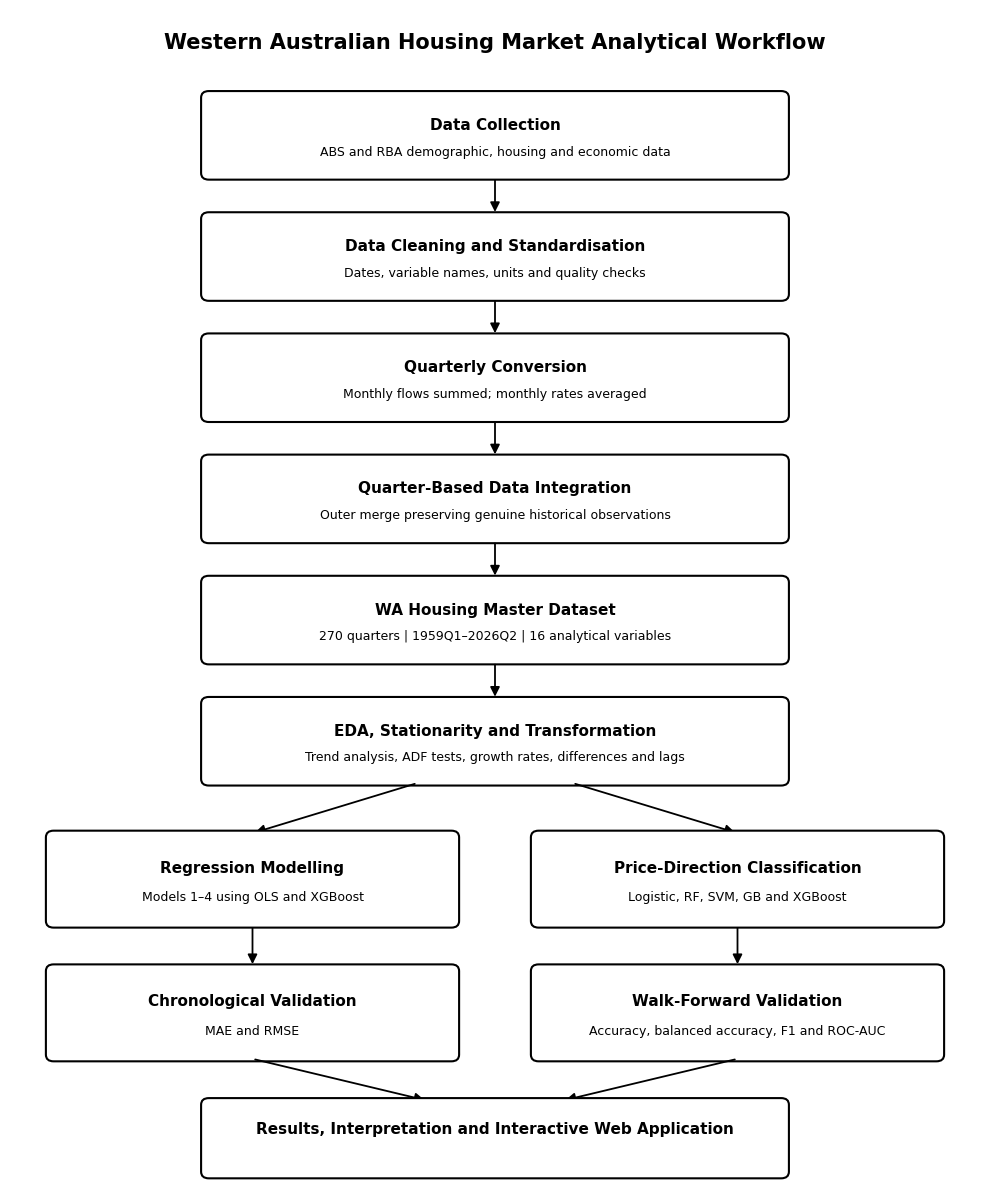

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Report_Outputs/Figure_1_WA_Housing_Analytical_Workflow.png


In [5]:
# ============================================================
# FIGURE 1 — Overall Data Preparation and Analytical Workflow
# ============================================================

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

REPORT_OUTPUTS = os.path.join(PROJECT_FOLDER, "Report_Outputs")
os.makedirs(REPORT_OUTPUTS, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis("off")

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------
def add_box(x, y, w, h, title, subtitle=""):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)

    ax.text(
        x + w/2, y + h*0.62,
        title,
        ha="center", va="center",
        fontsize=11, fontweight="bold"
    )

    if subtitle:
        ax.text(
            x + w/2, y + h*0.30,
            subtitle,
            ha="center", va="center",
            fontsize=9
        )

def arrow(x1, y1, x2, y2):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1), (x2, y2),
            arrowstyle="-|>",
            mutation_scale=14,
            linewidth=1.3,
            color="black"
        )
    )

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------
ax.text(
    5, 13.6,
    "Western Australian Housing Market Analytical Workflow",
    ha="center", va="center",
    fontsize=15, fontweight="bold"
)

# ------------------------------------------------------------
# 1. Data sources
# ------------------------------------------------------------
add_box(
    2, 12.0, 6, 1,
    "Data Collection",
    "ABS and RBA demographic, housing and economic data"
)

arrow(5, 12.0, 5, 11.55)

# ------------------------------------------------------------
# 2. Cleaning
# ------------------------------------------------------------
add_box(
    2, 10.55, 6, 1,
    "Data Cleaning and Standardisation",
    "Dates, variable names, units and quality checks"
)

arrow(5, 10.55, 5, 10.1)

# ------------------------------------------------------------
# 3. Quarterly conversion
# ------------------------------------------------------------
add_box(
    2, 9.1, 6, 1,
    "Quarterly Conversion",
    "Monthly flows summed; monthly rates averaged"
)

arrow(5, 9.1, 5, 8.65)

# ------------------------------------------------------------
# 4. Integration
# ------------------------------------------------------------
add_box(
    2, 7.65, 6, 1,
    "Quarter-Based Data Integration",
    "Outer merge preserving genuine historical observations"
)

arrow(5, 7.65, 5, 7.2)

# ------------------------------------------------------------
# 5. Master dataset
# ------------------------------------------------------------
add_box(
    2, 6.2, 6, 1,
    "WA Housing Master Dataset",
    "270 quarters | 1959Q1–2026Q2 | 16 analytical variables"
)

arrow(5, 6.2, 5, 5.75)

# ------------------------------------------------------------
# 6. EDA and transformation
# ------------------------------------------------------------
add_box(
    2, 4.75, 6, 1,
    "EDA, Stationarity and Transformation",
    "Trend analysis, ADF tests, growth rates, differences and lags"
)

# ------------------------------------------------------------
# Branch into regression and classification
# ------------------------------------------------------------
arrow(4.2, 4.75, 2.5, 4.15)
arrow(5.8, 4.75, 7.5, 4.15)

add_box(
    0.4, 3.05, 4.2, 1.1,
    "Regression Modelling",
    "Models 1–4 using OLS and XGBoost"
)

add_box(
    5.4, 3.05, 4.2, 1.1,
    "Price-Direction Classification",
    "Logistic, RF, SVM, GB and XGBoost"
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------
arrow(2.5, 3.05, 2.5, 2.55)
arrow(7.5, 3.05, 7.5, 2.55)

add_box(
    0.4, 1.45, 4.2, 1.1,
    "Chronological Validation",
    "MAE and RMSE"
)

add_box(
    5.4, 1.45, 4.2, 1.1,
    "Walk-Forward Validation",
    "Accuracy, balanced accuracy, F1 and ROC-AUC"
)

# ------------------------------------------------------------
# Final output
# ------------------------------------------------------------
arrow(2.5, 1.45, 4.3, 0.95)
arrow(7.5, 1.45, 5.7, 0.95)

add_box(
    2, 0.05, 6, 0.9,
    "Results, Interpretation and Interactive Web Application",
    ""
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
plt.tight_layout()

figure1_path = os.path.join(
    REPORT_OUTPUTS,
    "Figure_1_WA_Housing_Analytical_Workflow.png"
)

plt.savefig(
    figure1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved successfully:")
print(figure1_path)

In [6]:
# ============================================================
# TABLE 2 — Final Regression Model Specifications
# ============================================================

import os
import pandas as pd

REPORT_OUTPUTS = os.path.join(PROJECT_FOLDER, "Report_Outputs")
os.makedirs(REPORT_OUTPUTS, exist_ok=True)

table2 = pd.DataFrame({
    "Model": [
        "Model 1 – Historical Housing Prices",
        "Model 2 – Housing Supply",
        "Model 3 – Population and Development",
        "Model 4 – Recent Housing Market Pressure"
    ],

    "Dependent Variable": [
        "Perth RPPI growth",
        "WA dwelling completions growth",
        "WA dwelling approvals growth",
        "WA mean dwelling price growth"
    ],

    "Predictors": [
        "RPPI growth L1; population growth L3; "
        "completions growth L2; rent growth; "
        "change in lending rate; change in unemployment rate",

        "Completions growth L1; approvals growth L4; "
        "population growth; change in lending rate; "
        "construction-cost growth; Q2, Q3 and Q4 controls",

        "Population growth L5; change in lending rate; "
        "change in unemployment rate; construction-cost growth; "
        "Q2, Q3 and Q4 controls",

        "Price growth L1; price growth L2; "
        "change in persons per dwelling L3; "
        "change in lending rate; change in unemployment rate"
    ],

    "Key Lag Structure": [
        "L1, L2, L3",
        "L1, L4",
        "L5",
        "L1, L2, L3"
    ],

    "Modelling Period": [
        "2004Q3–2021Q4",
        "2002Q4–2025Q4",
        "1985Q1–2025Q4",
        "2012Q3–2025Q2"
    ],

    "Sample Size (n)": [
        70,
        93,
        164,
        52
    ]
})

# Save to Report_Outputs
table2_path = os.path.join(
    REPORT_OUTPUTS,
    "Table_2_Final_Regression_Model_Specifications.csv"
)

table2.to_csv(table2_path, index=False)

display(table2)

print("\nSaved successfully:")
print(table2_path)

,Model,Dependent Variable,Predictors,Key Lag Structure,Modelling Period,Sample Size (n)
0,Model 1 – Historical Housing Prices,Perth RPPI growth,RPPI growth L1; population growth L3; completi...,"L1, L2, L3",2004Q3–2021Q4,70
1,Model 2 – Housing Supply,WA dwelling completions growth,Completions growth L1; approvals growth L4; po...,"L1, L4",2002Q4–2025Q4,93
2,Model 3 – Population and Development,WA dwelling approvals growth,Population growth L5; change in lending rate; ...,L5,1985Q1–2025Q4,164
3,Model 4 – Recent Housing Market Pressure,WA mean dwelling price growth,Price growth L1; price growth L2; change in pe...,"L1, L2, L3",2012Q3–2025Q2,52



Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Report_Outputs/Table_2_Final_Regression_Model_Specifications.csv


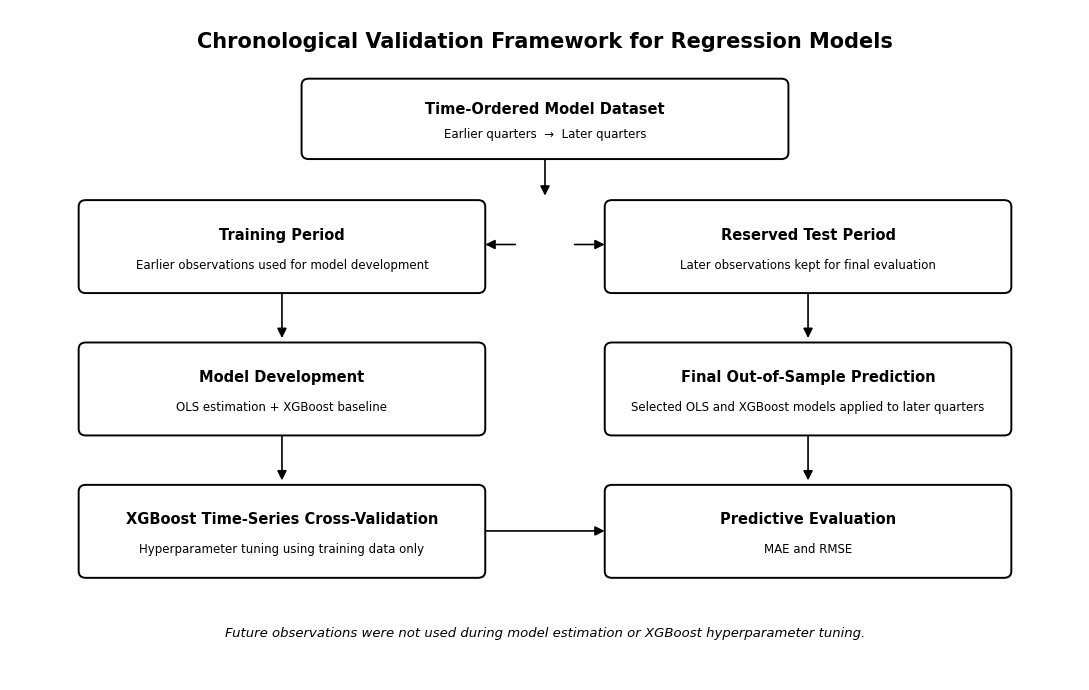

Saved successfully:
/content/drive/MyDrive/WA_Housing_Project/Report_Outputs/Figure_2_Chronological_Regression_Validation_Framework.png


In [7]:
# ============================================================
# FIGURE 2 — Chronological Regression Validation Framework
# ============================================================

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

REPORT_OUTPUTS = os.path.join(PROJECT_FOLDER, "Report_Outputs")
os.makedirs(REPORT_OUTPUTS, exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

def add_box(x, y, w, h, title, subtitle=""):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)

    ax.text(
        x + w/2, y + h*0.63,
        title,
        ha="center", va="center",
        fontsize=10.5, fontweight="bold"
    )

    if subtitle:
        ax.text(
            x + w/2, y + h*0.29,
            subtitle,
            ha="center", va="center",
            fontsize=8.5
        )

def arrow(x1, y1, x2, y2):
    ax.add_patch(
        FancyArrowPatch(
            (x1, y1), (x2, y2),
            arrowstyle="-|>",
            mutation_scale=14,
            linewidth=1.2,
            color="black"
        )
    )

# Title
ax.text(
    6, 7.55,
    "Chronological Validation Framework for Regression Models",
    ha="center",
    fontsize=15,
    fontweight="bold"
)

# Full chronological data
add_box(
    3.3, 6.25, 5.4, 0.9,
    "Time-Ordered Model Dataset",
    "Earlier quarters  →  Later quarters"
)

arrow(6, 6.25, 6, 5.75)

# Split
add_box(
    0.8, 4.65, 4.5, 1.05,
    "Training Period",
    "Earlier observations used for model development"
)

add_box(
    6.7, 4.65, 4.5, 1.05,
    "Reserved Test Period",
    "Later observations kept for final evaluation"
)

arrow(5.7, 5.2, 5.3, 5.2)
arrow(6.3, 5.2, 6.7, 5.2)

# Training branches
arrow(3.05, 4.65, 3.05, 4.05)

add_box(
    0.8, 2.95, 4.5, 1.05,
    "Model Development",
    "OLS estimation + XGBoost baseline"
)

arrow(3.05, 2.95, 3.05, 2.35)

add_box(
    0.8, 1.25, 4.5, 1.05,
    "XGBoost Time-Series Cross-Validation",
    "Hyperparameter tuning using training data only"
)

# Test path
arrow(8.95, 4.65, 8.95, 4.05)

add_box(
    6.7, 2.95, 4.5, 1.05,
    "Final Out-of-Sample Prediction",
    "Selected OLS and XGBoost models applied to later quarters"
)

arrow(8.95, 2.95, 8.95, 2.35)

add_box(
    6.7, 1.25, 4.5, 1.05,
    "Predictive Evaluation",
    "MAE and RMSE"
)

# Connection from tuning to final model
arrow(5.3, 1.78, 6.7, 1.78)

# Bottom note
ax.text(
    6, 0.55,
    "Future observations were not used during model estimation or XGBoost hyperparameter tuning.",
    ha="center",
    va="center",
    fontsize=9.5,
    style="italic"
)

plt.tight_layout()

figure2_path = os.path.join(
    REPORT_OUTPUTS,
    "Figure_2_Chronological_Regression_Validation_Framework.png"
)

plt.savefig(
    figure2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved successfully:")
print(figure2_path)

In [8]:
# ============================================================
# CHECK EXISTING EDA / REPORT FIGURES
# ============================================================

import os

folders_to_check = [
    os.path.join(PROJECT_FOLDER, "Final_Results"),
    os.path.join(PROJECT_FOLDER, "Report_Outputs"),
    os.path.join(PROJECT_FOLDER, "Report_Outputs", "01_EDA"),
    os.path.join(PROJECT_FOLDER, "Report_Outputs", "01_EDA", "Figures")
]

for folder in folders_to_check:
    print("\n" + "=" * 70)
    print(folder)
    print("=" * 70)

    if os.path.exists(folder):
        files = os.listdir(folder)

        if files:
            for file in sorted(files):
                print(file)
        else:
            print("Folder is empty.")
    else:
        print("Folder does not exist.")


/content/drive/MyDrive/WA_Housing_Project/Final_Results
All_Classification_WalkForward_Predictions.csv
Classification_Figures
Figure_Classification_CM_Always_UP_Benchmark.png
Figure_Classification_CM_Gradient_Boosting.png
Figure_Classification_CM_Logistic_Regression.png
Figure_Classification_CM_Random_Forest.png
Figure_Classification_CM_SVM_RBF.png
Figure_Classification_CM_XGBoost.png
Figure_Model_1__Historical_Price_Actual_vs_Predicted.png
Figure_Model_1__Historical_Price_XGBoost_Feature_Importance.png
Figure_Model_2__Housing_Supply_Actual_vs_Predicted.png
Figure_Model_2__Housing_Supply_XGBoost_Feature_Importance.png
Figure_Model_3__Population_and_Development_Actual_vs_Predicted.png
Figure_Model_3__Population_and_Development_XGBoost_Feature_Importance.png
Figure_Model_4__Recent_Housing_Market_Actual_vs_Predicted.png
Figure_Model_4__Recent_Housing_Market_XGBoost_Feature_Importance.png
Figure_XGBoost_Classification_Confusion_Matrix.png
Figure_XGBoost_Classification_Feature_Importance.p

In [9]:
# Check existing EDA tables

EDA_TABLE_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Report_Outputs",
    "01_EDA",
    "Tables"
)

print("Existing EDA tables:\n")

if os.path.exists(EDA_TABLE_FOLDER):
    for file in sorted(os.listdir(EDA_TABLE_FOLDER)):
        print(file)
else:
    print("EDA table folder not found.")

Existing EDA tables:

Table2_ADF_Stationarity_Summary.csv
Table3_Current_Project_Progress.csv


In [10]:
REG_TABLE_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Report_Outputs",
    "02_Regression",
    "Tables"
)

print("Existing regression tables:\n")

if os.path.exists(REG_TABLE_FOLDER):
    for file in sorted(os.listdir(REG_TABLE_FOLDER)):
        print(file)
else:
    print("Regression table folder not found.")

Existing regression tables:

Table_Regression_Model_Performance.csv
Table_XGBoost_Regression_Feature_Importance.csv


In [11]:
# ============================================================
# TABLE 4 — CONSOLIDATED OLS REGRESSION RESULTS
# ============================================================

import os
import pandas as pd

REG_TABLE_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "Report_Outputs",
    "02_Regression",
    "Tables"
)

os.makedirs(REG_TABLE_FOLDER, exist_ok=True)

table4 = pd.DataFrame({
    "Model": [
        "Model 1 – Historical Housing Prices",
        "Model 2 – Housing Supply",
        "Model 3 – Population and Development",
        "Model 4 – Recent Housing Market Pressure"
    ],

    "Main Significant Finding": [
        "RPPI growth (L1)",
        "Completions growth (L1); Q2, Q3 and Q4 seasonal effects",
        "Population growth (L5); construction-cost growth; Q2 seasonal effect",
        "Change in persons per dwelling (L3)"
    ],

    "Coefficient": [
        "+0.807",
        "-0.393; +26.58; +15.57; +17.13",
        "+11.07; -2.74; +15.80",
        "+170.43"
    ],

    "p-value": [
        "<0.001",
        "<0.001; <0.001; <0.001; <0.001",
        "0.041; 0.024; <0.001",
        "<0.001"
    ],

    "R²": [
        0.643,
        0.594,
        0.290,
        0.561
    ],

    "Adjusted R²": [
        0.609,
        0.556,
        0.258,
        0.513
    ],

    "Observations": [
        70,
        93,
        164,
        52
    ]
})

table4_path = os.path.join(
    REG_TABLE_FOLDER,
    "Table_4_Consolidated_OLS_Regression_Results.csv"
)

table4.to_csv(table4_path, index=False)

print("Saved:")
print(table4_path)

display(table4)

Saved:
/content/drive/MyDrive/WA_Housing_Project/Report_Outputs/02_Regression/Tables/Table_4_Consolidated_OLS_Regression_Results.csv


,Model,Main Significant Finding,Coefficient,p-value,R²,Adjusted R²,Observations
0,Model 1 – Historical Housing Prices,RPPI growth (L1),+0.807,<0.001,0.643,0.609,70
1,Model 2 – Housing Supply,"Completions growth (L1); Q2, Q3 and Q4 seasona...",-0.393; +26.58; +15.57; +17.13,<0.001; <0.001; <0.001; <0.001,0.594,0.556,93
2,Model 3 – Population and Development,Population growth (L5); construction-cost grow...,+11.07; -2.74; +15.80,0.041; 0.024; <0.001,0.290,0.258,164
3,Model 4 – Recent Housing Market Pressure,Change in persons per dwelling (L3),+170.43,<0.001,0.561,0.513,52
